[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/raya-lucaria/ia_o26/blob/main/course/10_deep_learning/_assets/02_entender_una_red.ipynb)

# Notebook 2 · Entender una red entrenándola

Unidad 10 de *deep learning*, clase 2. Ya construiste una red en NumPy. Ahora **entrena una red con PyTorch** para reconocer dígitos de MNIST.
En Colab, elige «Entorno de ejecución → Cambiar tipo de entorno → T4 GPU → Guardar». Luego selecciona «Entorno de ejecución → Ejecutar todo».
En una T4, calcula unos 20 minutos. Sin GPU, se activa el modo `RAPIDO` con menos datos y pasos.
Escribe tu apuesta antes de ejecutar la celda. Después, abre la respuesta y compara tu predicción con lo que viste.
En un proyecto, usa test una vez al final. Aquí lo graficamos por epoch para practicar la lectura de curvas.

## 01 · Arranque

**PyTorch automatiza la backpropagation** que programaste a mano en el notebook 01.
Torchvision carga MNIST. NumPy maneja arreglos, pandas arma tablas y Matplotlib dibuja gráficas.

In [1]:
# Todo lo que usa el notebook, importado una sola vez aquí.
import os
import time
import math
import hashlib
import subprocess
from dataclasses import dataclass, field
from typing import Callable

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision

print("torch", torch.__version__, "· torchvision", torchvision.__version__)

torch 2.14.1+cu130 · torchvision 0.29.1+cu130


Una GPU acelera las multiplicaciones de matrices al hacerlas en paralelo. `DEVICE` indica dónde se hacen.
**Si Colab avisa que falta la GPU**, elige T4 GPU en «Cambiar tipo de entorno» y vuelve a ejecutar todo.
`RAPIDO` usa CPU, recorta los datos y limita el entrenamiento. Para activarlo localmente, fija `RAPIDO=1`.
Guarda las versiones que imprime la celda si necesitas reproducir una corrida.

In [2]:
# ¿Hay GPU? En Colab: Entorno de ejecución → Cambiar tipo de entorno → T4.
HAY_GPU = torch.cuda.is_available()

# RAPIDO recorta datos y epochs para una prueba en CPU que tarda segundos.
# Se activa solo si no hay GPU, o a mano con la variable de entorno RAPIDO=1.
RAPIDO = os.environ.get("RAPIDO") == "1" or not HAY_GPU

# Con RAPIDO trabajamos en CPU aunque haya GPU (la prueba local corre en CPU).
DEVICE = torch.device("cuda" if HAY_GPU and not RAPIDO else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

if not HAY_GPU:
    print("=" * 72)
    print("  ¡AVISO! ESTE ENTORNO NO TIENE GPU.")
    print("  El notebook sigue en modo RAPIDO: pocos datos y pocas epochs,")
    print("  así que las gráficas NO se parecerán a las de la clase.")
    print("  Para corregirlo en Colab:")
    print("    Entorno de ejecución → Cambiar tipo de entorno → T4 GPU")
    print("    → Guardar, y luego Entorno de ejecución → Ejecutar todo.")
    print("=" * 72)

# nvidia-smi describe la GPU; si no existe el comando, no pasa nada.
try:
    salida = subprocess.run(["nvidia-smi"], capture_output=True, text=True,
                            timeout=20)
    print(salida.stdout if salida.returncode == 0 else "nvidia-smi no respondió")
except (FileNotFoundError, subprocess.TimeoutExpired):
    print("nvidia-smi no está disponible (no hay GPU de NVIDIA).")

print("DEVICE =", DEVICE, "· RAPIDO =", RAPIDO)
print("CUDA (con la que se compiló torch):", torch.version.cuda)
print("cuDNN:", torch.backends.cudnn.version() if HAY_GPU else "—")
if HAY_GPU:
    print("GPU:", torch.cuda.get_device_name(0))

Mon Nov 23 20:03:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             15W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

**Dos semillas controlan decisiones distintas.** `semilla_init` fija los pesos iniciales y `semilla_orden` fija el orden de los batches.
Con las mismas semillas, aún puede haber variaciones en GPU. Compara las tendencias.
En las gráficas, azul es train, naranja es validation y verde es test.

In [3]:
# Semillas: misma semilla ⇒ mismos pesos iniciales y mismo orden de batches.
SEMILLA = 0
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)  # también siembra la GPU

# Estilo de las gráficas: fondo claro y rejilla suave, como en el notebook 01.
plt.style.use("default")
plt.rcParams.update({
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 100,
    "savefig.dpi": 100,
    "figure.figsize": (7, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Un color fijo por conjunto, en todo el notebook.
COLORES = {"train": "#1f77b4", "validation": "#ff7f0e", "test": "#2ca02c"}
print("Colores:", COLORES)

Colores: {'train': '#1f77b4', 'validation': '#ff7f0e', 'test': '#2ca02c'}


## 02 · Los datos

Cada imagen de MNIST tiene $28 \times 28$ píxeles en gris y una etiqueta del 0 al 9.
La partición de Nielsen deja las últimas 10 000 imágenes del train original para validation. `ORIGEN` conserva sus índices.
**Train ajusta los parámetros y validation guía las decisiones.** Usa test una vez al final para reportar el desempeño.

In [4]:
# torchvision baja MNIST una vez; si ya está en la carpeta, no vuelve a bajarlo.
MNIST_DIR = os.environ.get("MNIST_DIR", "./datos_mnist")
mnist_train = torchvision.datasets.MNIST(MNIST_DIR, train=True, download=True)
mnist_test = torchvision.datasets.MNIST(MNIST_DIR, train=False, download=True)

# .data son las imágenes como enteros 0–255 [n, 28, 28]; .targets, los dígitos.
imagenes_60k, etiquetas_60k = mnist_train.data, mnist_train.targets
imagenes_test, etiquetas_test = mnist_test.data, mnist_test.targets

# El split: los primeros 50 000 de train son train; los últimos 10 000,
# validation. Guardamos los ÍNDICES de origen para poder verificar el split.
ORIGEN = {
    "train": torch.arange(0, 50_000),
    "validation": torch.arange(50_000, 60_000),
    "test": torch.arange(0, 10_000),  # índices dentro del archivo de test
}
CRUDOS = {
    "train": (imagenes_60k[ORIGEN["train"]], etiquetas_60k[ORIGEN["train"]]),
    "validation": (imagenes_60k[ORIGEN["validation"]],
                   etiquetas_60k[ORIGEN["validation"]]),
    "test": (imagenes_test, etiquetas_test),
}
for nombre, (imgs, etqs) in CRUDOS.items():
    print(f"{nombre:>10}: imágenes {tuple(imgs.shape)} {imgs.dtype}, "
          f"etiquetas {tuple(etqs.shape)} {etqs.dtype}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 15.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 408kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.69MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.59MB/s]

     train: imágenes (50000, 28, 28) torch.uint8, etiquetas (50000,) torch.int64
validation: imágenes (10000, 28, 28) torch.uint8, etiquetas (10000,) torch.int64
      test: imágenes (10000, 28, 28) torch.uint8, etiquetas (10000,) torch.int64


**Índices distintos pueden contener los mismos píxeles.** Los `assert` verifican tamaños e índices. Los *hashes* detectan imágenes idénticas.
Compara las tres barras de cada dígito. La línea punteada marca el 10 % de un reparto uniforme.
Adivinar al azar con igual probabilidad para cada dígito da un 10 % de accuracy en promedio.

In [5]:
# 1) Tamaños exactos.
assert len(CRUDOS["train"][0]) == 50_000
assert len(CRUDOS["validation"][0]) == 10_000
assert len(CRUDOS["test"][0]) == 10_000
# 2) Train y validation salen del mismo archivo: sus índices de origen
#    no pueden compartir ni uno.
comunes = set(ORIGEN["train"].tolist()) & set(ORIGEN["validation"].tolist())
assert len(comunes) == 0, "train y validation comparten índices"
print("✓ tamaños 50 000 / 10 000 / 10 000 y train ∩ validation = ∅ por índice")


# 3) Imágenes con píxeles idénticos (por hash). Se REPORTAN, no fallan:
#    MNIST trae unas pocas repetidas y no las vamos a limpiar aquí.
def huellas(imgs):
    """Un hash MD5 por imagen, de sus 784 bytes."""
    return [hashlib.md5(img.numpy().tobytes()).hexdigest() for img in imgs]


HUELLAS = {nombre: huellas(imgs) for nombre, (imgs, _) in CRUDOS.items()}
for nombre, hs in HUELLAS.items():
    repetidas = len(hs) - len(set(hs))
    print(f"dentro de {nombre:>10}: {repetidas} imágenes repetidas")
pares = [("train", "validation"), ("train", "test"), ("validation", "test")]
for a, b in pares:
    cruce = set(HUELLAS[a]) & set(HUELLAS[b])
    print(f"idénticas entre {a} y {b}: {len(cruce)}")

✓ tamaños 50 000 / 10 000 / 10 000 y train ∩ validation = ∅ por índice
dentro de      train: 0 imágenes repetidas
dentro de validation: 0 imágenes repetidas
dentro de       test: 0 imágenes repetidas
idénticas entre train y validation: 0
idénticas entre train y test: 0
idénticas entre validation y test: 0


          train validation     test
dígito                             
0        9.86 %     9.91 %    9.8 %
1       11.36 %    10.64 %  11.35 %
2        9.94 %      9.9 %  10.32 %
3        10.2 %     10.3 %   10.1 %
4        9.72 %     9.83 %   9.82 %
5        9.01 %     9.15 %   8.92 %
6         9.9 %     9.67 %   9.58 %
7       10.35 %     10.9 %  10.28 %
8        9.68 %    10.09 %   9.74 %
9        9.98 %     9.61 %  10.09 %


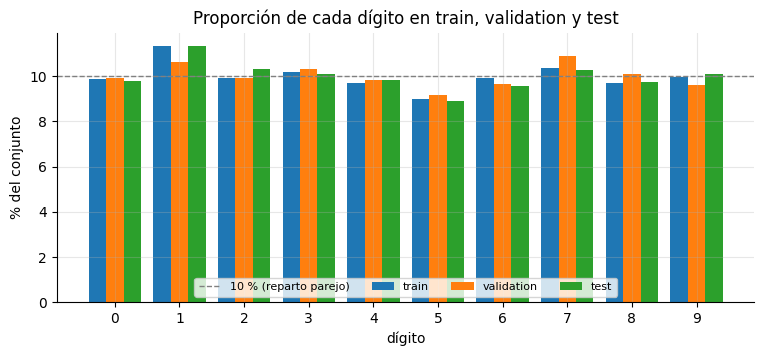

In [6]:
# 4) Proporción de cada dígito en los tres conjuntos: tabla y barras agrupadas.
POR_DIGITO = pd.DataFrame({
    nombre: pd.Series(etqs.numpy()).value_counts(normalize=True).sort_index()
    for nombre, (_, etqs) in CRUDOS.items()
})
POR_DIGITO.index.name = "dígito"
print((100 * POR_DIGITO).round(2).astype(str) + " %")

fig, ax = plt.subplots(figsize=(9, 3.5))
ancho = 0.27
for j, nombre in enumerate(POR_DIGITO.columns):
    ax.bar(POR_DIGITO.index + (j - 1) * ancho, 100 * POR_DIGITO[nombre],
           width=ancho, color=COLORES[nombre], label=nombre)
ax.axhline(10, color="gray", ls="--", lw=1, label="10 % (reparto parejo)")
ax.set_xticks(range(10))
ax.set_xlabel("dígito")
ax.set_ylabel("% del conjunto")
ax.set_title("Proporción de cada dígito en train, validation y test")
ax.legend(ncol=4, fontsize=8, loc="lower center")
plt.show()

Compara los trazos de las dos imágenes de cada dígito.
**El MLP aplana cada cuadrícula** en una fila de $784$ intensidades. La red convolucional de la sección 17 conserva la cuadrícula.

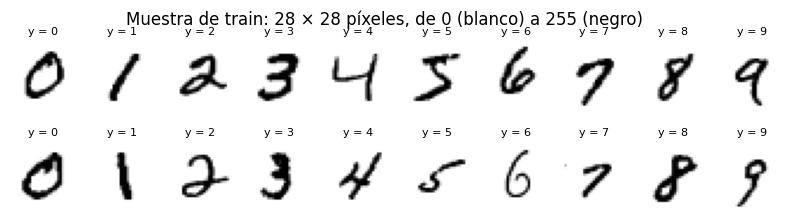

Una imagen es una matriz 28 × 28; la red la ve aplanada como 784 números: (784,)


In [7]:
# Las dos primeras imágenes de cada dígito en train, con su etiqueta.
imgs, etqs = CRUDOS["train"]
fig, ejes = plt.subplots(2, 10, figsize=(10, 2.4))
for d in range(10):
    cuales = torch.nonzero(etqs == d).flatten()[:2]
    for fila, i in enumerate(cuales.tolist()):
        ejes[fila, d].imshow(imgs[i], cmap="gray_r")
        ejes[fila, d].set_title(f"y = {d}", fontsize=8)
for ax in ejes.flat:
    ax.axis("off")
fig.suptitle("Muestra de train: 28 × 28 píxeles, de 0 (blanco) a 255 (negro)")
plt.show()
print("Una imagen es una matriz 28 × 28; la red la ve aplanada como 784 números:",
      tuple(imgs[0].flatten().shape))

- `DATOS[escala][conjunto]` guarda `(X, y)` en `DEVICE`. `X` tiene una imagen por fila e `y` una etiqueta entera por imagen.
- `"crudo"` conserva las intensidades de 0 a 255. `"01"` las divide entre 255.
- `"estandar"` aplica $(x-\mathrm{MEDIA})/\mathrm{DESV}$ a la escala `"01"`, con **media y desviación calculadas solo en train**.
- `RAPIDO` recorta los tres conjuntos por dígito. `IMAGENES_TEST` guarda cuadrículas de test en CPU para las galerías de errores.

In [8]:
def estratos(etiquetas, n, semilla=SEMILLA):
    """n índices que alternan los dígitos 0, 1, …, 9, 0, 1, … (≈ n/10 de cada
    uno), en un orden barajado con semilla fija: siempre los mismos."""
    g = torch.Generator().manual_seed(semilla)
    llave = torch.empty(len(etiquetas), dtype=torch.int64)
    for d in range(10):
        de_d = torch.nonzero(etiquetas == d).flatten()
        rango = torch.randperm(len(de_d), generator=g)
        llave[de_d[rango]] = torch.arange(len(de_d)) * 10 + d
    return torch.sort(torch.argsort(llave)[:n]).values


# Con RAPIDO nos quedamos con un pedazo estratificado: 3000 / 1000 / 1000.
if RAPIDO:
    tope = {"train": 3000, "validation": 1000, "test": 1000}
    CRUDOS = {k: (im[estratos(et, tope[k])], et[estratos(et, tope[k])])
              for k, (im, et) in CRUDOS.items()}
    print("RAPIDO: conjuntos recortados a", tope)

# Media y desviación estándar de los píxeles en [0, 1], calculadas SOLO en train.
x01_train = CRUDOS["train"][0].flatten(1).float() / 255
MEDIA, DESV = x01_train.mean().item(), x01_train.std().item()
print(f"MEDIA = {MEDIA:.4f}, DESV = {DESV:.4f} (de train)")

# DATOS[escala][conjunto] = (X [n, 784] float32, y [n] int64), ya en DEVICE.
DATOS = {"crudo": {}, "01": {}, "estandar": {}}
for nombre, (imgs, etqs) in CRUDOS.items():
    crudo = imgs.flatten(1).float()          # aplanar: [n, 28, 28] → [n, 784]
    y = etqs.long().to(DEVICE)
    DATOS["crudo"][nombre] = (crudo.to(DEVICE), y)
    DATOS["01"][nombre] = ((crudo / 255).to(DEVICE), y)
    DATOS["estandar"][nombre] = (((crudo / 255 - MEDIA) / DESV).to(DEVICE), y)

# Las imágenes de test en [0, 1], en CPU, alineadas con DATOS[...]["test"].
IMAGENES_TEST = CRUDOS["test"][0].float() / 255
for nombre in ("train", "validation", "test"):
    X, y = DATOS["estandar"][nombre]
    print(f"{nombre:>10}: X {tuple(X.shape)} en {X.device}, y {tuple(y.shape)}")
if DEVICE.type == "cuda":
    print(f"memoria de GPU ocupada: {torch.cuda.memory_allocated() / 2**20:.0f} MB")

MEDIA = 0.1310, DESV = 0.3085 (de train)
     train: X (50000, 784) en cuda:0, y (50000,)
validation: X (10000, 784) en cuda:0, y (10000,)
      test: X (10000, 784) en cuda:0, y (10000,)
memoria de GPU ocupada: 631 MB


`subconjunto(n)` toma **cerca de $n/10$ ejemplos de train por dígito**. Con los mismos datos, tamaño y semilla, devuelve los mismos índices.
Validation y test se evalúan con todos los ejemplos disponibles en el modo elegido.

In [9]:
def subconjunto(n, semilla=0):
    """Índices fijos de un subconjunto estratificado de DATOS[...]["train"]:
    ≈ n/10 por dígito, siempre los mismos para la misma semilla."""
    return estratos(DATOS["01"]["train"][1].cpu(), n, semilla)


idx = subconjunto(1000)
cuenta = torch.bincount(DATOS["01"]["train"][1].cpu()[idx], minlength=10)
print("subconjunto(1000), ejemplos por dígito:", cuenta.tolist())
assert torch.equal(idx, subconjunto(1000)), "el subconjunto no es determinista"

subconjunto(1000), ejemplos por dígito: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]


Qué viste

- **La mezcla de dígitos es parecida en los tres conjuntos.** El 1 supera la referencia uniforme. El 5 queda por debajo.
- Las huellas no detectaron imágenes idénticas dentro de los conjuntos ni entre ellos.

## 03 · La caja de herramientas

- `construir_red` recibe los anchos de las capas. Con `[784, 10]` obtienes una regresión logística multiclase.
- Cada capa oculta aplica `nn.Linear` y luego una activación, como ReLU, $\max(0,z)$. Si las activas, batch normalization va antes de la activación y dropout después.
- **La última capa entrega logits**, uno por dígito.
- La inicialización He usa varianza $2/d_{l-1}$, con $d_{l-1}$ el ancho anterior. He y la inicialización ortogonal ponen los sesgos en cero.

In [10]:
# El nombre de cada activación → la capa de PyTorch que la aplica.
ACTIVACIONES = {"relu": nn.ReLU, "sigmoide": nn.Sigmoid, "tanh": nn.Tanh,
                "gelu": nn.GELU, "identidad": nn.Identity}


def construir_red(capas, activacion="relu", batch_norm=False, dropout=0.0,
                  init="defecto"):
    """capas = [784, d_1, …, 10] → nn.Sequential.
    Cada capa oculta: Linear → (BatchNorm) → activación g → (Dropout).
    La última Linear entrega los 10 logits, SIN activación: la softmax va
    dentro de la loss (nn.CrossEntropyLoss). [784, 10] es la regresión
    logística multiclase de la unidad 9."""
    piezas = []
    for l in range(1, len(capas)):
        piezas.append(nn.Linear(capas[l - 1], capas[l]))  # W^(l): [d_l, d_{l-1}]
        if l < len(capas) - 1:                             # solo capas ocultas
            if batch_norm:
                piezas.append(nn.BatchNorm1d(capas[l]))
            piezas.append(ACTIVACIONES[activacion]())
            if dropout > 0:
                piezas.append(nn.Dropout(dropout))
    red = nn.Sequential(*piezas)
    for capa in red:
        if isinstance(capa, nn.Linear) and init != "defecto":
            if init == "he":          # normal con varianza 2 / d_{l-1}, como el 01
                nn.init.kaiming_normal_(capa.weight, nonlinearity="relu")
            elif init == "ortogonal":  # filas ortonormales: W W^T = I
                nn.init.orthogonal_(capa.weight)
            else:
                raise ValueError(f"init desconocida: {init}")
            nn.init.zeros_(capa.bias)
    return red


print(construir_red([784, 128, 10]))

Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=10, bias=True)
)


- **Cada dígito ocupa una fila.** El notebook 01 usaba columnas, con $\mathbf z=\mathbf W\mathbf x+\mathbf b$. Aquí usamos `xb @ W.T + b`.
- `CrossEntropyLoss` recibe logits y etiquetas enteras. Su loss es el promedio de $-\log \widehat p_{k,y_k}$ tras aplicar softmax.
- `argmax(dim=1)` predice el dígito con mayor logit en cada fila. Con probabilidades uniformes, la loss sería $\log 10 \approx 2.30$.

In [11]:
torch.manual_seed(SEMILLA)
red = construir_red([784, 128, 10]).to(DEVICE)   # .to(DEVICE): pesos a la GPU
X, y = DATOS["estandar"]["train"]
xb, yb = X[:4], y[:4]                 # un batch de B = 4 dígitos, uno por FILA
print("entrada xb:", tuple(xb.shape), "← [B, 784]")

# La primera capa por dentro: z = x W^T + b. W tiene filas = destino (128)
# y columnas = origen (784), como en la notación; por eso se multiplica por W.T.
W, b = red[0].weight, red[0].bias
print("W^(1):", tuple(W.shape), "← [destino 128, origen 784]")
z = xb @ W.T + b
assert torch.allclose(z, red[0](xb), atol=1e-5)
print("z^(1) = xb @ W.T + b:", tuple(z.shape), "← [B, 128]")

logits = red(xb)                      # forward completo
print("logits:", tuple(logits.shape), "← [B, 10], un número por dígito")
print("etiquetas yb:", yb.tolist(), yb.dtype, "← enteros, no one-hot")

perdida_fn = nn.CrossEntropyLoss()    # softmax + −log de la clase correcta
perdida = perdida_fn(logits, yb)
print(f"loss = {perdida.item():.3f}  (adivinar parejo daría log 10 ≈ 2.303)")
prediccion = logits.argmax(dim=1)     # la clase con el logit más grande
print("predicción (argmax):", prediccion.tolist(), "· real:", yb.tolist())

entrada xb: (4, 784) ← [B, 784]
W^(1): (128, 784) ← [destino 128, origen 784]
z^(1) = xb @ W.T + b: (4, 128) ← [B, 128]
logits: (4, 10) ← [B, 10], un número por dígito
etiquetas yb: [5, 0, 4, 1] torch.int64 ← enteros, no one-hot
loss = 2.347  (adivinar parejo daría log 10 ≈ 2.303)
predicción (argmax): [7, 5, 7, 1] · real: [5, 0, 4, 1]


- **Un batch produce una actualización.** `zero_grad()` borra lo acumulado antes del forward y el cálculo de la loss.
- `backward()` calcula los gradientes. Con SGD, `step()` aplica $p \leftarrow p - \eta\,\nabla_p L_{\mathcal B}$, como en el notebook 01.
- La demo muestrea con reemplazo. `entrenar` baraja train y recorre sus $n$ ejemplos en $\lceil n/B\rceil$ batches. Con batch normalization, un batch final de un ejemplo se fusiona con el anterior.

In [12]:
torch.manual_seed(SEMILLA)
red = construir_red([784, 128, 10]).to(DEVICE)
optimizer = torch.optim.SGD(red.parameters(), lr=0.03)   # η = 0.03
X, y = DATOS["estandar"]["train"]
B = 128
for paso in range(1, 6):
    idx = torch.randint(0, len(X), (B,), device=DEVICE)  # un mini-batch 𝓑
    optimizer.zero_grad()           # 1. borra los gradientes del paso anterior
    logits = red(X[idx])            # 2. forward: [B, 784] → [B, 10]
    perdida = perdida_fn(logits, y[idx])   # 3. loss promedio sobre el batch
    perdida.backward()              # 4. backpropagation: llena p.grad
    optimizer.step()                # 5. p ← p − η · p.grad, para cada parámetro
    print(f"paso {paso}: loss del batch = {perdida.item():.3f}")

# El paso 5 a mano: es exactamente el W ← W − η ∇W del notebook 01.
antes = [p.detach().clone() for p in red.parameters()]
optimizer.zero_grad()
perdida_fn(red(X[idx]), y[idx]).backward()
with torch.no_grad():
    a_mano = [p - 0.03 * p.grad for p in red.parameters()]
optimizer.step()
iguales = all(torch.allclose(p, q, atol=1e-6)
              for p, q in zip(red.parameters(), a_mano))
print("optimizer.step() == p − η·grad a mano:", iguales)
del red, optimizer, antes, a_mano

paso 1: loss del batch = 2.315
paso 2: loss del batch = 2.265
paso 3: loss del batch = 2.233
paso 4: loss del batch = 2.157
paso 5: loss del batch = 2.064
optimizer.step() == p − η·grad a mano: True


- **`Config` define la corrida.** `id` y `seccion` son obligatorios. Puedes fijar la red, los datos, las semillas y el presupuesto.
- `config_profunda` prepara las redes de las secciones 13 a 15 con SGD e inicialización ortogonal.
- `Corrida` guarda el historial y dos checkpoints. Uno corresponde a la menor loss de validation y otro a la última evaluación.
- Al repetir un `id`, `CORRIDAS` reemplaza el resultado anterior.

In [13]:
@dataclass
class Config:
    """Todo lo que define una corrida. Solo id y seccion son obligatorios."""
    id: str
    seccion: int
    capas: list = field(default_factory=lambda: [784, 128, 10])
    activacion: str = "relu"
    batch_norm: bool = False
    dropout: float = 0.0
    init: str = "defecto"
    modelo: Callable | None = None      # si no es None, sustituye construir_red
    optimizer: str = "adam"             # sgd, momentum, adam, adam_l2, adamw
    lr: float = 1e-3                    # η
    weight_decay: float = 0.0           # solo pesos, nunca sesgos
    batch: int = 128                    # batch ≥ n de train ⇒ full-batch
    epochs: int = 5
    max_pasos: int | None = None        # tope de actualizaciones
    eval_cada_pasos: int | None = None  # evaluar cada tantos pasos, no por epoch
    escala: str = "estandar"            # "crudo", "01" o "estandar"
    idx_train: torch.Tensor | None = None   # subconjunto de train
    ruido_etiquetas: float = 0.0        # fracción de train con etiqueta cambiada
    paciencia: int | None = None        # early stopping sobre loss de validation
    semilla_init: int = 0               # pesos iniciales
    semilla_orden: int = 0              # orden de los batches
    medir_por_paso: bool = False        # norma del gradiente y ‖ΔW‖/‖W‖ por capa
    datos: str = "50k-limpio"           # etiqueta para agrupar la tabla maestra


@dataclass
class Corrida:
    """El resultado de entrenar(): historial y checkpoints."""
    id: str
    config: Config
    historial: pd.DataFrame        # una fila por evaluación
    por_paso: pd.DataFrame | None  # una fila por (paso, capa), si se midió
    mejor: dict                    # state_dict de la mejor evaluación, en CPU
    ultima: dict                   # state_dict de la última, en CPU
    mejor_epoch: float             # epoch de menor loss de validation
    divergio: bool                 # la loss se volvió inf o nan
    paso_no_finito: int | None     # el primer paso con loss no finita
    parametros: int                # número de pesos y sesgos


CORRIDAS = {}   # id → Corrida; reejecutar una celda reemplaza su corrida


def config_profunda(activacion="relu", **cambios):
    """La red profunda de §13–15: 6 ocultas de 128, SGD η = 0.03, pesos
    iniciales ortogonales, sesgos en cero. `cambios` sobrescribe campos."""
    base = dict(id=f"profunda-{activacion}", seccion=13,
                capas=[784] + [128] * 6 + [10], activacion=activacion,
                init="ortogonal", optimizer="sgd", lr=0.03)
    base.update(cambios)
    return Config(**base)

- **`medir` calcula loss y accuracy sin gradientes**, en modo `eval()`. Dropout se apaga y batch normalization usa sus estadísticas acumuladas.
- `crear_optimizer` aplica weight decay a matrices y filtros. `adam_l2` suma la penalización al gradiente y `adamw` aplica el decaimiento por separado.
- `cargar(corrida, "mejor")` recupera el checkpoint elegido con validation. Usa `"ultima"` para recuperar el último.

In [14]:
def medir(modelo, X, y, bloque=4096):
    """Loss y accuracy promedio de `modelo` sobre (X, y) completos, por
    bloques, en modo eval() (BN usa sus promedios; dropout se apaga)."""
    estaba_entrenando = modelo.training
    modelo.eval()
    suma = torch.zeros((), device=X.device)       # se acumula en la GPU
    aciertos = torch.zeros((), device=X.device)
    with torch.no_grad():                 # evaluar no necesita gradientes
        for i in range(0, len(X), bloque):
            logits = modelo(X[i:i + bloque])
            suma += nn.functional.cross_entropy(
                logits, y[i:i + bloque], reduction="sum")
            aciertos += (logits.argmax(1) == y[i:i + bloque]).sum()
    modelo.train(estaba_entrenando)
    loss = suma.item() / len(X)
    # Con logits inf o nan la accuracy no significa nada: también es nan.
    return loss, aciertos.item() / len(X) if math.isfinite(loss) else math.nan


def evaluar(modelo, escala, conjunto):
    """(loss, accuracy) de `modelo` en DATOS[escala][conjunto], completo."""
    X, y = DATOS[escala][conjunto]
    return medir(modelo, X, y)


def crear_optimizer(cfg, modelo):
    """El optimizer de cfg. weight_decay va SOLO a los pesos (ndim > 1):
    los sesgos y los parámetros de BN quedan en un grupo sin decay."""
    pesos = [p for p in modelo.parameters() if p.ndim > 1]
    otros = [p for p in modelo.parameters() if p.ndim <= 1]
    grupos = [{"params": pesos, "weight_decay": cfg.weight_decay},
              {"params": otros, "weight_decay": 0.0}]
    if cfg.optimizer == "sgd":
        return torch.optim.SGD(grupos, lr=cfg.lr)
    if cfg.optimizer == "momentum":
        return torch.optim.SGD(grupos, lr=cfg.lr, momentum=0.9)
    if cfg.optimizer in ("adam", "adam_l2"):   # L2 acoplado: entra al gradiente
        return torch.optim.Adam(grupos, lr=cfg.lr)
    if cfg.optimizer == "adamw":               # decay desacoplado del gradiente
        return torch.optim.AdamW(grupos, lr=cfg.lr)
    raise ValueError(f"optimizer desconocido: {cfg.optimizer}")


def red_de(cfg):
    """La red que pide cfg: cfg.modelo() si existe; si no, construir_red."""
    if cfg.modelo is not None:
        return cfg.modelo()
    return construir_red(cfg.capas, cfg.activacion, cfg.batch_norm,
                         cfg.dropout, cfg.init)


def cargar(corrida, cual="mejor"):
    """Reconstruye la red de `corrida` con su checkpoint ("mejor" o "ultima")."""
    modelo = red_de(corrida.config)
    modelo.load_state_dict(corrida.mejor if cual == "mejor" else corrida.ultima)
    return modelo.to(DEVICE).eval()

- `entrenar` prepara train con la escala, el subconjunto y el ruido de etiquetas solicitados. Mide antes de actualizar los pesos y luego por epoch o por pasos.
- **La loss de validation elige el mejor checkpoint** y activa early stopping si se agota la paciencia. Una loss no finita también detiene la corrida.
- El reloj mide solo el entrenamiento. Con `medir_por_paso` se guardan dos medidas por capa. Son la norma del gradiente y el cambio relativo $\lVert \mathbf W_{t+1}-\mathbf W_t\rVert/\lVert \mathbf W_t\rVert$.

In [15]:
def datos_de_entrenamiento(cfg):
    """(X, y) de train para cfg: subconjunto y etiquetas alteradas."""
    X, y = DATOS[cfg.escala]["train"]
    if cfg.idx_train is not None:
        idx = cfg.idx_train.to(DEVICE)
        idx = idx[idx < len(X)]          # con RAPIDO, train es más chico
        X, y = X[idx], y[idx]
    if cfg.ruido_etiquetas > 0:
        g = torch.Generator().manual_seed(SEMILLA)       # siempre las mismas
        cuantas = round(cfg.ruido_etiquetas * len(y))
        cuales = torch.randperm(len(y), generator=g)[:cuantas].to(DEVICE)
        salto = torch.randint(1, 10, (cuantas,), generator=g).to(DEVICE)
        y = y.clone()
        y[cuales] = (y[cuales] + salto) % 10   # salto 1–9: SIEMPRE otra clase
    return X, y


def cortes(n, B, tiene_bn):
    """Los límites (i, j) de cada batch de una epoch. Con batch normalization
    un batch de un solo ejemplo no se puede normalizar: se une al anterior."""
    if tiene_bn and B < 2:
        raise ValueError("batch normalization necesita batch ≥ 2")
    inicios = list(range(0, n, B))
    if tiene_bn and len(inicios) > 1 and n - inicios[-1] < 2:
        inicios.pop()
    return list(zip(inicios, inicios[1:] + [n]))


def capas_con_pesos(modelo):
    """Las capas Linear y Conv, en orden: las que miden medir_por_paso."""
    return [m for m in modelo.modules()
            if isinstance(m, (nn.Linear, nn.Conv1d, nn.Conv2d))]


def medida_por_paso(capas, antes):
    """Por capa: norma del gradiente y cociente ‖W_nuevo − W‖ / ‖W‖."""
    normas = [c.weight.grad.norm() for c in capas]
    cocientes = [(c.weight.detach() - a).norm() / a.norm()
                 for c, a in zip(capas, antes)]
    return torch.stack(normas + cocientes)


def norma_pesos(modelo):
    """‖θ‖ de los pesos (matrices y filtros), sin sesgos ni parámetros de BN."""
    return math.sqrt(sum((p.detach() ** 2).sum()
                         for p in modelo.parameters() if p.ndim > 1).item())


def checkpoint(modelo):
    """Copia del state_dict en CPU (pesos y estadísticas de BN)."""
    return {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}


def sincronizar():
    """Espera a la GPU y devuelve la hora: sin esperar, el reloj mediría
    cuándo se ENCARGÓ el trabajo, no cuándo terminó."""
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return time.perf_counter()

In [16]:
def _registrar(e, cfg, modelo, X, y, filas, epoch):
    """Una evaluación: loss y accuracy en train (el que se usa para entrenar),
    validation y test completos; actualiza el mejor checkpoint y la paciencia."""
    fila = dict(epoch=epoch, pasos=e["paso"], ejemplos=e["ejemplos"],
                segundos=e["segundos"])
    for conjunto in ("train", "validation", "test"):
        Xc, yc = (X, y) if conjunto == "train" else DATOS[cfg.escala][conjunto]
        fila[f"loss_{conjunto}"], fila[f"acc_{conjunto}"] = medir(modelo, Xc, yc)
    fila["norma_pesos"] = norma_pesos(modelo)
    filas.append(fila)
    if not math.isfinite(fila["loss_train"]) and not e["divergio"]:
        e.update(divergio=True, no_finito=e["paso"], parar=True)
    lv = fila["loss_validation"]
    if math.isfinite(lv) and lv < e["mejor_loss"]:   # mejor = menor loss val
        e.update(mejor_loss=lv, mejor=checkpoint(modelo), mejor_epoch=epoch,
                 sin_mejora=0)
    else:
        e["sin_mejora"] += 1
    if cfg.paciencia is not None and e["sin_mejora"] >= cfg.paciencia:
        e["parar"] = True                            # early stopping

def revisar_finitos(pendientes, e):
    """Revisa de golpe las losses pendientes (una sola espera a la GPU). Si
    alguna es inf o nan, la corrida divergió: anota el primer paso y para."""
    if pendientes:
        malos = ~torch.isfinite(torch.stack(pendientes))
        if malos.any():
            primero = e["paso"] - len(pendientes) + 1 + int(malos.nonzero()[0, 0])
            e.update(divergio=True, no_finito=primero, parar=True)
        pendientes.clear()

In [17]:
def entrenar(cfg):
    """Entrena según cfg, evalúa train/validation/test completos en la epoch 0
    y tras cada epoch (o cada cfg.eval_cada_pasos), y registra en CORRIDAS."""
    epochs, max_pasos = cfg.epochs, cfg.max_pasos
    if RAPIDO:
        epochs, max_pasos = min(epochs, 2), min(max_pasos or 30, 30)
    X, y = datos_de_entrenamiento(cfg)
    n, B = len(X), min(cfg.batch, len(X))
    torch.manual_seed(cfg.semilla_init)              # mismos pesos iniciales
    modelo = red_de(cfg).to(DEVICE)
    optimizer = crear_optimizer(cfg, modelo)
    perdida_fn = nn.CrossEntropyLoss()
    orden = torch.Generator(device=DEVICE).manual_seed(cfg.semilla_orden)
    tiene_bn = any(isinstance(m, nn.BatchNorm1d) for m in modelo.modules())
    limites = cortes(n, B, tiene_bn)
    por_epoch = len(limites)                         # pasos por epoch
    capas = capas_con_pesos(modelo)
    e = dict(paso=0, ejemplos=0, segundos=0.0, sin_mejora=0, mejor_loss=math.inf,
             mejor=None, mejor_epoch=0, divergio=False, no_finito=None, parar=False)
    filas, medidas, pendientes = [], [], []
    registrar = lambda epoch: _registrar(e, cfg, modelo, X, y, filas, epoch)
    registrar(0)
    for ep in range(1, epochs + 1):
        modelo.train()
        t0 = sincronizar()
        perm = torch.randperm(n, device=DEVICE, generator=orden)
        for i, j in limites:
            idx = perm[i:j]
            optimizer.zero_grad()
            perdida = perdida_fn(modelo(X[idx]), y[idx])
            perdida.backward()
            antes = cfg.medir_por_paso and [c.weight.detach().clone()
                                            for c in capas]
            optimizer.step()
            e.update(paso=e["paso"] + 1, ejemplos=e["ejemplos"] + len(idx))
            if cfg.medir_por_paso:               # ‖∇W‖ y ‖ΔW‖/‖W‖ por capa
                medidas.append(medida_por_paso(capas, antes))
            pendientes.append(perdida.detach())  # sin esperar a la GPU
            evalua = cfg.eval_cada_pasos and e["paso"] % cfg.eval_cada_pasos == 0
            if e["paso"] % 25 == 0 or evalua or e["paso"] == max_pasos:
                revisar_finitos(pendientes, e)   # ¿inf o nan? ⇒ divergió
                if e["parar"]:
                    break
            if evalua:
                e["segundos"] += sincronizar() - t0
                registrar(e["paso"] / por_epoch)
                t0 = time.perf_counter()
                if e["parar"]:
                    break
            if max_pasos and e["paso"] >= max_pasos:
                e["parar"] = True
                break
        revisar_finitos(pendientes, e)
        e["segundos"] += sincronizar() - t0
        fin = e["parar"] or ep == epochs
        if (fin or not cfg.eval_cada_pasos) and filas[-1]["pasos"] != e["paso"]:
            registrar(e["paso"] / por_epoch if e["parar"] else ep)
        if e["parar"]:
            break
    return _cerrar(cfg, modelo, optimizer, filas, medidas, capas, e)

In [18]:
def _cerrar(cfg, modelo, optimizer, filas, medidas, capas, e):
    """Arma la Corrida, la registra en CORRIDAS y libera la GPU."""
    historial = pd.DataFrame(filas)
    historial["parada_temprana"] = False
    if cfg.paciencia is not None and e["sin_mejora"] >= cfg.paciencia:
        historial.loc[historial.index[-1], "parada_temprana"] = True
    por_paso = None
    if cfg.medir_por_paso and medidas:
        m = torch.stack(medidas).cpu().numpy()       # [pasos, 2 · capas]
        L = len(capas)
        por_paso = pd.DataFrame([
            dict(paso=p + 1, capa=l + 1, norma_grad=m[p, l],
                 cociente_actualizacion=m[p, L + l])
            for p in range(len(m)) for l in range(L)])
    ultima = checkpoint(modelo)
    corrida = Corrida(
        id=cfg.id, config=cfg, historial=historial, por_paso=por_paso,
        mejor=e["mejor"] if e["mejor"] is not None else ultima, ultima=ultima,
        mejor_epoch=e["mejor_epoch"], divergio=e["divergio"],
        paso_no_finito=e["no_finito"],
        parametros=sum(p.numel() for p in modelo.parameters()))
    CORRIDAS[cfg.id] = corrida                       # mismo id ⇒ reemplaza
    del modelo, optimizer
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    f = historial.loc[historial["epoch"] == corrida.mejor_epoch].iloc[0]
    aviso = (f" · DIVERGIÓ en el paso {corrida.paso_no_finito}"
             if corrida.divergio else "")
    print(f"{cfg.id}: {corrida.parametros:,} parámetros · {e['paso']} pasos · "
          f"mejor epoch {corrida.mejor_epoch:g} · acc validation "
          f"{f['acc_validation']:.3f} · {e['segundos']:.1f} s{aviso}")
    return corrida

- `curvas` muestra loss o accuracy por epoch, pasos, ejemplos vistos o tiempo. `rejilla` dibuja un panel por corrida.
- **`tabla_maestra` compara las corridas en su mejor evaluación según validation.** La brecha es la accuracy de train menos la de validation.
- `dibujar_red` usa una columna por capa. Los puntos suspensivos indican nodos omitidos.

In [19]:
ESTILOS = ["-", "--", ":", "-."]
EJE_X = {"epoch": "epoch", "pasos": "actualizaciones (pasos)",
         "actualizaciones": "actualizaciones (pasos)",
         "ejemplos": "ejemplos vistos", "segundos": "segundos de entrenamiento"}


def curvas(corridas, x="epoch", metrica="loss",
           conjuntos=("train", "validation", "test"), ax=None, titulo=None,
           log=False):
    """Curvas de `metrica` ("loss" o "acc") contra `x` para varias corridas.
    Color = conjunto y estilo de línea = corrida; con un solo conjunto y
    varias corridas, cada corrida lleva su color. Omite valores no finitos."""
    metrica = "acc" if metrica in ("acc", "accuracy") else "loss"
    columna_x = "pasos" if x == "actualizaciones" else x
    ax = ax or plt.subplots()[1]
    paleta = plt.cm.viridis(np.linspace(0, 0.9, max(len(corridas), 1)))
    algo = False
    for k, c in enumerate(corridas):
        h = c.historial
        for conjunto in conjuntos:
            v = h[f"{metrica}_{conjunto}"].to_numpy(dtype=float)
            ok = np.isfinite(v) & (v > 0 if log else True)
            if not ok.any():
                continue
            un_color = len(conjuntos) == 1 and len(corridas) > 1
            color = paleta[k] if un_color else COLORES[conjunto]
            estilo = "-" if un_color else ESTILOS[k % len(ESTILOS)]
            marca = " (divergió)" if c.divergio else ""
            ax.plot(h[columna_x].to_numpy()[ok], v[ok], estilo, color=color,
                    marker="o", ms=3, label=f"{c.id} · {conjunto}{marca}")
            algo = True
    if not algo:
        ax.text(0.5, 0.5, "divergió", transform=ax.transAxes, ha="center",
                va="center", fontsize=14, color="crimson")
    if log and algo:
        ax.set_yscale("log")
    ax.set_xlabel(EJE_X.get(x, x))
    ax.set_ylabel("loss (cross-entropy)" if metrica == "loss" else "accuracy")
    ax.set_title(titulo or f"{'Loss' if metrica == 'loss' else 'Accuracy'} "
                 f"contra {EJE_X.get(x, x)}")
    if algo:
        ax.legend(fontsize=8)
    return ax


def rejilla(corridas, x="epoch", metrica="loss", columnas=3, misma_y=True):
    """Small multiples: un panel por corrida, mismos ejes si misma_y."""
    filas = math.ceil(len(corridas) / columnas)
    fig, ejes = plt.subplots(filas, columnas, figsize=(4 * columnas, 3 * filas),
                             sharex=True, sharey=misma_y, squeeze=False)
    for ax, c in zip(ejes.flat, corridas):
        curvas([c], x=x, metrica=metrica, ax=ax, titulo=c.id)
        ax.get_legend() and ax.get_legend().remove()
    for ax in list(ejes.flat)[len(corridas):]:
        ax.set_visible(False)
    muestras = [plt.Line2D([], [], color=COLORES[k], marker="o", ms=3, label=k)
                for k in ("train", "validation", "test")]
    fig.legend(handles=muestras, loc="upper right", fontsize=8)
    fig.tight_layout()
    return fig

In [20]:
def tabla_maestra(secciones=None):
    """Una fila por corrida registrada, con sus números en la MEJOR epoch
    (elegida por loss de validation, nunca por test)."""
    filas, vistas = [], set()
    for c in CORRIDAS.values():
        if id(c) in vistas:          # la misma corrida guardada con dos nombres
            continue
        vistas.add(id(c))
        if secciones is not None and c.config.seccion not in secciones:
            continue
        h = c.historial
        f = h.loc[h["epoch"] == c.mejor_epoch].iloc[0]
        filas.append(dict(
            id=c.id, seccion=c.config.seccion, datos=c.config.datos,
            parametros=c.parametros, mejor_epoch=c.mejor_epoch,
            pasos=int(f["pasos"]), ejemplos=int(f["ejemplos"]),
            acc_train=f["acc_train"], acc_validation=f["acc_validation"],
            acc_test=f["acc_test"], loss_train=f["loss_train"],
            loss_validation=f["loss_validation"], loss_test=f["loss_test"],
            brecha=f["acc_train"] - f["acc_validation"],
            segundos=h["segundos"].iloc[-1], divergio=c.divergio))
    tabla = pd.DataFrame(filas)
    return tabla.sort_values("seccion", kind="stable").reset_index(drop=True) \
        if len(tabla) else tabla

def experimentos_unicos():
    """Cuántas corridas distintas hay en CORRIDAS (sin contar alias)."""
    return len({id(c) for c in CORRIDAS.values()})

In [21]:
def dibujar_red(capas, ax=None, titulo=None, max_nodos=10):
    """Columnas de nodos, una por capa. La ALTURA de cada columna y cuántos
    nodos se dibujan crecen con log2 del ancho: un embudo se ve embudo.
    Si una capa tiene más nodos de los dibujados, «⋮» en medio; el número
    real va siempre debajo."""
    ax = ax or plt.subplots(figsize=(1.6 * len(capas) + 1, 3.6))[1]
    tope = math.log2(max(max(capas), 2))
    posiciones = []
    for d in capas:
        h = max(0.12, (math.log2(max(d, 2)) / tope) ** 1.5)  # media altura
        k = int(np.clip(round(1.5 * math.log2(max(d, 1))), 2, max_nodos))
        k = max(2, min(k, int(2 * h / 0.09)))       # que quepan sin encimarse
        if d <= k:                                          # caben todos
            ys = np.linspace(h, -h, d) if d > 1 else np.array([0.0])
            hueco = None
        else:                                               # se recorta
            arriba, abajo, g = (k + 1) // 2, k // 2, max(0.35 * h, 0.1)
            h = max(h, g + 0.09 * (arriba - 1))     # espacio para «⋮»
            ys = np.concatenate([np.linspace(h, g, arriba),
                                 np.linspace(-g, -h, abajo)])
            hueco = 0.0
        posiciones.append((ys, hueco))
    for j, ((ys, _), (zs, _)) in enumerate(zip(posiciones, posiciones[1:])):
        for a in ys:
            for b in zs:
                ax.plot([j, j + 1], [a, b], color="gray", lw=0.4, alpha=0.25)
    for j, (ys, hueco) in enumerate(posiciones):
        es_borde = j in (0, len(capas) - 1)
        ax.scatter(np.full(len(ys), j), ys, s=40, zorder=3, edgecolor="black",
                   color="#cfe2f3" if es_borde else "white")
        if hueco is not None:
            ax.text(j, hueco, "⋮", ha="center", va="center", fontsize=11,
                    zorder=4)
        ax.text(j, -1.2, f"{capas[j]:,}", ha="center", va="top", fontsize=9)
    ax.text(0, 1.2, "entrada\n(píxeles)", ha="center", va="bottom", fontsize=9)
    ax.text(len(capas) - 1, 1.2, "salida\n(logits)", ha="center", va="bottom",
            fontsize=9)
    ax.set_xlim(-0.6, len(capas) - 0.4)
    ax.set_ylim(-1.6, 1.7)
    ax.axis("off")
    ax.set_title(titulo or " → ".join(str(d) for d in capas), fontsize=10)
    return ax

**Ubica el punto de partida en la epoch 0.** En el otro panel, sigue la red desde los píxeles hasta los logits.
Usa test una vez al final. Aquí se grafica por epoch solo para practicar la lectura de curvas.

s03-demo: 101,770 parámetros · 32 pasos · mejor epoch 2 · acc validation 0.877 · 0.3 s


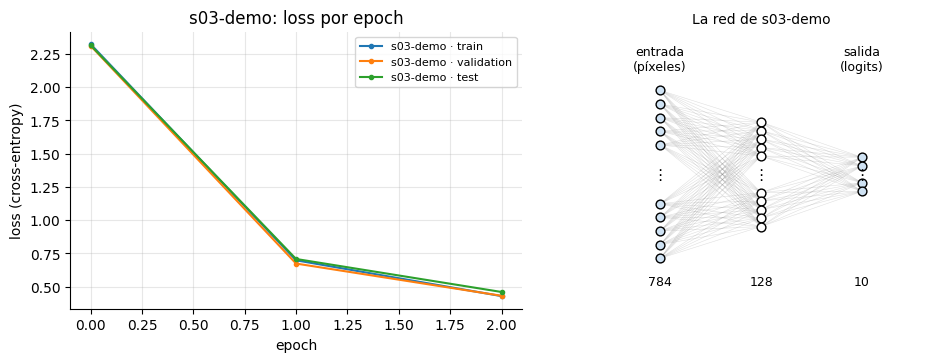

Mirar test en cada epoch está mal (test se usa una vez, al final);
aquí lo graficamos solo para aprender a leer las curvas.


,id,seccion,datos,parametros,mejor_epoch,pasos,ejemplos,acc_train,acc_validation,acc_test,loss_train,loss_validation,loss_test,brecha,segundos,divergio
0,s03-demo,3,2k-limpio,101770,2,32,4000,0.864,0.8766,0.8737,0.429058,0.431527,0.460111,-0.0126,0.251521,False


In [22]:
# Una corrida corta de prueba: 2000 ejemplos de train, 2 epochs.
demo = entrenar(Config(id="s03-demo", seccion=3, epochs=2,
                       idx_train=subconjunto(2000), datos="2k-limpio"))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6),
                             gridspec_kw={"width_ratios": [1.4, 1]})
curvas([demo], metrica="loss", ax=a1, titulo="s03-demo: loss por epoch")
dibujar_red(demo.config.capas, ax=a2, titulo="La red de s03-demo")
plt.show()
print("Mirar test en cada epoch está mal (test se usa una vez, al final);")
print("aquí lo graficamos solo para aprender a leer las curvas.")
tabla_maestra()

Qué viste

- **La loss baja en los tres conjuntos.** La caída es mayor al comienzo.
- Las curvas siguen juntas. En otra corrida, validation puede dejar de mejorar mientras train sigue bajando.

## 4 · De la regresión logística a la red

La **regresión softmax** de la unidad 9 es una red con una sola capa de salida.
Calcula diez logits con $\mathbf z_k^{(1)}=\mathbf W^{(1)}\mathbf x_k+\mathbf b^{(1)}$.
Cada fila de $\mathbf W^{(1)}$ reúne los pesos de un dígito. Su sesgo es el intercepto.
La clase predicha tiene el mayor logit. La cross-entropy es $-\log p_{k,y_k}$, con $p$ calculada por softmax.
PyTorch guarda cada imagen en una fila, por eso calcula `x @ W.T + b`.

Sequential(
  (0): Linear(in_features=784, out_features=10, bias=True)
)
W: (10, 784) (filas = dígito i, columnas = píxel j)
b: (10,)
parámetros: 7850 = 10·784 + 10
entrada: (3, 784) → logits: (3, 10)


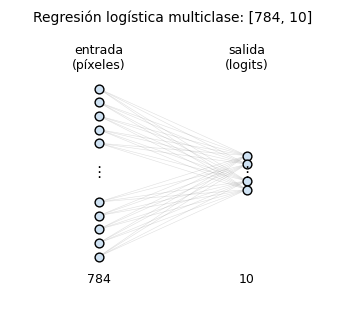

In [23]:
# Una red SIN capas ocultas: capas = [784, 10]. Es una sola capa lineal:
#   z = W x + b,  W de 10 × 784 (filas = dígito destino, columnas = píxel)
# y nada más. Los 10 números z son los logits; CrossEntropyLoss los
# convierte en probabilidades con softmax (sección 18) y les cobra −ln p.
red_logistica = construir_red([784, 10], activacion="identidad")
print(red_logistica)

capa = next(m for m in red_logistica.modules()
            if isinstance(m, torch.nn.Linear))
print("W:", tuple(capa.weight.shape), "(filas = dígito i, columnas = píxel j)")
print("b:", tuple(capa.bias.shape))
print("parámetros:", sum(p.numel() for p in red_logistica.parameters()),
      "= 10·784 + 10")

# Un batch de 3 imágenes de train, para ver las formas de punta a punta.
X_tr, y_tr = DATOS["estandar"]["train"]
with torch.no_grad():
    logits = red_logistica.to(DEVICE)(X_tr[:3])
print("entrada:", tuple(X_tr[:3].shape), "→ logits:", tuple(logits.shape))
del red_logistica, capa, logits                   # aún sin entrenar: se tira

dibujar_red([784, 10], titulo="Regresión logística multiclase: [784, 10]")
plt.show()

**Adam actualiza los pesos con cada mini-batch** de train.
La cross-entropy es la misma de la unidad 9, con $\mu=0$.
Una epoch es una pasada por train. La epoch 0 muestra los pesos recién inicializados.

s04-logistica: 7,850 parámetros · 3128 pasos · mejor epoch 7 · acc validation 0.927 · 4.0 s


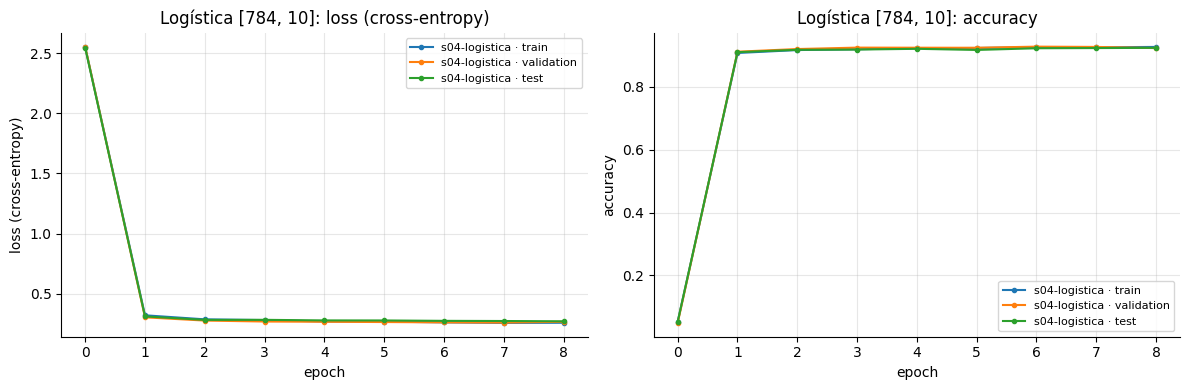

,epoch,loss_train,loss_validation,loss_test,acc_train,acc_validation,acc_test
0,0,2.5502,2.5541,2.5446,0.0530,0.0489,0.0524
1,1,0.3212,0.3044,0.3118,0.9080,0.9121,0.9107
2,2,0.2876,0.2773,0.2828,0.9174,0.9206,0.9181
3,3,0.2815,0.2695,0.2835,0.9199,0.9251,0.9189
4,4,0.2697,0.2675,0.2786,0.9233,0.9248,0.9213
5,5,0.2689,0.2651,0.2783,0.9239,0.9246,0.9177
6,6,0.2624,0.2623,0.2750,0.9265,0.9282,0.9231
7,7,0.2579,0.2609,0.2737,0.9262,0.9273,0.9237
8,8,0.2592,0.2673,0.2713,0.9273,0.9236,0.9244


mejor epoch por validation: 7


In [24]:
# La regresión logística de la unidad 9, entrenada como una red: Adam,
# η = 1e-3, batches de 128, 8 epochs sobre los 50 000 de train.
cfg_logistica = Config(id="s04-logistica", seccion=4, capas=[784, 10],
                       activacion="identidad", optimizer="adam", lr=1e-3,
                       epochs=8)
corrida_logistica = entrenar(cfg_logistica)

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
curvas([corrida_logistica], metrica="loss", ax=ax_loss,
       titulo="Logística [784, 10]: loss (cross-entropy)")
curvas([corrida_logistica], metrica="accuracy", ax=ax_acc,
       titulo="Logística [784, 10]: accuracy")
plt.tight_layout()
plt.show()

# El historial: una fila por evaluación (epoch 0 = antes de entrenar).
columnas = ["epoch", "loss_train", "loss_validation", "loss_test",
            "acc_train", "acc_validation", "acc_test"]
display(corrida_logistica.historial[columnas].round(4))
print("mejor epoch por validation:", corrida_logistica.mejor_epoch)

Train va en azul, validation en naranja y test en verde.
Si adivinas uniformemente, la loss es $\log 10\approx 2.30$ y la accuracy esperada es $10\,\%$.
La logística mejora de golpe y luego se aplana. Curvas cercanas con error persistente sugieren **underfitting**.
Elige la epoch de menor loss de validation.
Aquí graficamos test para practicar. En un proyecto real se usa una sola vez para el reporte final.

Cada fila de $\mathbf W^{(1)}$, vista en una cuadrícula de $28\times28$, es la **plantilla de pesos** de un dígito.
Su logit es $z_i^{(1)}=\sum_j w_{ij}^{(1)}x_j+b_i^{(1)}$.
Si sube un píxel, el rojo indica que sube el logit y el azul que baja.
Busca el centro azul del cero y el trazo vertical rojo del uno.

W: (10, 784) → 10 imágenes de 28 × 28


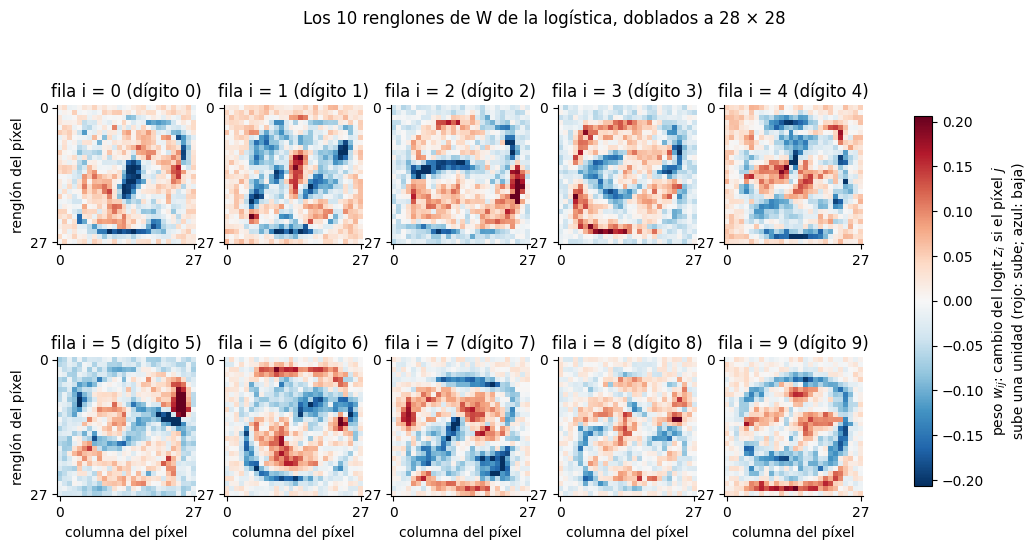

In [25]:
# Cada fila i de W tiene 784 pesos, uno por píxel: se puede volver a doblar
# como una imagen de 28 × 28. Rojo = ese píxel encendido SUBE el logit del
# dígito i; azul = lo BAJA. Usamos el checkpoint de la mejor epoch.
modelo_logistica = cargar(corrida_logistica, "mejor")
lineal = next(m for m in modelo_logistica.modules()
              if isinstance(m, torch.nn.Linear))
W = lineal.weight.detach().cpu()                  # [10, 784]
print("W:", tuple(W.shape), "→ 10 imágenes de 28 × 28")

# Escala simétrica alrededor de 0 (mapa divergente): blanco = peso 0.
limite = float(W.abs().quantile(0.99))
fig, ejes = plt.subplots(2, 5, figsize=(13, 6))
for i, ax in enumerate(ejes.flat):
    im = ax.imshow(W[i].reshape(28, 28), cmap="RdBu_r",
                   vmin=-limite, vmax=limite)
    ax.set_title(f"fila i = {i} (dígito {i})")
    ax.set_xticks([0, 27])
    ax.set_yticks([0, 27])
    ax.grid(False)
for ax in ejes[1]:
    ax.set_xlabel("columna del píxel")
for ax in ejes[:, 0]:
    ax.set_ylabel("renglón del píxel")
barra = fig.colorbar(im, ax=ejes, shrink=0.8)
barra.set_label("peso $w_{ij}$: cambio del logit $z_i$ si el píxel $j$\n"
                "sube una unidad (rojo: sube; azul: baja)")
fig.suptitle("Los 10 renglones de W de la logística, doblados a 28 × 28")
plt.show()
del modelo_logistica, lineal

- La neurona calcula $z_i^{(l)}=\sum_j w_{ij}^{(l)}a_j^{(l-1)}+b_i^{(l)}$ y devuelve $a_i^{(l)}=g^{(l)}(z_i^{(l)})$.
- La capa reúne esas neuronas en paralelo. **ReLU introduce no linealidad** con $g(z)=\max(0,z)$.
- Su derivada vale $1$ si $z>0$ y $0$ si $z<0$. En backpropagation usamos $g'(0)=0$.
- Con identidad en ambas capas, todo se reduce a $\mathbf W'=\mathbf W^{(2)}\mathbf W^{(1)}$ y $\mathbf b'=\mathbf W^{(2)}\mathbf b^{(1)}+\mathbf b^{(2)}$.

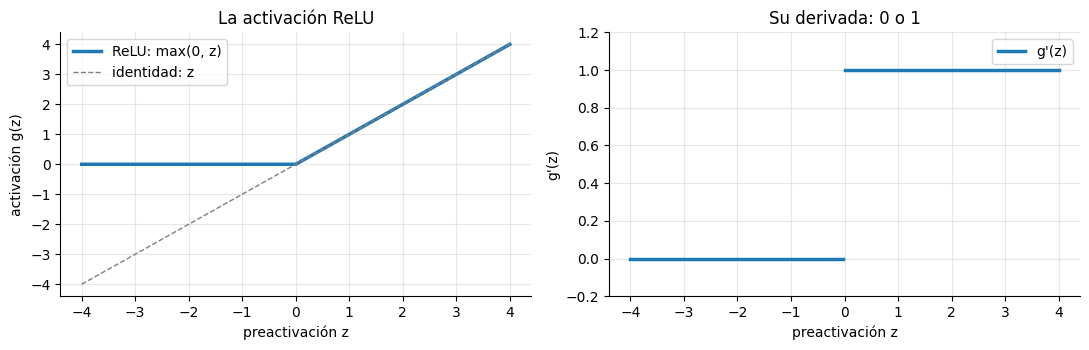

In [26]:
# La activación ReLU, g(z) = max(0, z), y su derivada g'(z) (g'(0) = 0
# por convención, como en el notebook 01).
z = torch.linspace(-4, 4, 401)
g = torch.relu(z)
g_prima = (z > 0).float()

fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(11, 3.6))
ax_g.plot(z, g, color=COLORES["train"], lw=2.5, label="ReLU: max(0, z)")
ax_g.plot(z, z, color="gray", ls="--", lw=1, label="identidad: z")
ax_g.set_title("La activación ReLU")
ax_g.set_xlabel("preactivación z")
ax_g.set_ylabel("activación g(z)")
ax_g.legend()
ax_d.plot(z[z <= 0], g_prima[z <= 0], color=COLORES["train"], lw=2.5)
ax_d.plot(z[z > 0], g_prima[z > 0], color=COLORES["train"], lw=2.5,
          label="g'(z)")
ax_d.set_ylim(-0.2, 1.2)
ax_d.set_title("Su derivada: 0 o 1")
ax_d.set_xlabel("preactivación z")
ax_d.set_ylabel("g'(z)")
ax_d.legend()
plt.tight_layout()
plt.show()

In [27]:
# ¿Por qué hace falta la activación? Dos capas SIN activación (identidad)
# colapsan en una sola capa afín: W' = W2 W1 y b' = W2 b1 + b2.
torch.manual_seed(SEMILLA)
dos_lineales = construir_red([784, 128, 10], activacion="identidad").to(DEVICE)
c1, c2 = [m for m in dos_lineales.modules() if isinstance(m, torch.nn.Linear)]
x = X_tr[:5]
with torch.no_grad():
    W_prima = c2.weight @ c1.weight               # [10, 128] @ [128, 784]
    b_prima = c2.weight @ c1.bias + c2.bias       # [10]
    por_la_red = dos_lineales(x)
    por_una_capa = x @ W_prima.T + b_prima        # filas = observaciones
print("W':", tuple(W_prima.shape), "  b':", tuple(b_prima.shape))
print("¿la red de dos capas lineales = una sola capa afín?",
      torch.allclose(por_la_red, por_una_capa, atol=1e-4))
del dos_lineales, c1, c2, W_prima, b_prima

W': (10, 784)   b': (10,)
¿la red de dos capas lineales = una sola capa afín? True


**Apuesta.** ¿Cuánto mejora la accuracy de validation con $128$ unidades ReLU? (a) Nada, (b) menos de un punto o (c) varios puntos.
¿También se cumple (d), que la red comete menos de la mitad de los errores?
Cada capa tiene $d_l d_{l-1}+d_l$ parámetros. La logística tiene $7\,850$ y la red oculta, $101\,770$.
Ambos puntos de accuracy de la epoch 0 quedan debajo del eje recortado. El $10\,\%$ es la referencia de azar.


Red [784, 10]: 7,850 parámetros


,capa l,d_{l-1},d_l,pesos d_l·d_{l-1},sesgos d_l,total
0,1,784,10,7840,10,7850



Red [784, 128, 10]: 101,770 parámetros


,capa l,d_{l-1},d_l,pesos d_l·d_{l-1},sesgos d_l,total
0,1,784,128,100352,128,100480
1,2,128,10,1280,10,1290


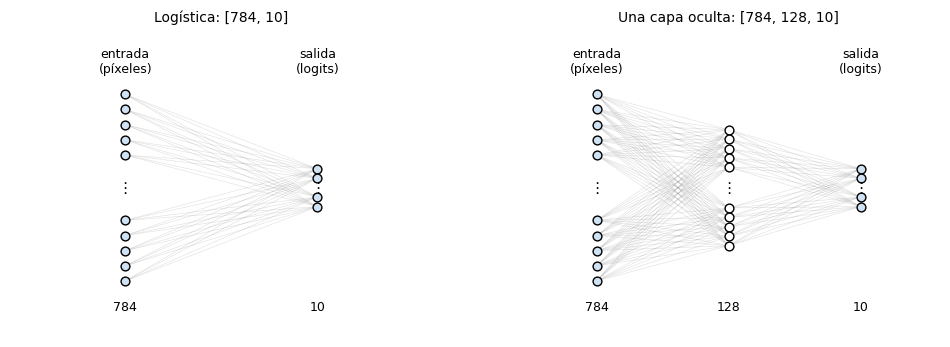

In [28]:
# Las dos redes, dibujadas, y sus parámetros capa por capa:
# la capa l tiene d_l · d_{l-1} pesos + d_l sesgos.
def tabla_parametros(capas):
    filas = []
    for l in range(1, len(capas)):
        d_ant, d_l = capas[l - 1], capas[l]
        filas.append({"capa l": l, "d_{l-1}": d_ant, "d_l": d_l,
                      "pesos d_l·d_{l-1}": d_l * d_ant, "sesgos d_l": d_l,
                      "total": d_l * d_ant + d_l})
    tabla = pd.DataFrame(filas)
    total = int(tabla["total"].sum())
    # Comprobación: la fórmula coincide con lo que cuenta PyTorch.
    red = construir_red(capas, activacion="relu")
    assert total == sum(p.numel() for p in red.parameters())
    return tabla, total


for capas in ([784, 10], [784, 128, 10]):
    tabla, total = tabla_parametros(capas)
    print(f"\nRed {capas}: {total:,} parámetros")
    display(tabla)

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(12, 4))
dibujar_red([784, 10], ax=ax_a, titulo="Logística: [784, 10]")
dibujar_red([784, 128, 10], ax=ax_b, titulo="Una capa oculta: [784, 128, 10]")
plt.show()

In [29]:
# La red de una capa oculta: 128 neuronas ReLU entre la entrada y la salida.
# Mismo optimizer, η, batch y epochs que la logística: solo cambia la red.
# Esta corrida es la LÍNEA BASE del notebook (la reutilizan §6 y §16).
cfg_oculta = Config(id="s04-oculta", seccion=4, capas=[784, 128, 10],
                    activacion="relu", optimizer="adam", lr=1e-3, epochs=8)
corrida_oculta = entrenar(cfg_oculta)

s04-oculta: 101,770 parámetros · 3128 pasos · mejor epoch 5 · acc validation 0.976 · 5.0 s


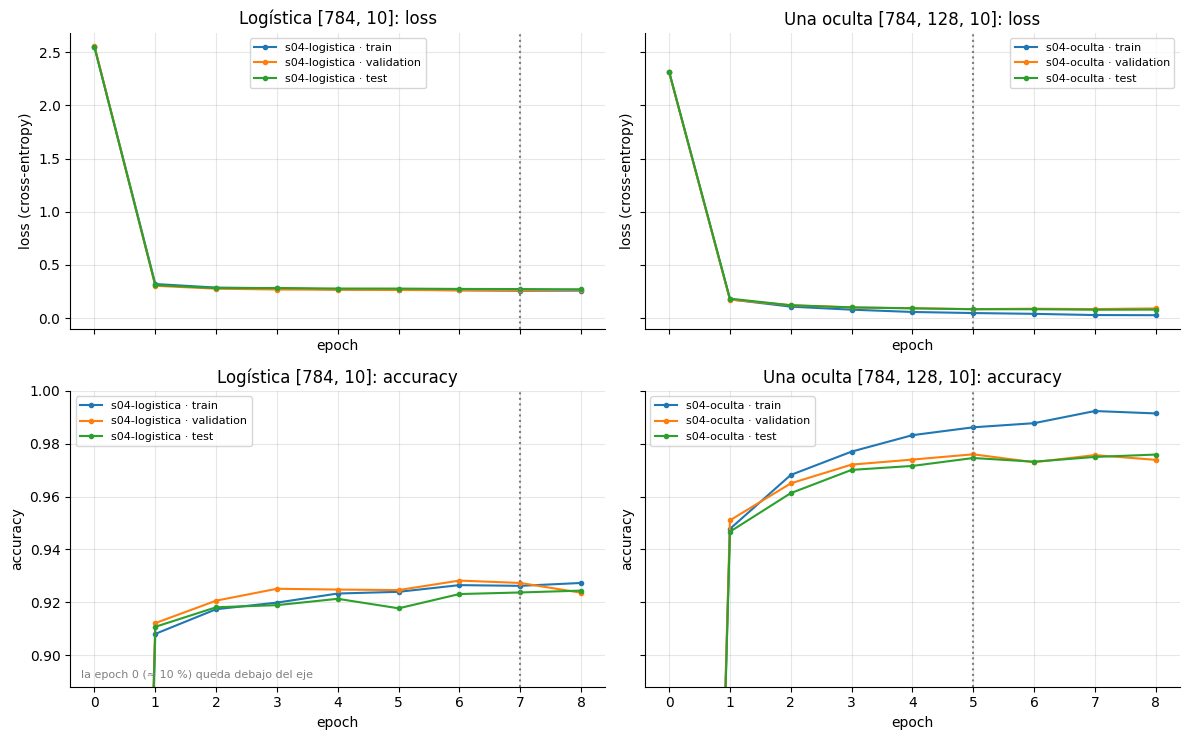

,id,seccion,datos,parametros,mejor_epoch,pasos,ejemplos,acc_train,acc_validation,acc_test,loss_train,loss_validation,loss_test,brecha,segundos,divergio
0,s04-logistica,4,50k-limpio,7850,7,2737,350000,0.92620,0.9273,0.9237,0.257914,0.260913,0.273721,-0.00110,3.974079,False
1,s04-oculta,4,50k-limpio,101770,5,1955,250000,0.98622,0.9760,0.9746,0.048456,0.085416,0.083881,0.01022,5.011929,False


error de validation, logística:   7.27%
error de validation, una oculta:  2.40%
cambio en accuracy de validation al agregar la capa oculta: +4.87 puntos
cociente de errores logística / oculta: 3.03
¿la red oculta se equivoca menos de la mitad de las veces? (opción d): sí


In [30]:
# Las dos corridas lado a lado: columnas = red, renglones = loss y accuracy,
# mismos ejes en cada renglón. La línea punteada gris marca la mejor epoch
# de cada red, elegida con la loss de validation (nunca con test).
pareja = [(corrida_logistica, "Logística [784, 10]"),
          (corrida_oculta, "Una oculta [784, 128, 10]")]
fig, ejes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True, sharey="row")
for col, (c, nombre) in enumerate(pareja):
    curvas([c], metrica="loss", ax=ejes[0, col], titulo=f"{nombre}: loss")
    curvas([c], metrica="accuracy", ax=ejes[1, col],
           titulo=f"{nombre}: accuracy")
    for ax in ejes[:, col]:
        ax.axvline(c.mejor_epoch, color="gray", ls=":", lw=1.5)
        ax.legend(fontsize=8)
# La epoch 0 (≈ 10 % de aciertos) aplastaría las diferencias finales:
# el eje de accuracy arranca en lo peor que se ve desde la epoch 1.
desde_1 = [c.historial.loc[c.historial["epoch"] >= 1,
                           ["acc_train", "acc_validation", "acc_test"]]
           for c, _ in pareja]
piso = min(float(np.nanmin(d.to_numpy())) for d in desde_1 if len(d))
ejes[1, 0].set_ylim(max(0.0, piso - 0.02), 1.0)
ejes[1, 0].text(0.02, 0.03, "la epoch 0 (≈ 10 %) queda debajo del eje",
                transform=ejes[1, 0].transAxes, fontsize=8, color="gray")
fig.tight_layout()
plt.show()

display(tabla_maestra([4]))

# Error de validation en la mejor epoch (elegida con validation, no con test).
def error_validation(corrida):
    h = corrida.historial
    fila = h[h["epoch"] == corrida.mejor_epoch].iloc[-1]
    return 1.0 - float(fila["acc_validation"])


e_log = error_validation(corrida_logistica)
e_oculta = error_validation(corrida_oculta)
print(f"error de validation, logística:   {e_log:.2%}")
print(f"error de validation, una oculta:  {e_oculta:.2%}")
print(f"cambio en accuracy de validation al agregar la capa oculta: "
      f"{100 * (e_log - e_oculta):+.2f} puntos")
if e_oculta > 0:
    print(f"cociente de errores logística / oculta: {e_log / e_oculta:.2f}")
print("¿la red oculta se equivoca menos de la mitad de las veces? (opción d):",
      "sí" if e_oculta < e_log / 2 else "no")

<details><summary>Respuesta</summary>

Se cumplieron (c) y (d). **Ganar pocos puntos puede eliminar muchos errores** cuando el modelo de referencia ya acierta mucho.
Las ReLU permiten fronteras no lineales. En otra corrida puede cambiar la fracción de errores que se elimina.

</details>

**Qué viste**

- La loss de la logística cayó en la primera epoch y luego apenas cambió.
- La capa oculta con ReLU redujo la loss de train y los errores de validation.
- Con ReLU se abrió una brecha entre train y validation. En otra corrida puede ser menor.

## 05 · Normalizar la entrada

Compara el píxel crudo $x$, el reescalado $x/255$ y el estandarizado $(x/255-\text{MEDIA})/\text{DESV}$.
**Calcula la media y la desviación solo en train** y reutilízalas en validation y test para evitar leakage.
La estandarización deja media $0$ y desviación $1$ para el conjunto de píxeles de train.
Las corridas comparten red ReLU, SGD sin momentum, learning rate, pesos iniciales y secuencia de batches.

In [31]:
# Las tres escalas de la misma imagen viven ya en DATOS (sección 2):
#   "crudo"    : el píxel como viene, un entero de 0 a 255
#   "01"       : x / 255, en [0, 1]
#   "estandar" : (x/255 − MEDIA) / DESV, con MEDIA y DESV de TRAIN
ESCALAS_S05 = ["crudo", "01", "estandar"]
print(f"MEDIA = {MEDIA:.4f}   DESV = {DESV:.4f}   (escala [0, 1], solo train)")

# Comprobación: MEDIA y DESV salen de train y de nada más.
X01_train = DATOS["01"]["train"][0]
print(f"recalculadas sobre train: media = {X01_train.mean().item():.4f}, "
      f"desv = {X01_train.std().item():.4f}")

# Mínimo, máximo, media y desviación de los píxeles, por escala y conjunto.
filas = []
for escala in ESCALAS_S05:
    for conjunto in ["train", "validation", "test"]:
        X = DATOS[escala][conjunto][0]
        filas.append({"escala": escala, "conjunto": conjunto,
                      "mínimo": X.min().item(), "máximo": X.max().item(),
                      "media": X.mean().item(), "desv": X.std().item()})
display(pd.DataFrame(filas).round(4))
# Fíjate en "estandar": en train la media es 0 y la desviación 1 por
# construcción; en validation y test quedan CERCA de 0 y 1, no exactas,
# porque se les aplicó la receta de train sin recalcularla.

MEDIA = 0.1310   DESV = 0.3085   (escala [0, 1], solo train)
recalculadas sobre train: media = 0.1310, desv = 0.3085


,escala,conjunto,mínimo,máximo,media,desv
0,crudo,train,0.0000,255.000,33.3951,78.6662
1,crudo,validation,0.0000,255.000,32.9349,78.0710
2,crudo,test,0.0000,255.000,33.7912,79.1725
3,01,train,0.0000,1.000,0.1310,0.3085
4,01,validation,0.0000,1.000,0.1292,0.3062
5,01,test,0.0000,1.000,0.1325,0.3105
6,estandar,train,-0.4245,2.817,0.0000,1.0000
7,estandar,validation,-0.4245,2.817,-0.0059,0.9924
8,estandar,test,-0.4245,2.817,0.0050,1.0064


**La forma del histograma se conserva** al desplazar o reescalar el eje de píxeles.
En la escala estandarizada, el fondo queda debajo de cero y el blanco por encima.
El eje vertical logarítmico hace visibles los valores poco frecuentes. La línea discontinua marca la media muestral.

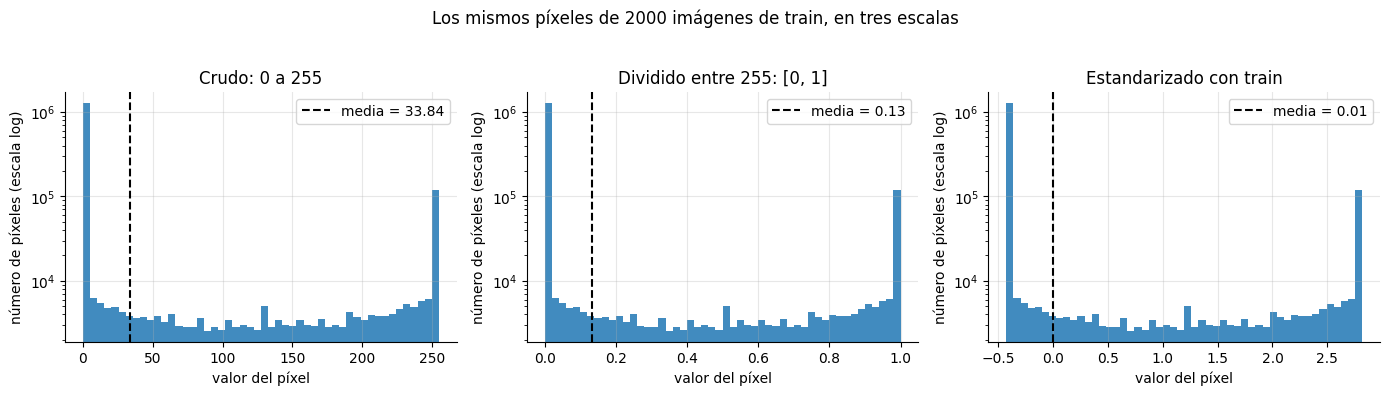

In [32]:
# Histograma de los píxeles de una muestra fija de imágenes de train, en las
# tres escalas. Es la misma muestra en los tres paneles: solo cambia el eje x.
generador = torch.Generator().manual_seed(SEMILLA)
n_train = DATOS["01"]["train"][0].shape[0]
n_muestra = min(n_train, 200 if RAPIDO else 2000)
muestra = torch.randperm(n_train, generator=generador)[:n_muestra]

titulos = {"crudo": "Crudo: 0 a 255", "01": "Dividido entre 255: [0, 1]",
           "estandar": "Estandarizado con train"}
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, escala in zip(ejes, ESCALAS_S05):
    X = DATOS[escala]["train"][0]
    valores = X[muestra.to(X.device)].flatten().cpu().numpy()
    ax.hist(valores, bins=50, color=COLORES["train"], alpha=0.85)
    ax.axvline(valores.mean(), color="black", linestyle="--",
               label=f"media = {valores.mean():.2f}")
    ax.set_yscale("log")                  # casi todo es fondo: escala log
    ax.set_title(titulos[escala])
    ax.set_xlabel("valor del píxel")
    ax.set_ylabel("número de píxeles (escala log)")
    ax.legend()
fig.suptitle(f"Los mismos píxeles de {n_muestra} imágenes de train, "
             "en tres escalas", y=1.03)
plt.tight_layout()
plt.show()

En backpropagation, $\partial\ell/\partial w_{ij}^{(1)}=\delta_i^{(1)}x_j$, con $\delta_i^{(1)}=\partial\ell/\partial z_i^{(1)}$.
Para una imagen, un paso de SGD cambia su preactivación vía los pesos en $-\eta\,\delta_i^{(1)}\sum_j x_j^2$.
Con $\delta_i^{(1)}$ fijo, multiplicar $x$ por $255$ amplifica ese efecto por $255^2$.
Compara el **tamaño del paso respecto a los pesos** con $\eta\lVert\nabla_W L_{\mathcal B}\rVert_F/\lVert W\rVert_F$.

In [33]:
# Antes de entrenar: el MISMO batch de 128 imágenes y los MISMOS pesos
# iniciales; solo cambia la escala de la entrada. ¿Qué tan grande sale el
# gradiente de cada capa, y qué tan grande sería un paso de SGD con η = 0.03?
perdida = nn.CrossEntropyLoss()
eta = 0.03
idx = torch.arange(128, device=DEVICE)
filas = []
for escala in ESCALAS_S05:
    torch.manual_seed(SEMILLA)                   # mismos pesos en las tres
    red = construir_red([784, 128, 10]).to(DEVICE)
    lineales = [m for m in red.modules() if isinstance(m, nn.Linear)]
    X, y = DATOS[escala]["train"]
    loss = perdida(red(X[idx]), y[idx])          # forward
    loss.backward()                              # backpropagation
    for l, capa in enumerate(lineales, start=1):
        W, g = capa.weight, capa.weight.grad     # g = ∇_W L, misma forma que W
        filas.append({
            "escala": escala, "capa": l, "loss inicial": loss.item(),
            "‖∇W‖": g.norm().item(),
            # tamaño del paso de SGD relativo al tamaño de los pesos
            "η‖∇W‖ / ‖W‖": (eta * g.norm() / W.norm()).item()})
    del red, lineales, loss
tabla_grad = pd.DataFrame(filas)
display(tabla_grad.round(4))

# Cuántas veces más grande es el gradiente de la capa 1 que con [0, 1].
capa1 = tabla_grad[tabla_grad["capa"] == 1].set_index("escala")["‖∇W‖"]
for escala in ESCALAS_S05:
    print(f"capa 1, {escala:>8}: ‖∇W‖ es {capa1[escala] / capa1['01']:8.1f} "
          "veces el de la escala [0, 1]")

,escala,capa,loss inicial,‖∇W‖,η‖∇W‖ / ‖W‖
0,crudo,1,22.9455,243.8372,1.1216
1,crudo,2,22.9455,103.7390,1.7119
2,01,1,2.2926,0.6279,0.0029
3,01,2,2.2926,0.2181,0.0036
4,estandar,1,2.2788,1.8890,0.0087
5,estandar,2,2.2788,0.7024,0.0116


capa 1,    crudo: ‖∇W‖ es    388.4 veces el de la escala [0, 1]
capa 1,       01: ‖∇W‖ es      1.0 veces el de la escala [0, 1]
capa 1, estandar: ‖∇W‖ es      3.0 veces el de la escala [0, 1]


**Apuesta.** Con el mismo $\eta$, ¿cuál dará menor loss de validation entre la escala cruda, $[0,1]$ y la estandarizada?
¿Cuál podría quedarse cerca del azar?

In [34]:
# Tres corridas idénticas salvo la escala de la entrada: red [784, 128, 10]
# con ReLU, SGD sin momentum, η = 0.03, batches de 128, 5 epochs, los mismos
# pesos iniciales (semilla_init) y el mismo orden de batches (semilla_orden).
CORRIDAS_S05 = {}
for escala in ESCALAS_S05:
    cfg = Config(id=f"s05-{escala}", seccion=5, capas=[784, 128, 10],
                 activacion="relu", optimizer="sgd", lr=0.03, batch=128,
                 epochs=5, escala=escala,
                 semilla_init=SEMILLA, semilla_orden=SEMILLA)
    CORRIDAS_S05[escala] = entrenar(cfg)   # imprime su resumen al terminar
# Si una corrida divergió, el resumen lo dice y marca el primer paso no finito.

s05-crudo: 101,770 parámetros · 1955 pasos · mejor epoch 1 · acc validation 0.205 · 2.0 s
s05-01: 101,770 parámetros · 1955 pasos · mejor epoch 5 · acc validation 0.920 · 2.1 s
s05-estandar: 101,770 parámetros · 1955 pasos · mejor epoch 5 · acc validation 0.957 · 2.4 s


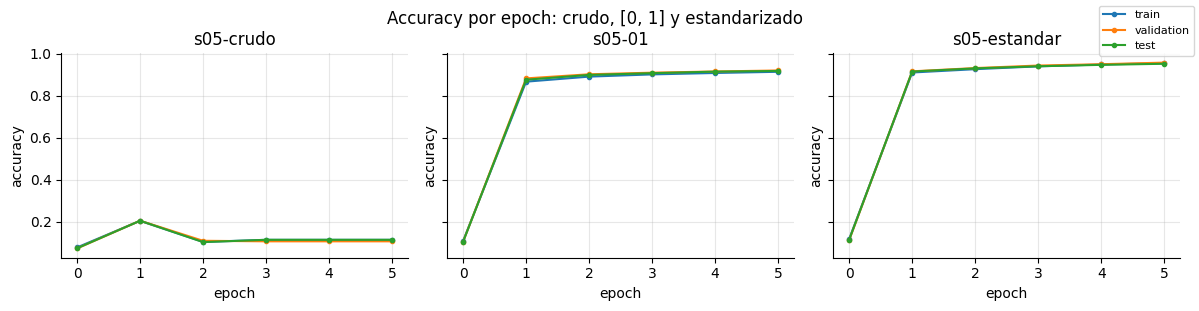

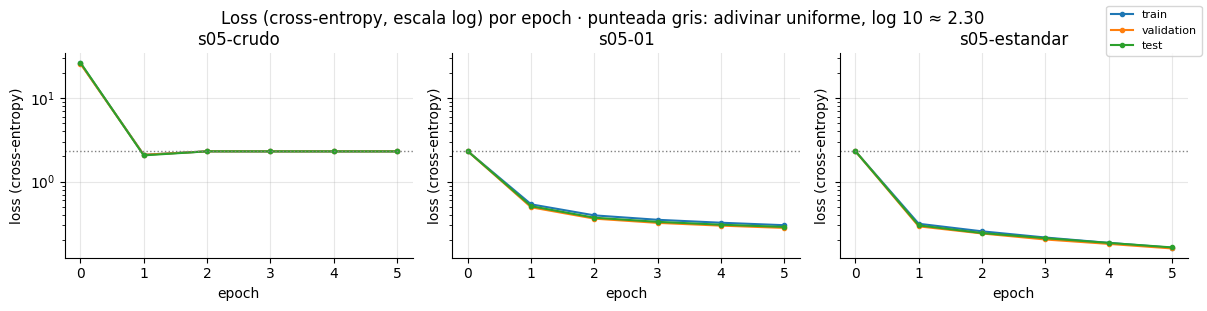

In [35]:
# Las tres corridas lado a lado, con los MISMOS ejes (misma_y=True).
# Arriba la accuracy; abajo la loss en escala log, porque la de "crudo"
# puede estar órdenes de magnitud por encima de las otras dos.
lista_s05 = [CORRIDAS_S05[e] for e in ESCALAS_S05]
fig_acc = rejilla(lista_s05, x="epoch", metrica="accuracy", columnas=3,
                  misma_y=True)
fig_acc.suptitle("Accuracy por epoch: crudo, [0, 1] y estandarizado", y=1.02)


def leyenda_por_conjunto(fig):
    """La leyenda común de rejilla copia las etiquetas del primer panel
    ("s05-crudo · train", …); aquí la dejamos solo con train/validation/test."""
    for leyenda in list(fig.legends):
        leyenda.remove()
    lineas, etiquetas = fig.axes[0].get_legend_handles_labels()
    fig.legend(lineas, [e.split(" · ")[-1] for e in etiquetas],
               loc="upper right", fontsize=8)


leyenda_por_conjunto(fig_acc)
plt.show()

fig_loss = rejilla(lista_s05, x="epoch", metrica="loss", columnas=3,
                   misma_y=True)
for ax in fig_loss.axes:                 # sharey: los tres paneles a la vez
    ax.set_yscale("log")
    ax.axhline(np.log(10), color="gray", linestyle=":", linewidth=1)
leyenda_por_conjunto(fig_loss)
fig_loss.suptitle("Loss (cross-entropy, escala log) por epoch · "
                  "punteada gris: adivinar uniforme, log 10 ≈ 2.30", y=1.02)
plt.show()

**La vista por paso muestra picos que la vista por epoch puede ocultar**.
A la izquierda, compara la loss de train con $\log 10$ en escala logarítmica.
A la derecha, compara la accuracy de validation con el $10\,\%$ de azar.
Aquí graficamos test para practicar. En un proyecto real se usa una sola vez para el reporte final.

s05-crudo-arranque: 101,770 parámetros · 50 pasos · mejor epoch 0.127877 · acc validation 0.236 · 0.1 s
s05-01-arranque: 101,770 parámetros · 50 pasos · mejor epoch 0.127877 · acc validation 0.619 · 0.1 s
s05-estandar-arranque: 101,770 parámetros · 50 pasos · mejor epoch 0.127877 · acc validation 0.856 · 0.1 s


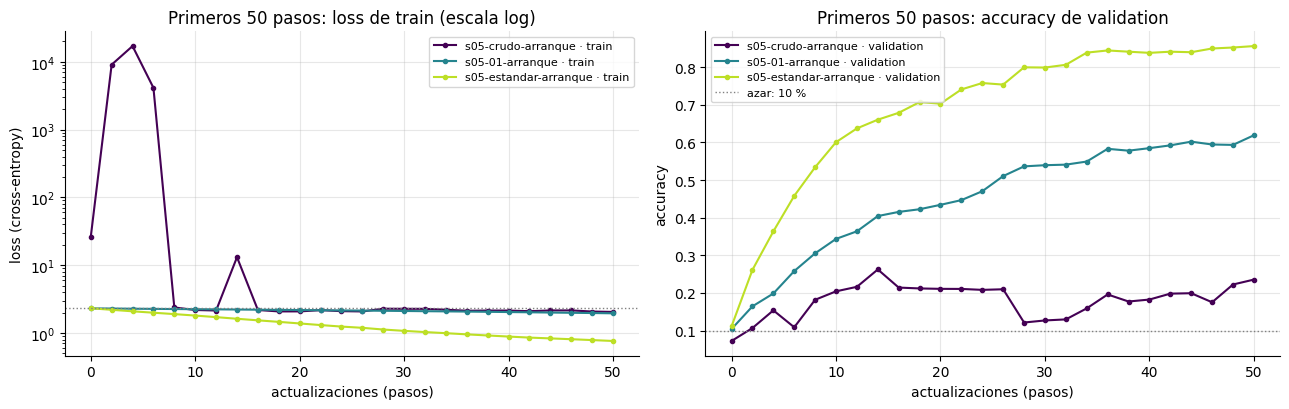

In [36]:
# Lupa sobre el arranque: las mismas tres configuraciones, pero solo 50 pasos
# y evaluando cada 2 pasos (eval_cada_pasos). Mismas semillas que arriba:
# mismos pesos iniciales y mismos batches, así que son los mismos primeros
# pasos de las corridas de 5 epochs, mirados de cerca.
ARRANQUE_S05 = {}
for escala in ESCALAS_S05:
    cfg = Config(id=f"s05-{escala}-arranque", seccion=5, capas=[784, 128, 10],
                 activacion="relu", optimizer="sgd", lr=0.03, batch=128,
                 epochs=5, max_pasos=50, eval_cada_pasos=2, escala=escala,
                 semilla_init=SEMILLA, semilla_orden=SEMILLA)
    ARRANQUE_S05[escala] = entrenar(cfg)

lista_arranque = [ARRANQUE_S05[e] for e in ESCALAS_S05]
n_pasos = int(max(c.historial["pasos"].max() for c in lista_arranque))
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(13, 4.2))
curvas(lista_arranque, x="pasos", metrica="loss", conjuntos=("train",),
       ax=ax_loss, titulo=f"Primeros {n_pasos} pasos: loss de train (escala log)")
ax_loss.set_yscale("log")
ax_loss.axhline(np.log(10), color="gray", linestyle=":", linewidth=1)
curvas(lista_arranque, x="pasos", metrica="accuracy",
       conjuntos=("validation",), ax=ax_acc,
       titulo=f"Primeros {n_pasos} pasos: accuracy de validation")
ax_acc.axhline(0.1, color="gray", linestyle=":", linewidth=1,
               label="azar: 10 %")
ax_acc.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [37]:
# La parte de la tabla maestra que produjo esta sección.
display(tabla_maestra(secciones=[5]))

,id,seccion,datos,parametros,mejor_epoch,pasos,ejemplos,acc_train,acc_validation,acc_test,loss_train,loss_validation,loss_test,brecha,segundos,divergio
0,s05-crudo,5,50k-limpio,101770,1.000000,391,50000,0.20402,0.2046,0.2045,2.096288,2.094281,2.062927,-0.00058,2.046196,False
1,s05-01,5,50k-limpio,101770,5.000000,1955,250000,0.91378,0.9200,0.9177,0.302220,0.280447,0.288193,-0.00622,2.125179,False
2,s05-estandar,5,50k-limpio,101770,5.000000,1955,250000,0.95476,0.9574,0.9520,0.162707,0.159589,0.164128,-0.00264,2.403341,False
3,s05-crudo-arranque,5,50k-limpio,101770,0.127877,50,6400,0.23816,0.2356,0.2392,2.042673,2.021873,2.388534,0.00256,0.062474,False
4,s05-01-arranque,5,50k-limpio,101770,0.127877,50,6400,0.59930,0.6188,0.6022,1.947213,1.937771,1.940706,-0.01950,0.065869,False
5,s05-estandar-arranque,5,50k-limpio,101770,0.127877,50,6400,0.83526,0.8556,0.8461,0.760980,0.718863,0.734828,-0.02034,0.065264,False


<details><summary>Respuesta</summary>

**Estandarizar dio ventaja desde el arranque** frente a $[0,1]$. La ventaja se redujo y persistió.
Con píxeles crudos, el paso inicial fue grande respecto a los pesos. La loss se disparó, pero la corrida terminó.
Una hipótesis es que el salto apagó muchas ReLU. Haría falta medir sus activaciones.

</details>

**Ajusta el learning rate.** Para píxeles crudos, ¿dividirías $\eta$ entre $255^2$ o probarías otro valor?

<details><summary>Respuesta</summary>

Dividir $\eta$ entre $255^2$ compensa el efecto de los pesos sobre una imagen con $\delta_i^{(1)}$ fijo.
Para el sesgo, $\partial\ell/\partial b_i^{(1)}=\delta_i^{(1)}$. **Reducir $\eta$ también achica el paso del sesgo**.
Los logits iniciales dependen de la escala de los píxeles desde antes del primer paso.

</details>

**Qué viste**

- Con píxeles crudos, la loss de train se disparó y volvió cerca de $\log 10$. La corrida terminó con valores finitos.
- Su accuracy de validation repuntó al inicio y acabó cerca del azar. En otra corrida, la loss podría volverse no finita.
- Estandarizar aventajó a $[0,1]$ desde el arranque. La ventaja se redujo hacia el final.

## 06 · La línea base y cómo leer tres curvas

La **línea base** reutiliza la red $784\to128\to10$ con ReLU, Adam y $\eta=10^{-3}$.
La configuración completa usa ocho epochs y 50 000 ejemplos estandarizados de train.
Aquí train va en azul, validation en naranja y test en verde.
La sección 7 usa SGD con 4096 imágenes. Allí todas las curvas son de validation y el color identifica el batch.

> **Aviso.** Mirar test en cada epoch está mal: test se usa una sola vez, al final, para reportar. Aquí lo hacemos solo de manera didáctica, para aprender a leer las tres curvas. Ninguna decisión del notebook usa test.

In [38]:
# La línea base es la red de una capa oculta de la sección 4. Si ya la
# entrenaste, la reutilizamos tal cual; si saltaste hasta aquí, la entrenamos
# con la MISMA configuración y el MISMO ID, así que todo lo que sigue es igual.
if "s04-oculta" in CORRIDAS:
    base = CORRIDAS["s04-oculta"]
    print("Reutilizo la corrida s04-oculta de la sección 4.")
else:
    print("No encontré s04-oculta (¿saltaste la sección 4?). La entreno ahora "
          "con la misma configuración.")
    base = entrenar(Config(id="s04-oculta", seccion=4, capas=[784, 128, 10],
                           activacion="relu", optimizer="adam", lr=1e-3,
                           epochs=8))

h = base.historial                       # una fila por evaluación (epoch)
cfg = base.config
print(f"red {cfg.capas}, activación {cfg.activacion}, optimizer {cfg.optimizer}, "
      f"η = {cfg.lr}, batch {cfg.batch}, epochs {h['epoch'].max():g}")
print(f"parámetros: {base.parametros:,}")
# La tabla de las curvas la mostramos después de la apuesta, junto a la figura.

Reutilizo la corrida s04-oculta de la sección 4.
red [784, 128, 10], activación relu, optimizer adam, η = 0.001, batch 128, epochs 8
parámetros: 101,770


**El azar da dos referencias.**

- Con probabilidad uniforme, la cross-entropy es $-\log(1/10)=\log 10\approx 2.30$.
- Al elegir un dígito al azar, la accuracy esperada es $10\,\%$.
- Predecir siempre las proporciones de train da una loss cercana a $\log 10$ porque MNIST está casi balanceado.

In [39]:
import math

# Dos referencias analíticas para «no saber nada». Se calculan, no se copian.
LOSS_UNIFORME = math.log(10)  # −log(1/10): dar 1/10 de probabilidad a cada dígito
ACC_AZAR = 1 / 10             # elegir un dígito al azar acierta 1 de cada 10

# Otra manera de no saber nada: predecir siempre la proporción de cada dígito
# en train. Su cross-entropy es la entropía de esas proporciones; como MNIST
# está casi balanceado, sale casi igual que log(10).
_, y_tr = DATOS[cfg.escala]["train"]
prop = torch.bincount(y_tr, minlength=10).float() / len(y_tr)
entropia = -(prop * prop.log()).sum().item()

print(f"loss de adivinar uniforme:            log(10) = {LOSS_UNIFORME:.4f}")
print(f"loss de predecir las proporciones:    {entropia:.4f}")
print(f"accuracy de adivinar al azar:         {ACC_AZAR:.0%}")

# La epoch 0 es la red recién inicializada, antes de cualquier paso.
cero = h[h["epoch"] == 0]
if len(cero):
    e0 = cero.iloc[0]
    print(f"\nepoch 0 (pesos aleatorios, sin entrenar):")
    for conj in ("train", "validation", "test"):
        print(f"  {conj:<10} loss = {e0['loss_' + conj]:.4f}   "
              f"accuracy = {e0['acc_' + conj]:.2%}")
else:
    print("\nEl historial no trae la epoch 0.")

loss de adivinar uniforme:            log(10) = 2.3026
loss de predecir las proporciones:    2.3010
accuracy de adivinar al azar:         10%

epoch 0 (pesos aleatorios, sin entrenar):
  train      loss = 2.3132   accuracy = 11.68%
  validation loss = 2.3117   accuracy = 11.16%
  test       loss = 2.3157   accuracy = 11.35%


**Apuesta.** Al final, ¿cuál de los tres conjuntos tendrá menor loss y cuál mayor accuracy?
¿Esperas que validation y test queden cerca o se separen?

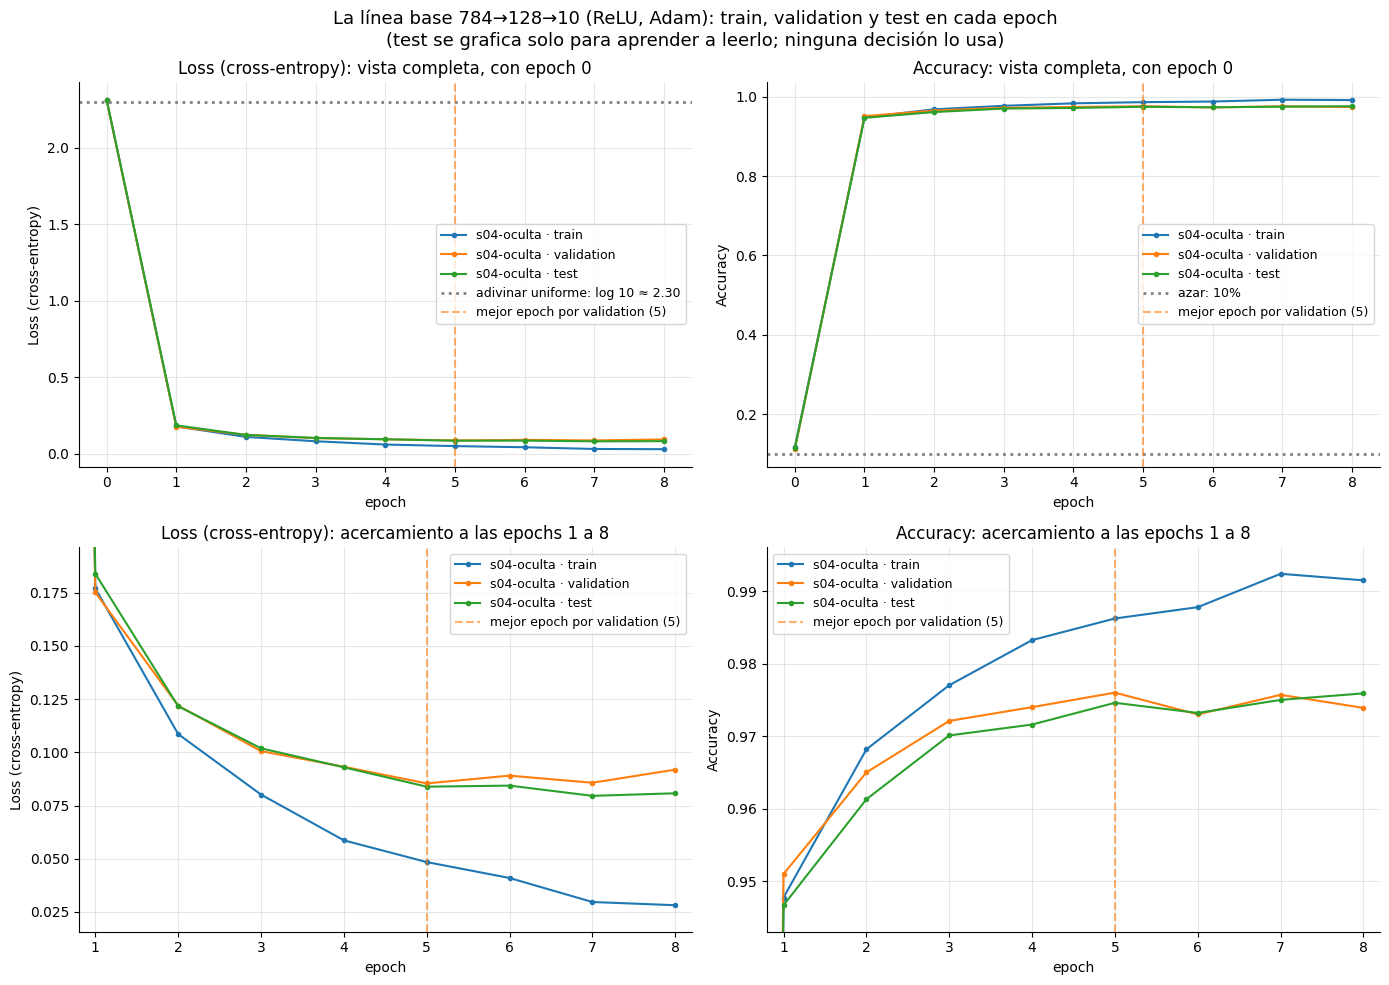

mejor epoch por validation (menor loss): 5


,pasos,loss_train,loss_validation,loss_test,acc_train,acc_validation,acc_test
epoch,,,,,,,
0,0,2.3132,2.3117,2.3157,0.1168,0.1116,0.1135
1,391,0.1771,0.1752,0.1839,0.9478,0.9510,0.9467
2,782,0.1086,0.1220,0.1217,0.9682,0.9650,0.9613
3,1173,0.0802,0.1006,0.1019,0.9770,0.9721,0.9701
4,1564,0.0587,0.0932,0.0930,0.9832,0.9740,0.9716
5,1955,0.0485,0.0854,0.0839,0.9862,0.9760,0.9746
6,2346,0.0410,0.0891,0.0844,0.9878,0.9730,0.9732
7,2737,0.0297,0.0857,0.0796,0.9924,0.9757,0.9750
8,3128,0.0282,0.0919,0.0808,0.9915,0.9739,0.9759


In [40]:
# Arriba, la vista completa con las referencias; abajo, un acercamiento a las
# epochs 1 en adelante, donde las tres curvas se separan.
fig, ejes = plt.subplots(2, 2, figsize=(14, 10))
ultima_epoch = float(h["epoch"].max())   # la última evaluación
tramo = h[h["epoch"] >= 1]

for col, metrica, ref, etiqueta_ref in [
        (0, "loss", LOSS_UNIFORME,
         f"adivinar uniforme: log 10 ≈ {LOSS_UNIFORME:.2f}"),
        (1, "accuracy", ACC_AZAR, f"azar: {ACC_AZAR:.0%}")]:
    arriba, abajo = ejes[0, col], ejes[1, col]
    nombre = "Loss (cross-entropy)" if metrica == "loss" else "Accuracy"
    curvas([base], metrica=metrica, ax=arriba,
           titulo=f"{nombre}: vista completa, con epoch 0")
    arriba.axhline(ref, color="gray", ls=":", lw=2, label=etiqueta_ref)
    curvas([base], metrica=metrica, ax=abajo,
           titulo=f"{nombre}: acercamiento a las epochs 1 a {ultima_epoch:g}")
    # Los límites del acercamiento salen de los datos de las epochs >= 1.
    pref = "loss_" if metrica == "loss" else "acc_"
    valores = tramo[[pref + c for c in ("train", "validation", "test")]]
    lo, hi = valores.min().min(), valores.max().max()
    margen = 0.08 * (hi - lo) + 1e-6
    abajo.set_xlim(0.8, ultima_epoch + 0.2)
    abajo.set_ylim(lo - margen, hi + margen)
    for ax in (arriba, abajo):
        ax.axvline(base.mejor_epoch, color=COLORES["validation"], ls="--",
                   alpha=0.6, label=f"mejor epoch por validation "
                                    f"({base.mejor_epoch:g})")
        ax.set_xlabel("epoch")
        ax.set_ylabel(nombre)
        ax.legend(fontsize=9)

fig.suptitle("La línea base 784→128→10 (ReLU, Adam): train, validation y test "
             "en cada epoch\n(test se grafica solo para aprender a leerlo; "
             "ninguna decisión lo usa)", fontsize=13)
fig.tight_layout()
plt.show()

print(f"mejor epoch por validation (menor loss): {base.mejor_epoch:g}")
columnas = ["epoch", "pasos", "loss_train", "loss_validation", "loss_test",
            "acc_train", "acc_validation", "acc_test"]
display(h[columnas].round(4).set_index("epoch"))

<details><summary>Respuesta</summary>

**Train terminó con la menor loss y la mayor accuracy** porque el modelo se ajustó con esos datos.
Validation y test quedaron cerca. En otra corrida su orden puede cambiar por variación de muestreo.

</details>

1. Arriba, compara la epoch 0 con las referencias de azar. Ubica el salto de la primera epoch.
2. Abajo, usa el acercamiento para ver cuándo se separan las curvas.
3. **La línea naranja marca la menor loss de validation**. Ahí se guarda el checkpoint elegido.

- **La brecha entre train y validation se abrió.** Un valor positivo favorece a train en ambos paneles.
- En loss, la diferencia test menos validation bajó de forma sostenida en el tramo final.
- En accuracy, validation menos test quedó dentro de la banda de $\pm2$ errores estándar, compatible con variación de muestreo.
- Para esa diferencia, $EE=\sqrt{p_v(1-p_v)/n_v+p_t(1-p_t)/n_t}$ con muestras independientes.

,brecha loss (val − train),diferencia loss (test − val),brecha acc (train − val),diferencia acc (val − test)
epoch,,,,
0,-0.0015,0.0040,0.0052,-0.0019
1,-0.0019,0.0088,-0.0032,0.0043
2,0.0134,-0.0003,0.0032,0.0037
3,0.0204,0.0013,0.0049,0.0020
4,0.0346,-0.0003,0.0092,0.0024
5,0.0370,-0.0015,0.0102,0.0014
6,0.0481,-0.0047,0.0148,-0.0002
7,0.0560,-0.0062,0.0167,0.0007
8,0.0637,-0.0111,0.0176,-0.0020


n de validation = 10,000; n de test = 10,000
en la mejor epoch, error estándar de (acc val − acc test) ≈ 0.22%; 2 errores estándar ≈ 0.44%


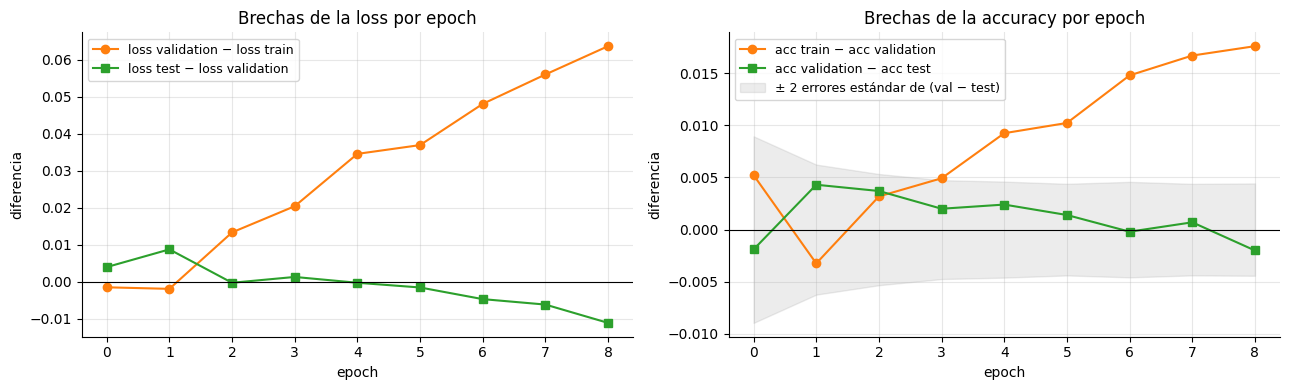

In [41]:
# La brecha de cada epoch, con el signo elegido para que salga positiva
# cuando el primer conjunto «se ve mejor» que el segundo.
brechas = pd.DataFrame({
    "epoch": h["epoch"],
    # Loss: validation − train. Positiva = train es optimista.
    "brecha loss (val − train)": h["loss_validation"] - h["loss_train"],
    # Loss: test − validation. Dos estimaciones honestas del mismo riesgo.
    "diferencia loss (test − val)": h["loss_test"] - h["loss_validation"],
    # Accuracy: train − validation. Positiva = train es optimista.
    "brecha acc (train − val)": h["acc_train"] - h["acc_validation"],
    "diferencia acc (val − test)": h["acc_validation"] - h["acc_test"],
}).set_index("epoch")
display(brechas.round(4))

# ¿Qué tan grande es una diferencia «de ruido» entre validation y test?
# El error estándar de una accuracy p medida en n ejemplos es sqrt(p(1−p)/n),
# como el de una proporción en la unidad 9. La diferencia de DOS accuracies
# independientes suma las dos varianzas; lo calculamos en cada epoch.
n_val = len(DATOS[cfg.escala]["validation"][1])
n_test = len(DATOS[cfg.escala]["test"][1])
pv, pt = h["acc_validation"], h["acc_test"]
ee_dif = np.sqrt(pv * (1 - pv) / n_val + pt * (1 - pt) / n_test).to_numpy()
ee_mejor = ee_dif[(h["epoch"] == base.mejor_epoch).to_numpy()][0]
print(f"n de validation = {n_val:,}; n de test = {n_test:,}")
print(f"en la mejor epoch, error estándar de (acc val − acc test) ≈ "
      f"{ee_mejor:.2%}; 2 errores estándar ≈ {2 * ee_mejor:.2%}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(brechas.index, brechas["brecha loss (val − train)"], "o-",
        color=COLORES["validation"], label="loss validation − loss train")
a1.plot(brechas.index, brechas["diferencia loss (test − val)"], "s-",
        color=COLORES["test"], label="loss test − loss validation")
a1.set_title("Brechas de la loss por epoch")
a2.plot(brechas.index, brechas["brecha acc (train − val)"], "o-",
        color=COLORES["validation"], label="acc train − acc validation")
a2.plot(brechas.index, brechas["diferencia acc (val − test)"], "s-",
        color=COLORES["test"], label="acc validation − acc test")
a2.fill_between(brechas.index, -2 * ee_dif, 2 * ee_dif, color="gray",
                 alpha=0.15, label="± 2 errores estándar de (val − test)")
a2.set_title("Brechas de la accuracy por epoch")
for ax in (a1, a2):
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("epoch")
    ax.set_ylabel("diferencia")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

**La loss puede subir con accuracy casi estable.** Para cada imagen, la loss es $-\log p$ de la clase correcta.
La tabla compara los grupos de errores del mejor checkpoint y del último.
Al final hubo más errores y su probabilidad media para la clase correcta fue menor.
La loss media por error subió. Se calcula promediando $-\log p$ por imagen.

In [42]:
import torch.nn.functional as F


def resumen_confianza(modelo, escala, conjunto="validation"):
    """Qué tan seguro está el modelo cuando acierta y cuando se equivoca."""
    X, y = DATOS[escala][conjunto]
    with torch.no_grad():                         # solo evaluamos, sin gradiente
        logits = torch.cat([modelo(X[i:i + 4096])
                            for i in range(0, len(X), 4096)])
    prob = torch.softmax(logits, dim=1)           # [n, 10], cada fila suma 1
    confianza, pred = prob.max(dim=1)             # p de la clase que eligió
    p_real = prob[torch.arange(len(y), device=y.device), y]  # p de la correcta
    perdida = F.cross_entropy(logits, y, reduction="none")    # −log p_real
    error = pred != y
    n = len(y)
    fila = {
        "accuracy": 1 - error.float().mean().item(),
        "loss (promedio de todos)": perdida.mean().item(),
        "número de errores": int(error.sum()),
        "confianza media en los errores": confianza[error].mean().item(),
        "p media de la clase correcta en los errores": p_real[error].mean().item(),
        "loss media de un error": perdida[error].mean().item(),
        "loss media de un acierto": perdida[~error].mean().item(),
        "aporte de los errores a la loss": perdida[error].sum().item() / n,
        "aporte de los aciertos a la loss": perdida[~error].sum().item() / n,
    }
    return fila, confianza[error].cpu()


filas, conf_errores = {}, {}
for cual, epoch in [("mejor", base.mejor_epoch), ("ultima", ultima_epoch)]:
    modelo = cargar(base, cual)                   # checkpoint en DEVICE, eval()
    nombre = f"{cual} (epoch {epoch:g})"
    filas[nombre], conf_errores[nombre] = resumen_confianza(modelo, cfg.escala)
    del modelo

tabla_conf = pd.DataFrame(filas).round(4).astype(object)
tabla_conf.loc["número de errores"] = tabla_conf.loc["número de errores"].astype(int)
display(tabla_conf)
if base.mejor_epoch == ultima_epoch:
    print("En esta corrida la mejor epoch por validation ES la última: las dos "
          "columnas son el mismo modelo y aquí no hay nada que comparar.")

,mejor (epoch 5),ultima (epoch 8)
accuracy,0.976,0.9739
loss (promedio de todos),0.0854,0.0919
número de errores,240,261
confianza media en los errores,0.7111,0.7438
p media de la clase correcta en los errores,0.1722,0.1664
loss media de un error,2.6008,2.9554
loss media de un acierto,0.0236,0.0151
aporte de los errores a la loss,0.0624,0.0771
aporte de los aciertos a la loss,0.023,0.0147


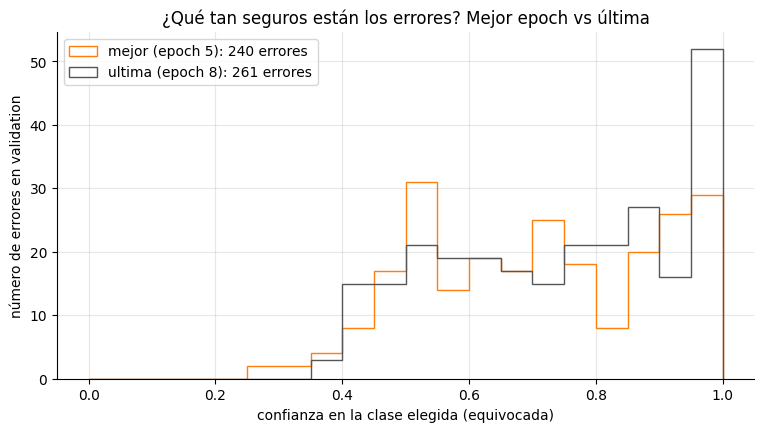

In [43]:
# La confianza (probabilidad de la clase elegida) en cada error de validation.
fig, ax = plt.subplots(figsize=(9, 4.5))
cajas = [i / 20 for i in range(21)]                 # 20 intervalos en [0, 1]
for (nombre, conf), color in zip(conf_errores.items(),
                                 [COLORES["validation"], "#555555"]):
    ax.hist(conf.numpy(), bins=cajas, histtype="step", lw=2, color=color,
            label=f"{nombre}: {len(conf)} errores")
ax.set_xlabel("confianza en la clase elegida (equivocada)")
ax.set_ylabel("número de errores en validation")
ax.set_title("¿Qué tan seguros están los errores? Mejor epoch vs última")
ax.legend()
plt.show()

**Qué viste**

- La mayor mejora ocurrió en la primera epoch. Después train se despegó de validation.
- La loss de validation repuntó al final con accuracy casi estable. En otra corrida puede seguir bajando.
- El histograma final mostró más errores con confianza alta en la clase equivocada.

## 07 · Gradient descent y el tamaño del batch

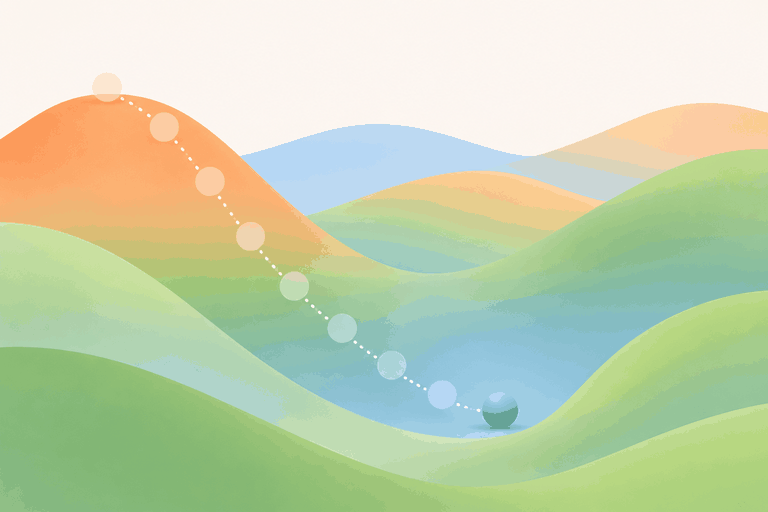
*(Ilustración generada con gpt-image-2.)*

- Gradient descent da un paso $\theta\leftarrow\theta-\eta\,\nabla_\theta L_{\mathcal B}(\theta)$ en dirección contraria al gradiente.
- La loss del batch es $L_{\mathcal B}(\theta)=\frac{1}{|\mathcal B|}\sum_{k\in\mathcal B}\ell_k$. Con full-batch, el promedio abarca todo train.
- **El tamaño del batch determina cuántos pasos caben en una epoch**, $\lceil n/B\rceil$.
- Todas las corridas usan las mismas 4096 imágenes, la misma inicialización y SGD sin momentum con $\eta=0.03$.

**Apuesta.** Tras una epoch, ¿tendrá menor loss de validation batch 1 o full-batch?
¿Y con el mismo número de pasos al inicio?

In [44]:
import math
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

# Los mismos ejemplos de train para todas las corridas: solo cambia el batch.
IDX_S07 = subconjunto(512 if RAPIDO else 4096)   # estratificados y fijos
N_S07 = len(IDX_S07)                             # n: ejemplos de train
COMPLETO_S07 = 4096                      # la etiqueta del full-batch en los IDs
TAMANOS_S07 = [COMPLETO_S07, 1, 8, 32, 128, 1024]


def plan_s07(B):
    """Epochs y frecuencia de evaluación para un tamaño de batch B."""
    B = min(B, N_S07)                    # B = n es gradient descent full-batch
    por_epoch = math.ceil(N_S07 / B)     # actualizaciones de θ en una epoch
    if B == N_S07:
        epochs = 8 if RAPIDO else 80     # un paso por epoch: ~80 pasos
    elif B == 1:
        epochs = 1                       # n pasos ya son muchísimos
    else:
        epochs = 5
    # Evaluar a menudo: cada 8 pasos como máximo, para que TODAS las corridas
    # tengan puntos medidos dentro de los primeros 20 pasos (el presupuesto
    # común en pasos), y siempre al final de cada epoch. Evaluar no cuenta
    # en el reloj: `entrenar` para el cronómetro mientras mide.
    cada = 1 if por_epoch < 8 else min(8, por_epoch // 4)
    return B, por_epoch, epochs, cada


filas = []
for tam in TAMANOS_S07:
    B, por_epoch, epochs, cada = plan_s07(tam)
    filas.append({"ID": f"s07-b{tam}", "batch": B, "pasos por epoch": por_epoch,
                  "epochs": epochs, "pasos totales": por_epoch * epochs,
                  "ejemplos vistos": B * por_epoch * epochs,
                  "evaluar cada (pasos)": cada})
display(pd.DataFrame(filas).set_index("ID"))

,batch,pasos por epoch,epochs,pasos totales,ejemplos vistos,evaluar cada (pasos)
ID,,,,,,
s07-b4096,4096,1,80,80,327680,1
s07-b1,1,4096,1,4096,4096,8
s07-b8,8,512,5,2560,20480,8
s07-b32,32,128,5,640,20480,8
s07-b128,128,32,5,160,20480,8
s07-b1024,1024,4,5,20,20480,1


In [45]:
# Una corrida por tamaño de batch. Todo lo demás es idéntico: los mismos
# pesos iniciales (semilla_init) y el mismo orden de barajar (semilla_orden).
for tam in TAMANOS_S07:
    B, por_epoch, epochs, cada = plan_s07(tam)
    cfg = Config(id=f"s07-b{tam}", seccion=7,
                 capas=[784, 128, 10], activacion="relu",
                 optimizer="sgd", lr=0.03,          # SGD sin momentum
                 batch=B, epochs=epochs, eval_cada_pasos=cada,
                 idx_train=IDX_S07, datos="4k-limpio",
                 semilla_init=SEMILLA, semilla_orden=SEMILLA)
    entrenar(cfg)       # imprime una línea por corrida y la guarda en CORRIDAS

CORRIDAS_S07 = {tam: CORRIDAS[f"s07-b{tam}"] for tam in TAMANOS_S07}

s07-b4096: 101,770 parámetros · 80 pasos · mejor epoch 80 · acc validation 0.880 · 0.1 s
s07-b1: 101,770 parámetros · 4096 pasos · mejor epoch 0.431641 · acc validation 0.851 · 4.4 s
s07-b8: 101,770 parámetros · 2560 pasos · mejor epoch 4.25 · acc validation 0.941 · 3.0 s
s07-b32: 101,770 parámetros · 640 pasos · mejor epoch 4.6875 · acc validation 0.919 · 0.7 s
s07-b128: 101,770 parámetros · 160 pasos · mejor epoch 5 · acc validation 0.896 · 0.2 s
s07-b1024: 101,770 parámetros · 20 pasos · mejor epoch 5 · acc validation 0.768 · 0.0 s


Los cuatro paneles muestran loss de validation por epoch, paso, ejemplo procesado o segundo de entrenamiento.
El eje horizontal es logarítmico. Cada estrella marca la última medición dentro del presupuesto común.
**Compara al mismo presupuesto.** Fuera del tramo gris aún puedes comparar corridas que alcanzaron el mismo valor.
Aquí se compara con validation. Test se reserva para el reporte final.

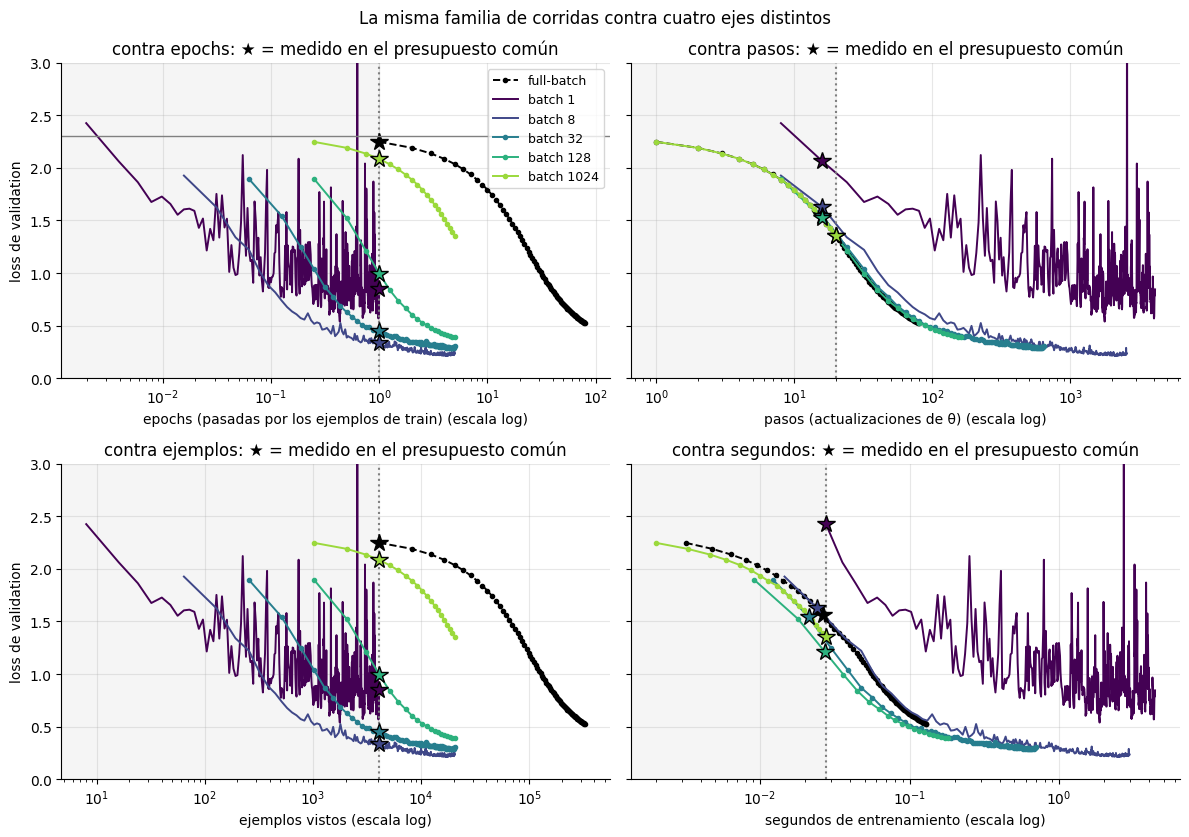

presupuesto común en epochs: 1
presupuesto común en pasos: 20
presupuesto común en ejemplos: 4,096
presupuesto común en segundos: 0.02769


In [46]:
# Un color por tamaño de batch (del más chico, oscuro, al más grande, claro);
# full-batch en negro y punteado. Graficamos solo la loss de validation.
PALETA_S07 = plt.cm.viridis(np.linspace(0.0, 0.85, len(TAMANOS_S07) - 1))
ESTILO_S07 = {COMPLETO_S07: dict(color="black", ls="--", label="full-batch")}
for color, tam in zip(PALETA_S07, TAMANOS_S07[1:]):
    ESTILO_S07[tam] = dict(color=color, ls="-", label=f"batch {tam}")


def eje_x_s07(h, eje):
    """La columna del historial que va en x; «epochs» puede ser fraccionaria."""
    return h["ejemplos"] / N_S07 if eje == "epochs" else h[eje]


def al_presupuesto_s07(h, eje, tope):
    """La última evaluación con x <= tope: lo que la corrida midió a ese
    presupuesto (o un poco antes, si no evaluó justo en tope)."""
    return h.loc[eje_x_s07(h, eje) <= tope * (1 + 1e-9)].iloc[-1]


EJES_S07 = {"epochs": "epochs (pasadas por los ejemplos de train)",
            "pasos": "pasos (actualizaciones de θ)",
            "ejemplos": "ejemplos vistos",
            "segundos": "segundos de entrenamiento"}
PRESUPUESTO_S07 = {}

fig, ejes = plt.subplots(2, 2, figsize=(12, 8.5), sharey=True)
for ax, (eje, etiqueta) in zip(ejes.flat, EJES_S07.items()):
    for tam, corrida in CORRIDAS_S07.items():
        h = corrida.historial
        x, y = eje_x_s07(h, eje), h["loss_validation"]
        ok = (x > 0) & np.isfinite(y)           # el 0 no cabe en escala log
        marca = "o" if ok.sum() <= 100 else None   # muchos puntos: solo línea
        ax.plot(x[ok], y[ok], marker=marca, ms=3, lw=1.4, **ESTILO_S07[tam])
    # El presupuesto común: hasta dónde llegaron TODAS las corridas.
    tope = min(eje_x_s07(c.historial, eje).max() for c in CORRIDAS_S07.values())
    PRESUPUESTO_S07[eje] = tope
    ax.axvline(tope, color="gray", ls=":", lw=1.5)
    for tam, corrida in CORRIDAS_S07.items():   # ★ = el punto comparable
        f = al_presupuesto_s07(corrida.historial, eje, tope)
        fx = f["ejemplos"] / N_S07 if eje == "epochs" else f[eje]
        if fx > 0:
            ax.plot(fx, f["loss_validation"], marker="*", ms=13, ls="none",
                    mec="black", color=ESTILO_S07[tam]["color"])
    ax.axvspan(ax.get_xlim()[0], tope, color="gray", alpha=0.08)
    ax.set_xscale("log")
    ax.set_ylim(0, 3)          # los picos de batch 1 pueden salirse por arriba
    ax.set_xlabel(etiqueta + " (escala log)")
    ax.set_title(f"contra {eje}: ★ = medido en el presupuesto común")
for ax in ejes[:, 0]:
    ax.set_ylabel("loss de validation")
ejes[0, 0].axhline(math.log(10), color="gray", lw=1)   # adivinar uniforme
ejes[0, 0].legend(fontsize=9)
fig.suptitle("La misma familia de corridas contra cuatro ejes distintos")
fig.tight_layout()
plt.show()
for eje, tope in PRESUPUESTO_S07.items():
    print(f"presupuesto común en {eje}: {tope:,.4g}")

- **Iguala el recurso que quieres comparar.** Por epoch o ejemplos vistos, un batch chico da más pasos.
- A igual número de pasos, un batch grande procesa más ejemplos. Por segundo, importa el paralelismo de la GPU.
- Los batches $8$, $32$, $128$ y $1024$ completaron cinco epochs. Entre ellos, la menor loss final fue la de $8$.

In [47]:
# «tras 1 epoch»: todas vieron los mismos n ejemplos, una vez cada uno.
filas = []
for tam, corrida in CORRIDAS_S07.items():
    h, final = corrida.historial, corrida.historial.iloc[-1]
    una_epoch = al_presupuesto_s07(h, "ejemplos", N_S07)
    completa = final["ejemplos"] >= N_S07     # con RAPIDO puede no llegar
    filas.append({
        "batch": "full-batch" if tam == COMPLETO_S07 else tam,
        "epochs": round(final["ejemplos"] / N_S07, 2),
        "pasos": int(final["pasos"]),
        "ejemplos": int(final["ejemplos"]),
        "segundos": round(final["segundos"], 2),
        "loss val tras 1 epoch": (round(una_epoch["loss_validation"], 3)
                                  if completa else "sin completar"),
        "loss val al final": round(final["loss_validation"], 3),
        "acc val al final": round(final["acc_validation"], 3),
    })
TABLA_S07 = pd.DataFrame(filas).set_index("batch")
display(TABLA_S07)
if RAPIDO:
    print("Modo RAPIDO: las corridas se cortaron a unos pocos pasos y con "
          f"n = {N_S07} el batch 1024 ya es full-batch; esta tabla solo prueba "
          "que el código corre, no compara nada.")

,epochs,pasos,ejemplos,segundos,loss val tras 1 epoch,loss val al final,acc val al final
batch,,,,,,,
full-batch,80.0,80,327680,0.13,2.249,0.523,0.880
1,1.0,4096,4096,4.39,0.844,0.844,0.774
8,5.0,2560,20480,2.96,0.335,0.235,0.933
32,5.0,640,20480,0.70,0.450,0.306,0.908
128,5.0,160,20480,0.18,0.994,0.392,0.896
1024,5.0,20,20480,0.03,2.086,1.348,0.768


<details><summary>Respuesta</summary>

**El orden cambió con el eje.** Tras una epoch, batch 1 logró menor loss que full-batch.
A igual número de pasos al inicio, full-batch avanzó más. En otra corrida el learning rate puede cambiar ese orden.

</details>

- Con $\theta$ fijo, el gradiente de un batch aleatorio estima sin sesgo el gradiente completo. La señal es $\|g_{\text{completo}}\|^2$.
- El ruido es $\mathbb E\,\|g_{\mathcal B}-g_{\text{completo}}\|^2$.
- **El ruido baja aproximadamente como $1/B$**. Muestrear sin reemplazo añade el factor $(n-B)/(n-1)$.
- Compara la red inicial con la entrenada. Las barras muestran el error estándar del ruido medio.

In [48]:
# El ruido del gradiente con los pesos CONGELADOS: nada se entrena aquí.
X_S07, Y_S07 = (t[IDX_S07.to(t.device)] for t in DATOS["estandar"]["train"])
PERDIDA_S07 = nn.CrossEntropyLoss()       # promedio sobre el batch


def gradiente_s07(modelo, X, y):
    """∇L_𝓑(θ) de todas las capas, aplanado en un solo vector."""
    modelo.zero_grad(set_to_none=True)
    PERDIDA_S07(modelo(X), y).backward()
    return torch.cat([p.grad.reshape(-1) for p in modelo.parameters()])


def ruido_s07(modelo, tamanos, repeticiones=32, semilla=SEMILLA):
    """Promedio de ‖g_𝓑 − g_completo‖² sobre `repeticiones` batches por B."""
    modelo.eval()
    g_completo = gradiente_s07(modelo, X_S07, Y_S07)   # el de gradient descent
    azar = torch.Generator().manual_seed(semilla)
    filas = []
    for B in tamanos:
        d2 = []
        for _ in range(repeticiones):
            lote = torch.randperm(len(Y_S07), generator=azar)[:B]
            lote = lote.to(X_S07.device)                # sin reemplazo
            g_B = gradiente_s07(modelo, X_S07[lote], Y_S07[lote])
            d2.append(((g_B - g_completo) ** 2).sum().item())
        filas.append({"B": B, "ruido": float(np.mean(d2)),
                      "error estándar": float(np.std(d2) / math.sqrt(len(d2)))})
    modelo.zero_grad(set_to_none=True)
    return pd.DataFrame(filas), float((g_completo ** 2).sum())


TAMANOS_RUIDO_S07 = [B for B in (1, 8, 32, 128, 1024) if B < N_S07]
REPETICIONES_S07 = 8 if RAPIDO else 32

torch.manual_seed(SEMILLA)                 # la misma red recién inicializada
red_inicial = construir_red([784, 128, 10], "relu").to(DEVICE)
red_entrenada = cargar(CORRIDAS["s07-b128"], "ultima")   # tras sus 5 epochs
RUIDO_S07 = {}
for nombre, red in [("recién inicializada", red_inicial),
                    ("entrenada (s07-b128)", red_entrenada)]:
    tabla, senal = ruido_s07(red, TAMANOS_RUIDO_S07, REPETICIONES_S07)
    tabla["ruido / ‖g_completo‖²"] = tabla["ruido"] / senal
    RUIDO_S07[nombre] = tabla
    print(f"{nombre}: ‖g_completo‖² = {senal:.4g}")
    display(tabla.set_index("B").round(4))
del red_inicial, red_entrenada

recién inicializada: ‖g_completo‖² = 2.14


,ruido,error estándar,ruido / ‖g_completo‖²
B,,,
1,131.8574,7.7923,61.6143
8,17.6182,0.6537,8.2326
32,4.4183,0.1425,2.0646
128,1.1536,0.0365,0.5390
1024,0.1090,0.0029,0.0510


entrenada (s07-b128): ‖g_completo‖² = 0.2875


,ruido,error estándar,ruido / ‖g_completo‖²
B,,,
1,128.4633,44.7683,446.8445
8,12.7442,2.0164,44.3291
32,3.6773,0.2663,12.7909
128,0.8865,0.0422,3.0836
1024,0.0869,0.0026,0.3023


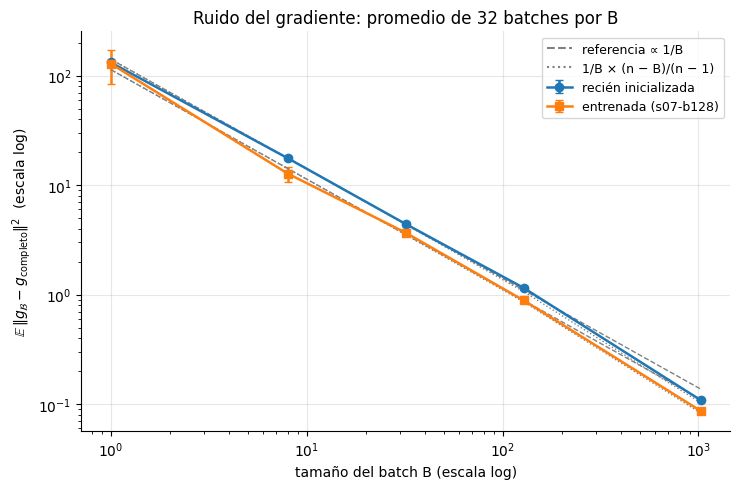

In [49]:
fig, ax = plt.subplots(figsize=(7.5, 5))
B = np.array(TAMANOS_RUIDO_S07, dtype=float)
for (nombre, tabla), marca in zip(RUIDO_S07.items(), ["o", "s"]):
    ax.errorbar(tabla["B"], tabla["ruido"], yerr=tabla["error estándar"],
                marker=marca, capsize=3, lw=1.8, label=nombre)
    # La recta 1/B anclada en la mediana de B·ruido: en log-log, pendiente −1.
    c = float(np.median(tabla["B"] * tabla["ruido"]))
    ax.plot(B, c / B, color="gray", ls="--", lw=1)
    # Con muestreo SIN reemplazo de n ejemplos el ruido cae un poco más:
    # se multiplica por (n − B)/(n − 1), que ya pesa en B = 1024.
    ax.plot(B, c / B * (N_S07 - B) / (N_S07 - 1), color="gray", ls=":", lw=1)
ax.plot([], [], color="gray", ls="--", label="referencia ∝ 1/B")
ax.plot([], [], color="gray", ls=":", label="1/B × (n − B)/(n − 1)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("tamaño del batch B (escala log)")
ax.set_ylabel(r"$\mathbb{E}\,\|g_{\mathcal{B}} - g_{\mathrm{completo}}\|^2$"
              "  (escala log)")
ax.set_title(f"Ruido del gradiente: promedio de {REPETICIONES_S07} batches por B")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

**Qué viste**

- Los batches chicos destacaron por epoch y los grandes por paso. En GPU rindieron mejor los intermedios por segundo.
- El ruido bajó cerca de $1/B$. Para batches grandes, se acercó a la referencia corregida por muestreo sin reemplazo.
- Con batch 8 bajó el ruido absoluto al entrenar. El cociente ruido/señal subió y confirmó que predominaba el ruido.
- En otra máquina puede cambiar el orden por segundo.

## 08 · El learning rate

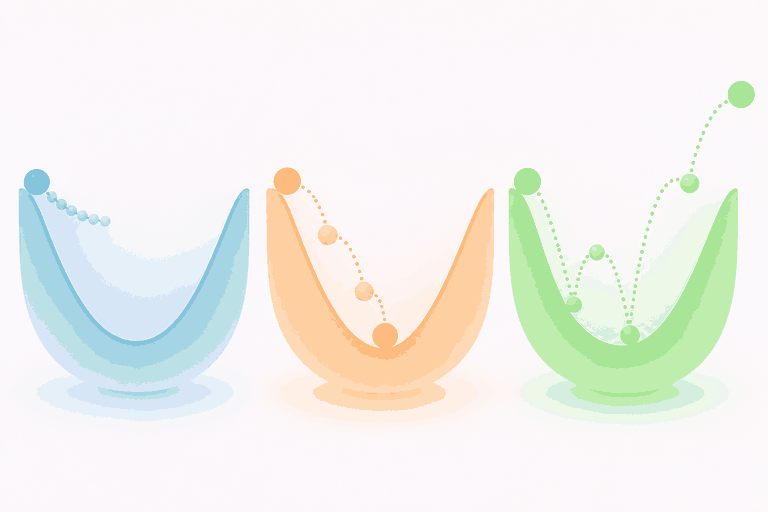
*(Ilustración generada con gpt-image-2.)*

El **learning rate fija el tamaño del paso** de gradient descent.
$\theta \leftarrow \theta-\eta\,\nabla L(\theta)$, con $\eta$ en el papel de $\alpha$ de la unidad 6.
En el dibujo, la primera pelota apenas avanza, la segunda llega al fondo y la tercera rebota y sale.

En $f(x,y)=\tfrac12(x^2+100y^2)$ vamos de $(1,1)$ hacia $(0,0)$.
El gradiente $(x,100y)$ da los multiplicadores $1-\eta$ en $x$ y $1-100\eta$ en $y$.
Ambos deben tener magnitud menor que uno. **La dirección más empinada fija el límite** $0<\eta<0.02$.

- $\eta=0.001$ deja un avance lento. Con $\eta=0.01$, $y$ llega a cero en un paso.
- Con $\eta=0.018$, el zigzag se apaga. Con $\eta=0.025$, crece y la trayectoria diverge.

η = 0.001   factor en x = +0.999  factor en y = +0.900  → converge
η = 0.01    factor en x = +0.990  factor en y = +0.000  → converge
η = 0.018   factor en x = +0.982  factor en y = -0.800  → converge
η = 0.025   factor en x = +0.975  factor en y = -1.500  → DIVERGE
Límite de estabilidad: |1 − 100η| < 1  ⇔  0 < η < 2/100 = 0.02


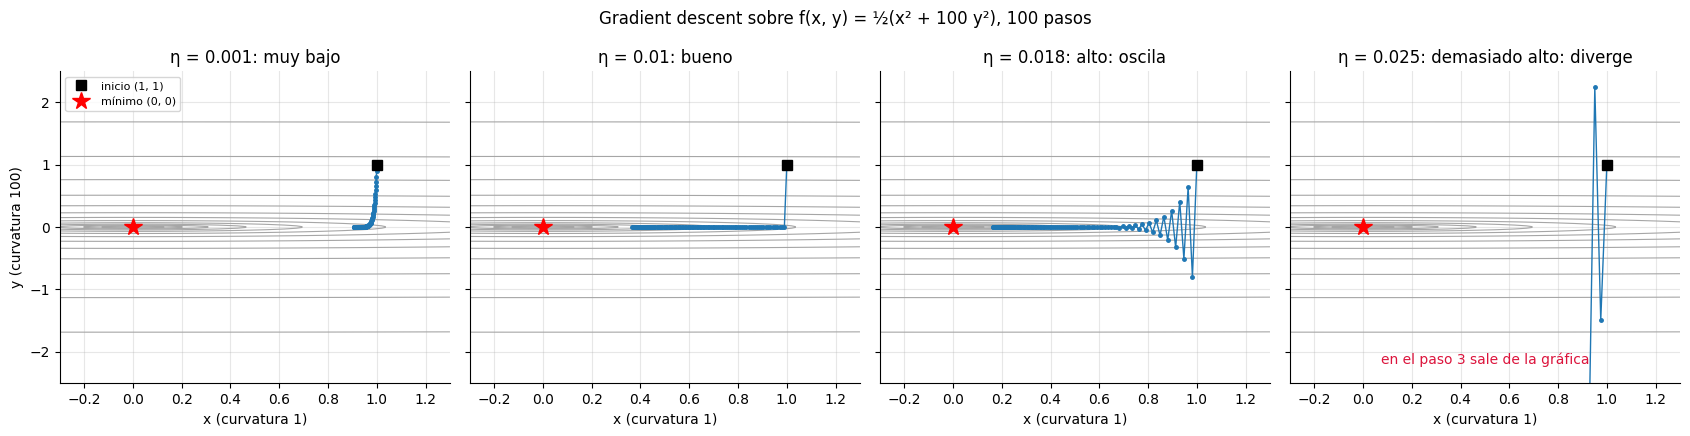

In [50]:
# f(x, y) = ½ (x² + 100 y²): curvatura 1 en la dirección x, 100 en la y.
# Su gradiente es ∇f = (x, 100 y). Un paso de gradient descent con η:
#     x ← x − η·x     = (1 − η)·x
#     y ← y − η·100·y = (1 − 100η)·y
# Cada dirección se multiplica por un factor fijo en cada paso.
def f_cuadratica(x, y):
    return 0.5 * (x ** 2 + 100 * y ** 2)


def descenso_cuadratica(eta, pasos=100, inicio=(1.0, 1.0)):
    """Los puntos (x, y) que visita gradient descent: arreglo [pasos+1, 2]."""
    puntos = [np.array(inicio, dtype=float)]
    for _ in range(pasos):
        x, y = puntos[-1]
        gradiente = np.array([x, 100 * y])            # ∇f en el punto actual
        puntos.append(puntos[-1] - eta * gradiente)   # el paso: θ ← θ − η ∇f
    return np.array(puntos)


ETAS_2D = [0.001, 0.01, 0.018, 0.025]
NOMBRE_2D = {0.001: "muy bajo", 0.01: "bueno",
             0.018: "alto: oscila", 0.025: "demasiado alto: diverge"}
TRAYECTORIAS = {eta: descenso_cuadratica(eta) for eta in ETAS_2D}

# Los factores por paso son cifras analíticas (no dependen de semillas):
# una dirección converge si y solo si |factor| < 1.
for eta in ETAS_2D:
    fx, fy = 1 - eta, 1 - 100 * eta
    veredicto = "converge" if abs(fx) < 1 and abs(fy) < 1 else "DIVERGE"
    print(f"η = {eta:<6}  factor en x = {fx:+.3f}  factor en y = {fy:+.3f}"
          f"  → {veredicto}")
print(f"Límite de estabilidad: |1 − 100η| < 1  ⇔  0 < η < 2/100 = {2 / 100}")

# Curvas de nivel de f y la trayectoria encima, un panel por η, mismos ejes.
xs, ys = np.meshgrid(np.linspace(-0.3, 1.3, 400), np.linspace(-2.5, 2.5, 400))
niveles = np.logspace(-2, 2.5, 14)
fig, ejes = plt.subplots(1, 4, figsize=(17, 4.4), sharex=True, sharey=True)
for ax, eta in zip(ejes, ETAS_2D):
    ax.contour(xs, ys, f_cuadratica(xs, ys), levels=niveles,
               colors="0.65", linewidths=0.8)
    tr = TRAYECTORIAS[eta]
    fuera = np.nonzero(np.abs(tr[:, 1]) > 2.5)[0]
    if len(fuera):                    # se sale del dibujo: hasta ahí la vemos
        tr = tr[:fuera[0] + 1]
        ax.text(0.5, 0.06, f"en el paso {fuera[0]} sale de la gráfica",
                transform=ax.transAxes, ha="center", color="crimson")
    ax.plot(tr[:, 0], tr[:, 1], "-o", color=COLORES["train"], ms=2.5, lw=1)
    ax.plot(1, 1, "ks", ms=7, label="inicio (1, 1)")
    ax.plot(0, 0, "r*", ms=13, label="mínimo (0, 0)")
    ax.set_xlim(-0.3, 1.3)
    ax.set_ylim(-2.5, 2.5)
    ax.set_title(f"η = {eta}: {NOMBRE_2D[eta]}")
    ax.set_xlabel("x (curvatura 1)")
ejes[0].set_ylabel("y (curvatura 100)")
ejes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Gradient descent sobre f(x, y) = ½(x² + 100 y²), 100 pasos")
plt.tight_layout()
plt.show()

En escala logarítmica, multiplicar $f$ por el mismo factor en cada paso da una recta.
**La dirección plana domina después del zigzag.** Por eso $\eta=0.018$ termina por debajo de $\eta=0.01$.
Con $\eta=2/101\approx0.0198$, los dos multiplicadores tienen igual magnitud y signos opuestos.
Ese valor minimiza la mayor magnitud de los dos.

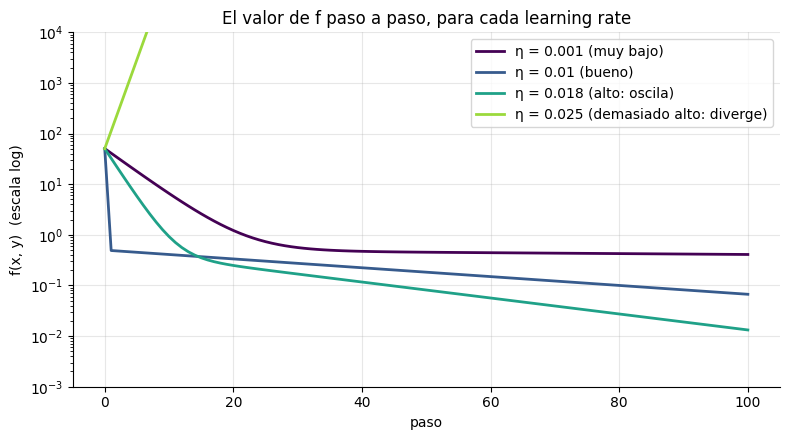

η = 0.001   tras 100 pasos: x = +9.048e-01  y = +2.656e-05  f = 4.093e-01
η = 0.01    tras 100 pasos: x = +3.660e-01  y = +0.000e+00  f = 6.699e-02
η = 0.018   tras 100 pasos: x = +1.626e-01  y = +2.037e-10  f = 1.322e-02
η = 0.025   tras 100 pasos: x = +7.952e-02  y = +4.066e+17  f = 8.265e+36


In [51]:
# El valor de f en cada paso, en escala log: una recta que baja es una
# convergencia geométrica (el mismo factor en cada paso).
COLORES_ETA_2D = dict(zip(ETAS_2D, plt.cm.viridis(np.linspace(0, 0.85, 4))))
fig, ax = plt.subplots(figsize=(8, 4.5))
for eta in ETAS_2D:
    tr = TRAYECTORIAS[eta]
    ax.plot(f_cuadratica(tr[:, 0], tr[:, 1]), color=COLORES_ETA_2D[eta],
            lw=2, label=f"η = {eta} ({NOMBRE_2D[eta]})")
ax.set_yscale("log")
ax.set_ylim(1e-3, 1e4)                    # la que diverge se sale por arriba
ax.set_xlabel("paso")
ax.set_ylabel("f(x, y)  (escala log)")
ax.set_title("El valor de f paso a paso, para cada learning rate")
ax.legend()
plt.tight_layout()
plt.show()

for eta in ETAS_2D:
    x, y = TRAYECTORIAS[eta][-1]
    print(f"η = {eta:<6}  tras 100 pasos: x = {x:+.3e}  y = {y:+.3e}"
          f"  f = {f_cuadratica(x, y):.3e}")

En MNIST, cada corrida parte de los mismos pesos y sesgos y recorre los mismos batches.
**La loss se revisa por bloques.** Con SGD y $\eta=1000$, el primer batch no finito apareció antes de la revisión.
La corrida se detuvo al revisar el bloque. La salida identifica ese primer valor solo como no finito.
La tabla final muestra `NaN`.

**Apuesta.** ¿Qué tasa de `BARRIDO_LR` dará la menor loss final de validation para SGD y para Adam?
¿Cuáles divergirán?

In [52]:
# La misma red 784 → 128 → 10 (ReLU) y los mismos pesos iniciales
# (semilla_init = 0) para todas: lo ÚNICO que cambia es η (y el optimizer).
# Cada corrida da ~300 pasos de batch 128 (menos de una epoch) y evalúa
# train y validation completos cada 25 pasos.
PASOS_LR = 30 if RAPIDO else 300
EVAL_LR = 5 if RAPIDO else 25
# El último valor de SGD (1000) es absurdo a propósito: con ReLU y
# cross-entropy, un η grande suele «matar» la red sin producir NaN; con 1000
# los números se desbordan y vemos cómo entrenar() atrapa el NaN sin tronar.
BARRIDO_LR = {
    "sgd": [1e-4, 1e-3, 1e-2, 3e-2, 1e-1, 0.5, 1.0, 5.0, 1000.0],
    "adam": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
}
CORRIDAS_LR = {"sgd": [], "adam": []}

for opt, etas in BARRIDO_LR.items():
    for eta in etas:
        cfg = Config(id=f"s08-{opt}-{eta:g}", seccion=8,
                     capas=[784, 128, 10], optimizer=opt, lr=eta, batch=128,
                     epochs=10, max_pasos=PASOS_LR, eval_cada_pasos=EVAL_LR)
        # entrenar imprime una línea por corrida. Si la loss deja de ser
        # finita, NO truena: marca divergio, anota el paso y se detiene.
        CORRIDAS_LR[opt].append(entrenar(cfg))

s08-sgd-0.0001: 101,770 parámetros · 300 pasos · mejor epoch 0.767263 · acc validation 0.190 · 0.3 s
s08-sgd-0.001: 101,770 parámetros · 300 pasos · mejor epoch 0.767263 · acc validation 0.620 · 0.3 s
s08-sgd-0.01: 101,770 parámetros · 300 pasos · mejor epoch 0.767263 · acc validation 0.886 · 0.3 s
s08-sgd-0.03: 101,770 parámetros · 300 pasos · mejor epoch 0.767263 · acc validation 0.912 · 0.3 s
s08-sgd-0.1: 101,770 parámetros · 300 pasos · mejor epoch 0.767263 · acc validation 0.936 · 0.3 s
s08-sgd-0.5: 101,770 parámetros · 300 pasos · mejor epoch 0.767263 · acc validation 0.951 · 0.3 s
s08-sgd-1: 101,770 parámetros · 300 pasos · mejor epoch 0.319693 · acc validation 0.467 · 0.4 s
s08-sgd-5: 101,770 parámetros · 300 pasos · mejor epoch 0 · acc validation 0.112 · 0.4 s
s08-sgd-1000: 101,770 parámetros · 25 pasos · mejor epoch 0 · acc validation 0.112 · 0.0 s · DIVERGIÓ en el paso 15
s08-adam-1e-05: 101,770 parámetros · 300 pasos · mejor epoch 0.767263 · acc validation 0.645 · 0.5 s
s08

Los paneles comparten ejes y van de menor a mayor $\eta$. Azul es train y naranja es validation.
La línea punteada marca $\log 10$, la cross-entropy de predecir todos los dígitos con igual probabilidad.
**Busca un descenso sostenido.** Las marcas rojas indican máximos fuera de escala o el primer batch con loss no finita.

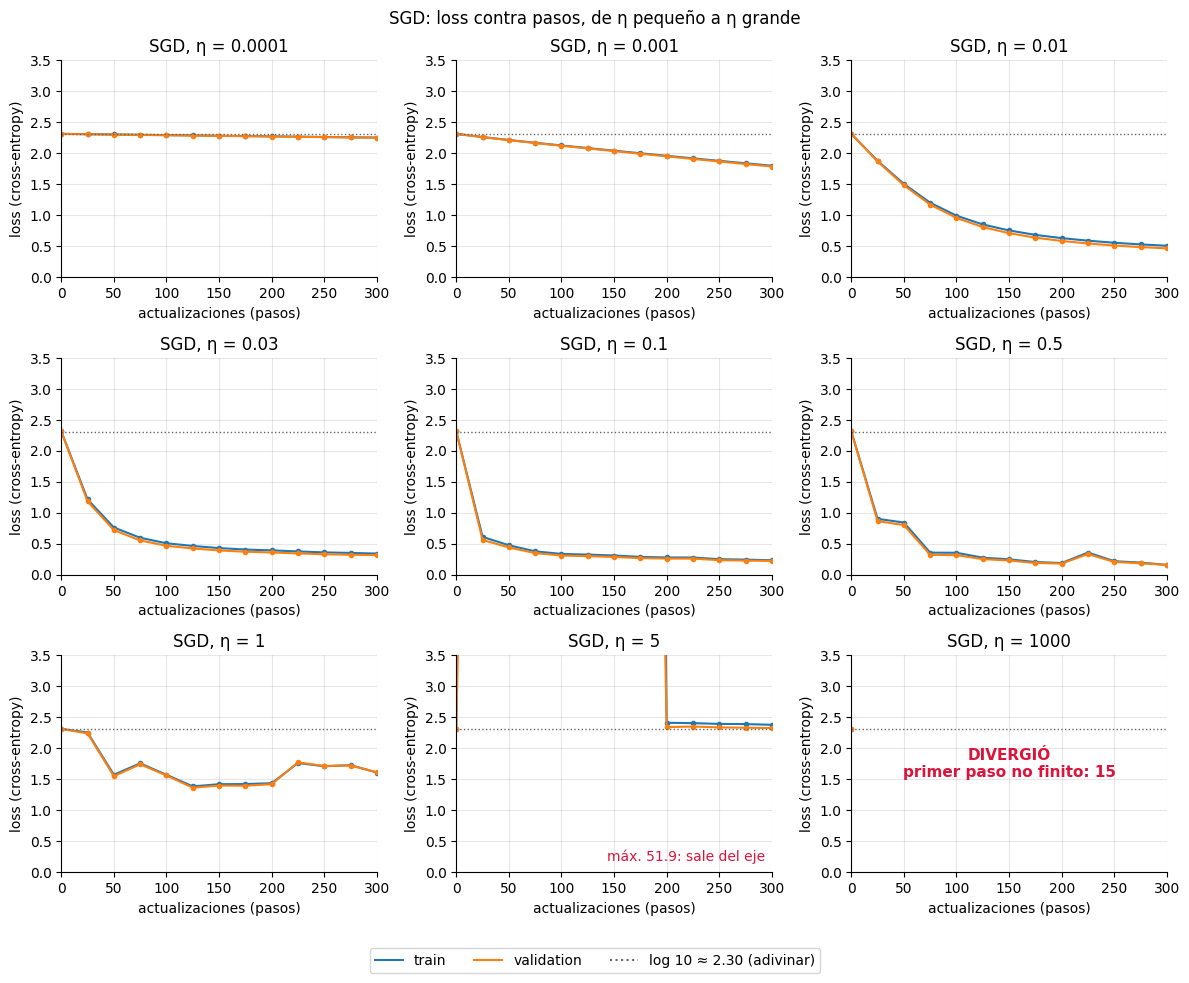

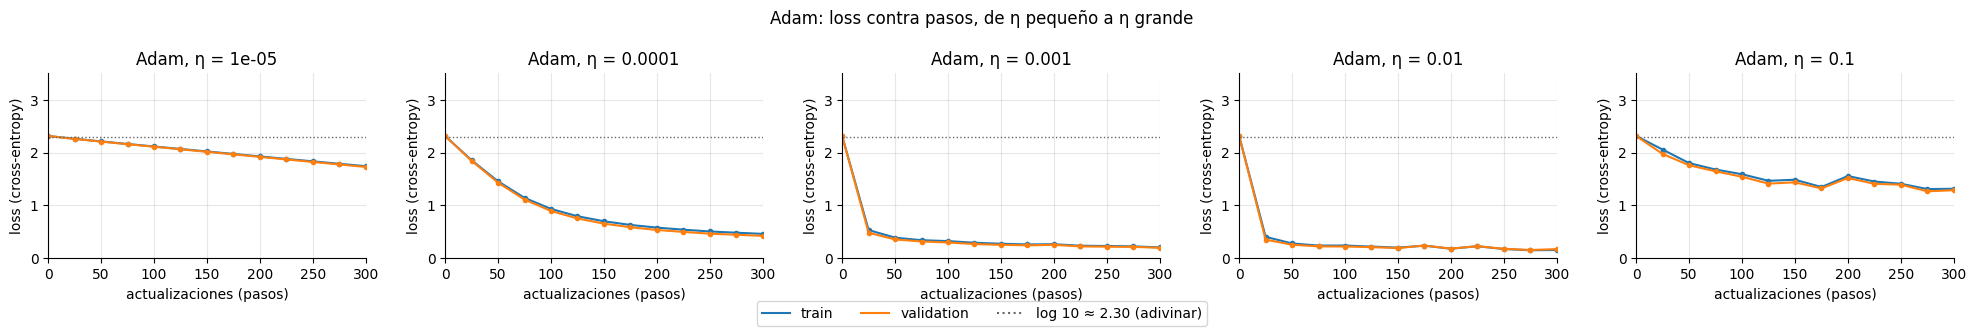

In [53]:
# Una gráfica por η: loss de train y de validation contra pasos.
# Mismos ejes en todas; la línea punteada es log 10 ≈ 2.30, la loss de
# adivinar uniforme entre 10 dígitos.
TECHO_LR = 3.5            # lo que pasa de aquí ya es «peor que adivinar»


NOMBRE_OPT = {"sgd": "SGD", "adam": "Adam"}


def panel_lr(ax, c):
    """Las curvas de una corrida del barrido; si divergió, lo dice encima."""
    nombre = NOMBRE_OPT[c.config.optimizer]
    curvas([c], x="pasos", metrica="loss", conjuntos=("train", "validation"),
           ax=ax, titulo=f"{nombre}, η = {c.config.lr:g}")
    if ax.get_legend():
        ax.get_legend().remove()          # una sola leyenda por figura, abajo
    ax.axhline(math.log(10), color="0.4", ls=":", lw=1)
    ax.set_ylim(0, TECHO_LR)
    ax.set_xlim(0, PASOS_LR)
    v = c.historial[["loss_train", "loss_validation"]].to_numpy(dtype=float)
    v = v[np.isfinite(v)]
    if len(v) and v.max() > TECHO_LR:     # avisa lo que se sale por arriba
        ax.text(0.98, 0.04, f"máx. {v.max():.3g}: sale del eje",
                transform=ax.transAxes, ha="right", va="bottom", color="crimson")
    if c.divergio:
        ax.text(0.5, 0.5, f"DIVERGIÓ\nprimer paso no finito: {c.paso_no_finito}",
                transform=ax.transAxes, ha="center", va="center",
                color="crimson", fontsize=11, fontweight="bold")


for opt, columnas in (("sgd", 3), ("adam", 5)):
    lista = CORRIDAS_LR[opt]
    filas = math.ceil(len(lista) / columnas)
    fig, ejes = plt.subplots(filas, columnas, figsize=(4 * columnas, 3.3 * filas),
                             squeeze=False)
    for ax, c in zip(ejes.flat, lista):
        panel_lr(ax, c)
    for ax in list(ejes.flat)[len(lista):]:
        ax.set_visible(False)
    fig.suptitle(f"{NOMBRE_OPT[opt]}: loss contra pasos, de η pequeño a η grande")
    fig.legend(handles=[plt.Line2D([], [], color=COLORES["train"], label="train"),
                        plt.Line2D([], [], color=COLORES["validation"],
                                   label="validation"),
                        plt.Line2D([], [], color="0.4", ls=":",
                                   label="log 10 ≈ 2.30 (adivinar)")],
               loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.0))
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()

Cada punto da la loss final de validation. El eje de $\eta$ es logarítmico.
$\times$ señala divergencia o loss final no finita. El triángulo señala un valor finito fuera de escala.
**Busca el fondo de cada U.** Varias tasas cercanas pueden quedar casi empatadas.

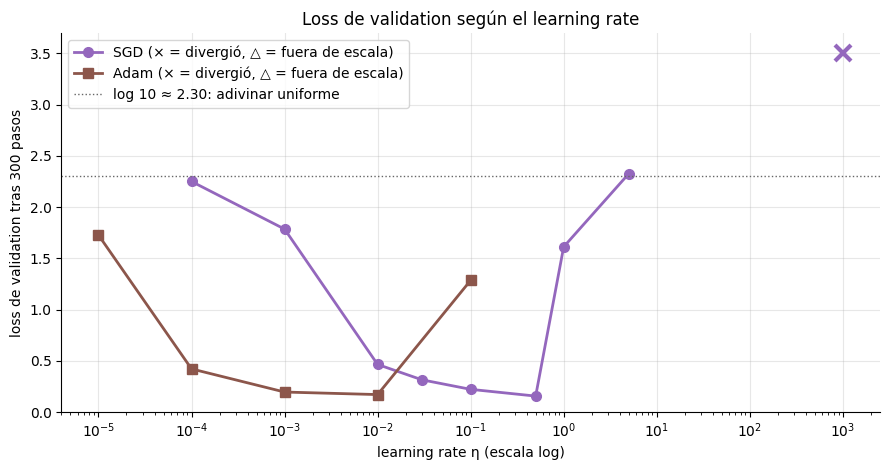

Mejor η para Adam (por loss de validation): 0.01
Mejor η para SGD (por loss de validation): 0.5


,optimizer,η,loss train final,loss validation final,acc validation final,divergió,primer paso no finito,loss final no finita
0,SGD,0.00010,2.2526,2.2500,0.1897,False,NaN,False
1,SGD,0.00100,1.7980,1.7855,0.6200,False,NaN,False
2,SGD,0.01000,0.5068,0.4650,0.8863,False,NaN,False
3,SGD,0.03000,0.3406,0.3151,0.9120,False,NaN,False
4,SGD,0.10000,0.2328,0.2223,0.9365,False,NaN,False
5,SGD,0.50000,0.1576,0.1565,0.9513,False,NaN,False
6,SGD,1.00000,1.6077,1.6121,0.3865,False,NaN,False
7,SGD,5.00000,2.3780,2.3253,0.0973,False,NaN,False
8,SGD,1000.00000,NaN,NaN,NaN,True,15.0,True
9,Adam,0.00001,1.7413,1.7270,0.6447,False,NaN,False


In [54]:
# La «U»: loss de validation al final de los pasos contra η (escala log).
# Una × arriba = la corrida divergió (su loss ya no es un número);
# un triángulo hueco arriba = loss finita, pero más alta que el techo.
ESTILO_OPT = {"sgd": ("#9467bd", "o", "SGD"), "adam": ("#8c564b", "s", "Adam")}
filas_tabla = []
fig, ax = plt.subplots(figsize=(9, 4.8))
for opt, lista in CORRIDAS_LR.items():
    color, marca, nombre = ESTILO_OPT[opt]
    etas_ok, finales = [], []
    for c in lista:
        ultima = c.historial.iloc[-1]
        final = float(ultima["loss_validation"])
        roto = c.divergio or not math.isfinite(final)
        filas_tabla.append({
            "optimizer": nombre, "η": c.config.lr,
            "loss train final": float(ultima["loss_train"]),
            "loss validation final": final,
            "acc validation final": float(ultima["acc_validation"]),
            "divergió": c.divergio, "primer paso no finito": c.paso_no_finito,
            "loss final no finita": not math.isfinite(final)})
        if roto:
            ax.plot(c.config.lr, TECHO_LR, "x", color=color, ms=12, mew=3)
        else:
            etas_ok.append(c.config.lr)
            finales.append(min(final, TECHO_LR))  # fuera de escala → al techo
            if final > TECHO_LR:
                ax.plot(c.config.lr, TECHO_LR, "^", color=color, ms=12,
                        mfc="none", mew=2)
                ax.annotate(f"{final:.3g}", (c.config.lr, TECHO_LR), color=color,
                            textcoords="offset points", xytext=(8, -14))
    ax.plot(etas_ok, finales, "-", marker=marca, color=color, lw=2, ms=7,
            label=f"{nombre} (× = divergió, △ = fuera de escala)")
ax.axhline(math.log(10), color="0.4", ls=":", lw=1,
           label="log 10 ≈ 2.30: adivinar uniforme")
ax.set_xscale("log")
ax.set_ylim(0, TECHO_LR + 0.2)
ax.set_xlabel("learning rate η (escala log)")
ax.set_ylabel(f"loss de validation tras {PASOS_LR} pasos")
ax.set_title("Loss de validation según el learning rate")
ax.legend()
plt.tight_layout()
plt.show()

TABLA_LR = pd.DataFrame(filas_tabla)
# El ganador de cada optimizer se elige con validation (nunca con test).
validas = ~TABLA_LR["divergió"] & ~TABLA_LR["loss final no finita"]
for nombre, grupo in TABLA_LR[validas].groupby("optimizer"):
    mejor = grupo.loc[grupo["loss validation final"].idxmin()]
    print(f"Mejor η para {nombre} (por loss de validation): {mejor['η']:g}")
display(TABLA_LR.round({"loss train final": 4, "loss validation final": 4,
                        "acc validation final": 4}))

<details><summary>Respuesta</summary>

**Aquí la mejor tasa de SGD fue mayor que la de Adam.**
Adam divide el gradiente suavizado por una escala reciente de cada parámetro.
Con la tasa extrema divergió SGD. Las corridas de Adam terminaron con loss finita.

</details>

- **Las tasas intermedias bajaron más la loss.** Con pasos muy chicos, el descenso fue lento.
- Con tasas altas hubo rebotes. Una corrida de SGD se estancó cerca de $\log 10$ con loss finita.
- La tasa extrema de SGD produjo una loss no finita. En otra corrida, Adam también puede divergir con tasas grandes.
- Elige el learning rate con validation y reserva test para el informe final.

## 9 · Optimizers

Sea $\mathbf g_t=\nabla_\theta L_{\mathcal B_t}(\theta_t)$ el gradiente del batch y $\eta$ el learning rate.
**Los optimizers difieren en cómo usan los gradientes.** SGD usa el batch actual y momentum acumula gradientes.

$$
\begin{aligned}
\text{SGD}\quad &\theta_{t+1}=\theta_t-\eta\mathbf g_t,\\
\text{Momentum}\quad &\mathbf m_t=\beta\mathbf m_{t-1}+\mathbf g_t,\qquad
\theta_{t+1}=\theta_t-\eta\mathbf m_t.
\end{aligned}
$$

Adam ajusta cada parámetro con promedios del gradiente y de su cuadrado.

$$
\begin{aligned}
\mathbf m_t&=\beta_1\mathbf m_{t-1}+(1-\beta_1)\mathbf g_t,\\
\mathbf v_t&=\beta_2\mathbf v_{t-1}+(1-\beta_2)\mathbf g_t^2,\\
\widehat{\mathbf m}_t&=\frac{\mathbf m_t}{1-\beta_1^t},\qquad
\widehat{\mathbf v}_t=\frac{\mathbf v_t}{1-\beta_2^t},\\
\theta_{t+1}&=\theta_t-
\eta\frac{\widehat{\mathbf m}_t}{\sqrt{\widehat{\mathbf v}_t}+\varepsilon}.
\end{aligned}
$$

Los denominadores $1-\beta_i^t$ corrigen el arranque en cero. $\varepsilon$ evita dividir entre cero.
AdamW añade weight decay por separado. Las cuatro corridas comparten parámetros iniciales, orden de batches y epochs.

**Apuesta.** ¿Quién terminará con menor loss de validation: SGD, SGD con momentum, Adam o AdamW?
La primera figura muestra la loss de train, validation y test por epoch con fines didácticos (§6). Decide con validation y reserva test para el informe final.

In [55]:
# Cuatro configuraciones sobre la misma red 784→128→10, con los mismos pesos
# iniciales (semilla_init) y el mismo orden de batches (semilla_orden).
# Cambia la regla con la que cada paso mueve θ, y con ella su η: SGD y
# momentum usan 0.03, Adam y AdamW 1e-3. Solo AdamW lleva weight decay.
OPTIMIZERS_S09 = [
    # (ID,             optimizer,  η,    weight_decay)
    ("s09-sgd",        "sgd",      0.03, 0.0),
    ("s09-momentum",   "momentum", 0.03, 0.0),    # β = 0.9, ver la ecuación
    ("s09-adam",       "adam",     1e-3, 0.0),
    ("s09-adamw",      "adamw",    1e-3, 0.01),   # decay desacoplado, solo pesos
]

corridas_s09 = []
for id_, opt, lr, wd in OPTIMIZERS_S09:
    cfg = Config(id=id_, seccion=9, capas=[784, 128, 10], optimizer=opt,
                 lr=lr, weight_decay=wd, epochs=5, batch=128,
                 semilla_init=SEMILLA, semilla_orden=SEMILLA)
    corrida = entrenar(cfg)
    corridas_s09.append(corrida)
    ultima = corrida.historial.iloc[-1]
    print(f"{id_:14s} η = {lr:<6g} weight_decay = {wd:<5g} "
          f"loss validation final = {ultima['loss_validation']:.4f}   "
          f"accuracy validation final = {ultima['acc_validation']:.4f}")

s09-sgd: 101,770 parámetros · 1955 pasos · mejor epoch 5 · acc validation 0.957 · 2.5 s
s09-sgd        η = 0.03   weight_decay = 0     loss validation final = 0.1596   accuracy validation final = 0.9574
s09-momentum: 101,770 parámetros · 1955 pasos · mejor epoch 5 · acc validation 0.977 · 2.3 s
s09-momentum   η = 0.03   weight_decay = 0     loss validation final = 0.0771   accuracy validation final = 0.9765
s09-adam: 101,770 parámetros · 1955 pasos · mejor epoch 5 · acc validation 0.976 · 3.2 s
s09-adam       η = 0.001  weight_decay = 0     loss validation final = 0.0854   accuracy validation final = 0.9760
s09-adamw: 101,770 parámetros · 1955 pasos · mejor epoch 5 · acc validation 0.975 · 3.1 s
s09-adamw      η = 0.001  weight_decay = 0.01  loss validation final = 0.0842   accuracy validation final = 0.9750


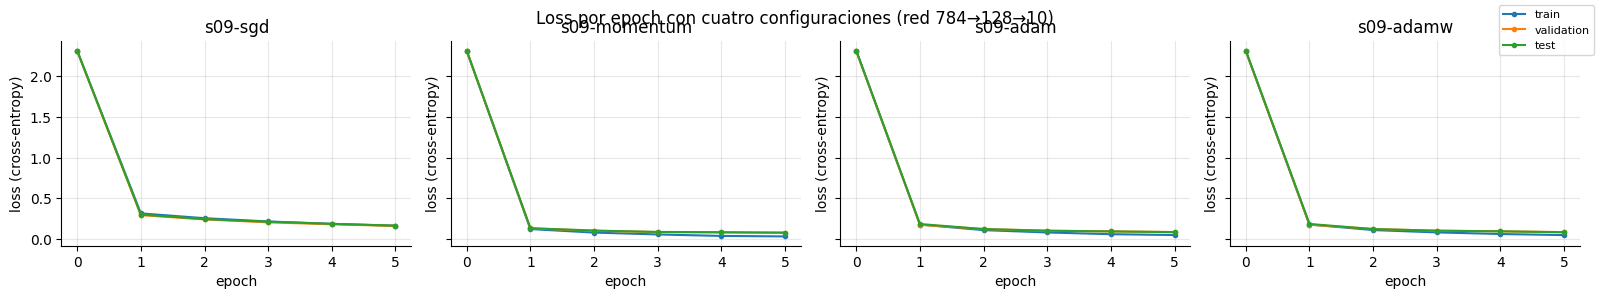

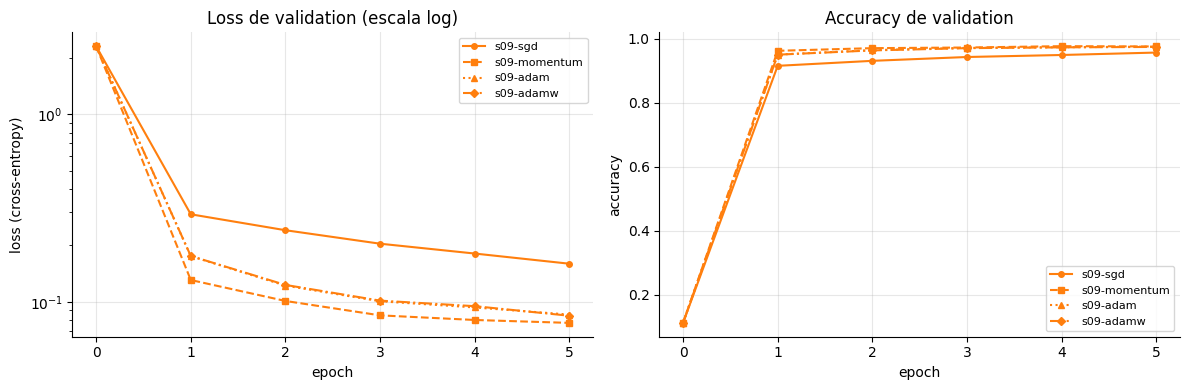

In [56]:
# Small multiples: un panel por optimizer, mismos ejes, para comparar de un
# vistazo. Colores = conjunto (train, validation, test); un panel = una corrida.
fig = rejilla(corridas_s09, x="epoch", metrica="loss", columnas=4)
fig.suptitle("Loss por epoch con cuatro configuraciones (red 784→128→10)")
plt.show()

# Las cuatro curvas de validation en un solo eje: aquí sí se ve quién baja
# más rápido. Color = validation (como en todo el notebook); el estilo de
# línea y el marcador distinguen la corrida, para que dos curvas encimadas
# (Adam y AdamW) se sigan viendo.
TRAZOS_S09 = [("-", "o"), ("--", "s"), (":", "^"), ("-.", "D")]


def por_corrida(corridas, columna, ax, titulo, etiqueta_y, color, log=False):
    """Una línea por corrida con la columna `columna` de su historial."""
    for c, (estilo, marca) in zip(corridas, TRAZOS_S09):
        h = c.historial
        ok = np.isfinite(h[columna].to_numpy(dtype=float))
        ax.plot(h["epoch"][ok], h[columna][ok], estilo, marker=marca, ms=4,
                color=color, label=c.id)
    if log:
        ax.set_yscale("log")
    ax.set_title(titulo)
    ax.set_xlabel("epoch")
    ax.set_ylabel(etiqueta_y)
    ax.legend(fontsize=8)


fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
por_corrida(corridas_s09, "loss_validation", ejes[0],
            "Loss de validation (escala log)", "loss (cross-entropy)",
            COLORES["validation"], log=True)
por_corrida(corridas_s09, "acc_validation", ejes[1], "Accuracy de validation",
            "accuracy", COLORES["validation"])
plt.tight_layout()
plt.show()

In [57]:
# La tabla maestra, solo con las filas de esta comparación. La «mejor epoch»
# se elige con la loss de validation; test solo se reporta.
ids_comparacion = [id_ for id_, *_ in OPTIMIZERS_S09]
tabla_s09 = tabla_maestra([9])
display(tabla_s09[tabla_s09["id"].isin(ids_comparacion)])

,id,seccion,datos,parametros,mejor_epoch,pasos,ejemplos,acc_train,acc_validation,acc_test,loss_train,loss_validation,loss_test,brecha,segundos,divergio
0,s09-sgd,9,50k-limpio,101770,5,1955,250000,0.95476,0.9574,0.9520,0.162707,0.159589,0.164128,-0.00264,2.463020,False
1,s09-momentum,9,50k-limpio,101770,5,1955,250000,0.99096,0.9765,0.9767,0.031271,0.077139,0.077548,0.01446,2.276825,False
2,s09-adam,9,50k-limpio,101770,5,1955,250000,0.98622,0.9760,0.9746,0.048456,0.085416,0.083881,0.01022,3.221743,False
3,s09-adamw,9,50k-limpio,101770,5,1955,250000,0.98646,0.9750,0.9746,0.047672,0.084215,0.082375,0.01146,3.083675,False


<details><summary>Respuesta</summary>

**SGD con momentum terminó con la menor loss de validation.** Mira el último punto del panel izquierdo de la segunda figura.
Esa figura compara solo validation. Adam y AdamW quedaron cerca y SGD sin momentum quedó atrás.
Con otra semilla, el orden de las curvas cercanas puede cambiar.

</details>

### Weight decay en Adam + L2 y AdamW

La penalización $\mu\Omega(\theta)$ suma cuadrados de pesos, $\Omega(\theta)=\sum_l\lVert\mathbf W^{(l)}\rVert_F^2$.
**Con L2, la penalización entra en los promedios de Adam.** Su derivada da `weight_decay` igual a $2\mu$.

$$
\mathbf G_t\leftarrow\mathbf G_t+2\mu\mathbf W_t.
$$

En AdamW, $\mathbf D_t$ es el paso de Adam calculado con el gradiente de los datos.

$$
\mathbf W_{t+1}=(1-2\eta\mu)\mathbf W_t-\mathbf D_t.
$$

Prueba ambas reglas desde $(1,2)$ con gradiente de datos y momentos en cero, $\eta=0.1$ y $2\mu=0.1$.
Con L2, la normalización produce un cambio casi igual en ambos pesos. AdamW les aplica el mismo factor.

In [58]:
# Un paso de Adam escrito a mano, con las mismas ecuaciones del texto.
# desacoplado=False es Adam + L2 (el decay entra al gradiente);
# desacoplado=True es AdamW (el decay encoge los pesos aparte).
ETA_S09, WD_S09 = 0.1, 0.1                   # η y weight_decay (= 2μ)
B1, B2, EPS = 0.9, 0.999, 1e-8               # los valores por defecto de PyTorch


def paso_adam(w, g_datos, m, v, t, desacoplado, eta=ETA_S09, wd=WD_S09):
    """Un paso de Adam (t empieza en 1). Devuelve los nuevos w, m, v."""
    if desacoplado:
        w = w * (1 - eta * wd)               # AdamW: encoge θ aparte...
        g = g_datos                          # ...y el gradiente no lo sabe
    else:
        g = g_datos + wd * w                 # Adam + L2: ∇(μΣθ²) = 2μθ = wd·θ
    m = B1 * m + (1 - B1) * g                # promedio de gradientes
    v = B2 * v + (1 - B2) * g ** 2           # promedio de gradientes al cuadrado
    m_gorro = m / (1 - B1 ** t)              # corrección de sesgo
    v_gorro = v / (1 - B2 ** t)
    w = w - eta * m_gorro / (v_gorro.sqrt() + EPS)
    return w, m, v

In [59]:
w0 = torch.tensor([1.0, 2.0], dtype=torch.float64)   # pesos (1, 2)
cero = torch.zeros_like(w0)                          # gradiente de datos = 0
w_l2, *_ = paso_adam(w0, cero, cero, cero, t=1, desacoplado=False)
w_dw, *_ = paso_adam(w0, cero, cero, cero, t=1, desacoplado=True)


def paso_torch(clase, pasos=1):
    """Lo mismo con el optimizer de PyTorch; devuelve la trayectoria de w."""
    w = w0.clone().requires_grad_(True)
    opt = clase([w], lr=ETA_S09, weight_decay=WD_S09, betas=(B1, B2), eps=EPS)
    trayectoria = [w.detach().clone()]
    for _ in range(pasos):
        w.grad = torch.zeros_like(w)         # gradiente de datos cero, a mano
        opt.step()                           # (zero_grad() lo dejaría en None)
        trayectoria.append(w.detach().clone())
    return torch.stack(trayectoria)


torch_l2 = paso_torch(torch.optim.Adam)[1]
torch_dw = paso_torch(torch.optim.AdamW)[1]
assert torch.allclose(w_l2, torch_l2, rtol=0, atol=1e-12), (w_l2, torch_l2)
assert torch.allclose(w_dw, torch_dw, rtol=0, atol=1e-12), (w_dw, torch_dw)

paso_tabla = pd.DataFrame({
    "peso": ["w₁", "w₂"],
    "antes": w0.numpy(),
    "Adam + L2 (a mano)": w_l2.numpy(), "Adam + L2 (torch)": torch_l2.numpy(),
    "AdamW (a mano)": w_dw.numpy(), "AdamW (torch)": torch_dw.numpy(),
    "cambio Adam + L2": (w_l2 - w0).numpy(),
    "cambio AdamW": (w_dw - w0).numpy(),
}).set_index("peso")
display(paso_tabla.round(6))
print("cambio relativo Adam + L2:", ((w_l2 - w0) / w0).numpy().round(4))
print("cambio relativo AdamW:    ", ((w_dw - w0) / w0).numpy().round(4))
print("La cuenta a mano coincide con torch.optim.Adam y torch.optim.AdamW.")

,antes,Adam + L2 (a mano),Adam + L2 (torch),AdamW (a mano),AdamW (torch),cambio Adam + L2,cambio AdamW
peso,,,,,,,
w₁,1.0,0.9,0.9,0.99,0.99,-0.1,-0.01
w₂,2.0,1.9,1.9,1.98,1.98,-0.1,-0.02


cambio relativo Adam + L2: [-0.1  -0.05]
cambio relativo AdamW:     [-0.01 -0.01]
La cuenta a mano coincide con torch.optim.Adam y torch.optim.AdamW.


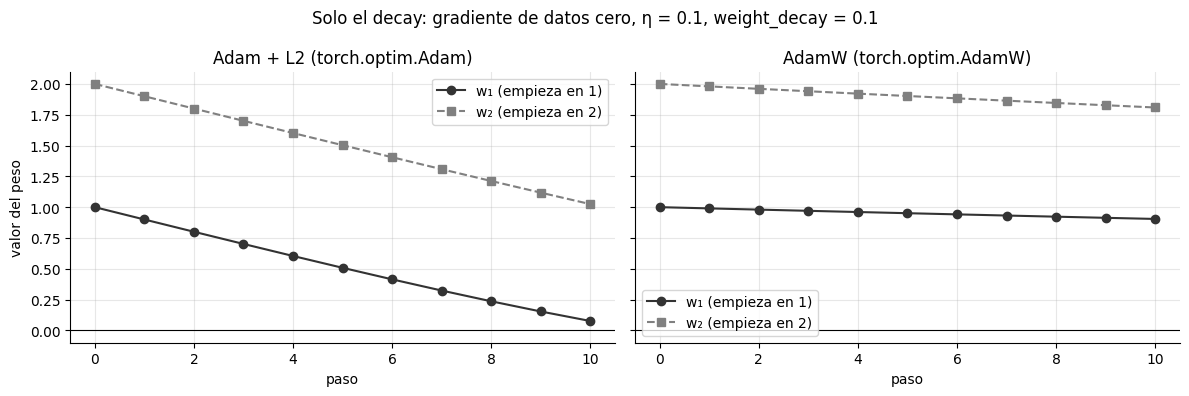

w₂/w₁ tras 5 pasos, Adam + L2: 2.959
w₂/w₁ tras 5 pasos, AdamW:     2.0


In [60]:
# Diez pasos con el gradiente de datos en cero: solo actúa el decay.
# Adam + L2 resta casi lo mismo a los dos pesos en cada paso (Adam normaliza
# el gradiente 2μθ y lo deja de tamaño ≈ 1); AdamW los multiplica por
# (1 − η·wd), así que w₂/w₁ se queda en 2.
PASOS_S09 = 10
tray_l2 = paso_torch(torch.optim.Adam, PASOS_S09).numpy()
tray_dw = paso_torch(torch.optim.AdamW, PASOS_S09).numpy()

fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, tray, nombre in [(ejes[0], tray_l2, "Adam + L2 (torch.optim.Adam)"),
                         (ejes[1], tray_dw, "AdamW (torch.optim.AdamW)")]:
    ax.plot(tray[:, 0], "o-", color="0.2", label="w₁ (empieza en 1)")
    ax.plot(tray[:, 1], "s--", color="0.5", label="w₂ (empieza en 2)")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(nombre)
    ax.set_xlabel("paso")
    ax.legend()
ejes[0].set_ylabel("valor del peso")
fig.suptitle(f"Solo el decay: gradiente de datos cero, η = {ETA_S09}, "
             f"weight_decay = {WD_S09}")
plt.tight_layout()
plt.show()
print("w₂/w₁ tras 5 pasos, Adam + L2:", round(tray_l2[5, 1] / tray_l2[5, 0], 3))
print("w₂/w₁ tras 5 pasos, AdamW:    ", round(tray_dw[5, 1] / tray_dw[5, 0], 3))

- Con Adam + L2, los pesos bajaron casi en paralelo y el cociente $w_2/w_1$ creció.
- **AdamW encogió ambos pesos en la misma proporción.** Con gradiente de datos cero, el cociente quedó en $2$.

En MNIST, las tres corridas comparten pesos iniciales, learning rate, orden de batches y epochs.
Adam + L2 y AdamW reciben el mismo `weight_decay`. Adam sin decay sirve de control.

**Apuesta.** ¿Cuál terminará con menor norma de los pesos: Adam + L2, AdamW o el control?

In [61]:
# Adam + L2 contra AdamW en MNIST, con el mismo η y el mismo weight_decay, y
# Adam sin decay como control. Red más ancha (784→256→10) y 8 epochs para que
# a los pesos les dé tiempo de crecer o de encogerse.
DECAY_S09 = [
    # (ID,             optimizer,  weight_decay)
    ("s09-adam-l2",  "adam_l2", 0.01),   # decay acoplado: entra al gradiente
    ("s09-adamw-wd", "adamw",   0.01),   # decay desacoplado: encoge aparte
    ("s09-adam-sin", "adam",    0.0),    # control: sin decay
]
corridas_decay = []
for id_, opt, wd in DECAY_S09:
    cfg = Config(id=id_, seccion=9, capas=[784, 256, 10], optimizer=opt,
                 lr=1e-3, weight_decay=wd, epochs=8, batch=128,
                 semilla_init=SEMILLA, semilla_orden=SEMILLA)
    corridas_decay.append(entrenar(cfg))

resumen = pd.DataFrame([{
    "id": c.id,
    "norma de los pesos al inicio": c.historial["norma_pesos"].iloc[0],
    "norma de los pesos al final": c.historial["norma_pesos"].iloc[-1],
    "loss validation final": c.historial["loss_validation"].iloc[-1],
    "accuracy validation final": c.historial["acc_validation"].iloc[-1],
    "mejor epoch (validation)": c.mejor_epoch,
} for c in corridas_decay]).set_index("id")
display(resumen.round(4))

s09-adam-l2: 203,530 parámetros · 3128 pasos · mejor epoch 7 · acc validation 0.961 · 8.1 s
s09-adamw-wd: 203,530 parámetros · 3128 pasos · mejor epoch 5 · acc validation 0.978 · 6.6 s
s09-adam-sin: 203,530 parámetros · 3128 pasos · mejor epoch 5 · acc validation 0.978 · 4.9 s


,norma de los pesos al inicio,norma de los pesos al final,loss validation final,accuracy validation final,mejor epoch (validation)
id,,,,,
s09-adam-l2,9.4125,5.6944,0.1502,0.9626,7
s09-adamw-wd,9.4125,22.7088,0.0808,0.9791,5
s09-adam-sin,9.4125,23.1097,0.0906,0.9779,5


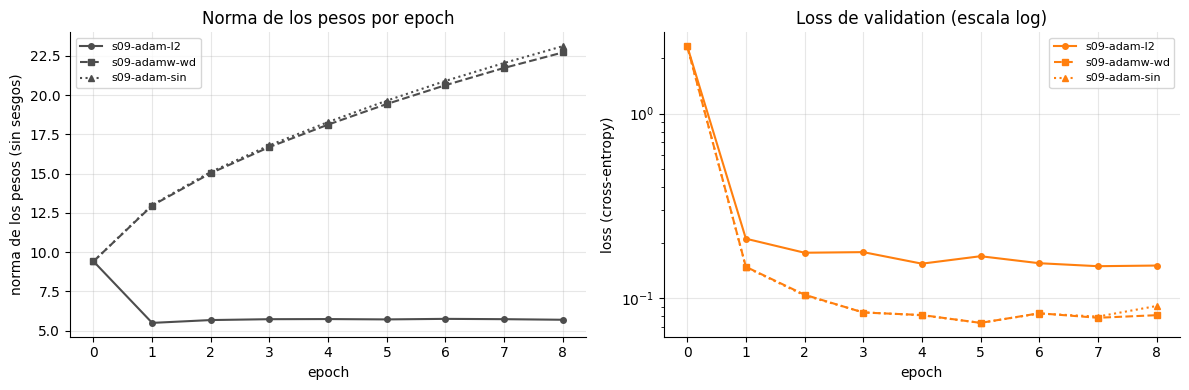

In [62]:
# Izquierda: la norma de los pesos por epoch (lo que el decay sí cambia).
# Derecha: la loss de validation (lo que puede no cambiar casi nada).
# Cada corrida conserva su estilo de línea y su marcador en los dos paneles.
# La norma no es train ni validation: va en gris; la loss, en el color de
# validation y en escala log, para que la epoch 0 no aplaste el resto.
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
por_corrida(corridas_decay, "norma_pesos", ejes[0],
            "Norma de los pesos por epoch", "norma de los pesos (sin sesgos)",
            "0.3")
por_corrida(corridas_decay, "loss_validation", ejes[1],
            "Loss de validation (escala log)", "loss (cross-entropy)",
            COLORES["validation"], log=True)
plt.tight_layout()
plt.show()

### Qué viste

- **El mismo weight decay produjo efectos distintos.** Adam + L2 redujo la norma al inicio y luego la mantuvo baja. Tuvo la mayor loss de validation.
- La norma creció casi igual con AdamW y con el control. El factor $1-2\eta\mu$ estaba cerca de uno.
- Sus curvas de validation quedaron juntas. En otra corrida, el orden de sus losses finales puede cambiar.

## 10 · Early stopping

La red tiene dos capas ocultas de 256 neuronas y entrena 80 epochs con 2000 imágenes.
Cambiamos al azar el 20 % de las etiquetas de train para observar si la red las memoriza.
Validation y test conservan las etiquetas verdaderas.
**Early stopping usa la loss de validation para decidir cuándo parar.** Cada nuevo mínimo guarda un checkpoint.

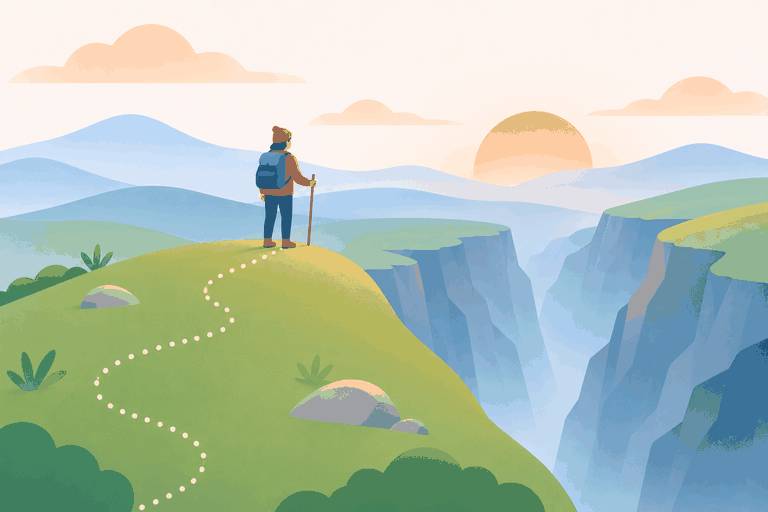
*(Ilustración generada con gpt-image-2.)*

red [784, 256, 256, 10]: 269,322 parámetros
ejemplos de train: 2,000  (20% con la etiqueta cambiada)
parámetros por ejemplo de train: 135


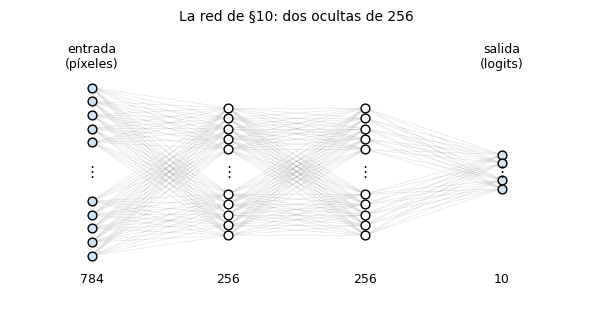

In [63]:
# El caso que sobreajusta: pocos datos, etiquetas con ruido y una red grande.
CFG_S10 = Config(id="s10-control", seccion=10, capas=[784, 256, 256, 10],
                 activacion="relu", optimizer="adam", lr=1e-3, batch=64,
                 epochs=80, idx_train=subconjunto(2000), ruido_etiquetas=0.2,
                 datos="2k-ruido20")

# Cuántos parámetros tiene la red: W^(l) tiene d_l · d_(l-1) entradas y
# b^(l) tiene d_l; la suma es θ.
anchos = CFG_S10.capas
n_parametros = sum(anchos[l] * anchos[l - 1] + anchos[l]
                   for l in range(1, len(anchos)))
print(f"red {anchos}: {n_parametros:,} parámetros")
print(f"ejemplos de train: {len(CFG_S10.idx_train):,}"
      f"  ({CFG_S10.ruido_etiquetas:.0%} con la etiqueta cambiada)")
print(f"parámetros por ejemplo de train: "
      f"{n_parametros / len(CFG_S10.idx_train):,.0f}")
dibujar_red(anchos, titulo="La red de §10: dos ocultas de 256")
plt.show()

**Apuesta.** ¿La loss de train bajará siempre o tendrá repuntes? ¿La de validation seguirá bajando o volverá a subir?
Al final, ¿la red repetirá pocas, muchas o todas las etiquetas falsas de train?

<details><summary>Respuesta</summary>

Al principio mejoró la clasificación en validation. Después, su loss subió mientras la de train seguía bajando, con repuntes.
**La red terminó repitiendo todas las etiquetas falsas de train.**
En otra corrida podría memorizar solo parte de ellas.

</details>

In [64]:
# 80 epochs SIN paciencia: queremos ver todo lo que pasa después del mejor
# momento. entrenar guarda dos checkpoints: el de la mejor epoch por loss de
# validation y el de la última.
corrida_s10 = entrenar(CFG_S10)
h10 = corrida_s10.historial
print(f"epochs corridas: {int(h10['epoch'].max())}")
print(f"mejor epoch por loss de validation: {corrida_s10.mejor_epoch:g}")

s10-control: 269,322 parámetros · 2560 pasos · mejor epoch 9 · acc validation 0.887 · 4.7 s
epochs corridas: 80
mejor epoch por loss de validation: 9


La simulación cuenta evaluaciones consecutivas sin bajar la loss de validation. Un empate cuenta como falta de mejora.
**Al agotar la paciencia, se recupera el mejor checkpoint hasta la parada.**
Aquí ese checkpoint también fue el mejor de las 80 epochs del control.
En otra corrida puede aparecer un mínimo posterior a la parada.

In [65]:
def epoch_de_parada(historial, paciencia=6):
    """Dónde habría parado early stopping, simulado sobre un historial.

    Recorre las evaluaciones en orden y cuenta cuántas seguidas van sin
    mejorar el mínimo de la loss de validation (un empate no mejora). La
    primera vez que el contador llega a `paciencia`, ésa es la epoch de
    parada. Devuelve (epoch de parada, mejor epoch hasta ese momento); si el
    contador nunca llega, (None, mejor epoch). Solo lee validation.
    """
    mejor, mejor_epoch, sin_mejora = float("inf"), None, 0
    for _, fila in historial.iterrows():
        if fila["loss_validation"] < mejor:
            mejor, mejor_epoch, sin_mejora = fila["loss_validation"], fila["epoch"], 0
        else:
            sin_mejora += 1
            if sin_mejora == paciencia:
                return fila["epoch"], mejor_epoch
    return None, mejor_epoch


PACIENCIA = 6
parada_simulada, mejor_al_parar = epoch_de_parada(h10, PACIENCIA)
ultima_epoch = h10["epoch"].max()
print(f"mínimo de la loss de validation en las {ultima_epoch:g} epochs: "
      f"epoch {corrida_s10.mejor_epoch:g}")
if parada_simulada is None:
    print(f"paciencia {PACIENCIA}: nunca se agotó; la corrida no habría parado")
else:
    print(f"paciencia {PACIENCIA}: habría parado en la epoch {parada_simulada:g} "
          f"y restaurado la epoch {mejor_al_parar:g}")
    print(f"epochs ahorradas: {ultima_epoch - parada_simulada:g} de {ultima_epoch:g}")
    if mejor_al_parar != corrida_s10.mejor_epoch:
        print("ojo: después de la parada validation volvió a mejorar; early "
              "stopping se habría quedado con un mínimo anterior")

mínimo de la loss de validation en las 80 epochs: epoch 9
paciencia 6: habría parado en la epoch 15 y restaurado la epoch 9
epochs ahorradas: 65 de 80


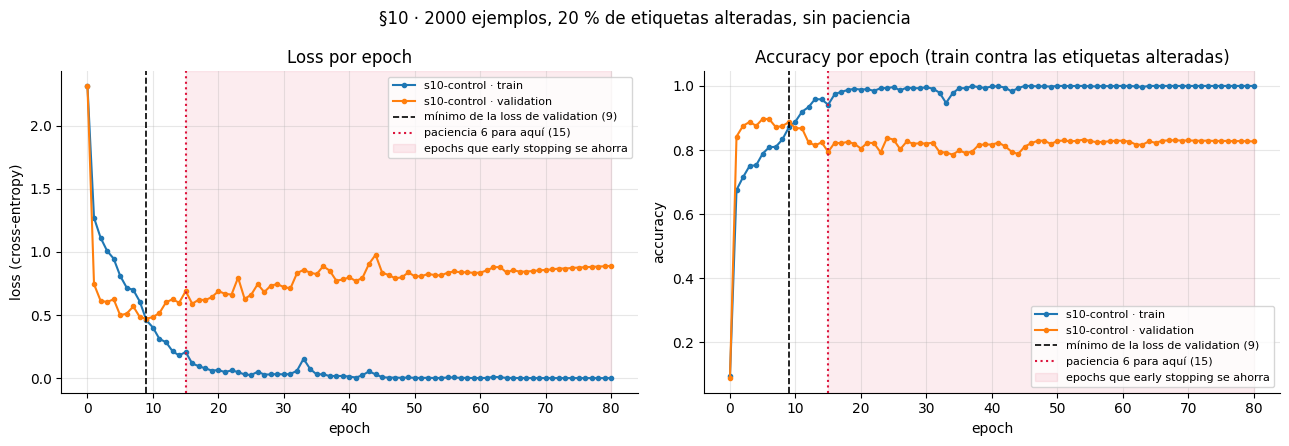

In [66]:
def marcar_parada(ax, mejor, parada, ultima):
    """Línea en la mejor epoch, línea en la parada y sombra de lo ahorrado."""
    ax.axvline(mejor, color="black", ls="--", lw=1.2,
               label=f"mínimo de la loss de validation ({mejor:g})")
    if parada is not None:
        ax.axvline(parada, color="crimson", ls=":", lw=1.5,
                   label=f"paciencia {PACIENCIA} para aquí ({parada:g})")
        ax.axvspan(parada, ultima, color="crimson", alpha=0.08,
                   label="epochs que early stopping se ahorra")


fig, (ax_l, ax_a) = plt.subplots(1, 2, figsize=(13, 4.5))
# Solo train y validation: las curvas sirven para elegir, y test no elige.
curvas([corrida_s10], x="epoch", metrica="loss",
       conjuntos=("train", "validation"), ax=ax_l, titulo="Loss por epoch")
curvas([corrida_s10], x="epoch", metrica="accuracy",
       conjuntos=("train", "validation"), ax=ax_a,
       titulo="Accuracy por epoch (train contra las etiquetas alteradas)")
for ax in (ax_l, ax_a):
    marcar_parada(ax, corrida_s10.mejor_epoch, parada_simulada, ultima_epoch)
    ax.legend(fontsize=8)
fig.suptitle("§10 · 2000 ejemplos, 20 % de etiquetas alteradas, sin paciencia")
plt.tight_layout()
plt.show()

La línea negra marca el mínimo de validation y la roja, la parada simulada. La sombra indica las epochs ahorradas.
**La barra de etiquetas falsas mide memorización.** Compara cuánto crece del mejor checkpoint al último.
Entre las imágenes con etiquetas alteradas, fíjate también en cuántas reciben su etiqueta verdadera.

etiquetas alteradas: 400 de 2000


,limpias: acierta la verdadera,alteradas: repite la etiqueta falsa,alteradas: acierta la verdadera
checkpoint,,,
mejor,0.991,0.39,0.53
ultima,1.000,1.00,0.00


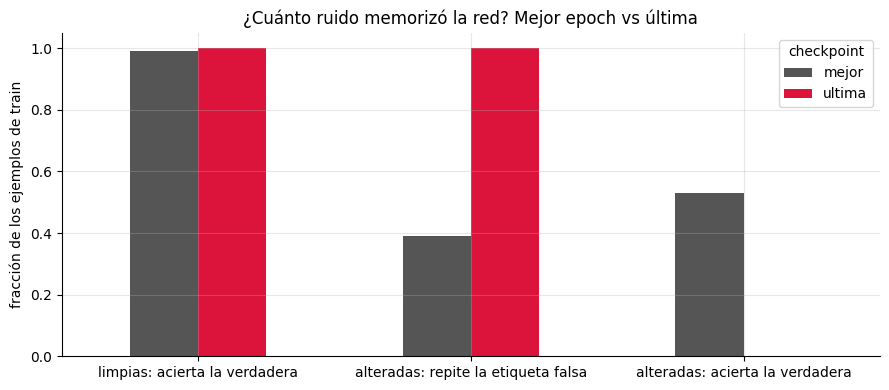

In [67]:
# Los 2000 ejemplos tal como los vio la red: datos_de_entrenamiento (de la
# caja) aplica el subconjunto y altera las etiquetas con la misma semilla que
# usó entrenar. Las etiquetas verdaderas siguen en DATOS.
X10, y10_ruido = datos_de_entrenamiento(CFG_S10)
X_tr, y_tr = DATOS[CFG_S10.escala]["train"]
idx10 = CFG_S10.idx_train.to(DEVICE)
idx10 = idx10[idx10 < len(X_tr)]            # igual que la caja (RAPIDO)
y10_limpia = y_tr[idx10]
alterada = y10_ruido != y10_limpia          # máscara: dónde se cambió
print(f"etiquetas alteradas: {int(alterada.sum())} de {len(y10_ruido)}")


@torch.no_grad()
def predecir(modelo, X):
    """La clase con el logit más grande (cargar ya deja la red en eval())."""
    return modelo(X).argmax(dim=1)


filas = []
for cual in ("mejor", "ultima"):
    pred = predecir(cargar(corrida_s10, cual), X10)
    filas.append({
        "checkpoint": cual,
        "limpias: acierta la verdadera":
            (pred[~alterada] == y10_limpia[~alterada]).float().mean().item(),
        "alteradas: repite la etiqueta falsa":
            (pred[alterada] == y10_ruido[alterada]).float().mean().item(),
        "alteradas: acierta la verdadera":
            (pred[alterada] == y10_limpia[alterada]).float().mean().item(),
    })
memoria = pd.DataFrame(filas).set_index("checkpoint")
display(memoria.round(3))

ax = memoria.T.plot.bar(figsize=(9, 4), rot=0, color=["#555555", "crimson"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("fracción de los ejemplos de train")
ax.set_title("¿Cuánto ruido memorizó la red? Mejor epoch vs última")
ax.legend(title="checkpoint")
plt.tight_layout()
plt.show()

**El mejor checkpoint se elige por loss de validation.** Compara sus métricas con las del último.
Train usa las etiquetas vistas al entrenar. Validation y test usan las verdaderas.
Aquí test se muestra con fines didácticos (§6). En un proyecto se usa una vez al final para reportar.

In [68]:
# Restauramos los dos checkpoints y medimos cada uno desde cero con medir y
# evaluar de la caja. Train se mide sobre lo que la red vio: los 2000
# ejemplos con sus etiquetas alteradas. Validation y test, completos y limpios.
filas = []
for cual, epoch in (("mejor", corrida_s10.mejor_epoch), ("ultima", ultima_epoch)):
    modelo = cargar(corrida_s10, cual)
    l_tr, a_tr = medir(modelo, X10, y10_ruido)          # medir es de la caja
    l_va, a_va = evaluar(modelo, CFG_S10.escala, "validation")
    l_te, a_te = evaluar(modelo, CFG_S10.escala, "test")   # la única vez
    filas.append({"checkpoint": cual, "epoch": epoch,
                  "loss train": l_tr, "acc train": a_tr,
                  "loss validation": l_va, "acc validation": a_va,
                  "loss test": l_te, "acc test": a_te})
tabla_s10 = pd.DataFrame(filas).set_index("checkpoint")
display(tabla_s10.round(3))

,epoch,loss train,acc train,loss validation,acc validation,loss test,acc test
checkpoint,,,,,,,
mejor,9,0.458,0.871,0.471,0.887,0.482,0.883
ultima,80,0.000,1.000,0.889,0.827,0.966,0.816


Repetimos la corrida con paciencia de seis evaluaciones y las mismas semillas.
**La parada real coincidió con la simulada.** Ambas recuperaron el mejor checkpoint del control.
Pequeñas diferencias numéricas en GPU pueden cambiar la parada.

s10-paciencia: 269,322 parámetros · 480 pasos · mejor epoch 9 · acc validation 0.887 · 0.8 s
paciencia 6: se detuvo sola en la epoch 15
la simulación sobre s10-control decía: epoch 15
checkpoint que entrega: epoch 9


,epoch,loss validation,acc validation,loss test,acc test
checkpoint,,,,,
mejor,9,0.471,0.887,0.482,0.883
ultima,80,0.889,0.827,0.966,0.816
con paciencia,9,0.471,0.887,0.482,0.883


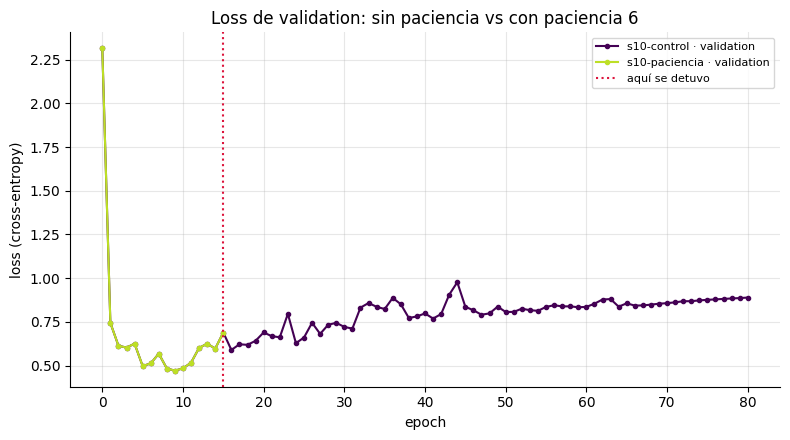

,id,seccion,datos,parametros,mejor_epoch,pasos,ejemplos,acc_train,acc_validation,acc_test,loss_train,loss_validation,loss_test,brecha,segundos,divergio
0,s10-control,10,2k-ruido20,269322,9,288,18000,0.871,0.8871,0.8833,0.458271,0.471029,0.481787,-0.0161,4.662207,False
1,s10-paciencia,10,2k-ruido20,269322,9,288,18000,0.871,0.8871,0.8833,0.458271,0.471029,0.481787,-0.0161,0.840312,False


In [69]:
# La misma Config, ahora con paciencia real: entrenar para sola.
CFG_S10_P = Config(id="s10-paciencia", seccion=10, capas=[784, 256, 256, 10],
                   activacion="relu", optimizer="adam", lr=1e-3, batch=64,
                   epochs=80, idx_train=subconjunto(2000), ruido_etiquetas=0.2,
                   paciencia=PACIENCIA, datos="2k-ruido20")
corrida_s10_p = entrenar(CFG_S10_P)
hp = corrida_s10_p.historial
fin_p = hp["epoch"].max()
paro = bool(hp["parada_temprana"].iloc[-1])   # ¿se agotó la paciencia?
if paro:
    print(f"paciencia {PACIENCIA}: se detuvo sola en la epoch {fin_p:g}")
else:
    print(f"paciencia {PACIENCIA}: no se agotó; corrió todo el presupuesto "
          f"({fin_p:g} epochs)")
sim = "no para" if parada_simulada is None else f"epoch {parada_simulada:g}"
print(f"la simulación sobre s10-control decía: {sim}")
print(f"checkpoint que entrega: epoch {corrida_s10_p.mejor_epoch:g}")

# El modelo que de verdad entrega early stopping, junto a los del control.
modelo_p = cargar(corrida_s10_p, "mejor")
l_va, a_va = evaluar(modelo_p, CFG_S10.escala, "validation")
l_te, a_te = evaluar(modelo_p, CFG_S10.escala, "test")
fila_p = pd.DataFrame([{"epoch": corrida_s10_p.mejor_epoch,
                        "loss validation": l_va, "acc validation": a_va,
                        "loss test": l_te, "acc test": a_te}],
                      index=pd.Index(["con paciencia"], name="checkpoint"))
display(pd.concat([tabla_s10.drop(columns=["loss train", "acc train"]),
                   fila_p]).round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
curvas([corrida_s10, corrida_s10_p], x="epoch", metrica="loss",
       conjuntos=("validation",), ax=ax,
       titulo=f"Loss de validation: sin paciencia vs con paciencia {PACIENCIA}")
if paro:
    ax.axvline(fin_p, color="crimson", ls=":", lw=1.5, label="aquí se detuvo")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
display(tabla_maestra([10]))

- **El overfitting separó las curvas.** La loss de train siguió bajando y la de validation subió tras su mínimo.
- El último checkpoint repitió más etiquetas falsas y acertó menos en validation.
- Early stopping recuperó el checkpoint previo a ese deterioro. En §15 compararemos cuánto ruido memoriza la red con dropout.

## 11 · El tamaño de la red

**Ancho y profundidad cambian la forma y el tamaño de la red.** Usamos capas ocultas del mismo ancho.
El conteo incluye pesos y sesgos, $\sum_{l=1}^{L}(d_{l-1}+1)d_l$. En $[784,2,10]$ suma $1600$ parámetros.
Cada red usa ReLU y entrena cinco epochs con los mismos 20 000 ejemplos de train.
Todas usan Adam con $\eta=10^{-3}$ y batch de 128.
La inicialización He usa varianza $2/d_{l-1}$ para conservar la escala de la señal con ReLU.

In [70]:
# (time, numpy, pandas, torch, nn y plt ya vienen del arranque, §1)
T0_S11 = time.perf_counter()          # reloj de toda la sección

ANCHOS = [2, 16, 64, 256, 1024]       # d_l: neuronas por capa oculta
PROFUNDIDADES = [1, 2, 4, 8]          # número de capas ocultas
if RAPIDO:                            # prueba en CPU: rejilla chica de 3 × 3
    ANCHOS, PROFUNDIDADES = [2, 16, 64], [1, 2, 4]


def capas_s11(ancho, prof):
    """[784, ancho, ..., ancho, 10] con `prof` capas ocultas iguales."""
    return [784] + [ancho] * prof + [10]


def contar_parametros(capas):
    """Cada capa l tiene una matriz W de d_l × d_{l-1} y d_l sesgos."""
    return sum((d_ant + 1) * d for d_ant, d in zip(capas[:-1], capas[1:]))


IDX_20K = subconjunto(20000)          # los mismos 20k ejemplos para las 20 redes


def config_s11(ancho, prof):
    """Una celda de la rejilla: todo igual salvo la forma de la red."""
    return Config(
        id=f"s11-a{ancho}-p{prof}", seccion=11,
        capas=capas_s11(ancho, prof), activacion="relu", init="he",
        optimizer="adam", lr=1e-3, batch=128, epochs=5,
        escala="estandar", idx_train=IDX_20K, datos="20k-limpio",
    )


# Conteo exacto, antes de entrenar nada: filas = profundidad, columnas = ancho
conteo = pd.DataFrame(
    [[contar_parametros(capas_s11(a, p)) for a in ANCHOS] for p in PROFUNDIDADES],
    index=pd.Index(PROFUNDIDADES, name="capas ocultas"),
    columns=pd.Index(ANCHOS, name="ancho"),
)
# comprobación: el conteo a mano coincide con el de PyTorch
red = construir_red(capas_s11(64, 2), init="he")
assert contar_parametros(capas_s11(64, 2)) == sum(t.numel() for t in red.parameters())
del red
print("Parámetros de cada red de la rejilla:")
display(conteo)

Parámetros de cada red de la rejilla:


ancho,2,16,64,256,1024
capas ocultas,,,,,
1,1600,12730,50890,203530,814090
2,1606,13002,55050,269322,1863690
4,1618,13546,63370,400906,3962890
8,1642,14634,80010,664074,8161290


**Apuesta.** ¿Cuál quedará última en validation: la más estrecha y profunda, la más ancha y profunda u otra?
¿Aumentar ancho o profundidad siempre ayuda? ¿La red más grande tendrá la mayor brecha?

In [71]:
# 20 redes, de la más angosta y somera a la más ancha y profunda.
# entrenar() imprime una línea por red; las gráficas leen la ÚLTIMA epoch.
REJILLA = {}                          # (ancho, prof) -> Corrida
for prof in PROFUNDIDADES:
    for ancho in ANCHOS:
        REJILLA[(ancho, prof)] = entrenar(config_s11(ancho, prof))

s11-a2-p1: 1,600 parámetros · 785 pasos · mejor epoch 5 · acc validation 0.223 · 1.2 s
s11-a16-p1: 12,730 parámetros · 785 pasos · mejor epoch 5 · acc validation 0.927 · 1.2 s
s11-a64-p1: 50,890 parámetros · 785 pasos · mejor epoch 5 · acc validation 0.955 · 1.2 s
s11-a256-p1: 203,530 parámetros · 785 pasos · mejor epoch 3 · acc validation 0.964 · 1.4 s
s11-a1024-p1: 814,090 parámetros · 785 pasos · mejor epoch 5 · acc validation 0.970 · 1.4 s
s11-a2-p2: 1,606 parámetros · 785 pasos · mejor epoch 5 · acc validation 0.316 · 1.4 s
s11-a16-p2: 13,002 parámetros · 785 pasos · mejor epoch 5 · acc validation 0.921 · 1.4 s
s11-a64-p2: 55,050 parámetros · 785 pasos · mejor epoch 5 · acc validation 0.960 · 1.3 s
s11-a256-p2: 269,322 parámetros · 785 pasos · mejor epoch 3 · acc validation 0.965 · 1.4 s
s11-a1024-p2: 1,863,690 parámetros · 785 pasos · mejor epoch 5 · acc validation 0.968 · 1.4 s
s11-a2-p4: 1,618 parámetros · 785 pasos · mejor epoch 5 · acc validation 0.204 · 1.8 s
s11-a16-p4: 13,

Lee el ancho por columna y la profundidad por fila. A la izquierda, un color más claro indica mayor accuracy.
**La brecha es accuracy de train menos accuracy de validation.** A la derecha, rojo indica brecha positiva y azul, negativa.
Una brecha positiva grande puede señalar overfitting.

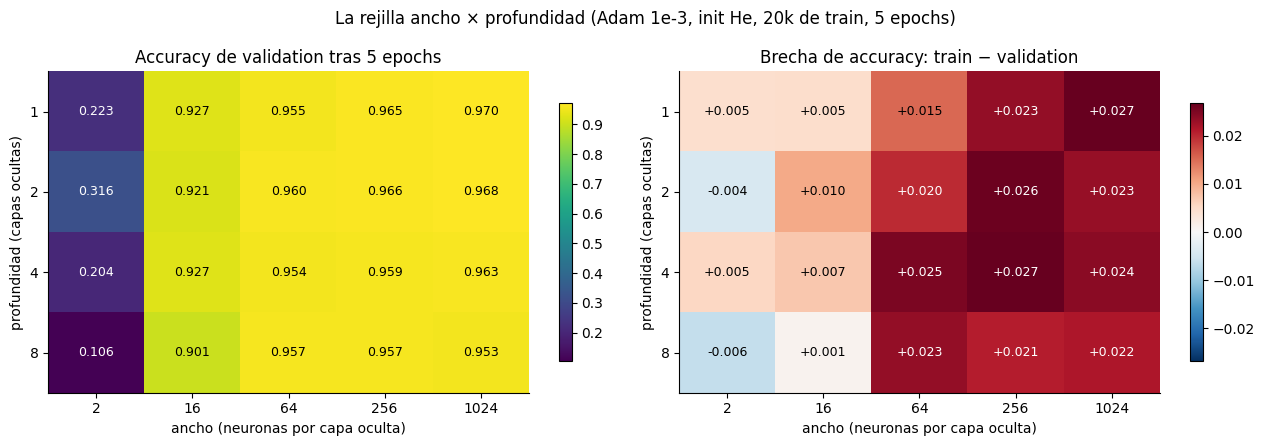

In [72]:
def matriz_s11(columna):
    """Matriz profundidad × ancho con el valor final (tras 5 epochs)."""
    M = np.full((len(PROFUNDIDADES), len(ANCHOS)), np.nan)
    for i, p in enumerate(PROFUNDIDADES):
        for j, a in enumerate(ANCHOS):
            h = REJILLA[(a, p)].historial
            M[i, j] = h[columna].iloc[-1]
    return M


def mapa_de_calor(M, ax, titulo, cmap, vmin, vmax, formato):
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(ANCHOS)), [str(a) for a in ANCHOS])
    ax.set_yticks(range(len(PROFUNDIDADES)), [str(p) for p in PROFUNDIDADES])
    ax.set_xlabel("ancho (neuronas por capa oculta)")
    ax.set_ylabel("profundidad (capas ocultas)")
    ax.set_title(titulo)
    ax.grid(False)
    for i in range(M.shape[0]):           # anota cada celda con su valor
        for j in range(M.shape[1]):
            v = M[i, j]
            texto = "—" if not np.isfinite(v) else format(v, formato)
            r, g, b, _ = im.cmap(im.norm(v)) if np.isfinite(v) else (1, 1, 1, 1)
            claro = 0.299 * r + 0.587 * g + 0.114 * b > 0.5   # fondo claro?
            ax.text(j, i, texto, ha="center", va="center", fontsize=9,
                    color="black" if claro else "white")
    plt.colorbar(im, ax=ax, shrink=0.8)


ACC_VAL = matriz_s11("acc_validation")
BRECHA = matriz_s11("acc_train") - ACC_VAL      # brecha train − validation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
mapa_de_calor(ACC_VAL, ax1, "Accuracy de validation tras 5 epochs",
              "viridis", np.nanmin(ACC_VAL), np.nanmax(ACC_VAL), ".3f")
m = max(np.nanmax(np.abs(BRECHA)), 1e-3)        # escala simétrica alrededor de 0
mapa_de_calor(BRECHA, ax2, "Brecha de accuracy: train − validation",
              "RdBu_r", -m, m, "+.3f")
fig.suptitle("La rejilla ancho × profundidad (Adam 1e-3, init He, "
             + ("RAPIDO: datos y pasos recortados)" if RAPIDO
                else "20k de train, 5 epochs)"))
fig.tight_layout()
plt.show()

<details><summary>Respuesta</summary>

**La red más estrecha y profunda quedó última.** Su accuracy terminó cerca del azar.
Aumentar ancho o profundidad no siempre ayudó. La mayor brecha no fue de la red más grande.
En otra corrida, las redes cercanas pueden cambiar de orden.

</details>

Cada punto es una red. El número indica su ancho y la línea agrupa redes de igual profundidad.
El eje de parámetros es logarítmico. **La accuracy se aplanó tras salir de los anchos más chicos.**
Compara redes con conteos parecidos y distinta forma.

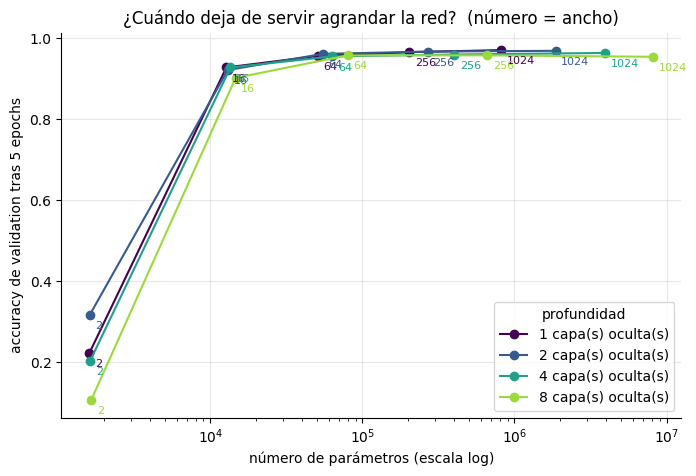

In [73]:
fig, ax = plt.subplots(figsize=(8, 5))
colores_prof = plt.cm.viridis(np.linspace(0, 0.85, len(PROFUNDIDADES)))
for color, p in zip(colores_prof, PROFUNDIDADES):
    xs = [REJILLA[(a, p)].parametros for a in ANCHOS]
    ys = [REJILLA[(a, p)].historial["acc_validation"].iloc[-1] for a in ANCHOS]
    ax.plot(xs, ys, "o-", color=color, label=f"{p} capa(s) oculta(s)")
    for a, x, y in zip(ANCHOS, xs, ys):  # rotula cada punto con su ancho
        ax.annotate(f"{a}", (x, y), textcoords="offset points",
                    xytext=(4, -10), fontsize=8, color=color)
ax.set_xscale("log")
ax.set_xlabel("número de parámetros (escala log)")
ax.set_ylabel("accuracy de validation tras 5 epochs")
ax.set_title("¿Cuándo deja de servir agrandar la red?  (número = ancho)")
ax.legend(title="profundidad")
plt.show()

Los dibujos comparan cuatro redes. Los puntos suspensivos indican neuronas omitidas.
**Una accuracy cercana al azar admite dos explicaciones.** En el mapa, ese fue el resultado de la red más estrecha y profunda.
Puede faltarle capacidad o puede ser difícil ajustar sus pesos en cinco epochs.
En §13 y §14 miraremos el gradiente por capa.

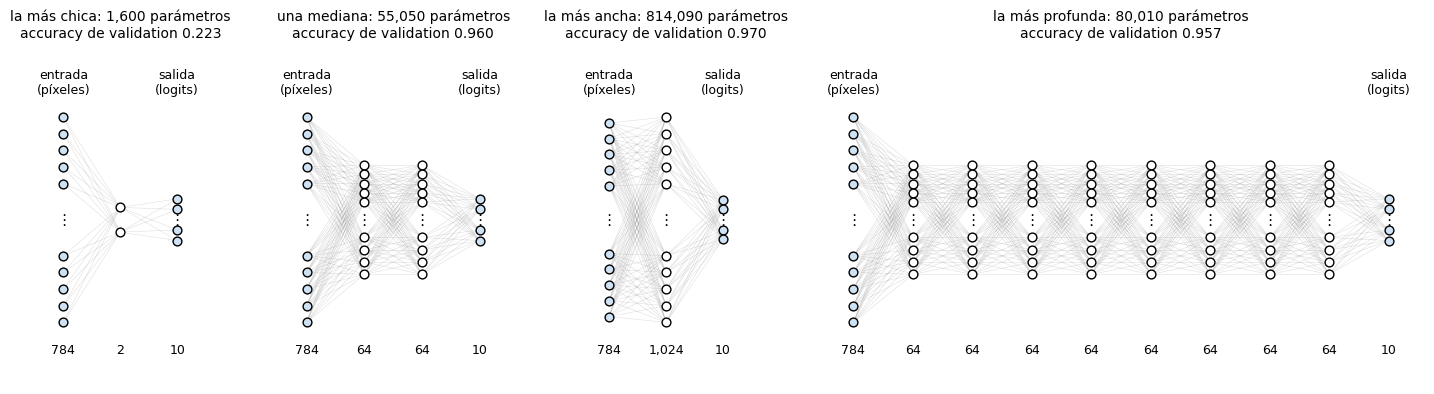

In [74]:
medio = ANCHOS[len(ANCHOS) // 2]      # 64 en la rejilla completa
EJEMPLOS = [(ANCHOS[0], PROFUNDIDADES[0], "la más chica"),       # [784, 2, 10]
            (medio, PROFUNDIDADES[1], "una mediana"),           # 64 × 2
            (ANCHOS[-1], PROFUNDIDADES[0], "la más ancha"),     # 1024 × 1
            (medio, PROFUNDIDADES[-1], "la más profunda")]      # 64 × 8
anchos_fig = [len(capas_s11(a, p)) for a, p, _ in EJEMPLOS]   # columnas de nodos
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4),
                         gridspec_kw={"width_ratios": anchos_fig})
for ax, (a, p, nombre) in zip(axes, EJEMPLOS):
    c = REJILLA[(a, p)]
    val = c.historial["acc_validation"].iloc[-1]
    dibujar_red(capas_s11(a, p), ax=ax,
                titulo=f"{nombre}: {c.parametros:,} parámetros\n"
                       f"accuracy de validation {val:.3f}")
plt.show()

Comparamos $[784,2,10]$ y $[784,256,2,10]$ con los mismos datos y presupuesto de epochs.
Cada punto representa una imagen de validation y su color indica el dígito verdadero.
**La salida recibe solo dos activaciones.** A la izquierda ves $\mathbf z$ y a la derecha $\mathbf a=\operatorname{ReLU}(\mathbf z)$.
ReLU convierte los valores negativos en cero. Los puntos pueden acumularse en los ejes o el origen.

In [75]:
# La red de ancho 2 y una capa oculta ya está en la rejilla: [784, 2, 10].
if "s11-a2-p1" not in CORRIDAS:      # por si se saltó la celda de la rejilla
    entrenar(config_s11(2, 1))
# Una segunda: primero 256 neuronas, luego el cuello de 2: [784, 256, 2, 10]
cfg = config_s11(2, 1)
cfg.id, cfg.capas = "s11-cuello-256", [784, 256, 2, 10]
entrenar(cfg)
CUELLOS = [CORRIDAS["s11-a2-p1"], CORRIDAS["s11-cuello-256"]]
for c in CUELLOS:
    print(f"{c.id:>15} {c.config.capas}  val "
          f"{c.historial['acc_validation'].iloc[-1]:.3f}")

s11-cuello-256: 201,504 parámetros · 785 pasos · mejor epoch 5 · acc validation 0.245 · 1.6 s
      s11-a2-p1 [784, 2, 10]  val 0.223
 s11-cuello-256 [784, 256, 2, 10]  val 0.245


s11-a2-p1: neurona 1 en cero 96.2%, neurona 2 en cero 59.6%, las dos en cero 56.1% de validation
   imágenes en el origen (0, 0), por dígito: [948, 9, 855, 349, 839, 110, 637, 1023, 78, 762]
s11-cuello-256: neurona 1 en cero 66.5%, neurona 2 en cero 100.0%, las dos en cero 66.5% de validation
   imágenes en el origen (0, 0), por dígito: [988, 42, 969, 992, 911, 895, 965, 6, 850, 30]


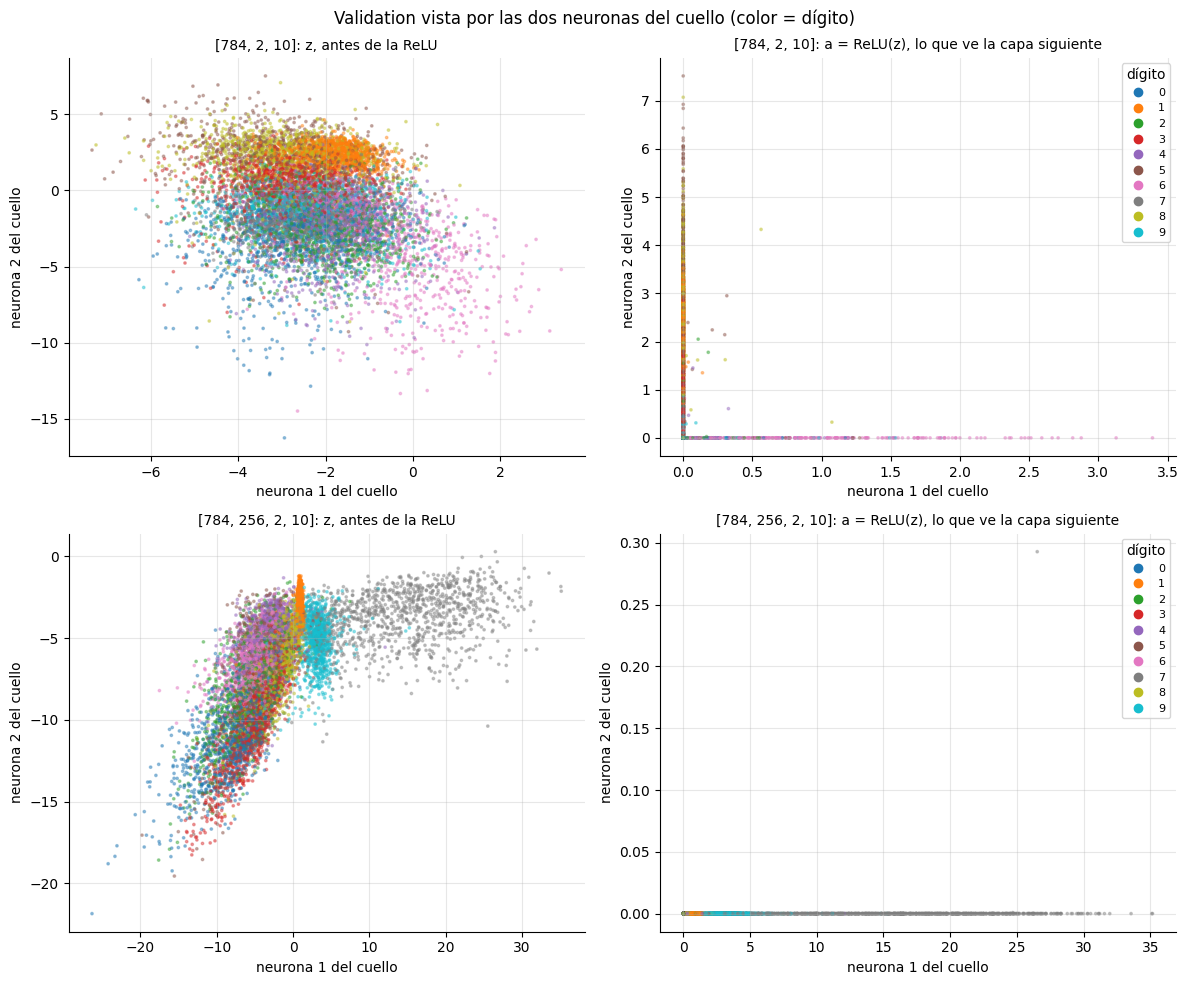

In [76]:
@torch.no_grad()
def activaciones_cuello(modelo, X):
    """Pasa X capa por capa y se detiene tras la activación que sigue a la
    capa lineal de 2 neuronas. Devuelve z (antes de la ReLU) y a (después)."""
    h, z = X, None
    for capa in modelo:
        if z is not None and isinstance(capa, nn.Linear):
            break                     # la siguiente lineal ya es la salida
        h = capa(h)
        if isinstance(capa, nn.Linear) and capa.out_features == 2:
            z = h                     # z: la combinación lineal del cuello
    return z.cpu().numpy(), h.cpu().numpy()


Xv, yv = DATOS["estandar"]["validation"]
digitos = yv.cpu().numpy()
orden = np.random.default_rng(SEMILLA).permutation(len(digitos))
# leyenda a mano: un punto de cada color
muestras = [plt.Line2D([], [], ls="", marker="o", color=plt.cm.tab10(d),
                       label=str(d)) for d in range(10)]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for fila, c in zip(axes, CUELLOS):
    z, a = activaciones_cuello(cargar(c, "ultima"), Xv)
    for ax, M, que in [(fila[0], z, "z, antes de la ReLU"),
                       (fila[1], a, "a = ReLU(z), lo que ve la capa siguiente")]:
        # orden al azar: si dibujáramos dígito por dígito, el 9 taparía al 0
        ax.scatter(M[orden, 0], M[orden, 1], s=3, alpha=0.4,
                   c=plt.cm.tab10(digitos[orden]))
        ax.set_xlabel("neurona 1 del cuello")
        ax.set_ylabel("neurona 2 del cuello")
        ax.set_title(f"{c.config.capas}: {que}", fontsize=10)
    fila[1].legend(handles=muestras, title="dígito", fontsize=8, loc="best")
    ceros = (a == 0)
    print(f"{c.id}: neurona 1 en cero {ceros[:, 0].mean():.1%}, "
          f"neurona 2 en cero {ceros[:, 1].mean():.1%}, "
          f"las dos en cero {ceros.all(axis=1).mean():.1%} de validation")
    en_origen = np.bincount(digitos[ceros.all(axis=1)], minlength=10)
    print("   imágenes en el origen (0, 0), por dígito:", en_origen.tolist())
fig.suptitle("Validation vista por las dos neuronas del cuello (color = dígito)")
fig.tight_layout()
plt.show()

**El colapso fue parcial.** En ambas redes, muchas imágenes cayeron en el origen y recibieron la misma predicción.
Con la capa de 256, más imágenes cayeron en el origen. La segunda neurona quedó en cero.
La primera aún distinguió parte de las imágenes.
En otra corrida podrían quedar activas ambas neuronas. Haría falta entrenar más para saber si el colapso persiste.

In [77]:
filas = []
# las 20 de la rejilla (ordenadas por profundidad y ancho) y el cuello de 256
ordenadas = sorted(REJILLA, key=lambda k: (k[1], k[0]))
for c in [REJILLA[k] for k in ordenadas] + [CORRIDAS["s11-cuello-256"]]:
    final = c.historial.iloc[-1]                 # tras las 5 epochs
    filas.append({"id": c.id, "capas ocultas": c.config.capas[1:-1],
                  "parametros": c.parametros,
                  "acc train": final["acc_train"],
                  "acc validation": final["acc_validation"],
                  "brecha": final["acc_train"] - final["acc_validation"],
                  "segundos": final["segundos"], "divergio": c.divergio})
RESUMEN_S11 = pd.DataFrame(filas).set_index("id").round(4)
display(RESUMEN_S11)
print(f"Tiempo total de la sección 11: {time.perf_counter() - T0_S11:.0f} s")

,capas ocultas,parametros,acc train,acc validation,brecha,segundos,divergio
id,,,,,,,
s11-a2-p1,[2],1600,0.2274,0.2229,0.0045,1.1991,False
s11-a16-p1,[16],12730,0.9317,0.9270,0.0047,1.1870,False
s11-a64-p1,[64],50890,0.9706,0.9552,0.0154,1.2018,False
s11-a256-p1,[256],203530,0.9881,0.9646,0.0235,1.4248,False
s11-a1024-p1,[1024],814090,0.9964,0.9697,0.0267,1.4061,False
s11-a2-p2,"[2, 2]",1606,0.3122,0.3164,-0.0043,1.3713,False
s11-a16-p2,"[16, 16]",13002,0.9308,0.9207,0.0101,1.3779,False
s11-a64-p2,"[64, 64]",55050,0.9804,0.9604,0.0201,1.3339,False
s11-a256-p2,"[256, 256]",269322,0.9923,0.9661,0.0262,1.3535,False


Tiempo total de la sección 11: 47 s


- **Aumentar el ancho ayudó sobre todo al salir del cuello estrecho.** Más adelante, añadir parámetros cambió poco la accuracy.
- La brecha tendió a crecer con el ancho y siguió siendo pequeña.
- Las activaciones mostraron un colapso parcial en las redes con cuello. En otra corrida puede cambiar cuántos ejemplos lo sufren.
- Compara arquitecturas con validation y reserva test para el informe final.

## 12 · La forma de la red

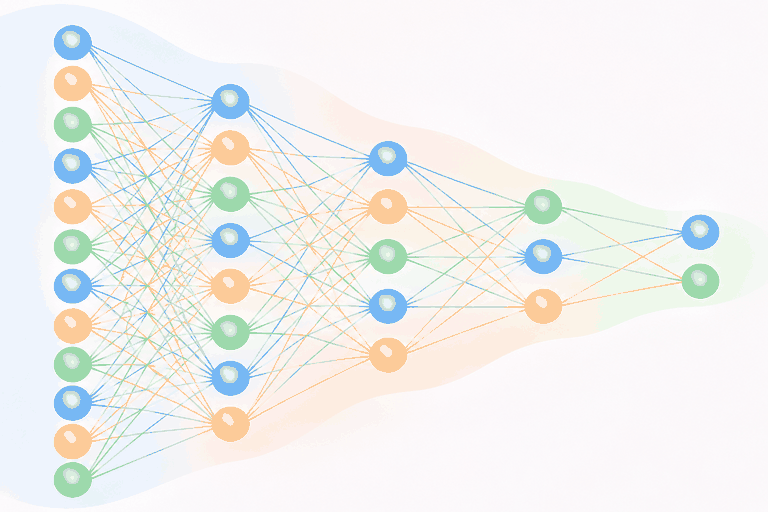
*(Ilustración generada con gpt-image-2.)*

Las cinco formas reparten **unos 102 mil parámetros** de maneras distintas.
Con $d_l$ neuronas en la capa $l$, el total es $\sum_{l=1}^{L}d_l(d_{l-1}+1)$, incluidos los sesgos.
La primera capa oculta concentra la mayoría, pues cada neurona recibe los 784 píxeles.
El cuello de dos neuronas también añade profundidad. Las curvas comparan el ajuste alcanzado en ocho epochs.

In [78]:
# Las cinco formas. Cada lista incluye la entrada (784) y la salida (10).
FORMAS_S12 = {
    "s12-embudo": ("embudo", [784, 124, 32, 10]),
    "s12-invertido": ("embudo invertido", [784, 96, 248, 10]),
    "s12-cuello": ("cuello de 2", [784, 128, 2, 128, 10]),
    "s12-rectangular": ("rectangular", [784, 112, 112, 10]),
    "s12-una-capa": ("una capa", [784, 128, 10]),
}


def contar_parametros(capas):
    """Σ_l d_l·(d_{l-1} + 1): pesos de W^(l) más sesgos de b^(l), capa por capa."""
    return sum(capas[l] * (capas[l - 1] + 1) for l in range(1, len(capas)))


for id_corrida, (nombre, capas) in FORMAS_S12.items():
    # La fórmula, término por término, para que se vea de dónde sale el total
    terminos = " + ".join(f"{capas[l]}·({capas[l - 1]}+1)"
                          for l in range(1, len(capas)))
    total = contar_parametros(capas)
    # Comprobación: PyTorch cuenta lo mismo que la fórmula
    red = construir_red(capas, init="he")
    assert total == sum(p.numel() for p in red.parameters()), nombre
    print(f"{nombre:>17}  {str(capas):<24} {total:>7,} parámetros")
    print(f"{'':>17}  = {terminos}")
del red

           embudo  [784, 124, 32, 10]       101,670 parámetros
                   = 124·(784+1) + 32·(124+1) + 10·(32+1)
 embudo invertido  [784, 96, 248, 10]       101,906 parámetros
                   = 96·(784+1) + 248·(96+1) + 10·(248+1)
      cuello de 2  [784, 128, 2, 128, 10]   102,412 parámetros
                   = 128·(784+1) + 2·(128+1) + 128·(2+1) + 10·(128+1)
      rectangular  [784, 112, 112, 10]      101,706 parámetros
                   = 112·(784+1) + 112·(112+1) + 10·(112+1)
         una capa  [784, 128, 10]           101,770 parámetros
                   = 128·(784+1) + 10·(128+1)


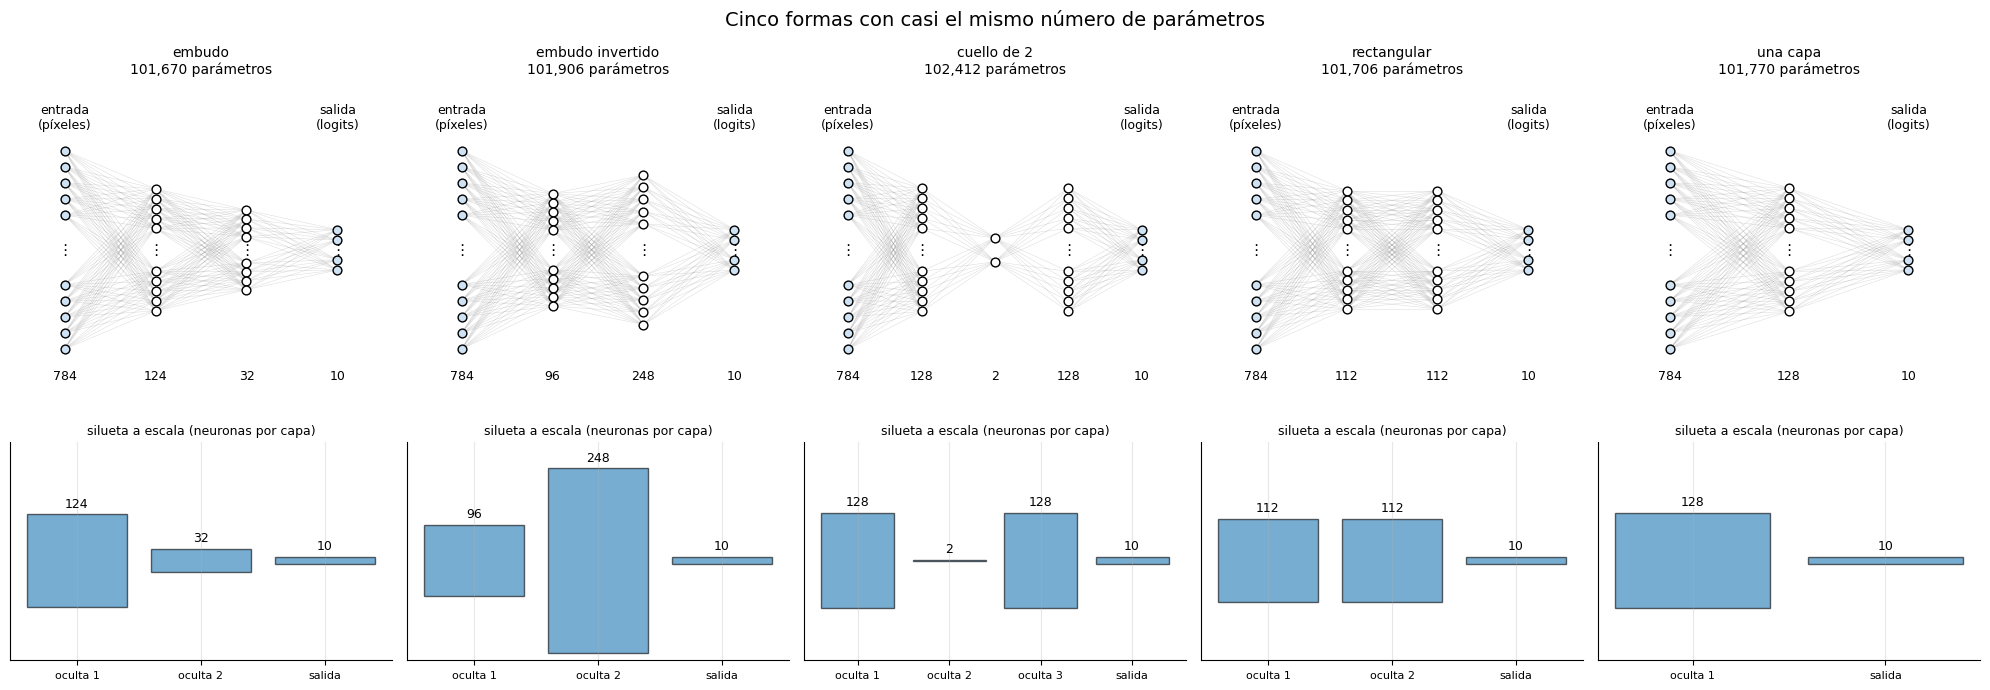

In [79]:
# Arriba, dibujar_red: columnas de nodos; una capa ancha se abrevia con «⋮»
# y su ancho real va debajo. Abajo, la silueta A ESCALA de las capas ocultas
# y la salida (la entrada de 784 se omite porque aplastaría a las demás):
# ahí sí se ven el embudo, el embudo invertido y el cuello.
fig, ejes = plt.subplots(2, 5, figsize=(20, 7),
                         gridspec_kw={"height_ratios": [3, 2]})
ancho_max = max(max(c[1:]) for _, c in FORMAS_S12.values())
for k, (nombre, capas) in enumerate(FORMAS_S12.values()):
    dibujar_red(capas, ax=ejes[0, k],
                titulo=f"{nombre}\n{contar_parametros(capas):,} parámetros")
    ax = ejes[1, k]
    anchos = capas[1:]                             # ocultas + salida
    etiquetas = [f"oculta {l}" for l in range(1, len(anchos))] + ["salida"]
    # Barra centrada en 0: su alto total es el ancho de la capa
    ax.bar(range(len(anchos)), anchos, bottom=[-d / 2 for d in anchos],
           color=COLORES["train"], alpha=0.6, edgecolor="black")
    for j, d in enumerate(anchos):
        ax.text(j, d / 2 + 6, str(d), ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(len(anchos)))
    ax.set_xticklabels(etiquetas, fontsize=8)
    ax.set_ylim(-ancho_max / 2 - 10, ancho_max / 2 + 35)
    ax.set_yticks([])
    ax.set_title("silueta a escala (neuronas por capa)", fontsize=9)
fig.suptitle("Cinco formas con casi el mismo número de parámetros", fontsize=14)
fig.tight_layout()
plt.show()

**Apuesta.** ¿Qué forma tendrá más aciertos en validation y cuál menos?
Elige entre embudo, embudo invertido, cuello de dos, rectangular y una capa oculta. Justifica en una frase.

**Misma receta para las cinco formas.** Todas usan ReLU, inicialización de He y Adam.
Comparten learning rate, tamaño de batch, número de epochs y semillas.
El subconjunto estratificado de train conserva la representación de los diez dígitos.

In [80]:
# Las cinco con exactamente la misma receta: lo único que cambia es la forma.
IDX_S12 = subconjunto(20000)    # el mismo subconjunto estratificado de §11

for id_corrida, (nombre, capas) in FORMAS_S12.items():
    # entrenar imprime una línea por corrida: parámetros, pasos, mejor epoch,
    # accuracy de validation en esa epoch y segundos
    entrenar(Config(
        id=id_corrida, seccion=12,
        capas=capas, activacion="relu", init="he",
        optimizer="adam", lr=1e-3, batch=128, epochs=8,
        idx_train=IDX_S12, datos="20k-limpio",
        semilla_init=SEMILLA, semilla_orden=SEMILLA,   # mismas semillas para todas
    ))

CORRIDAS_S12 = [CORRIDAS[i] for i in FORMAS_S12]

s12-embudo: 101,670 parámetros · 1256 pasos · mejor epoch 6 · acc validation 0.963 · 2.1 s
s12-invertido: 101,906 parámetros · 1256 pasos · mejor epoch 8 · acc validation 0.968 · 2.1 s
s12-cuello: 102,412 parámetros · 1256 pasos · mejor epoch 8 · acc validation 0.924 · 2.4 s
s12-rectangular: 101,706 parámetros · 1256 pasos · mejor epoch 8 · acc validation 0.967 · 2.4 s
s12-una-capa: 101,770 parámetros · 1256 pasos · mejor epoch 8 · acc validation 0.968 · 2.1 s


**Compara las formas en la misma epoch.** Los paneles de cada figura comparten escala.
Busca si el cuello ajusta peor incluso en train. Eso apunta a underfitting.
Test se reporta una sola vez, al final. Aquí se grafica para practicar. El checkpoint se elige por loss de validation.

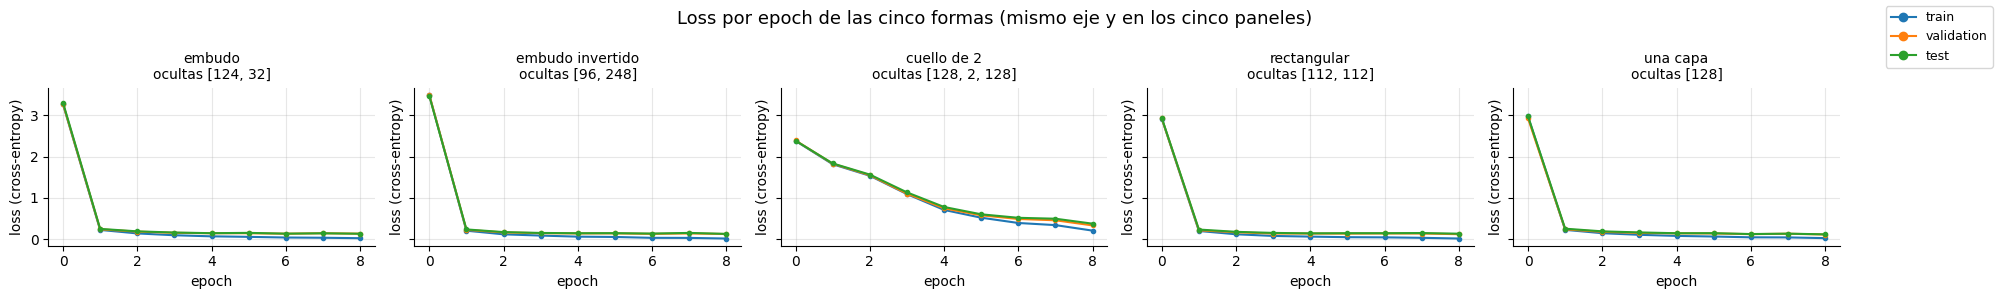

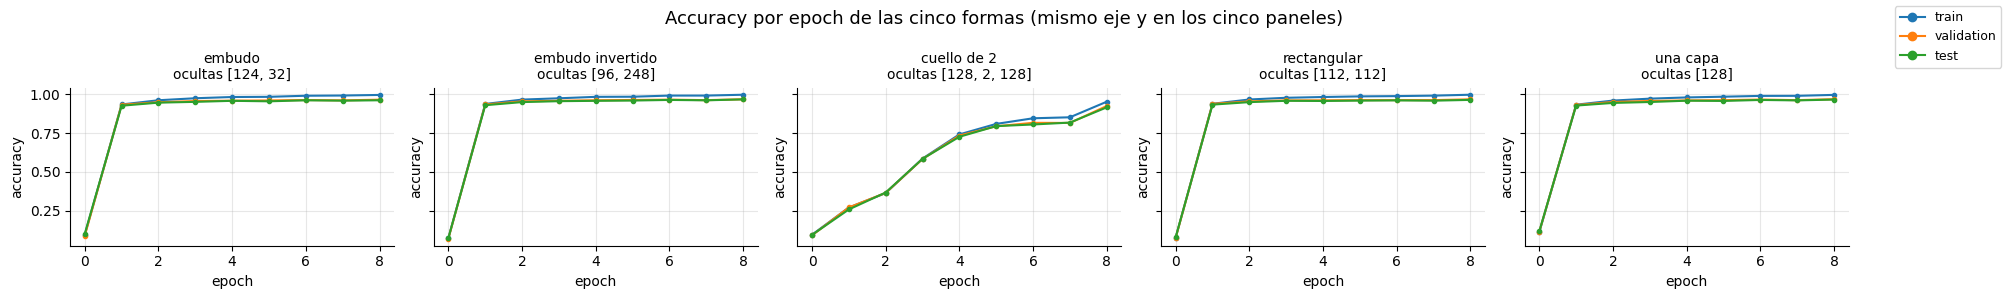

In [81]:
# Small multiples: un panel por forma, el mismo eje y en todos para poder
# comparar alturas a simple vista. Test aparece solo de manera didáctica.
for metrica, nombre_metrica in [("loss", "Loss"), ("accuracy", "Accuracy")]:
    fig = rejilla(CORRIDAS_S12, x="epoch", metrica=metrica, columnas=5,
                  misma_y=True)
    for ax, (nombre, capas) in zip(fig.axes, FORMAS_S12.values()):
        ax.set_title(f"{nombre}\nocultas {capas[1:-1]}", fontsize=10)
    # La leyenda común solo nombra el conjunto: el color es lo que importa
    for leyenda in fig.legends:
        leyenda.remove()
    fig.legend(handles=[plt.Line2D([], [], color=COLORES[c], marker="o", label=c)
                        for c in ("train", "validation", "test")],
               loc="upper right", fontsize=9)
    fig.suptitle(f"{nombre_metrica} por epoch de las cinco formas "
                 "(mismo eje y en los cinco paneles)", fontsize=13)
    fig.tight_layout(rect=(0, 0, 0.93, 1))
    plt.show()

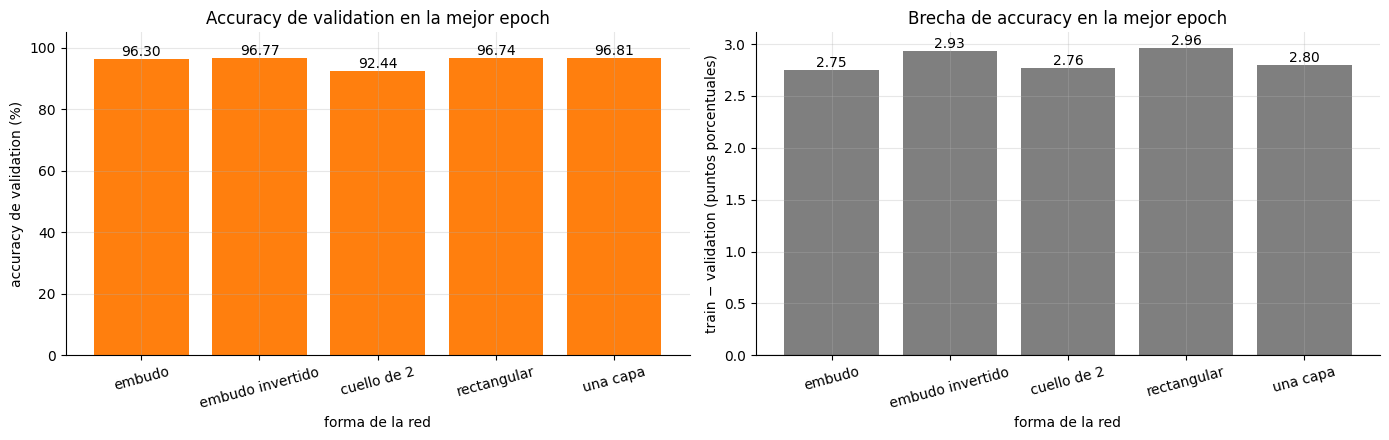

In [82]:
# Resumen en la mejor epoch de cada corrida, elegida por la loss de
# validation (nunca por test). La tabla maestra ya trae accuracy de train y
# de validation en esa epoch, y la brecha = acc_train − acc_validation.
TABLA_S12 = tabla_maestra([12]).set_index("id").loc[list(FORMAS_S12)]
RESUMEN_S12 = pd.DataFrame({
    "forma": [FORMAS_S12[i][0] for i in TABLA_S12.index],
    "ocultas": [str(FORMAS_S12[i][1][1:-1]) for i in TABLA_S12.index],
    "parametros": TABLA_S12["parametros"].to_numpy(),
    "mejor_epoch": TABLA_S12["mejor_epoch"].to_numpy(),
    "acc_validation_%": 100 * TABLA_S12["acc_validation"].to_numpy(),
    "brecha_pp": 100 * TABLA_S12["brecha"].to_numpy(),   # puntos porcentuales
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
x = range(len(RESUMEN_S12))
b1 = ax1.bar(x, RESUMEN_S12["acc_validation_%"], color=COLORES["validation"])
ax1.bar_label(b1, fmt="%.2f")
ax1.set_ylim(0, 105)                 # empieza en cero: no exagera diferencias
ax1.set_ylabel("accuracy de validation (%)")
ax1.set_title("Accuracy de validation en la mejor epoch")
b2 = ax2.bar(x, RESUMEN_S12["brecha_pp"], color="#7f7f7f")
ax2.bar_label(b2, fmt="%.2f")
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_ylabel("train − validation (puntos porcentuales)")
ax2.set_title("Brecha de accuracy en la mejor epoch")
for ax in (ax1, ax2):
    ax.set_xticks(list(x))
    ax.set_xticklabels(RESUMEN_S12["forma"], rotation=15)
    ax.set_xlabel("forma de la red")
fig.tight_layout()
plt.show()

In [83]:
# Los mismos números en una tabla (accuracy en %, brecha en puntos
# porcentuales), y debajo las filas de §12 de la tabla maestra completa.
print(RESUMEN_S12.round(2).to_string(index=False))
print()
print(TABLA_S12.reset_index().round(4).to_string(index=False))

           forma       ocultas  parametros  mejor_epoch  acc_validation_%  brecha_pp
          embudo     [124, 32]      101670            6             96.30       2.75
embudo invertido     [96, 248]      101906            8             96.77       2.93
     cuello de 2 [128, 2, 128]      102412            8             92.44       2.76
     rectangular    [112, 112]      101706            8             96.74       2.96
        una capa         [128]      101770            8             96.81       2.80

             id  seccion      datos  parametros  mejor_epoch  pasos  ejemplos  acc_train  acc_validation  acc_test  loss_train  loss_validation  loss_test  brecha  segundos  divergio
     s12-embudo       12 20k-limpio      101670            6    942    120000     0.9905          0.9630    0.9611      0.0387           0.1304     0.1324  0.0275    2.1203     False
  s12-invertido       12 20k-limpio      101906            8   1256    160000     0.9970          0.9677    0.9671      0.0

<details><summary>Respuesta</summary>

**El cuello ajustó peor** en train y validation. Las otras cuatro formas quedaron cerca.
El cuello comprime cada imagen a dos activaciones. La profundidad adicional también puede dificultar la optimización.

</details>

- El cuello quedó atrás pese a tener **una brecha de accuracy parecida** a las demás.
- Las cuatro formas sin cuello casi empataron en validation. En otra corrida puede cambiar su orden.
- Las curvas dejan abierta la contribución de la capacidad y de la dificultad de optimización.

## 13 · Activaciones

Cada capa oculta calcula $\mathbf z^{(l)}=\mathbf W^{(l)}\mathbf a^{(l-1)}+\mathbf b^{(l)}$ y luego $\mathbf a^{(l)}=g^{(l)}(\mathbf z^{(l)})$.
La **activación no lineal** evita que toda la red se reduzca a una transformación afín.
Compara ReLU $\max(0,z)$, sigmoide $1/(1+e^{-z})$, $\tanh(z)$ y GELU $z\Phi(z)$, con $\Phi$ la distribución acumulada normal estándar.
Las redes comparten seis capas ocultas de 128 neuronas, pesos ortogonales iniciales y sesgos en cero.

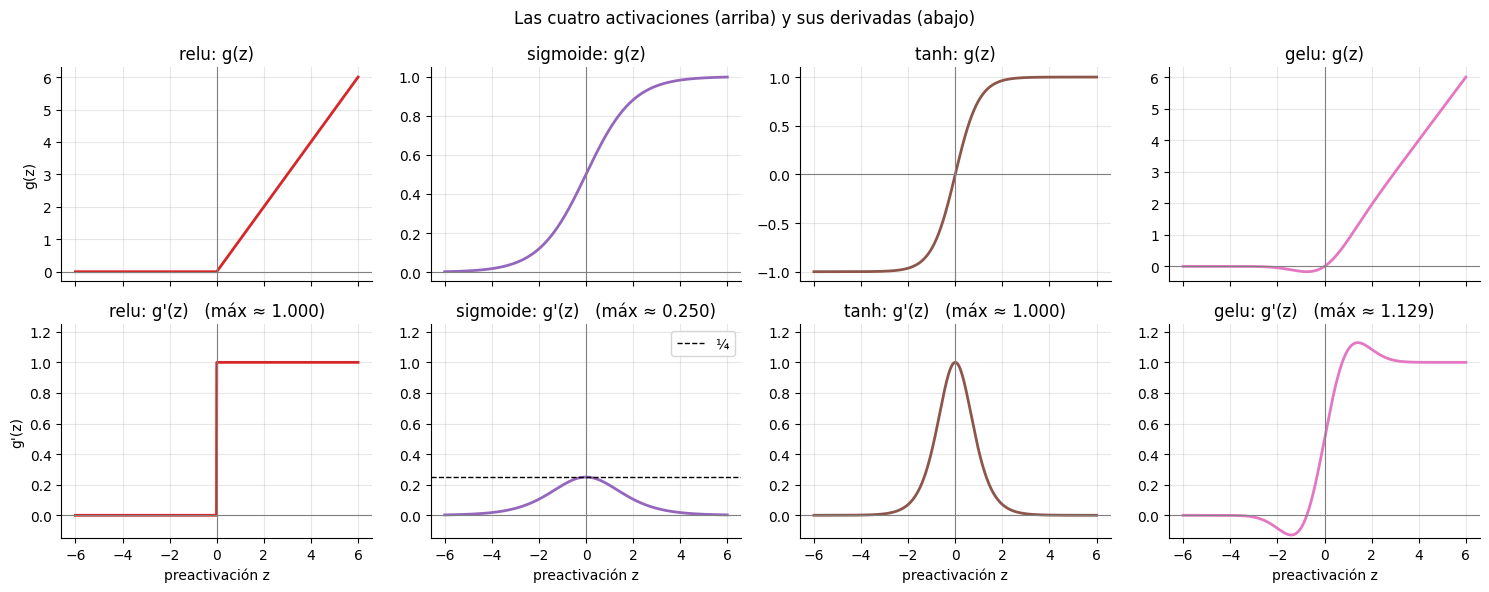

relu      máx g'(z) en [-6, 6] = 1.0000
sigmoide  máx g'(z) en [-6, 6] = 0.2500
tanh      máx g'(z) en [-6, 6] = 1.0000
gelu      máx g'(z) en [-6, 6] = 1.1289
sigmoide: cota analítica ¼ = 0.25


In [84]:
# Las cuatro activaciones g(z) y sus derivadas g'(z). Las derivadas NO las
# escribimos a mano: se las pedimos a autograd, el mismo mecanismo que hace
# backpropagation en todo el notebook.
import math
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn
import matplotlib.pyplot as plt

ACTIVACIONES_S13 = ["relu", "sigmoide", "tanh", "gelu"]
FUNCIONES_S13 = {"relu": F.relu, "sigmoide": torch.sigmoid,
                 "tanh": torch.tanh, "gelu": F.gelu}
# Un color por activación (no usamos azul/naranja/verde: son train/val/test).
COLOR_ACT_S13 = {"relu": "#d62728", "sigmoide": "#9467bd",
                 "tanh": "#8c564b", "gelu": "#e377c2"}

z = torch.linspace(-6, 6, 1201, requires_grad=True)
fig, ejes = plt.subplots(2, 4, figsize=(15, 6), sharex=True)
for col, nombre in enumerate(ACTIVACIONES_S13):
    g = FUNCIONES_S13[nombre](z)
    (derivada,) = torch.autograd.grad(g.sum(), z)  # g'(z) en cada punto
    zz, gg, dd = z.detach().numpy(), g.detach().numpy(), derivada.numpy()
    color = COLOR_ACT_S13[nombre]
    ejes[0, col].plot(zz, gg, color=color, lw=2)
    ejes[0, col].set_title(f"{nombre}: g(z)")
    ejes[1, col].plot(zz, dd, color=color, lw=2)
    ejes[1, col].set_title(f"{nombre}: g'(z)   (máx ≈ {dd.max():.3f})")
    ejes[1, col].set_xlabel("preactivación z")
    ejes[1, col].set_ylim(-0.15, 1.25)
    for fila in range(2):
        ejes[fila, col].axhline(0, color="gray", lw=0.8)
        ejes[fila, col].axvline(0, color="gray", lw=0.8)
# La cota analítica de la sigmoide: σ'(z) = σ(z)(1 − σ(z)) ≤ 1/4, en z = 0.
ejes[1, 1].axhline(0.25, color="black", ls="--", lw=1, label="¼")
ejes[1, 1].legend(loc="upper right")
ejes[0, 0].set_ylabel("g(z)")
ejes[1, 0].set_ylabel("g'(z)")
fig.suptitle("Las cuatro activaciones (arriba) y sus derivadas (abajo)")
plt.tight_layout()
plt.show()

for nombre in ACTIVACIONES_S13:
    zg = torch.linspace(-6, 6, 1201, requires_grad=True)
    (d,) = torch.autograd.grad(FUNCIONES_S13[nombre](zg).sum(), zg)
    print(f"{nombre:9s} máx g'(z) en [-6, 6] = {d.max().item():.4f}")
print("sigmoide: cota analítica ¼ =", 0.25)

- Para la sigmoide, $\sigma'(z)=\sigma(z)(1-\sigma(z))$. **Su pendiente máxima es $\tfrac14$** en $z=0$.
- Para tanh, $1-\tanh^2(z)$ alcanza $1$ en cero. Ambas pendientes se acercan a cero lejos del centro.
- La pendiente de ReLU es $1$ para $z>0$ y $0$ para $z<0$. PyTorch usa $0$ en el origen.
- La pendiente de GELU varía suavemente. Es negativa en parte del lado negativo y supera $1$ en parte del positivo.

En backpropagation, $\boldsymbol\delta^{(l)}=\nabla_{\mathbf z^{(l)}}\ell$ es el error que llega a la preactivación.
$$
\boldsymbol\delta^{(l)}
=\bigl((\mathbf W^{(l+1)})^\top\boldsymbol\delta^{(l+1)}\bigr)
\odot g^{(l)\prime}(\mathbf z^{(l)}).
$$
Las matrices iniciales tienen norma espectral unitaria. Para la sigmoide, **las pendientes atenúan la señal capa a capa**.
Así, $\|\boldsymbol\delta^{(1)}\|_2\le(\tfrac14)^6\|\boldsymbol\delta^{(7)}\|_2$ al inicio.
El gradiente de los pesos también depende de la entrada, según $\nabla_{\mathbf W^{(l)}}\ell=\boldsymbol\delta^{(l)}(\mathbf a^{(l-1)})^\top$.

**Apuesta.** ¿Cuál tendrá el menor gradiente inicial de los pesos de la primera capa? ¿Cuál tendrá mayor loss final de validation?
Elige entre ReLU, sigmoide, tanh y GELU para cada pregunta.

capas: [784, 128, 128, 128, 128, 128, 128, 10]
Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=128, out_features=128, bias=True)
  (3): Sigmoid()
  (4): Linear(in_features=128, out_features=128, bias=True)
  (5): Sigmoid()
  (6): Linear(in_features=128, out_features=128, bias=True)
  (7): Sigmoid()
  (8): Linear(in_features=128, out_features=128, bias=True)
  (9): Sigmoid()
  (10): Linear(in_features=128, out_features=128, bias=True)
  (11): Sigmoid()
  (12): Linear(in_features=128, out_features=10, bias=True)
)
¿pesos iniciales de sigmoide == los de relu? True
¿pesos iniciales de tanh == los de relu? True
¿pesos iniciales de gelu == los de relu? True
sesgos iniciales en cero: True
‖W^(l)‖₂ por capa: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


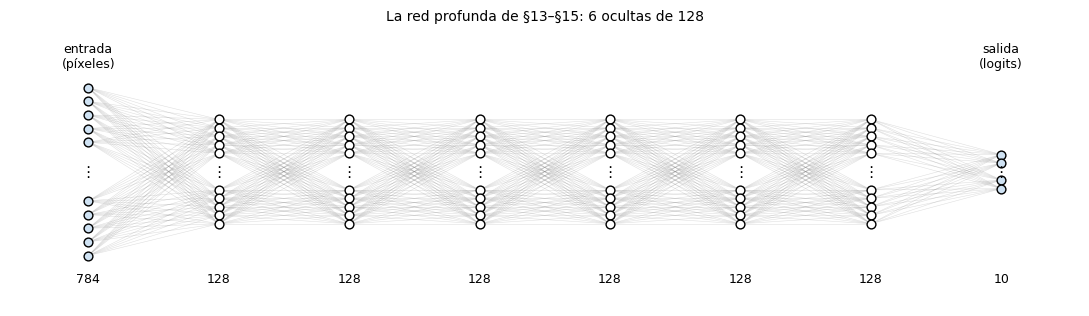

In [85]:
# Cuatro redes iguales salvo la activación: 784 → 6 × 128 → 10, pesos
# ortogonales y sesgos en cero. Con la misma semilla, los pesos iniciales
# son los mismos en las cuatro: así la única diferencia es g.
REDES_INICIALES_S13 = {}
for nombre in ACTIVACIONES_S13:
    cfg = config_profunda(nombre)
    torch.manual_seed(cfg.semilla_init)
    REDES_INICIALES_S13[nombre] = construir_red(
        cfg.capas, activacion=cfg.activacion, init=cfg.init).to(DEVICE)

CAPAS_S13 = config_profunda("relu").capas
print("capas:", CAPAS_S13)
print(REDES_INICIALES_S13["sigmoide"])


def lineales(red):
    """Las capas nn.Linear de la red, en orden: W^(1), …, W^(L)."""
    return [m for m in red.modules() if isinstance(m, nn.Linear)]


ref = lineales(REDES_INICIALES_S13["relu"])
for nombre in ACTIVACIONES_S13[1:]:
    otras = lineales(REDES_INICIALES_S13[nombre])
    iguales = all(torch.equal(a.weight, b.weight) for a, b in zip(ref, otras))
    print(f"¿pesos iniciales de {nombre} == los de relu? {iguales}")
print("sesgos iniciales en cero:",
      all(bool((m.bias == 0).all()) for m in ref))
# Norma espectral de cada W: con init ortogonal de ganancia 1 vale 1. Las
# filas son ortonormales, así que W transpuesta (la que usa backpropagation)
# conserva la norma de cualquier vector; W en sí nunca estira.
print("‖W^(l)‖₂ por capa:",
      [round(torch.linalg.matrix_norm(m.weight.detach(), ord=2).item(), 3)
       for m in ref])

dibujar_red(CAPAS_S13, titulo="La red profunda de §13–§15: 6 ocultas de 128")
plt.show()

Usamos el mismo batch antes de actualizar los pesos. `retain_grad()` conserva el gradiente de cada preactivación.
**Medimos dos normas de Frobenius.** Una resume el gradiente de los pesos y la otra, `z.grad`.
Cada fila de `z.grad` contiene el error de una imagen dividido entre el tamaño del batch.

In [86]:
# Un batch FIJO de train (las mismas imágenes para las cuatro redes).
X_tr, y_tr = DATOS[config_profunda("relu").escala]["train"]
gen = torch.Generator().manual_seed(SEMILLA)
N_BATCH_S13 = 128 if RAPIDO else 512
idx = torch.randperm(len(y_tr), generator=gen)[:N_BATCH_S13].to(DEVICE)
xb, yb = X_tr[idx], y_tr[idx]


def recorrer(red, x):
    """Forward capa por capa. Guarda cada preactivación z^(l) (salida de una
    Linear) y cada activación a^(l) = g(z^(l)) (salida de la no linealidad)."""
    zs, activaciones = [], []
    for modulo in red:
        x = modulo(x)
        if isinstance(modulo, nn.Linear):
            if x.requires_grad:        # (dentro de no_grad no hay gradiente)
                x.retain_grad()        # queremos δ^(l) = ∂L/∂z^(l) al final
            zs.append(x)
        elif not isinstance(modulo, (nn.Dropout, nn.BatchNorm1d, nn.Identity)):
            activaciones.append(x)
    return x, zs, activaciones


filas = []
for nombre, red in REDES_INICIALES_S13.items():
    red.eval()                          # sin dropout ni BN: no cambia nada
    red.zero_grad()
    logits, zs, _ = recorrer(red, xb)
    perdida = nn.functional.cross_entropy(logits, yb)
    perdida.backward()                  # backpropagation: la regla de la cadena
    for l, (lin, z_l) in enumerate(zip(lineales(red), zs), start=1):
        filas.append({"activacion": nombre, "capa": l,
                      "norma_grad_W": lin.weight.grad.norm().item(),
                      "norma_delta": z_l.grad.norm().item()})
    red.zero_grad()                     # no dejamos gradientes colgados
DIAG_S13 = pd.DataFrame(filas)
tabla = DIAG_S13.pivot(index="capa", columns="activacion",
                       values="norma_grad_W")[ACTIVACIONES_S13]
print("‖∇_W^(l) L‖ antes del primer paso (filas = capa l, "
      "columnas = activación):")
display(tabla.map(lambda v: f"{v:.2e}"))

‖∇_W^(l) L‖ antes del primer paso (filas = capa l, columnas = activación):


activacion,relu,sigmoide,tanh,gelu
capa,,,,
1,2.70e-01,6.89e-04,1.18e+00,1.09e-01
2,1.09e-01,7.83e-04,4.56e-01,4.13e-02
3,1.13e-01,3.31e-03,4.55e-01,3.93e-02
4,1.09e-01,1.39e-02,4.51e-01,3.65e-02
5,1.02e-01,5.96e-02,4.51e-01,3.68e-02
6,9.96e-02,2.52e-01,4.48e-01,3.69e-02
7,9.80e-02,1.09e+00,4.50e-01,3.75e-02


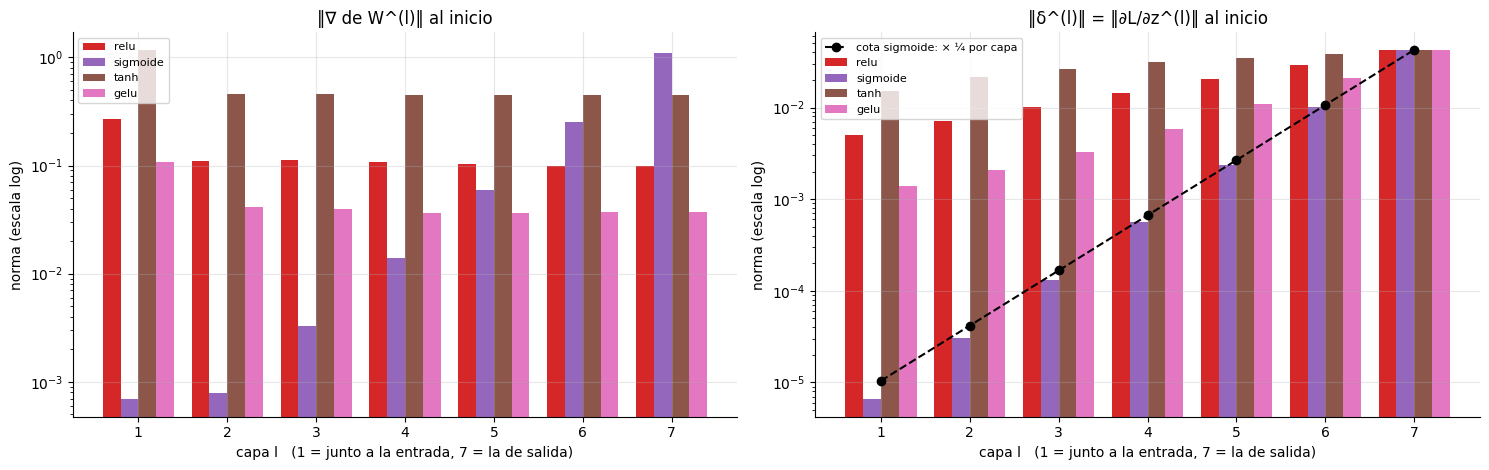

relu      ‖δ^(1)‖ / ‖δ^(7)‖ = 1.20e-01
sigmoide  ‖δ^(1)‖ / ‖δ^(7)‖ = 1.53e-04
tanh      ‖δ^(1)‖ / ‖δ^(7)‖ = 3.55e-01
gelu      ‖δ^(1)‖ / ‖δ^(7)‖ = 3.34e-02
cota analítica de la sigmoide: (¼)^6 = 2.44e-04 (× ∏‖W‖₂ = 1.000)


In [87]:
# Barras agrupadas: una por capa, una serie por activación, eje y en log.
n_capas = DIAG_S13["capa"].max()
ancho = 0.2
fig, (ax_w, ax_d) = plt.subplots(1, 2, figsize=(15, 4.8))
for k, nombre in enumerate(ACTIVACIONES_S13):
    d = DIAG_S13[DIAG_S13["activacion"] == nombre]
    pos = d["capa"] + (k - 1.5) * ancho
    ax_w.bar(pos, d["norma_grad_W"], ancho, color=COLOR_ACT_S13[nombre],
             label=nombre)
    ax_d.bar(pos, d["norma_delta"], ancho, color=COLOR_ACT_S13[nombre],
             label=nombre)

# La cota de la sigmoide sobre δ: cada capa oculta multiplica por ≤ ¼ y por
# ‖W‖₂ (≈ 1 con init ortogonal). Se parte del δ real de la salida.
sig = DIAG_S13[DIAG_S13["activacion"] == "sigmoide"].set_index("capa")
normas_W = [torch.linalg.matrix_norm(m.weight.detach(), ord=2).item()
            for m in lineales(REDES_INICIALES_S13["sigmoide"])]
cota = {n_capas: sig.loc[n_capas, "norma_delta"]}
for l in range(n_capas - 1, 0, -1):
    cota[l] = cota[l + 1] * normas_W[l] * 0.25   # normas_W[l] es W^(l+1)
capas_cota = sorted(cota)
ax_d.plot(capas_cota, [cota[l] for l in capas_cota], "k--", marker="o",
          label="cota sigmoide: × ¼ por capa")

for ax, titulo in [(ax_w, "‖∇ de W^(l)‖ al inicio"),
                   (ax_d, "‖δ^(l)‖ = ‖∂L/∂z^(l)‖ al inicio")]:
    ax.set_yscale("log")
    ax.set_xticks(range(1, n_capas + 1))
    ax.set_xlabel("capa l   (1 = junto a la entrada, "
                  f"{n_capas} = la de salida)")
    ax.set_ylabel("norma (escala log)")
    ax.set_title(titulo)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for nombre in ACTIVACIONES_S13:
    d = DIAG_S13[DIAG_S13["activacion"] == nombre].set_index("capa")
    r = d.loc[1, "norma_delta"] / d.loc[n_capas, "norma_delta"]
    print(f"{nombre:9s} ‖δ^(1)‖ / ‖δ^({n_capas})‖ = {r:.2e}")
print(f"cota analítica de la sigmoide: (¼)^6 = {0.25 ** 6:.2e} "
      f"(× ∏‖W‖₂ = {math.prod(normas_W[1:]):.3f})")

**Sigue las barras de la salida a la entrada** en escala logarítmica.
El panel derecho muestra el error de preactivación. La línea discontinua marca la cota de la sigmoide.
El panel izquierdo mide el gradiente de los pesos, que también depende de las activaciones anteriores.

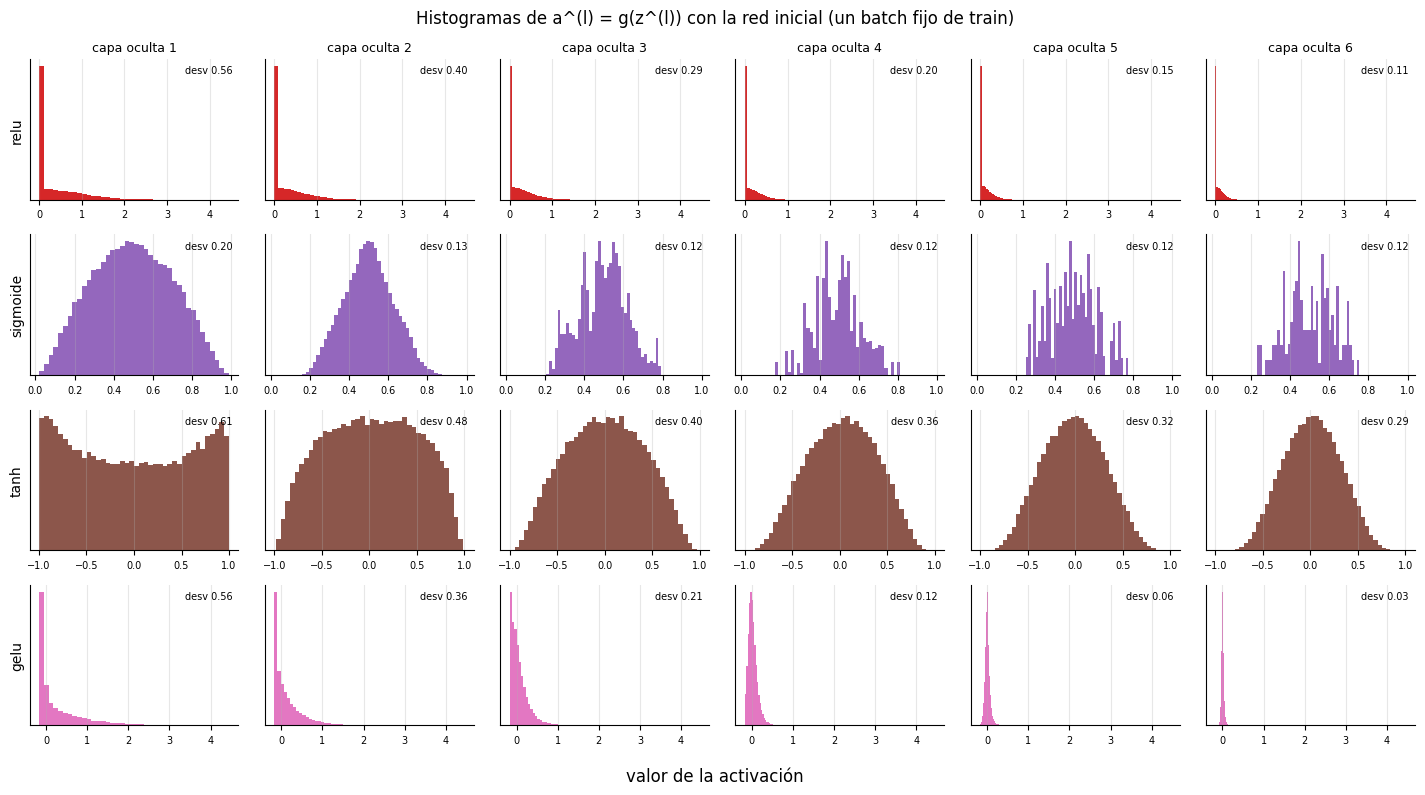

In [88]:
# Las activaciones a^(l) de cada capa oculta, con la red recién creada y el
# mismo batch fijo. Filas = activación, columnas = capa oculta l = 1…6.
with torch.no_grad():
    salidas = {n: recorrer(r, xb)[2] for n, r in REDES_INICIALES_S13.items()}
n_ocultas = len(salidas["relu"])
fig, ejes = plt.subplots(len(ACTIVACIONES_S13), n_ocultas,
                         figsize=(2.4 * n_ocultas, 8), sharex="row")
for i, nombre in enumerate(ACTIVACIONES_S13):
    for l, a in enumerate(salidas[nombre], start=1):
        ax = ejes[i, l - 1]
        valores = a.flatten().cpu().numpy()
        ax.hist(valores, bins=40, color=COLOR_ACT_S13[nombre])
        ax.set_yticks([])
        ax.tick_params(labelsize=7)
        if i == 0:
            ax.set_title(f"capa oculta {l}", fontsize=9)
        if l == 1:
            ax.set_ylabel(nombre, fontsize=10)
        ax.text(0.97, 0.9, f"desv {valores.std():.2f}", fontsize=7,
                ha="right", transform=ax.transAxes)
fig.suptitle("Histogramas de a^(l) = g(z^(l)) con la red inicial "
             "(un batch fijo de train)")
fig.supxlabel("valor de la activación")
plt.tight_layout()
plt.show()
del salidas

**Compara la dispersión al aumentar la profundidad.** Cada histograma reúne las activaciones de una capa en el mismo batch inicial.
La sigmoide concentra salidas cerca de $\tfrac12$ y tanh alrededor de cero.
ReLU acumula valores en cero. GELU admite valores negativos pequeños.

**Mismo presupuesto con SGD sin momentum.** Las redes comparten learning rate y orden de batches.
La referencia uniforme da cross-entropy $\log 10$ y accuracy esperada del $10\,\%$.
Test se reporta una sola vez, al final. Aquí se grafica para practicar. Compara las redes con validation.

In [89]:
# Las cuatro redes, ~500 pasos de SGD (η = 0.03, sin momentum) con batches
# de 128. Evaluamos train/validation/test completos cada 50 pasos.
CORRIDAS_S13 = {}
for nombre in ACTIVACIONES_S13:
    cfg = config_profunda(nombre, id=f"s13-{nombre}", seccion=13,
                          max_pasos=500, eval_cada_pasos=50,
                          medir_por_paso=True)
    CORRIDAS_S13[nombre] = entrenar(cfg)
    print(f"{cfg.id}: {CORRIDAS_S13[nombre].historial['pasos'].max()} pasos,"
          f" divergió = {CORRIDAS_S13[nombre].divergio}")

s13-relu: 184,330 parámetros · 500 pasos · mejor epoch 1.27877 · acc validation 0.932 · 1.3 s
s13-relu: 500 pasos, divergió = False
s13-sigmoide: 184,330 parámetros · 500 pasos · mejor epoch 1.27877 · acc validation 0.109 · 1.6 s
s13-sigmoide: 500 pasos, divergió = False
s13-tanh: 184,330 parámetros · 500 pasos · mejor epoch 1.27877 · acc validation 0.930 · 1.6 s
s13-tanh: 500 pasos, divergió = False
s13-gelu: 184,330 parámetros · 500 pasos · mejor epoch 1.27877 · acc validation 0.931 · 1.4 s
s13-gelu: 500 pasos, divergió = False


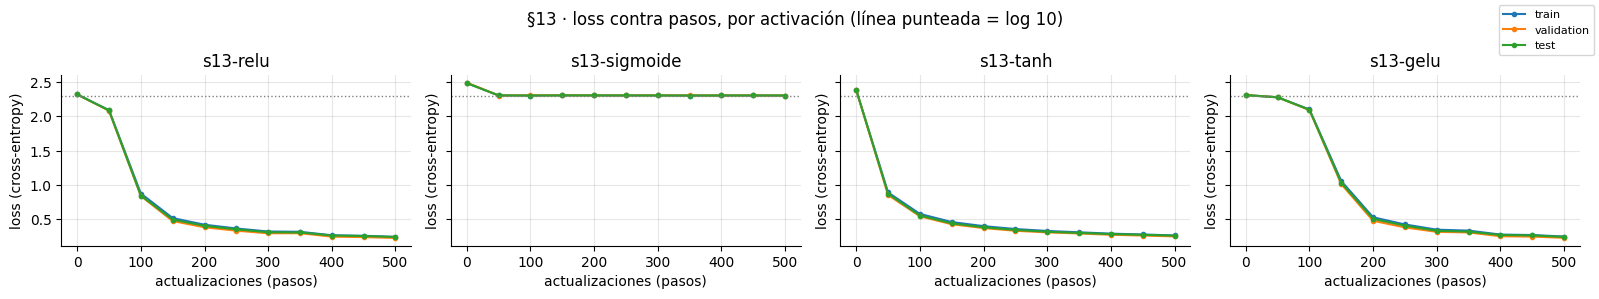

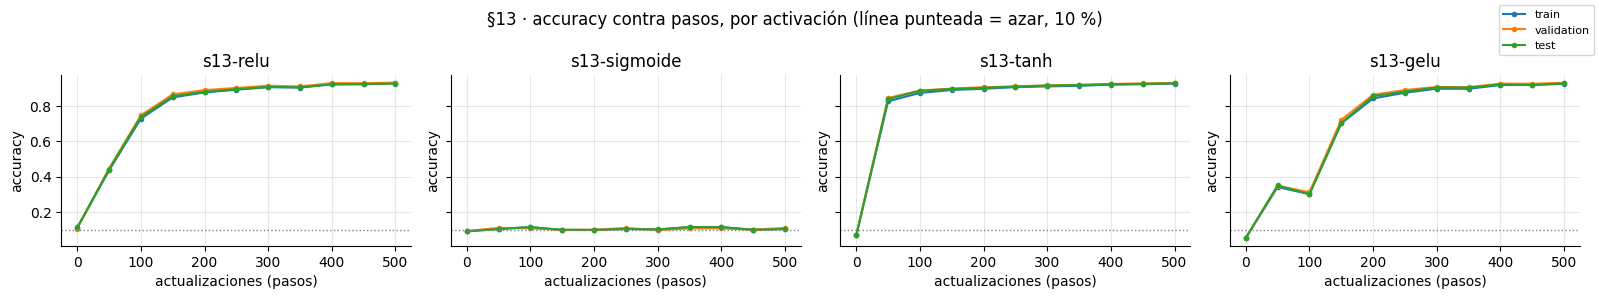

In [90]:
# Mismos ejes en los cuatro paneles. Recuerda: mirar test en cada
# evaluación está mal; aquí es solo didáctico y nada se elige con test.
lista_s13 = [CORRIDAS_S13[n] for n in ACTIVACIONES_S13]
for metrica in ["loss", "accuracy"]:
    fig = rejilla(lista_s13, x="pasos", metrica=metrica, columnas=4)
    for ax in fig.axes:
        if metrica == "loss":   # referencia: adivinar uniforme, log 10
            ax.axhline(math.log(10), color="gray", ls=":", lw=1)
        else:                   # referencia: azar, 10 %
            ax.axhline(0.10, color="gray", ls=":", lw=1)
    referencia = "log 10" if metrica == "loss" else "azar, 10 %"
    fig.suptitle(f"§13 · {metrica} contra pasos, por activación "
                 f"(línea punteada = {referencia})")
    plt.tight_layout()
    plt.show()

In [91]:
# Resumen: lo que pasó tras ~500 pasos y el gradiente de la capa 1 al inicio.
resumen = []
for nombre in ACTIVACIONES_S13:
    c = CORRIDAS_S13[nombre]
    ultima = c.historial.iloc[-1]
    d = DIAG_S13[(DIAG_S13["activacion"] == nombre)].set_index("capa")
    resumen.append({
        "activacion": nombre,
        "loss_validation final": round(float(ultima["loss_validation"]), 4),
        "acc_validation final": round(float(ultima["acc_validation"]), 4),
        "‖∇W^(1)‖ inicial": f"{d.loc[1, 'norma_grad_W']:.2e}",
        "‖δ^(1)‖/‖δ^(7)‖ inicial":
            f"{d.loc[1, 'norma_delta'] / d.loc[n_capas, 'norma_delta']:.2e}",
        "divergió": c.divergio})
display(pd.DataFrame(resumen).set_index("activacion"))
display(tabla_maestra([13]))

,loss_validation final,acc_validation final,‖∇W^(1)‖ inicial,‖δ^(1)‖/‖δ^(7)‖ inicial,divergió
activacion,,,,,
relu,0.2259,0.9321,2.70e-01,1.20e-01,False
sigmoide,2.3020,0.1090,6.89e-04,1.53e-04,False
tanh,0.2487,0.9304,1.18e+00,3.55e-01,False
gelu,0.2281,0.9309,1.09e-01,3.34e-02,False


,id,seccion,datos,parametros,mejor_epoch,pasos,ejemplos,acc_train,acc_validation,acc_test,loss_train,loss_validation,loss_test,brecha,segundos,divergio
0,s13-relu,13,50k-limpio,184330,1.278772,500,63952,0.92872,0.9321,0.9268,0.241666,0.225851,0.239979,-0.00338,1.326826,False
1,s13-sigmoide,13,50k-limpio,184330,1.278772,500,63952,0.10350,0.1090,0.1028,2.301786,2.301962,2.302256,-0.00550,1.552181,False
2,s13-tanh,13,50k-limpio,184330,1.278772,500,63952,0.92622,0.9304,0.9285,0.262249,0.248695,0.259002,-0.00418,1.568521,False
3,s13-gelu,13,50k-limpio,184330,1.278772,500,63952,0.92578,0.9309,0.9277,0.246027,0.228065,0.241235,-0.00512,1.386119,False


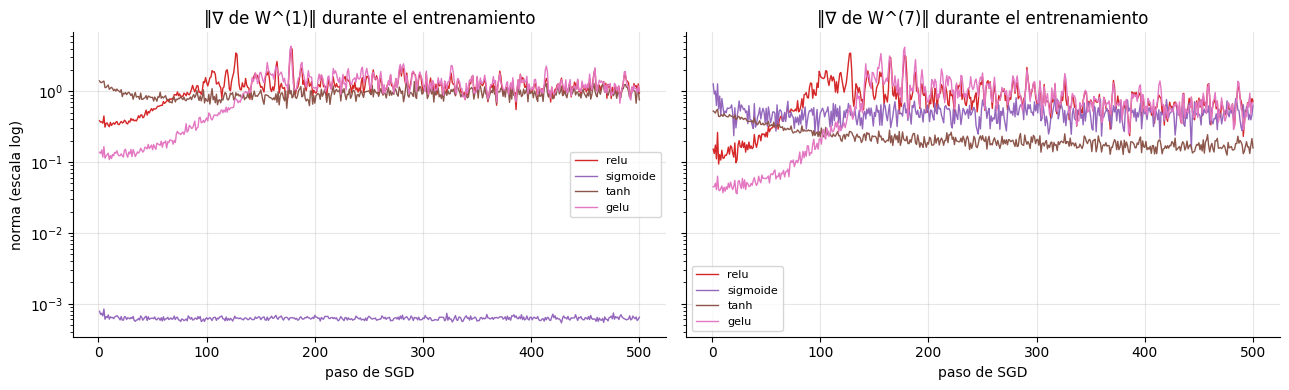

In [92]:
# medir_por_paso=True guardó ‖∇W^(l)‖ en cada paso. Miramos la capa 1 (junto
# a la entrada) y la 7 (la de salida): ¿la diferencia del inicio se mantiene?
capa_salida = len(CAPAS_S13) - 1
fig, ejes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, capa in zip(ejes, [1, capa_salida]):
    for nombre in ACTIVACIONES_S13:
        pp = CORRIDAS_S13[nombre].por_paso
        if pp is None:
            continue
        d = pp[(pp["capa"] == capa) & np.isfinite(pp["norma_grad"])]
        d = d[d["norma_grad"] > 0]                 # la escala log no admite 0
        ax.plot(d["paso"], d["norma_grad"], color=COLOR_ACT_S13[nombre],
                lw=1, label=nombre)
    ax.set_yscale("log")
    ax.set_xlabel("paso de SGD")
    ax.set_title(f"‖∇ de W^({capa})‖ durante el entrenamiento")
    ax.legend(fontsize=8)
ejes[0].set_ylabel("norma (escala log)")
plt.tight_layout()
plt.show()

**Compara la primera capa con la salida** en la misma escala logarítmica.
Busca si el gradiente de la sigmoide sigue bajo en la primera capa.
Cada batch puede producir picos. Fíjate en el nivel general de la curva.

<details><summary>Respuesta</summary>

**Sigmoide en ambas.** Tuvo el menor gradiente inicial en los pesos de la primera capa y la mayor loss final de validation.
La cota $(\tfrac14)^6$ corresponde a la señal inicial de preactivación.

</details>

- **La sigmoide se estancó.** Su loss llegó pronto a $\log 10$ y permaneció cerca. Su accuracy quedó cerca del azar.
- El gradiente de la primera capa de la sigmoide se mantuvo pequeño durante la corrida.
- ReLU, tanh y GELU llegaron a resultados similares. En otra corrida puede cambiar su orden.

## 14 · El gradiente por capa (avanzado)

Lectura opcional. Puedes seguir con la §15.
Con la red profunda de §13, comparamos **cómo cambian los gradientes y los pesos por capa**.
Con SGD probamos sigmoide, ReLU y ReLU con batch normalization (BN).
La sigmoide con Adam aparece en la tabla inicial y en los paneles de loss y cambio relativo.

La **norma de Frobenius** mide la magnitud del gradiente de los pesos en cada capa.
$\|\nabla_{\mathbf W^{(l)}}L_{\mathcal B}\|_F=\sqrt{\sum_{i,j}(\partial L_{\mathcal B}/\partial w_{ij}^{(l)})^2}$, donde $L_{\mathcal B}$ es la loss promedio del mini-batch.
En las curvas de loss, $\log 10$ marca la referencia uniforme.

In [93]:
# Tres redes profundas (6 ocultas de 128, SGD 0.03, init ortogonal, sesgos 0)
# que solo difieren en la activación y en batch normalization, y una cuarta,
# sigmoide con Adam, que solo se usa en la última gráfica (‖ΔW‖/‖W‖).
# medir_por_paso=True: en cada paso, entrenar guarda por capa la norma del
# gradiente y el cociente ‖ΔW‖/‖W‖ en corrida.por_paso.
PASOS_S14 = 600                    # ~1.5 epochs de 50k con batch 128
VARIANTES_S14 = {                  # ID → (activación, cambios a config_profunda)
    "s14-sigmoide": ("sigmoide", {}),
    "s14-relu": ("relu", {}),
    "s14-relu-bn": ("relu", {"batch_norm": True}),
    "s14-sigmoide-adam": ("sigmoide", {"optimizer": "adam", "lr": 1e-3}),
}
for id_, (act, cambios) in VARIANTES_S14.items():
    entrenar(config_profunda(
        act, id=id_, seccion=14, **cambios,
        epochs=2, max_pasos=PASOS_S14,       # se corta en el paso 600
        eval_cada_pasos=100,                 # un punto de las curvas cada 100 pasos
        medir_por_paso=True))
C14_TODAS = [CORRIDAS[i] for i in VARIANTES_S14]
C14 = C14_TODAS[:3]                          # las tres de SGD
display(tabla_maestra([14]))

s14-sigmoide: 184,330 parámetros · 600 pasos · mejor epoch 1.27877 · acc validation 0.109 · 1.7 s
s14-relu: 184,330 parámetros · 600 pasos · mejor epoch 1.53453 · acc validation 0.938 · 1.7 s
s14-relu-bn: 185,866 parámetros · 600 pasos · mejor epoch 1.53453 · acc validation 0.961 · 2.4 s
s14-sigmoide-adam: 184,330 parámetros · 600 pasos · mejor epoch 1.53453 · acc validation 0.910 · 2.3 s


,id,seccion,datos,parametros,mejor_epoch,pasos,ejemplos,acc_train,acc_validation,acc_test,loss_train,loss_validation,loss_test,brecha,segundos,divergio
0,s14-sigmoide,14,50k-limpio,184330,1.278772,500,63952,0.10350,0.1090,0.1028,2.301786,2.301962,2.302256,-0.00550,1.670717,False
1,s14-relu,14,50k-limpio,184330,1.534527,600,76752,0.93282,0.9380,0.9347,0.222803,0.207029,0.219757,-0.00518,1.744315,False
2,s14-relu-bn,14,50k-limpio,185866,1.534527,600,76752,0.96652,0.9609,0.9573,0.123905,0.141280,0.148390,0.00562,2.420028,False
3,s14-sigmoide-adam,14,50k-limpio,184330,1.534527,600,76752,0.90732,0.9098,0.9038,0.371903,0.362080,0.388493,-0.00248,2.271474,False


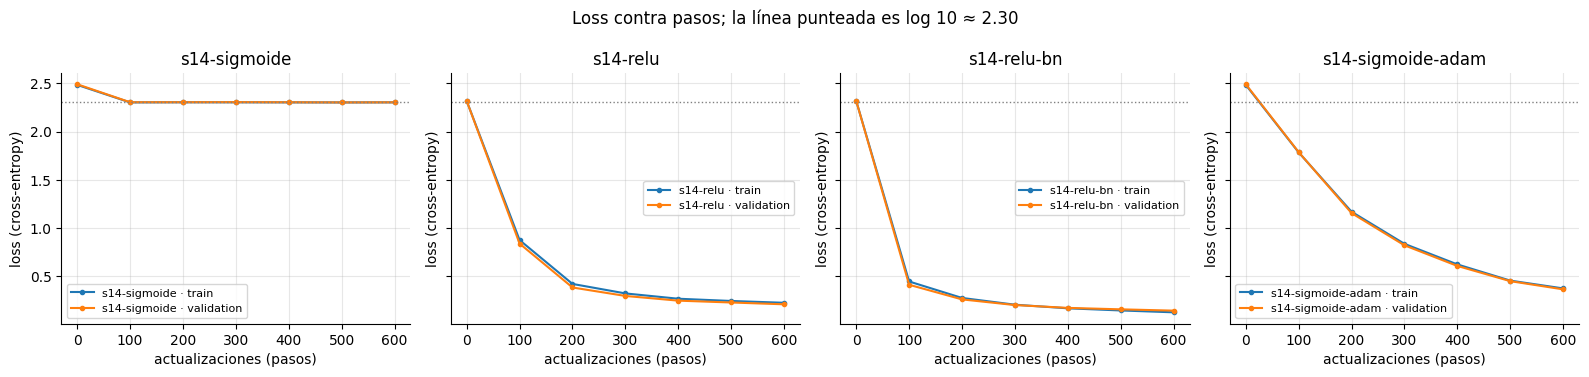

In [94]:
# Primero el contexto: ¿cuál aprendió algo en estos pasos?
# Solo train y validation; las decisiones nunca miran test.
fig, ejes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for corrida, ax in zip(C14_TODAS, ejes):
    curvas([corrida], x="pasos", metrica="loss",
           conjuntos=("train", "validation"), ax=ax, titulo=corrida.id)
    ax.axhline(np.log(10), color="gray", ls=":", lw=1)   # adivinar uniforme
ejes[0].set_ylabel("loss (cross-entropy)")
fig.suptitle("Loss contra pasos; la línea punteada es log 10 ≈ 2.30")
fig.tight_layout()
plt.show()

**Apuesta.** ¿Dónde será menor el gradiente con sigmoide, en la primera capa o en la salida?
Elige también una capa para ReLU o apuesta por normas parecidas.

<details><summary>Respuesta</summary>

**Con sigmoide, el gradiente es menor cerca de la entrada.** Cada pendiente aporta un factor de hasta $\tfrac14$.
Con ReLU, las neuronas activas dejan pasar su componente del gradiente y las normas quedan más parejas.

</details>

**Compara la primera capa con la salida** en los tres paneles de SGD.
La escala es logarítmica. La línea tenue muestra cada paso y la gruesa, una media móvil en escala logarítmica.
Sigue las líneas para ver cómo cambian las normas durante la corrida.

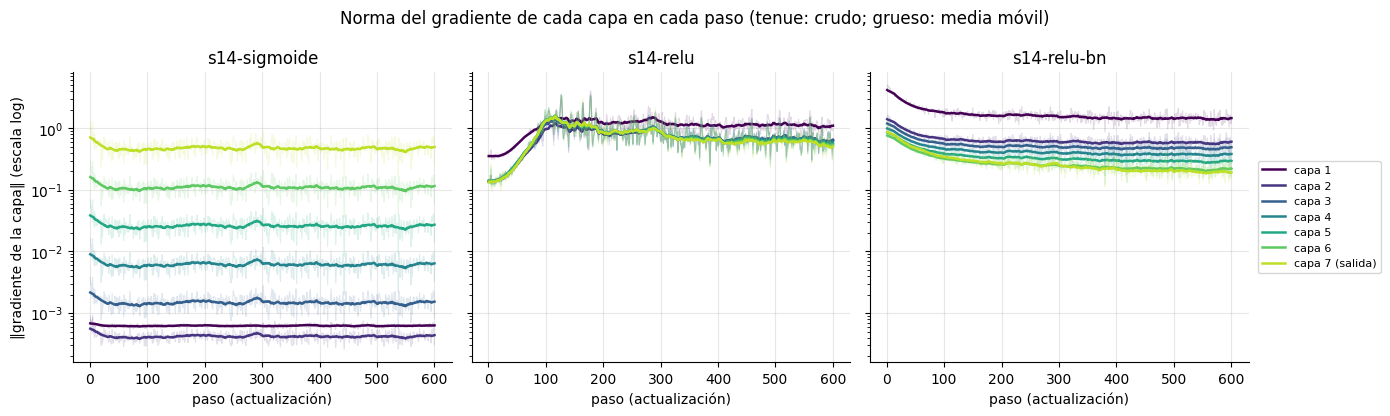

Mediana de ‖gradiente‖ por capa (filas: capa; columnas: corrida)


,s14-sigmoide,s14-relu,s14-relu-bn
capa 1,6.22e-04,1.13e+00,1.62e+00
capa 2,4.25e-04,7.11e-01,6.34e-01
capa 3,1.53e-03,7.30e-01,5.20e-01
capa 4,6.42e-03,7.30e-01,4.19e-01
capa 5,2.72e-02,7.07e-01,3.34e-01
capa 6,1.15e-01,6.93e-01,2.60e-01
capa 7,4.97e-01,7.02e-01,2.56e-01


In [95]:
def suavizar(valores, ventana):
    """Media móvil centrada del logaritmo: en escala log es la que no se
    deja jalar por un solo pico."""
    s = pd.Series(np.log10(valores))
    return 10 ** s.rolling(ventana, center=True, min_periods=1).mean().to_numpy()


def dibujar_por_capa(corrida, columna, ax):
    """Una línea por capa: la serie cruda tenue y la suavizada encima."""
    pp = corrida.por_paso
    pp = pp[np.isfinite(pp[columna]) & (pp[columna] > 0)]
    capas = list(dict.fromkeys(pp["capa"]))           # en el orden de la red
    tonos = plt.cm.viridis(np.linspace(0, 0.9, len(capas)))
    ventana = max(1, min(25, pp["paso"].nunique() // 10))
    for capa, tono in zip(capas, tonos):
        una = pp[pp["capa"] == capa].sort_values("paso")
        ax.plot(una["paso"], una[columna], color=tono, alpha=0.15, lw=0.8)
        ax.plot(una["paso"], suavizar(una[columna].to_numpy(), ventana),
                color=tono, lw=1.8, label=f"capa {capa}"
                + (" (salida)" if capa == capas[-1] else ""))
    ax.set_yscale("log")
    ax.set_xlabel("paso (actualización)")
    ax.set_title(corrida.id)


fig, ejes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for corrida, ax in zip(C14, ejes):
    dibujar_por_capa(corrida, "norma_grad", ax)
ejes[0].set_ylabel("‖gradiente de la capa‖ (escala log)")
ejes[-1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.suptitle("Norma del gradiente de cada capa en cada paso "
             "(tenue: crudo; grueso: media móvil)")
fig.tight_layout()
plt.show()

# Resumen numérico: mediana de la norma por capa en todo el entrenamiento.
resumen = pd.DataFrame({
    c.id: c.por_paso.groupby("capa", sort=False)["norma_grad"].median()
    for c in C14})
resumen.index = [f"capa {i}" for i in resumen.index]   # 7 = salida
print("Mediana de ‖gradiente‖ por capa (filas: capa; columnas: corrida)")
display(resumen.apply(lambda col: col.map("{:.2e}".format)))

- **Con sigmoide, el gradiente se desvanece hacia la entrada** y la loss sigue cerca de $\log 10$.
- Con ReLU sin BN, las normas suben al principio mientras baja la loss.
- Con ReLU y BN, las normas bajan desde el inicio. La primera capa queda por encima de la salida.

Con **los pesos congelados**, medimos los gradientes al inicio, a la mitad y al final.
$\mathbf g_{\mathrm{completo}}=\nabla_\theta L(\theta)$ usa todo train y $\mathbf g_{\mathcal B}=\nabla_\theta L_{\mathcal B}(\theta)$ usa un mini-batch.
La diferencia $\mathbf g_{\mathcal B}-\mathbf g_{\mathrm{completo}}$ es el ruido del gradiente.
Reutilizamos los mismos mini-batches. Con ReLU sin BN, el aporte de cada ejemplo es independiente de sus acompañantes.

In [96]:
# Misma configuración que s14-relu (sin BN), pero con un loop propio visible
# para guardar una copia de los pesos al inicio, a la mitad y al final.
import copy
import torch.nn.functional as F
cfg14 = CORRIDAS["s14-relu"].config
X14, y14 = DATOS[cfg14.escala]["train"]   # todo train (con RAPIDO ya viene recortado)
pasos14 = 30 if RAPIDO else PASOS_S14     # con RAPIDO, como el tope de entrenar
momentos14 = {"inicio": 0, "mitad": pasos14 // 2, "fin": pasos14}

torch.manual_seed(cfg14.semilla_init)        # mismos pesos iniciales cada vez
red14 = construir_red(cfg14.capas, cfg14.activacion, init=cfg14.init).to(DEVICE)
opt14 = torch.optim.SGD(red14.parameters(), lr=cfg14.lr)
gen14 = torch.Generator().manual_seed(cfg14.semilla_orden)
pesos14, paso, orden = {}, 0, torch.empty(0, dtype=torch.long)
while True:
    for nombre, p in momentos14.items():     # ¿toca guardar una copia?
        if p == paso:
            pesos14[nombre] = copy.deepcopy(red14.state_dict())
    if paso == pasos14:
        break
    if len(orden) == 0:                      # se acabó la epoch: nuevo orden
        orden = torch.randperm(len(y14), generator=gen14)
    lote, orden = orden[:cfg14.batch].to(DEVICE), orden[cfg14.batch:]
    red14.train()
    opt14.zero_grad()
    F.cross_entropy(red14(X14[lote]), y14[lote]).backward()
    opt14.step()
    paso += 1
print({m: f"paso {p}" for m, p in momentos14.items()}, "de", pasos14,
      "| ejemplos de train:", len(y14))

{'inicio': 'paso 0', 'mitad': 'paso 300', 'fin': 'paso 600'} de 600 | ejemplos de train: 50000


In [97]:
def gradiente(red, X, y, bloque=8192):
    """∇ de la loss promedio sobre (X, y), como un solo vector.
    Va por bloques: .grad acumula, y dividir cada suma entre n hace que la
    suma de los bloques sea exactamente el gradiente del promedio."""
    red.zero_grad(set_to_none=True)
    n, perdida = len(y), 0.0
    for i in range(0, n, bloque):
        l = F.cross_entropy(red(X[i:i + bloque]), y[i:i + bloque],
                            reduction="sum") / n
        l.backward()
        perdida += l.item()
    g = torch.cat([p.grad.flatten() for p in red.parameters()])
    return g.detach().clone(), perdida


N_LOTES14, TAM_LOTE14 = 32, 128
filas14, normas_lote14 = [], {}
for nombre, estado in pesos14.items():
    red14.load_state_dict(estado)            # la red congelada en ese momento
    g_todo, loss_todo = gradiente(red14, X14, y14)
    gen = torch.Generator().manual_seed(1)   # los mismos 32 lotes en cada momento
    normas, ruido = [], []
    for _ in range(N_LOTES14):
        lote = torch.randperm(len(y14), generator=gen)[:TAM_LOTE14].to(DEVICE)
        g_lote, _ = gradiente(red14, X14[lote], y14[lote])
        normas.append(g_lote.norm().item())
        ruido.append((g_lote - g_todo).norm().item())   # lo que no es señal
    normas_lote14[nombre] = np.array(normas)
    filas14.append({"momento": nombre, "paso": momentos14[nombre],
                    "loss_train": loss_todo, "‖g_completo‖": g_todo.norm().item(),
                    "mediana ‖g_B‖": np.median(normas),
                    "mediana ‖g_B − g‖": np.median(ruido)})
grad14 = pd.DataFrame(filas14).set_index("momento")
display(grad14.apply(lambda col: col.map("{:.3g}".format)))

,paso,loss_train,‖g_completo‖,mediana ‖g_B‖,mediana ‖g_B − g‖
momento,,,,,
inicio,0,2.32,0.337,0.53,0.408
mitad,300,0.365,2.33,2.77,1.73
fin,600,0.229,1.25,2.04,1.55


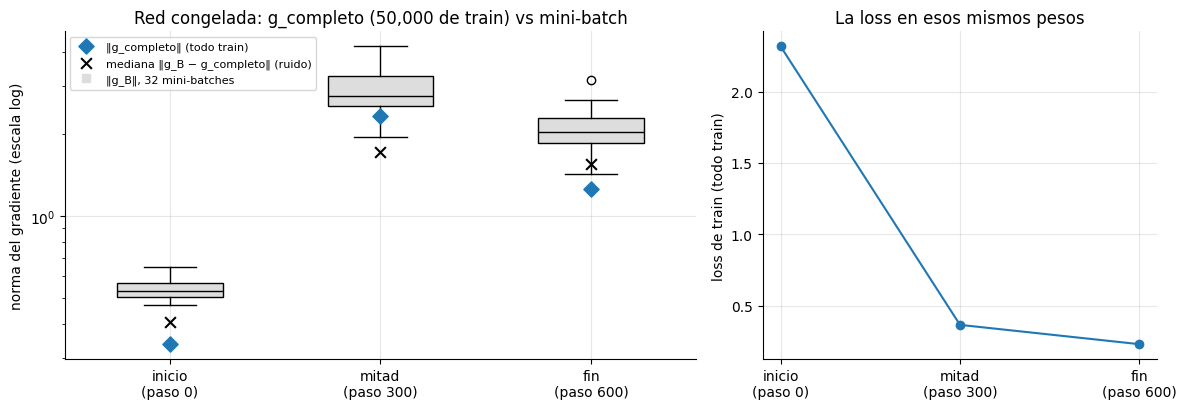

In [98]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2),
                             gridspec_kw={"width_ratios": [1.6, 1]})
pos = np.arange(len(grad14))
a1.boxplot([normas_lote14[m] for m in grad14.index], positions=pos, widths=0.5,
           patch_artist=True, boxprops={"facecolor": "#dddddd"},
           medianprops={"color": "black"})
a1.scatter(pos, grad14["‖g_completo‖"], marker="D", s=60, zorder=3,
           color=COLORES["train"], label="‖g_completo‖ (todo train)")
a1.scatter(pos, grad14["mediana ‖g_B − g‖"], marker="x", s=60, zorder=3,
           color="black", label="mediana ‖g_B − g_completo‖ (ruido)")
a1.plot([], [], "s", color="#dddddd", label=f"‖g_B‖, {N_LOTES14} mini-batches")
etiquetas = [f"{m}\n(paso {p})" for m, p in zip(grad14.index, grad14["paso"])]
a1.set_xticks(pos, etiquetas)
a1.set_yscale("log")
a1.set_ylabel("norma del gradiente (escala log)")
a1.set_title(f"Red congelada: g_completo ({len(y14):,} de train) vs mini-batch")
a1.legend(fontsize=8)
a2.plot(pos, grad14["loss_train"], "o-", color=COLORES["train"])
a2.set_xticks(pos, etiquetas)
a2.set_ylabel("loss de train (todo train)")
a2.set_title("La loss en esos mismos pesos")
fig.tight_layout()
plt.show()

- La loss de train fue menor en cada una de las tres mediciones.
- La norma del gradiente completo y la mediana de las normas de mini-batch subieron primero y luego bajaron.
- **El ruido fue comparable al gradiente completo.** Su norma mediana fue mayor al inicio y al final, y menor a mitad.

El **cambio relativo de los pesos** es $\|\mathbf W^{(l)}_{t+1}-\mathbf W^{(l)}_t\|_F/\|\mathbf W^{(l)}_t\|_F$.
En SGD sin momentum, el numerador es $\eta\|\nabla_{\mathbf W^{(l)}}L_{\mathcal B}\|_F$. Adam reescala el paso por parámetro.
Las dos redes con sigmoide parten de los mismos pesos. En Adam, el panel mide el paso efectivo del optimizer.
La línea gris en $10^{-3}$ sirve de referencia práctica.

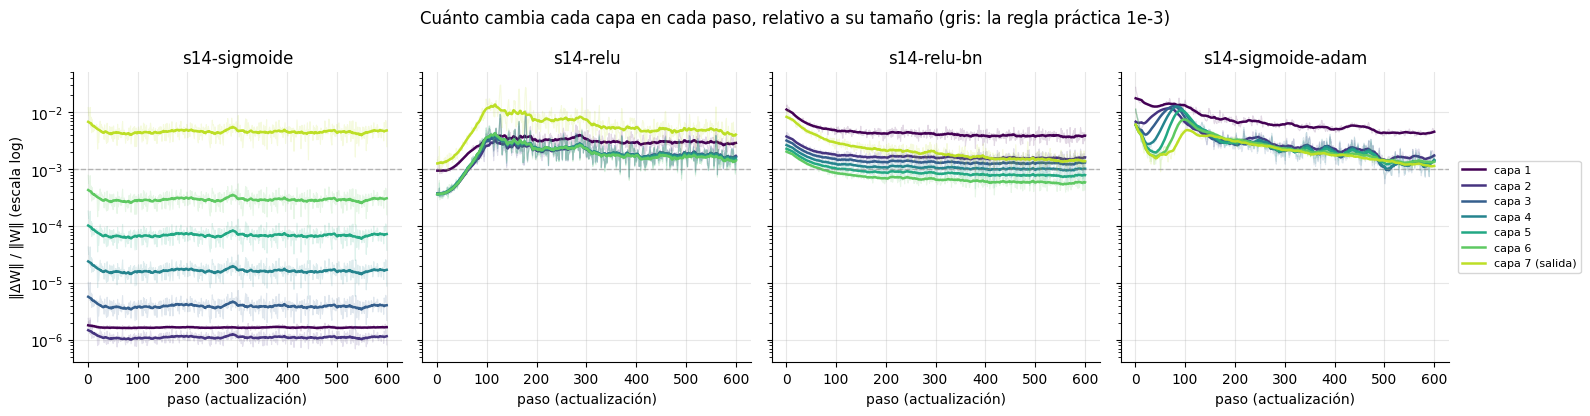

In [99]:
# Mismo dibujo que la norma, ahora con ‖W_{t+1} − W_t‖ / ‖W_t‖ por capa.
# El cuarto panel es la sigmoide con Adam: mismo gradiente que se desvanece,
# pero Adam divide cada paso entre la escala típica del gradiente de cada peso.
fig, ejes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
for corrida, ax in zip(C14_TODAS, ejes):
    dibujar_por_capa(corrida, "cociente_actualizacion", ax)
    ax.axhline(1e-3, color="gray", ls="--", lw=1, alpha=0.5)   # heurística
ejes[0].set_ylabel("‖ΔW‖ / ‖W‖ (escala log)")
ejes[-1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.suptitle("Cuánto cambia cada capa en cada paso, relativo a su tamaño "
             "(gris: la regla práctica 1e-3)")
fig.tight_layout()
plt.show()

- Con sigmoide y SGD, las primeras capas cambian mucho menos que la salida. Con ReLU, los cambios son más parejos.
- Hacia el final, **Adam mueve mucho más la primera capa de la sigmoide** que SGD en proporción a sus pesos.
- Con Adam también baja la loss de la sigmoide. Con SGD se queda cerca de la referencia uniforme.

## 15 · Batch normalization y dropout

**El modo de la red cambia el comportamiento de ambas capas.**
Batch normalization (BN) ajusta el centro y la escala de las preactivaciones. Dropout apaga activaciones al azar durante train.
Las métricas se calculan en `eval()`, incluidas las de train.

- Para cada neurona, BN usa la media $\mu_{\mathcal B,i}$ y la varianza $\sigma^2_{\mathcal B,i}$ del batch.
- **Estandariza la preactivación** con $\widetilde z_{k,i}=(z_{k,i}-\mu_{\mathcal B,i})/\sqrt{\sigma^2_{\mathcal B,i}+\varepsilon}$. El $\varepsilon$ evita dividir entre cero.
- Pasa $\gamma_i\widetilde z_{k,i}+\beta_i$ a la ReLU. Se aprenden $\gamma_i$ y $\beta_i$, que empiezan en $1$ y $0$.
- El orden es `Linear` → `BatchNorm1d` → `ReLU`. Cada BN agrega $2d_l$ parámetros aprendidos.

In [100]:
# Dónde va batch normalization: entre la capa lineal y la ReLU.
# Construimos la red de §13 (seis ocultas de 128) con y sin BN e imprimimos
# sus primeras capas para ver el orden de los módulos.
import copy
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd

BASE_PROFUNDA = config_profunda("relu", id="s15-muestra", seccion=15)
print("capas:", BASE_PROFUNDA.capas)

for con_bn in (False, True):
    red_muestra = construir_red(BASE_PROFUNDA.capas, "relu",
                                batch_norm=con_bn, init=BASE_PROFUNDA.init)
    print(f"\n--- batch_norm={con_bn}: los primeros 6 módulos de "
          f"{len(red_muestra)} ---")
    for i, modulo in enumerate(list(red_muestra)[:6]):
        print(f"  [{i}] {modulo}")

# γ (weight) y β (bias) de la primera BN: empiezan en 1 y en 0,
# así que al inicializar BN solo estandariza; luego γ y β se aprenden.
bn = next(m for m in red_muestra if isinstance(m, nn.BatchNorm1d))
print("\nγ inicial (primeros 5):", bn.weight.data[:5].tolist())
print("β inicial (primeros 5):", bn.bias.data[:5].tolist())
print("parámetros por capa de BN: 2 ×", bn.num_features,
      "(γ y β por neurona)")

capas: [784, 128, 128, 128, 128, 128, 128, 10]

--- batch_norm=False: los primeros 6 módulos de 13 ---
  [0] Linear(in_features=784, out_features=128, bias=True)
  [1] ReLU()
  [2] Linear(in_features=128, out_features=128, bias=True)
  [3] ReLU()
  [4] Linear(in_features=128, out_features=128, bias=True)
  [5] ReLU()

--- batch_norm=True: los primeros 6 módulos de 19 ---
  [0] Linear(in_features=784, out_features=128, bias=True)
  [1] BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  [2] ReLU()
  [3] Linear(in_features=128, out_features=128, bias=True)
  [4] BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  [5] ReLU()

γ inicial (primeros 5): [1.0, 1.0, 1.0, 1.0, 1.0]
β inicial (primeros 5): [0.0, 0.0, 0.0, 0.0, 0.0]
parámetros por capa de BN: 2 × 128 (γ y β por neurona)


Las redes comparten los pesos iniciales y el batch de train. En `train()`, BN usa las estadísticas de ese batch.
Un hook mide la media y la desviación estándar **justo antes de cada ReLU**.
Predice cómo cambiará la escala entre capas con BN y sin ella.

sin BN            con BN           
      media desviacion  media desviacion
capa                                    
1    -0.020      0.967   -0.0        1.0
2     0.015      0.672   -0.0        1.0
3     0.003      0.483   -0.0        1.0
4     0.001      0.342   -0.0        1.0
5     0.005      0.241    0.0        1.0
6    -0.000      0.175   -0.0        1.0

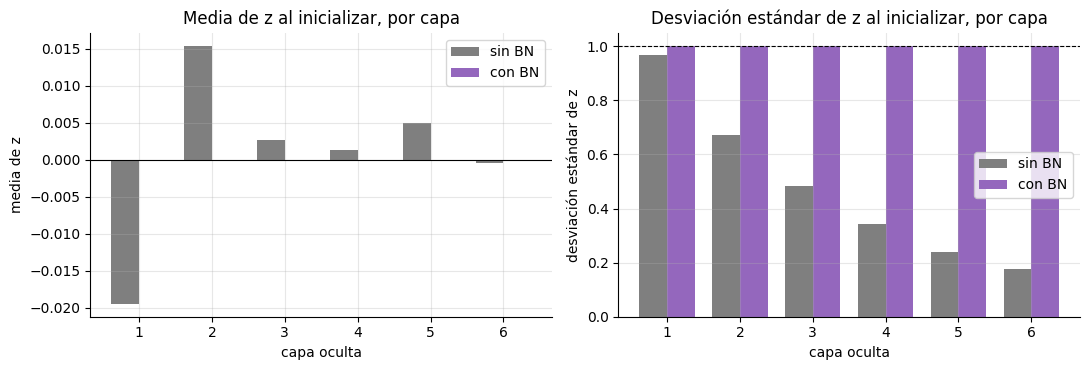

In [101]:
# Pre-activación z = lo que entra a cada ReLU, medida al inicializar,
# antes de cualquier paso de gradient descent. Un hook (gancho) es una
# función que PyTorch llama cada vez que un módulo recibe su entrada.
def preactivaciones(con_bn, n=1024):
    torch.manual_seed(BASE_PROFUNDA.semilla_init)    # mismos pesos iniciales
    red = construir_red(BASE_PROFUNDA.capas, "relu", batch_norm=con_bn,
                        init=BASE_PROFUNDA.init).to(DEVICE)
    red.train()          # como en el entrenamiento: BN usa las del batch
    medidas = []

    def gancho(modulo, entrada):
        z = entrada[0]                               # [n, 128]
        medidas.append((z.mean().item(), z.std().item()))

    relus = [m for m in red if isinstance(m, nn.ReLU)]
    ganchos = [m.register_forward_pre_hook(gancho) for m in relus]
    X = DATOS["estandar"]["train"][0][:n]
    with torch.no_grad():
        red(X)
    for g in ganchos:
        g.remove()                                   # no dejar ganchos vivos
    return pd.DataFrame(medidas, columns=["media", "desviacion"],
                        index=pd.RangeIndex(1, len(medidas) + 1, name="capa"))


PRE = {"sin BN": preactivaciones(False), "con BN": preactivaciones(True)}
display(pd.concat(PRE, axis=1).round(3))

COLOR_BN = {"sin BN": "#7f7f7f", "con BN": "#9467bd"}
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), dpi=100)
for ax, col, nombre in zip(ejes, ["media", "desviacion"],
                           ["Media de z", "Desviación estándar de z"]):
    for k, (etiqueta, df) in enumerate(PRE.items()):
        ax.bar(df.index + (k - 0.5) * 0.38, df[col], width=0.38,
               color=COLOR_BN[etiqueta], label=etiqueta)
    ax.set_xlabel("capa oculta")
    ax.set_ylabel(nombre.lower())
    ax.set_title(f"{nombre} al inicializar, por capa")
    ax.set_xticks(PRE["sin BN"].index)
    ax.legend()
ejes[0].axhline(0, color="black", lw=0.8)
ejes[1].axhline(1, color="black", lw=0.8, ls="--")
fig.tight_layout()
plt.show()

**Con BN, la media queda cerca de cero y la desviación estándar, cerca de uno** al inicializar.
Sin BN, la desviación estándar disminuye con la profundidad.
Al aprender $\gamma_i$ y $\beta_i$, cada neurona puede ajustar su escala y su centro.

**Apuesta.** ¿Con qué combinación bajará más rápido la loss? ¿Alguna podría divergir?
Elige entre learning rate bajo o alto, con o sin BN. Todas usan SGD sin momentum.

In [102]:
# Cuatro corridas: {sin BN, con BN} × {η = 0.03, η = 0.3}.
# Todo lo demás igual: red de §13 con ReLU, SGD sin momentum, batch 128,
# mismos pesos iniciales (semilla_init) y mismo orden de batches.
# Una corrida que diverge no truena: entrenar la marca y la detiene.
CORRIDAS_BN = {}
for lr, sufijo in [(0.03, "003"), (0.3, "03")]:
    for con_bn in (False, True):
        ident = f"s15-{'bn' if con_bn else 'sin-bn'}-{sufijo}"
        cfg = config_profunda("relu", id=ident, seccion=15, lr=lr,
                              batch_norm=con_bn, batch=128, epochs=5,
                              max_pasos=None, eval_cada_pasos=50)
        CORRIDAS_BN[ident] = entrenar(cfg)

for ident, c in CORRIDAS_BN.items():
    estado = (f"DIVERGIÓ en el paso {c.paso_no_finito}" if c.divergio
              else "terminó")
    print(f"{ident:14s} η={c.config.lr:<5} {estado}")

s15-sin-bn-003: 184,330 parámetros · 1955 pasos · mejor epoch 5 · acc validation 0.972 · 3.8 s
s15-bn-003: 185,866 parámetros · 1955 pasos · mejor epoch 5 · acc validation 0.973 · 6.1 s
s15-sin-bn-03: 184,330 parámetros · 1955 pasos · mejor epoch 5 · acc validation 0.977 · 3.7 s
s15-bn-03: 185,866 parámetros · 1955 pasos · mejor epoch 4.34783 · acc validation 0.980 · 6.4 s
s15-sin-bn-003 η=0.03  terminó
s15-bn-003     η=0.03  terminó
s15-sin-bn-03  η=0.3   terminó
s15-bn-03      η=0.3   terminó


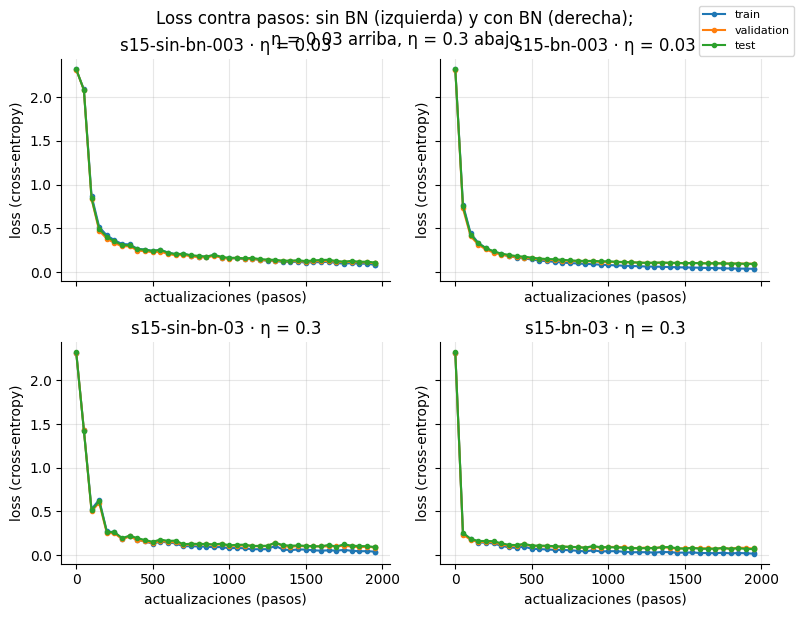

,seccion,datos,parametros,mejor_epoch,pasos,ejemplos,acc_train,acc_validation,acc_test,loss_train,loss_validation,loss_test,brecha,segundos,divergio
id,,,,,,,,,,,,,,,
s15-sin-bn-003,15,50k-limpio,184330,5.000000,1955,250000,0.97594,0.9720,0.9656,0.082547,0.100585,0.107849,0.00394,3.817490,False
s15-bn-003,15,50k-limpio,185866,5.000000,1955,250000,0.99090,0.9733,0.9702,0.037696,0.093919,0.095033,0.01760,6.149433,False
s15-sin-bn-03,15,50k-limpio,184330,5.000000,1955,250000,0.98866,0.9771,0.9746,0.038300,0.083114,0.090862,0.01156,3.738542,False
s15-bn-03,15,50k-limpio,185866,4.347826,1700,217408,0.99392,0.9796,0.9784,0.021112,0.072759,0.072707,0.01432,6.400143,False


In [103]:
# Small multiples: filas = learning rate, columnas = sin/con BN; mismos ejes.
orden = ["s15-sin-bn-003", "s15-bn-003", "s15-sin-bn-03", "s15-bn-03"]
fig = rejilla([CORRIDAS_BN[i] for i in orden], x="pasos", metrica="loss",
              columnas=2, misma_y=True)
for ax, i in zip(fig.axes, orden):       # el título dice si divergió
    c = CORRIDAS_BN[i]
    aviso = f" · DIVERGIÓ (paso {c.paso_no_finito})" if c.divergio else ""
    ax.set_title(f"{i} · η = {c.config.lr}{aviso}",
                 color="crimson" if c.divergio else "black")
fig.suptitle("Loss contra pasos: sin BN (izquierda) y con BN (derecha);\n"
             "η = 0.03 arriba, η = 0.3 abajo", y=1.02)
plt.show()

tabla = tabla_maestra([15])
display(tabla[tabla["id"].isin(orden)].set_index("id").loc[orden])

**Compara con y sin BN dentro de cada fila.** Arriba está el learning rate menor y abajo el mayor.
Sigue el descenso de la loss de validation y busca oscilaciones.
Test se reporta una sola vez, al final. Aquí se grafica para practicar. El checkpoint se elige con validation.

<details><summary>Respuesta</summary>

**Con el learning rate mayor, la loss bajó más rápido con BN.**
Con el paso menor, las dos curvas bajaron a ritmos parecidos.
Las cuatro corridas terminaron. En otra corrida, la red sin BN puede oscilar más o divergir con un paso grande.

</details>

**En `eval()`, BN usa las estadísticas guardadas.** En `train()`, usa las del batch y actualiza sus running averages.
La actualización es $r\leftarrow(1-m)r+mv$, con $m$ el momentum de BN y $v$ la estimación del batch.
Con el mismo checkpoint, compara los logits de una imagen al cambiar las imágenes que la acompañan.
En `train()`, `BatchNorm1d` exige más de una observación para esta entrada.

In [104]:
# La misma imagen, sola y acompañada de dos batches distintos.
# En eval() BN usa sus promedios corridos: la salida no depende del batch.
# En train() usa la media y varianza del batch: la salida sí depende.
red_bn = cargar(CORRIDAS_BN["s15-bn-003"])          # en eval()
primera_bn = next(m for m in red_bn if isinstance(m, nn.BatchNorm1d))
print("promedios corridos de la 1.ª BN (primeras 3 neuronas):")
print("  media   :", primera_bn.running_mean[:3].tolist())
print("  varianza:", primera_bn.running_var[:3].tolist())

Xv = DATOS["estandar"]["validation"][0]
x0 = Xv[:1]                                          # una sola imagen [1, 784]
lote_a = torch.cat([x0, Xv[1:64]])                   # x0 + 63 imágenes
lote_b = torch.cat([x0, Xv[64:127]])                 # x0 + otras 63

with torch.no_grad():
    sola = red_bn(x0)[0]
    en_a, en_b = red_bn(lote_a)[0], red_bn(lote_b)[0]
    print("\neval(): diferencia máxima entre los logits de x0")
    print(f"  sola vs lote A: {(sola - en_a).abs().max().item():.2e}")
    print(f"  lote A vs lote B: {(en_a - en_b).abs().max().item():.2e}")

    red_tr = copy.deepcopy(red_bn).train()           # copia: no tocar la original
    en_a, en_b = red_tr(lote_a)[0], red_tr(lote_b)[0]
    print("train(): diferencia máxima entre los logits de x0")
    print(f"  lote A vs lote B: {(en_a - en_b).abs().max().item():.2e}")
    try:
        red_tr(x0)
    except ValueError as error:                       # batch de 1: no hay varianza
        print("  sola, en train():", str(error).split(",")[0])

promedios corridos de la 1.ª BN (primeras 3 neuronas):
  media   : [0.051143430173397064, -0.0378645695745945, 0.41232240200042725]
  varianza: [1.474808931350708, 1.5233139991760254, 1.5774515867233276]

eval(): diferencia máxima entre los logits de x0
  sola vs lote A: 4.77e-07
  lote A vs lote B: 0.00e+00
train(): diferencia máxima entre los logits de x0
  lote A vs lote B: 2.67e+00
  sola, en train(): Expected more than 1 value per channel when training


En `train()`, **dropout apaga cada activación con probabilidad $p$** y multiplica las restantes por $1/(1-p)$.
Así conserva su valor esperado, $\mathbb E[\widetilde a]=(1-p)\frac{a}{1-p}=a$.
En `eval()`, las activaciones pasan intactas. En esta red, `Dropout` va después de cada ReLU oculta.

In [105]:
# Dropout sobre un vector de unos, con p = 0.4.
# train(): cada componente se apaga (0) con probabilidad p, y las que
# sobreviven se multiplican por 1/(1 − p) para que el promedio no cambie.
# eval(): dropout no hace nada.
torch.manual_seed(SEMILLA)
capa = nn.Dropout(p=0.4)
unos = torch.ones(10)
print(f"1/(1 − p) = {1 / (1 - 0.4):.4f}")
capa.train()
for vez in range(3):
    print(f"train(), vez {vez + 1}:", capa(unos).numpy().round(3))
grande = capa(torch.ones(100_000))
print(f"train(), promedio sobre 100 000 unos: {grande.mean().item():.4f}")
capa.eval()
print("eval():          ", capa(unos).numpy().round(3))

# Dónde queda dropout en la red: después de cada ReLU oculta.
print(construir_red([784, 256, 256, 10], "relu", dropout=0.4))

1/(1 − p) = 1.6667
train(), vez 1: [0.    0.    1.667 0.    0.    0.    1.667 1.667 1.667 1.667]
train(), vez 2: [1.667 1.667 1.667 0.    1.667 1.667 1.667 1.667 0.    0.   ]
train(), vez 3: [1.667 0.    1.667 1.667 1.667 1.667 1.667 0.    0.    1.667]
train(), promedio sobre 100 000 unos: 0.9989
eval():           [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Sequential(
  (0): Linear(in_features=784, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.4, inplace=False)
  (3): Linear(in_features=256, out_features=256, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.4, inplace=False)
  (6): Linear(in_features=256, out_features=10, bias=True)
)


In [106]:
# Control sin dropout = la corrida de §10 (2000 ejemplos, 20 % de etiquetas
# cambiadas, validation limpia). Con dropout: la MISMA configuración,
# solo dropout = 0.4. Las dos se evalúan en eval(), sin dropout.
import dataclasses
BASE_CONTROL = dict(capas=[784, 256, 256, 10], activacion="relu",
                    optimizer="adam", lr=1e-3, batch=64, epochs=80,
                    idx_train=subconjunto(2000), ruido_etiquetas=0.2,
                    datos="2k-ruido20")
if "s10-control" in CORRIDAS:
    control = CORRIDAS["s10-control"]
    print("Uso la corrida s10-control que entrenó la sección 10.")
else:
    print("No encontré s10-control (¿no corriste la sección 10?): "
          "la entreno aquí con la misma configuración de §10.")
    control = entrenar(Config(id="s10-control", seccion=10, **BASE_CONTROL))

# replace copia la Config del control y cambia solo lo que se indica.
con_dropout = entrenar(dataclasses.replace(control.config, id="s15-dropout",
                                           seccion=15, dropout=0.4))

Uso la corrida s10-control que entrenó la sección 10.
s15-dropout: 269,322 parámetros · 2560 pasos · mejor epoch 16 · acc validation 0.901 · 4.7 s


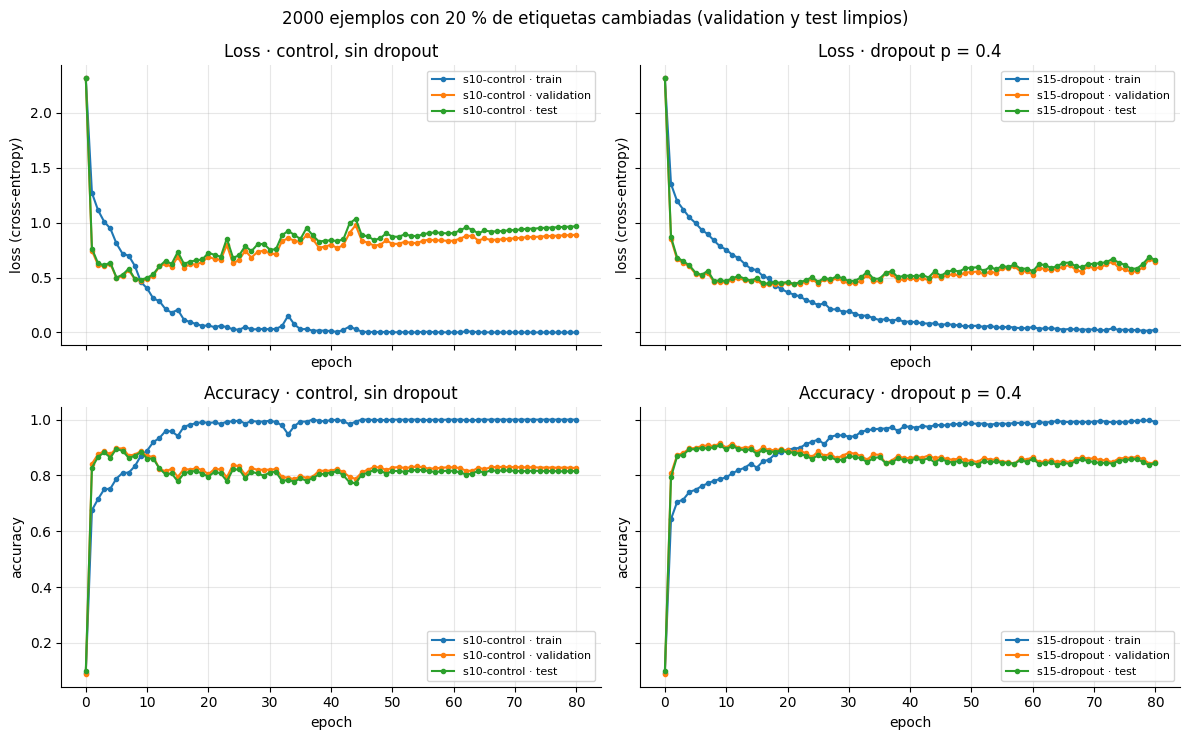

In [107]:
# Lado a lado, con el mismo eje y: arriba loss, abajo accuracy.
fig, ejes = plt.subplots(2, 2, figsize=(12, 7.5), dpi=100,
                         sharey="row", sharex=True)
for col, (c, nombre) in enumerate([(control, "control, sin dropout"),
                                   (con_dropout, "dropout p = 0.4")]):
    curvas([c], x="epoch", metrica="loss", ax=ejes[0, col],
           titulo=f"Loss · {nombre}")
    curvas([c], x="epoch", metrica="accuracy", ax=ejes[1, col],
           titulo=f"Accuracy · {nombre}")
fig.suptitle("2000 ejemplos con 20 % de etiquetas cambiadas "
             "(validation y test limpios)")
fig.tight_layout()
plt.show()

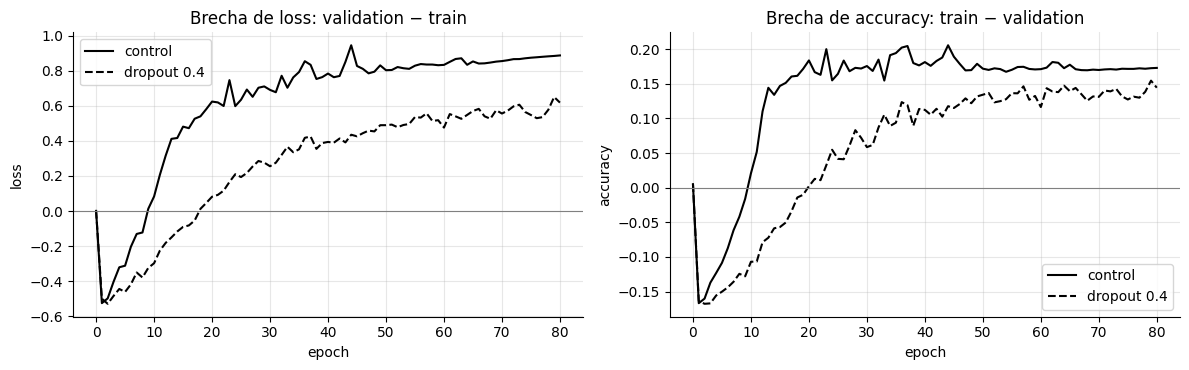

,mejor_epoch,ultima_epoch,acc_train_ultima,acc_val_ultima,loss_val_ultima,brecha_acc_ultima,repite_falsa
id,,,,,,,
s10-control,9,80,1.0000,0.8270,0.8890,0.1730,1.0000
s15-dropout,16,80,0.9925,0.8481,0.6416,0.1444,0.9625


,id,seccion,datos,parametros,mejor_epoch,pasos,ejemplos,acc_train,acc_validation,acc_test,loss_train,loss_validation,loss_test,brecha,segundos,divergio
0,s10-control,10,2k-ruido20,269322,9.0,288,18000,0.8710,0.8871,0.8833,0.458271,0.471029,0.481787,-0.0161,4.662207,False
6,s15-dropout,15,2k-ruido20,269322,16.0,512,32000,0.8505,0.9008,0.8921,0.511742,0.429377,0.445888,-0.0503,4.733174,False


In [108]:
# Brecha por epoch. Con loss: validation − train (crece si memoriza).
# Con accuracy: train − validation. Ojo: la accuracy de train se mide
# contra las etiquetas alteradas, así que puede quedar por debajo de
# validation (brecha negativa) mientras la red no memoriza el ruido.
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8), dpi=100)
for c, nombre, estilo in [(control, "control", "-"),
                          (con_dropout, "dropout 0.4", "--")]:
    h = c.historial
    ejes[0].plot(h["epoch"], h["loss_validation"] - h["loss_train"],
                 ls=estilo, color="black", label=nombre)
    ejes[1].plot(h["epoch"], h["acc_train"] - h["acc_validation"],
                 ls=estilo, color="black", label=nombre)
ejes[0].set_title("Brecha de loss: validation − train")
ejes[1].set_title("Brecha de accuracy: train − validation")
for ax in ejes:
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xlabel("epoch")
    ax.legend()
ejes[0].set_ylabel("loss")
ejes[1].set_ylabel("accuracy")
fig.tight_layout()
plt.show()

# Resumen en la última epoch. «repite_falsa»: de los ejemplos de train con
# etiqueta alterada, qué fracción predice la red con la etiqueta FALSA
# (memorizar el ruido). La mejor epoch por validation está en la tabla maestra.
filas = []
for c in (control, con_dropout):
    X_tr, y_ruido = datos_de_entrenamiento(c.config)   # etiquetas alteradas
    sin_ruido = dataclasses.replace(c.config, ruido_etiquetas=0.0)
    y_limpia = datos_de_entrenamiento(sin_ruido)[1]     # las mismas, limpias
    alterada = y_ruido != y_limpia
    with torch.no_grad():
        pred = cargar(c, "ultima")(X_tr).argmax(1)
    u = c.historial.iloc[-1]
    filas.append({"id": c.id, "mejor_epoch": c.mejor_epoch,
                  "ultima_epoch": u["epoch"],
                  "acc_train_ultima": u["acc_train"],
                  "acc_val_ultima": u["acc_validation"],
                  "loss_val_ultima": u["loss_validation"],
                  "brecha_acc_ultima": u["acc_train"] - u["acc_validation"],
                  "repite_falsa": (pred[alterada] == y_ruido[alterada])
                  .float().mean().item()})
display(pd.DataFrame(filas).set_index("id").round(4))
tabla = tabla_maestra([10, 15])
display(tabla[tabla["id"].isin(["s10-control", "s15-dropout"])])

- Ambas redes entrenan 80 epochs con un 20 % de etiquetas alteradas en train.
- **La loss de validation del control subió tras su mínimo.** Con dropout, el repunte fue posterior y menor.
- Al final, `repite_falsa` fue mayor en el control. Mide la fracción de etiquetas alteradas que reproduce cada red.
- La comparación de etiquetas ocurre al final y deja abierto cuándo empezó la memorización.

In [109]:
# La misma imagen, cinco veces, por la red entrenada con dropout.
red_do = cargar(con_dropout, "ultima")              # cargar la deja en eval()
x0 = DATOS["estandar"]["validation"][0][:1]
y0 = DATOS["estandar"]["validation"][1][0].item()
torch.manual_seed(SEMILLA)
with torch.no_grad():
    for modo in ("train", "eval"):
        red_do.train(modo == "train")
        print(f"{modo}(): probabilidad de la clase real ({y0}) y predicción")
        for vez in range(5):
            p = torch.softmax(red_do(x0)[0], dim=0)
            print(f"  vez {vez + 1}: p = {p[y0].item():.4f}, "
                  f"predice {p.argmax().item()}")
red_do.eval()

train(): probabilidad de la clase real (3) y predicción
  vez 1: p = 0.9989, predice 3
  vez 2: p = 1.0000, predice 3
  vez 3: p = 0.9992, predice 3
  vez 4: p = 1.0000, predice 3
  vez 5: p = 0.9912, predice 3
eval(): probabilidad de la clase real (3) y predicción
  vez 1: p = 1.0000, predice 3
  vez 2: p = 1.0000, predice 3
  vez 3: p = 1.0000, predice 3
  vez 4: p = 1.0000, predice 3
  vez 5: p = 1.0000, predice 3


Sequential(
  (0): Linear(in_features=784, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.4, inplace=False)
  (3): Linear(in_features=256, out_features=256, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.4, inplace=False)
  (6): Linear(in_features=256, out_features=10, bias=True)
)

- En `train()`, con BN cambiaron los logits al cambiar las imágenes acompañantes. Con dropout varió la probabilidad del dígito real.
- **`model.eval()` hizo repetibles los logits y las probabilidades.** BN usó estadísticas guardadas y dropout dejó pasar todas las activaciones.
- Con dropout, las brechas finales de loss y accuracy fueron menores. En otra corrida, la diferencia puede ser más pequeña.

## 16 · Análisis del error

Comparamos MLP de §4–15 que terminaron sin divergir, configurados con los 50 000 ejemplos de train y etiquetas originales.
Algunos agotaron el presupuesto antes de completar la primera epoch.
**Gana el checkpoint con mayor accuracy de validation** entre los elegidos por menor loss de validation en cada corrida.
Si faltan candidatos, entrenamos la línea base de §4. El ganador queda en `CORRIDAS["s16-elegido"]`.
Explora los errores en validation y reserva test para el reporte final.

In [110]:
# 1) Candidatos comparables: mismos datos (50k de train, etiquetas limpias),
#    un MLP de construir_red (modelo is None) con al menos una capa oculta
#    (la regresión logística [784, 10] no es un MLP), de §4–§15, sin divergir.
def acc_val_en_mejor_epoch(c):
    """Accuracy de validation en la epoch que eligió la propia corrida."""
    h = c.historial
    fila = h[h["epoch"] == c.mejor_epoch]
    if len(fila) == 0:            # por si la epoch no tiene fila exacta
        return float("nan")
    return float(fila["acc_validation"].iloc[-1])


candidatos = {
    clave: c for clave, c in CORRIDAS.items()
    if clave != "s16-elegido"                  # no nos elegimos a nosotros mismos
    and c.config.datos == "50k-limpio"
    and c.config.modelo is None
    and len(c.config.capas) > 2                # al menos una capa oculta
    and c.config.seccion <= 15
    and c.config.idx_train is None and c.config.ruido_etiquetas == 0.0
    and not c.divergio
}

if not candidatos:
    # Saltaste secciones: entrenamos la línea base de §4 y lo decimos.
    print("No hay corridas comparables en CORRIDAS: entreno la línea base "
          "s04-oculta (784→128→10, ReLU, Adam 1e-3, 8 epochs).")
    base = entrenar(Config(id="s04-oculta", seccion=4, capas=[784, 128, 10],
                           activacion="relu", optimizer="adam", lr=1e-3,
                           epochs=8))
    candidatos = {base.id: base}

# 2) Tabla de candidatos ordenada SOLO por validation (ninguna columna de test).
filas = [{"id": clave, "seccion": c.config.seccion,
          "capas": str(c.config.capas), "optimizer": c.config.optimizer,
          "mejor_epoch": c.mejor_epoch,
          "acc_validation": acc_val_en_mejor_epoch(c)}
         for clave, c in candidatos.items()]
ranking = (pd.DataFrame(filas)
           .sort_values("acc_validation", ascending=False, na_position="last")
           .reset_index(drop=True))
display(ranking.head(10))

# 3) El ganador: la primera fila. Se publica para §17 y §18.
ELEGIDO_ID = ranking.loc[0, "id"]
ELEGIDO = candidatos[ELEGIDO_ID]
CORRIDAS["s16-elegido"] = ELEGIDO       # el mismo objeto, con otro nombre
print(f"Elegido por validation: {ELEGIDO_ID}  (capas {ELEGIDO.config.capas}, "
      f"epoch {ELEGIDO.mejor_epoch}, "
      f"acc_validation {ranking.loc[0, 'acc_validation']:.4f})")

,id,seccion,capas,optimizer,mejor_epoch,acc_validation
0,s15-bn-03,15,"[784, 128, 128, 128, 128, 128, 128, 10]",sgd,4.347826,0.9796
1,s09-adam-sin,9,"[784, 256, 10]",adam,5.000000,0.9779
2,s09-adamw-wd,9,"[784, 256, 10]",adamw,5.000000,0.9776
3,s15-sin-bn-03,15,"[784, 128, 128, 128, 128, 128, 128, 10]",sgd,5.000000,0.9771
4,s09-momentum,9,"[784, 128, 10]",momentum,5.000000,0.9765
5,s09-adam,9,"[784, 128, 10]",adam,5.000000,0.9760
6,s04-oculta,4,"[784, 128, 10]",adam,5.000000,0.9760
7,s09-adamw,9,"[784, 128, 10]",adamw,5.000000,0.9750
8,s15-bn-003,15,"[784, 128, 128, 128, 128, 128, 128, 10]",sgd,5.000000,0.9733
9,s15-sin-bn-003,15,"[784, 128, 128, 128, 128, 128, 128, 10]",sgd,5.000000,0.9720


Elegido por validation: s15-bn-03  (capas [784, 128, 128, 128, 128, 128, 128, 10], epoch 4.3478260869565215, acc_validation 0.9796)


In [111]:
# Restauramos el checkpoint de la MEJOR epoch (no el de la última) y sacamos
# las probabilidades de cada clase para todo un conjunto.
modelo_16 = cargar(ELEGIDO, "mejor")     # en DEVICE y en modo eval()


@torch.no_grad()
def probabilidades(modelo, escala, conjunto, bloque=4096):
    """Devuelve (P [n,10], y [n]) en CPU como numpy. P = softmax(logits)."""
    X, y = DATOS[escala][conjunto]
    partes = []
    for i in range(0, len(X), bloque):
        logits = modelo(X[i:i + bloque])          # [b, 10]
        partes.append(torch.softmax(logits, dim=1).cpu())
    return torch.cat(partes).numpy(), y.cpu().numpy()


ESCALA_16 = ELEGIDO.config.escala        # la misma escala con la que se entrenó
P_val, y_val = probabilidades(modelo_16, ESCALA_16, "validation")
pred_val = P_val.argmax(axis=1)          # la clase predicha: el argmax
conf_val = P_val.max(axis=1)             # su «confianza»: la probabilidad mayor
acierto_val = pred_val == y_val
print(f"validation: {len(y_val)} imágenes, accuracy {acierto_val.mean():.4f}, "
      f"errores {(~acierto_val).sum()}")

validation: 10000 imágenes, accuracy 0.9796, errores 204


**Apuesta.** Anota dos confusiones frecuentes que esperas ver (real → predicho).
¿Esperas la misma frecuencia para 4 → 9 y 9 → 4, o frecuencias distintas?

En la matriz, **fila real, columna predicha**. La casilla $C_{ij}$ cuenta las imágenes de $i$ predichas como $j$.
- Izquierda. La diagonal cuenta aciertos. Fuera de ella están los errores.
- Derecha. Cada fila suma $100\,\%$ antes de redondear. La suma visible puede quedar un poco arriba o abajo.
- La diagonal de la matriz normalizada da el recall por dígito.

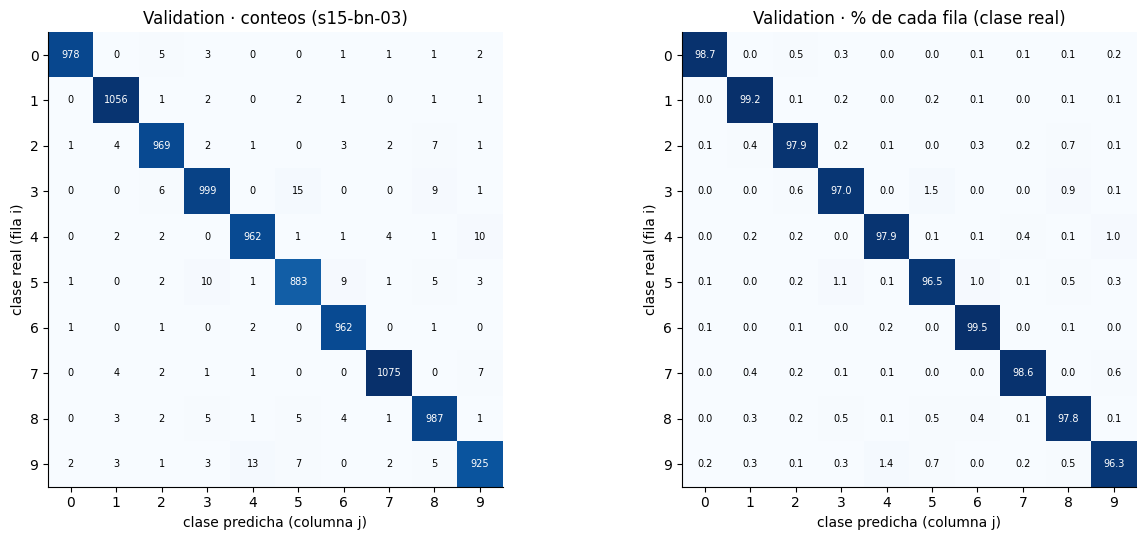

suma de la matriz de validation: 10000


In [112]:
DIGITOS = np.arange(10)


def matriz_confusion(y, pred, k=10):
    """C[i, j] = cuántas imágenes de clase real i se predijeron como j."""
    C = np.zeros((k, k), dtype=int)
    np.add.at(C, (y, pred), 1)
    return C


def dibujar_confusion(C, ax, titulo, normalizar=False):
    """Mapa de calor rotulado: filas = clase real, columnas = clase predicha."""
    # Normalizada: en % de la fila, con un decimal (0.3 % no se vuelve 0.00).
    M = 100 * C / C.sum(axis=1, keepdims=True) if normalizar else C
    ax.imshow(M, cmap="Blues", vmin=0, vmax=M.max())
    for i in range(10):
        for j in range(10):
            txt = f"{M[i, j]:.1f}" if normalizar else f"{M[i, j]}"
            color = "white" if M[i, j] > 0.6 * M.max() else "black"
            ax.text(j, i, txt, ha="center", va="center", fontsize=7, color=color)
    ax.set_xticks(DIGITOS)
    ax.set_yticks(DIGITOS)
    ax.set_xlabel("clase predicha (columna j)")
    ax.set_ylabel("clase real (fila i)")
    ax.set_title(titulo)
    ax.grid(False)


C_val = matriz_confusion(y_val, pred_val)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.5))
dibujar_confusion(C_val, a1, f"Validation · conteos ({ELEGIDO_ID})")
dibujar_confusion(C_val, a2, "Validation · % de cada fila (clase real)",
                  normalizar=True)
fig.tight_layout()
plt.show()
print("suma de la matriz de validation:", C_val.sum())

<details><summary>Respuesta</summary>

**Las confusiones tienen dirección.** Predominó 3 → 5 y fue más común 9 → 4 que 4 → 9.
En otra corrida pueden destacar otros pares. Compara las dos direcciones en la tabla debajo de las métricas.

</details>

**Cada dígito se compara con el resto**, como en la unidad 9.
- Precision es la fracción correcta de la columna $j$, $C_{jj}/\sum_i C_{ij}$.
- Recall es la fracción correcta de la fila $j$, $C_{jj}/\sum_i C_{ji}$.
- F1 combina ambas, $F_1=2\,\frac{\mathrm{precision}\cdot\mathrm{recall}}{\mathrm{precision}+\mathrm{recall}}$.
- El soporte cuenta los ejemplos reales. Revisa dónde empieza el eje antes de comparar las barras.

,digito,soporte,precision,recall,F1
0,0,991,0.9949,0.9869,0.9909
1,1,1064,0.9851,0.9925,0.9888
2,2,990,0.9778,0.9788,0.9783
3,3,1030,0.9746,0.9699,0.9723
4,4,983,0.9806,0.9786,0.9796
5,5,915,0.9671,0.9650,0.9661
6,6,967,0.9806,0.9948,0.9877
7,7,1090,0.9899,0.9862,0.9881
8,8,1009,0.9705,0.9782,0.9743
9,9,961,0.9727,0.9625,0.9676


dígito con menor F1 en validation: 5 (precision 0.967, recall 0.965)


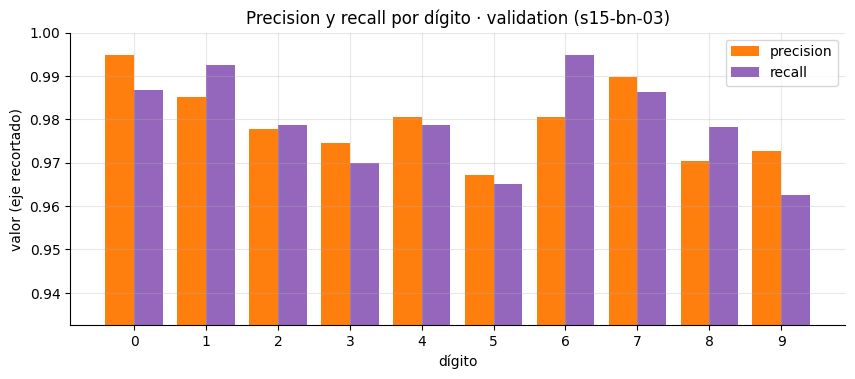

In [113]:
def metricas_por_clase(C):
    """precision, recall y F1 de cada dígito, uno contra el resto."""
    vp = np.diag(C)                         # verdaderos positivos
    predichos = C.sum(axis=0)               # columna: todo lo que dije «es j»
    reales = C.sum(axis=1)                  # fila: todo lo que de verdad es j
    precision = vp / np.maximum(predichos, 1)
    recall = vp / np.maximum(reales, 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return pd.DataFrame({"digito": DIGITOS, "soporte": reales,
                         "precision": precision, "recall": recall, "F1": f1})


metricas_val = metricas_por_clase(C_val)
display(metricas_val.round(4))
peor = metricas_val.loc[metricas_val["F1"].idxmin()]
print(f"dígito con menor F1 en validation: {int(peor['digito'])} "
      f"(precision {peor['precision']:.3f}, recall {peor['recall']:.3f})")

fig, ax = plt.subplots(figsize=(10, 3.8))
ancho = 0.4
ax.bar(DIGITOS - ancho / 2, metricas_val["precision"], ancho,
       label="precision", color=COLORES["validation"])
ax.bar(DIGITOS + ancho / 2, metricas_val["recall"], ancho,
       label="recall", color="#9467bd")
piso = max(0.0, min(metricas_val["precision"].min(),
                    metricas_val["recall"].min()) - 0.03)
ax.set_ylim(piso, 1.0)                  # eje recortado: las diferencias son chicas
ax.set_xticks(DIGITOS)
ax.set_xlabel("dígito")
ax.set_ylabel("valor (eje recortado)")
ax.set_title(f"Precision y recall por dígito · validation ({ELEGIDO_ID})")
ax.legend()
plt.show()

,real,predicho,casos,% de la clase real
0,3,5,15,1.46
1,9,4,13,1.35
2,4,9,10,1.02
3,5,3,10,1.09
4,3,8,9,0.87
5,5,6,9,0.98
6,9,5,7,0.73
7,7,9,7,0.64
8,2,8,7,0.71
9,3,2,6,0.58


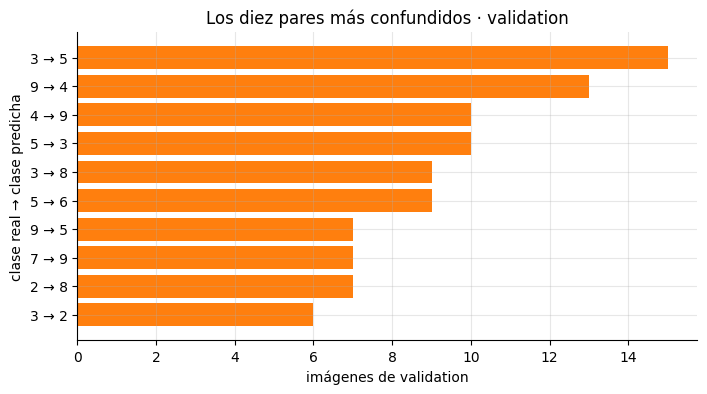

In [114]:
# Los pares (real → predicho) fuera de la diagonal, de más a menos casos.
pares = [(i, j, C_val[i, j]) for i in range(10) for j in range(10) if i != j]
pares = pd.DataFrame(pares, columns=["real", "predicho", "casos"])
pares["% de la clase real"] = 100 * pares["casos"] / C_val.sum(axis=1)[pares["real"]]
top_pares = (pares.sort_values("casos", ascending=False)
             .head(10).reset_index(drop=True))
display(top_pares.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
etiquetas = [f"{r} → {p}" for r, p in zip(top_pares["real"], top_pares["predicho"])]
ax.barh(etiquetas[::-1], top_pares["casos"][::-1], color=COLORES["validation"])
ax.set_xlabel("imágenes de validation")
ax.set_ylabel("clase real → clase predicha")
ax.set_title("Los diez pares más confundidos · validation")
plt.show()

La **confianza** es la mayor probabilidad anunciada, $\max_j \widehat p_j(x)$.
La galería ordena los errores por confianza. Busca trazos que tú también clasificarías con duda.
Un error muy confiado deja poca probabilidad para la clase real y aporta mucha cross-entropy.
La loss puede subir con el mismo número de aciertos. En §6 aumentaron tanto los errores como su confianza media.

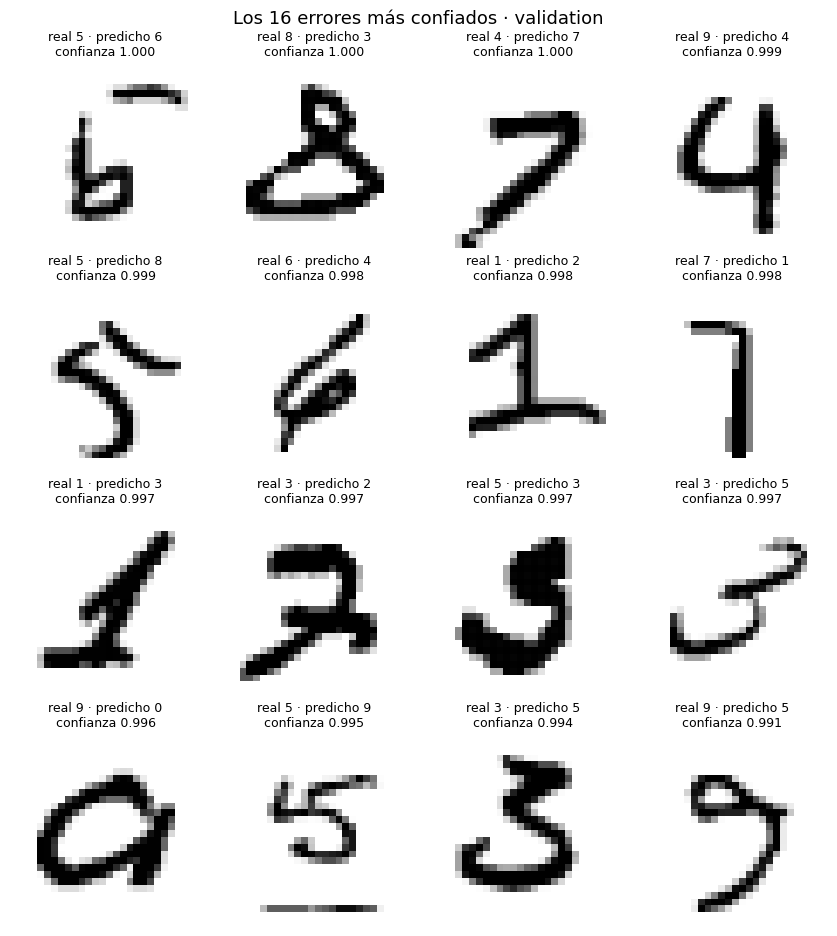

In [115]:
# Imágenes de validation en [0, 1] para dibujarlas (DATOS["01"] = píxel / 255).
IMAGENES_VAL = DATOS["01"]["validation"][0].reshape(-1, 28, 28).cpu().numpy()

errores = np.flatnonzero(~acierto_val)
# Los errores ordenados por confianza, de mayor a menor.
mas_confiados = errores[np.argsort(-conf_val[errores])][:16]

fig, ejes = plt.subplots(4, 4, figsize=(8.5, 9.5))
for ax in ejes.ravel():
    ax.axis("off")
for ax, k in zip(ejes.ravel(), mas_confiados):
    ax.imshow(IMAGENES_VAL[k], cmap="gray_r")
    ax.set_title(f"real {y_val[k]} · predicho {pred_val[k]}\n"
                 f"confianza {conf_val[k]:.3f}", fontsize=9)
fig.suptitle(f"Los {len(mas_confiados)} errores más confiados · validation",
             fontsize=13)
fig.tight_layout()
plt.show()

Cada grupo se muestra como **densidad** de área $1$. Así puedes comparar sus formas aunque tengan tamaños distintos.
Gris indica aciertos y rojo, errores. Busca dónde se solapan.
La confianza mínima posible es $1/10$, pues las diez probabilidades suman $1$.

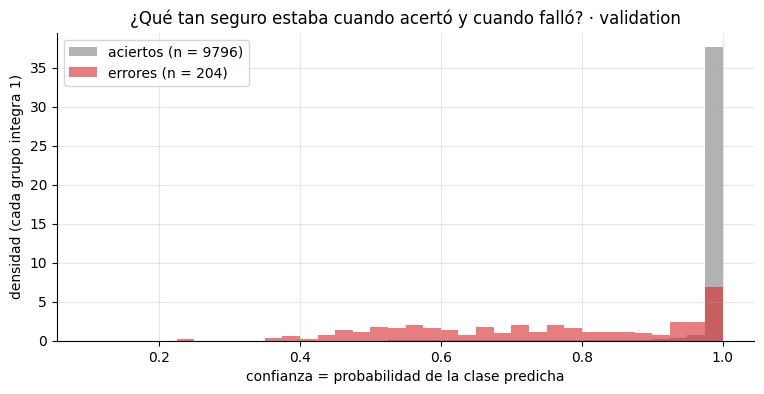

confianza mediana en aciertos: 1.000
confianza mediana en errores:  0.757


In [116]:
COLOR_ACIERTO, COLOR_ERROR = "#7f7f7f", "#d62728"
cortes_conf = np.linspace(0.1, 1.0, 37)      # la confianza nunca baja de 1/10

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(conf_val[acierto_val], bins=cortes_conf, density=True, alpha=0.6,
        color=COLOR_ACIERTO, label=f"aciertos (n = {acierto_val.sum()})")
ax.hist(conf_val[~acierto_val], bins=cortes_conf, density=True, alpha=0.6,
        color=COLOR_ERROR, label=f"errores (n = {(~acierto_val).sum()})")
ax.set_xlabel("confianza = probabilidad de la clase predicha")
ax.set_ylabel("densidad (cada grupo integra 1)")
ax.set_title("¿Qué tan seguro estaba cuando acertó y cuando falló? · validation")
ax.legend()
plt.show()

print(f"confianza mediana en aciertos: {np.median(conf_val[acierto_val]):.3f}")
print(f"confianza mediana en errores:  {np.median(conf_val[~acierto_val]):.3f}")

Hay **buena calibración** cuando la confianza anunciada coincide con la frecuencia de aciertos.
- Arriba. Cada punto compara ambas cantidades en uno de diez intervalos de igual ancho. Debajo de la diagonal hay sobreconfianza.
- Abajo. Las barras cuentan los casos por intervalo en escala logarítmica. Lee primero los puntos con más casos.

,intervalo,casos,confianza_media,accuracy
0,"[0.0, 0.1)",0,NaN,NaN
1,"[0.1, 0.2)",0,NaN,NaN
2,"[0.2, 0.3)",1,0.2445,0.0000
3,"[0.3, 0.4)",7,0.3673,0.2857
4,"[0.4, 0.5)",30,0.4548,0.4000
5,"[0.5, 0.6)",76,0.5540,0.5395
6,"[0.6, 0.7)",74,0.6499,0.6622
7,"[0.7, 0.8)",91,0.7495,0.6264
8,"[0.8, 0.9)",133,0.8565,0.8271
9,"[0.9, 1.0]",9588,0.9969,0.9934


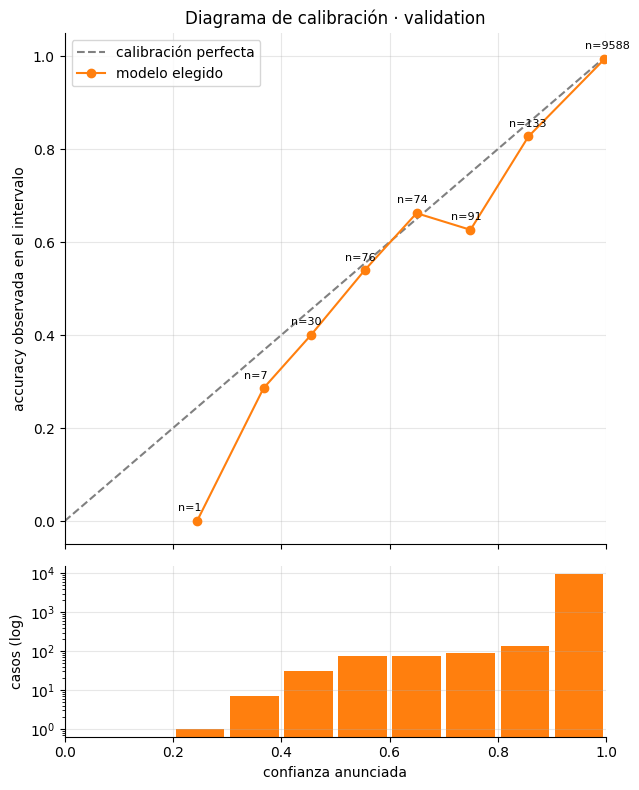

In [117]:
# 10 intervalos de igual ancho sobre la confianza; en cada uno comparamos lo que
# el modelo ANUNCIA (confianza promedio) con lo que OCURRE (fracción de aciertos).
bordes = np.linspace(0, 1, 11)
grupo = np.clip(np.digitize(conf_val, bordes) - 1, 0, 9)
filas = []
for b in range(10):
    dentro = grupo == b
    hay = dentro.any()                  # un intervalo puede quedar vacío
    cierre = "]" if b == 9 else ")"     # el último incluye la confianza 1.0
    filas.append({"intervalo": f"[{bordes[b]:.1f}, {bordes[b + 1]:.1f}{cierre}",
                  "casos": int(dentro.sum()),
                  "confianza_media": conf_val[dentro].mean() if hay else np.nan,
                  "accuracy": acierto_val[dentro].mean() if hay else np.nan})
calibracion = pd.DataFrame(filas)
display(calibracion.round(4))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(6.5, 8), sharex=True,
                             gridspec_kw={"height_ratios": [3, 1]})
a1.plot([0, 1], [0, 1], "--", color="gray", label="calibración perfecta")
ok = calibracion["casos"] > 0
a1.plot(calibracion.loc[ok, "confianza_media"], calibracion.loc[ok, "accuracy"],
        "o-", color=COLORES["validation"], label="modelo elegido")
for _, f in calibracion[ok].iterrows():
    a1.annotate(f"n={f['casos']}", (f["confianza_media"], f["accuracy"]),
                textcoords="offset points", xytext=(-14, 7), fontsize=8)
a1.set_ylabel("accuracy observada en el intervalo")
a1.set_title("Diagrama de calibración · validation")
a1.legend(loc="upper left")
a2.bar(bordes[:-1] + 0.05, calibracion["casos"], width=0.09,
       color=COLORES["validation"])
a2.set_yscale("log")                    # casi todo cae en el último intervalo
a2.set_xlabel("confianza anunciada")
a2.set_ylabel("casos (log)")
a2.set_xlim(0, 1)
fig.tight_layout()
plt.show()

**Evalúa test una vez, con el modelo ya elegido**. Las curvas por epoch de secciones anteriores son un recurso didáctico.
Lee la matriz y las métricas por dígito igual que en validation.
La accuracy de validation puede ser optimista porque sirvió para elegir el modelo.

accuracy en validation (con la que elegimos): 0.9796
accuracy en test (reporte, una vez):          0.9784
suma de la matriz de confusión de test: 10000


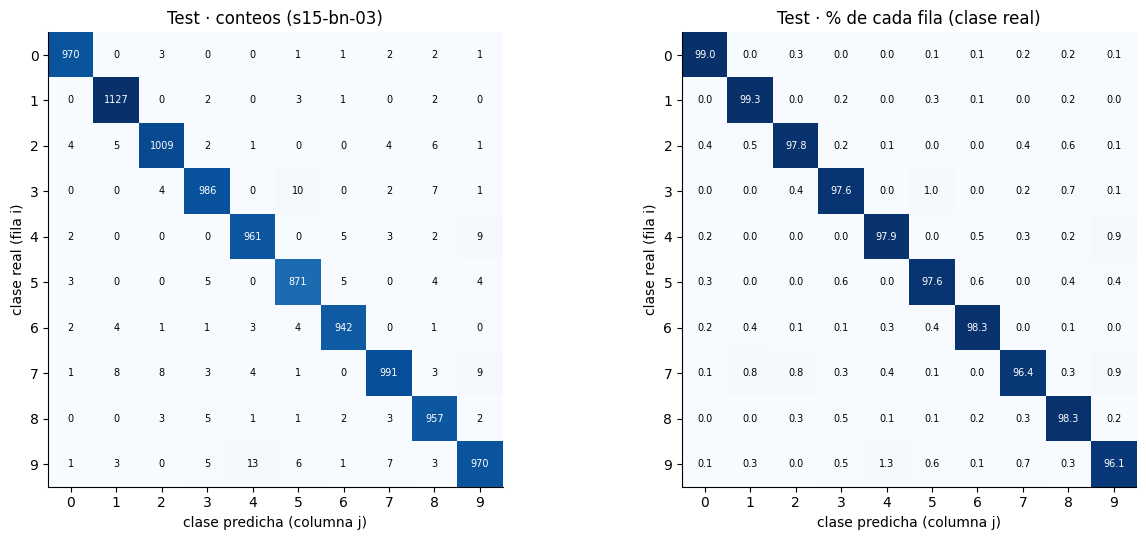

,digito,soporte,precision,recall,F1
0,0,980,0.9868,0.9898,0.9883
1,1,1135,0.9826,0.9930,0.9877
2,2,1032,0.9815,0.9777,0.9796
3,3,1010,0.9772,0.9762,0.9767
4,4,982,0.9776,0.9786,0.9781
5,5,892,0.9710,0.9765,0.9737
6,6,958,0.9843,0.9833,0.9838
7,7,1028,0.9792,0.9640,0.9716
8,8,974,0.9696,0.9825,0.9760
9,9,1009,0.9729,0.9613,0.9671


In [118]:
# UNA sola vez, al final, y sin cambiar nada de lo elegido: reportar en test.
P_test, y_test = probabilidades(modelo_16, ESCALA_16, "test")
pred_test = P_test.argmax(axis=1)
C_test = matriz_confusion(y_test, pred_test)
print(f"accuracy en validation (con la que elegimos): {acierto_val.mean():.4f}")
print(f"accuracy en test (reporte, una vez):          "
      f"{(pred_test == y_test).mean():.4f}")
print("suma de la matriz de confusión de test:", C_test.sum())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.5))
dibujar_confusion(C_test, a1, f"Test · conteos ({ELEGIDO_ID})")
dibujar_confusion(C_test, a2, "Test · % de cada fila (clase real)",
                  normalizar=True)
fig.tight_layout()
plt.show()
display(metricas_por_clase(C_test).round(4))

**Compara dentro de cada bloque de datos**. Las filas se ordenan por pasos ejecutados (`pasos_total`) y, si empatan, por sección.
Contrasta también los ejemplos procesados. La tabla conserva el identificador original de `s16-elegido`.
Test queda como registro didáctico. Validation guio la selección.

In [119]:
# La tabla maestra hasta esta sección, un bloque por tipo de datos:
# solo se comparan entre sí las corridas que vieron los mismos datos.
tabla_16 = tabla_maestra(list(range(1, 17)))
# CORRIDAS["s16-elegido"] es la MISMA corrida que ganó: aparecería dos veces
# con su ID original. Dejamos una sola fila por ID.
tabla_16 = tabla_16.drop_duplicates("id").reset_index(drop=True)
# El presupuesto total de cada corrida: pasos y ejemplos de su última fila.
por_id = {c.id: c for c in CORRIDAS.values()}
tabla_16["pasos_total"] = [por_id[i].historial["pasos"].iloc[-1]
                           for i in tabla_16["id"]]
tabla_16["ejemplos_total"] = [por_id[i].historial["ejemplos"].iloc[-1]
                              for i in tabla_16["id"]]
for datos, bloque in tabla_16.groupby("datos", sort=False):
    print(f"\n=== datos: {datos} · {len(bloque)} corridas ===")
    display(bloque.sort_values(["pasos_total", "seccion"]).reset_index(drop=True))


=== datos: 2k-limpio · 1 corridas ===


,id,seccion,datos,parametros,mejor_epoch,pasos,ejemplos,acc_train,acc_validation,acc_test,loss_train,loss_validation,loss_test,brecha,segundos,divergio,pasos_total,ejemplos_total
0,s03-demo,3,2k-limpio,101770,2.0,32,4000,0.864,0.8766,0.8737,0.429058,0.431527,0.460111,-0.0126,0.251521,False,32,4000



=== datos: 50k-limpio · 41 corridas ===


,id,seccion,datos,parametros,mejor_epoch,pasos,ejemplos,acc_train,acc_validation,acc_test,loss_train,loss_validation,loss_test,brecha,segundos,divergio,pasos_total,ejemplos_total
0,s08-sgd-1000,8,50k-limpio,101770,0.000000,0,0,0.11682,0.1116,0.1135,2.313227,2.311738,2.315717,0.00522,0.030576,True,25,3200
1,s05-crudo-arranque,5,50k-limpio,101770,0.127877,50,6400,0.23816,0.2356,0.2392,2.042673,2.021873,2.388534,0.00256,0.062474,False,50,6400
2,s05-01-arranque,5,50k-limpio,101770,0.127877,50,6400,0.59930,0.6188,0.6022,1.947213,1.937771,1.940706,-0.01950,0.065869,False,50,6400
3,s05-estandar-arranque,5,50k-limpio,101770,0.127877,50,6400,0.83526,0.8556,0.8461,0.760980,0.718863,0.734828,-0.02034,0.065264,False,50,6400
4,s08-sgd-0.0001,8,50k-limpio,101770,0.767263,300,38400,0.19436,0.1897,0.1930,2.252565,2.249975,2.253338,0.00466,0.341177,False,300,38400
5,s08-sgd-0.001,8,50k-limpio,101770,0.767263,300,38400,0.59350,0.6200,0.5996,1.798030,1.785491,1.787099,-0.02650,0.332425,False,300,38400
6,s08-sgd-0.01,8,50k-limpio,101770,0.767263,300,38400,0.87280,0.8863,0.8830,0.506779,0.465019,0.481834,-0.01350,0.337299,False,300,38400
7,s08-sgd-0.03,8,50k-limpio,101770,0.767263,300,38400,0.90230,0.9120,0.9091,0.340627,0.315079,0.322491,-0.00970,0.323147,False,300,38400
8,s08-sgd-0.1,8,50k-limpio,101770,0.767263,300,38400,0.93274,0.9365,0.9358,0.232793,0.222259,0.226277,-0.00376,0.341851,False,300,38400
9,s08-sgd-0.5,8,50k-limpio,101770,0.767263,300,38400,0.95146,0.9513,0.9501,0.157641,0.156462,0.163803,0.00016,0.317827,False,300,38400



=== datos: 4k-limpio · 6 corridas ===


,id,seccion,datos,parametros,mejor_epoch,pasos,ejemplos,acc_train,acc_validation,acc_test,loss_train,loss_validation,loss_test,brecha,segundos,divergio,pasos_total,ejemplos_total
0,s07-b1024,7,4k-limpio,101770,5.000000,20,20480,0.732178,0.7683,0.7583,1.374436,1.348108,1.353545,-0.036122,0.027691,False,20,20480
1,s07-b4096,7,4k-limpio,101770,80.000000,80,327680,0.867432,0.8799,0.8722,0.546683,0.522847,0.540380,-0.012468,0.129453,False,80,327680
2,s07-b128,7,4k-limpio,101770,5.000000,160,20480,0.892334,0.8958,0.8886,0.390772,0.391800,0.404601,-0.003466,0.180226,False,160,20480
3,s07-b32,7,4k-limpio,101770,4.687500,600,19200,0.940918,0.9193,0.9168,0.206888,0.284251,0.284547,0.021618,0.695684,False,640,20480
4,s07-b8,7,4k-limpio,101770,4.250000,2176,17408,0.985596,0.9414,0.9407,0.060249,0.210308,0.209539,0.044196,2.963397,False,2560,20480
5,s07-b1,7,4k-limpio,101770,0.431641,1768,1768,0.849121,0.8512,0.8422,0.515152,0.538112,0.559355,-0.002079,4.385750,False,4096,4096



=== datos: 2k-ruido20 · 3 corridas ===


,id,seccion,datos,parametros,mejor_epoch,pasos,ejemplos,acc_train,acc_validation,acc_test,loss_train,loss_validation,loss_test,brecha,segundos,divergio,pasos_total,ejemplos_total
0,s10-paciencia,10,2k-ruido20,269322,9.0,288,18000,0.8710,0.8871,0.8833,0.458271,0.471029,0.481787,-0.0161,0.840312,False,480,30000
1,s10-control,10,2k-ruido20,269322,9.0,288,18000,0.8710,0.8871,0.8833,0.458271,0.471029,0.481787,-0.0161,4.662207,False,2560,160000
2,s15-dropout,15,2k-ruido20,269322,16.0,512,32000,0.8505,0.9008,0.8921,0.511742,0.429377,0.445888,-0.0503,4.733174,False,2560,160000



=== datos: 20k-limpio · 26 corridas ===


,id,seccion,datos,parametros,mejor_epoch,pasos,ejemplos,acc_train,acc_validation,acc_test,loss_train,loss_validation,loss_test,brecha,segundos,divergio,pasos_total,ejemplos_total
0,s11-a2-p1,11,20k-limpio,1600,5.0,785,100000,0.22740,0.2229,0.2359,1.934371,1.930199,1.930802,0.00450,1.199077,False,785,100000
1,s11-a16-p1,11,20k-limpio,12730,5.0,785,100000,0.93170,0.9270,0.9232,0.232620,0.252407,0.264434,0.00470,1.187034,False,785,100000
2,s11-a64-p1,11,20k-limpio,50890,5.0,785,100000,0.97060,0.9552,0.9486,0.104505,0.160467,0.173501,0.01540,1.201763,False,785,100000
3,s11-a256-p1,11,20k-limpio,203530,3.0,471,60000,0.98110,0.9635,0.9593,0.071149,0.126572,0.131010,0.01760,1.424805,False,785,100000
4,s11-a1024-p1,11,20k-limpio,814090,5.0,785,100000,0.99645,0.9697,0.9669,0.016658,0.110469,0.112581,0.02675,1.406098,False,785,100000
5,s11-a2-p2,11,20k-limpio,1606,5.0,785,100000,0.31215,0.3164,0.3319,1.701048,1.683850,1.676336,-0.00425,1.371334,False,785,100000
6,s11-a16-p2,11,20k-limpio,13002,5.0,785,100000,0.93085,0.9207,0.9211,0.234524,0.280629,0.273945,0.01015,1.377947,False,785,100000
7,s11-a64-p2,11,20k-limpio,55050,5.0,785,100000,0.98045,0.9604,0.9568,0.071933,0.134237,0.145867,0.02005,1.333924,False,785,100000
8,s11-a256-p2,11,20k-limpio,269322,3.0,471,60000,0.98485,0.9652,0.9616,0.052988,0.123544,0.126472,0.01965,1.353538,False,785,100000
9,s11-a1024-p2,11,20k-limpio,1863690,5.0,785,100000,0.99140,0.9680,0.9639,0.025923,0.122657,0.137518,0.02340,1.405295,False,785,100000


**Qué viste**

- Predominaron confusiones entre trazos parecidos. Cambiar la dirección del par cambió el conteo.
- El dígito con menor precision fue distinto del de menor recall.
- Los aciertos se concentraron cerca de confianza máxima. Los errores se dispersaron e incluyeron casos muy confiados.
- Hubo ligera sobreconfianza donde se agrupó la mayoría de ejemplos. En otra corrida ese intervalo puede ajustarse a la diagonal.

## 17 · Una red convolucional, breve

Un MLP recibe una lista de $784$ píxeles. Una CNN aprovecha su **vecindad con pesos compartidos**.
Cada filtro recorre la imagen con una ventana de $3\times3$ y puede detectar el mismo trazo en distintas posiciones.

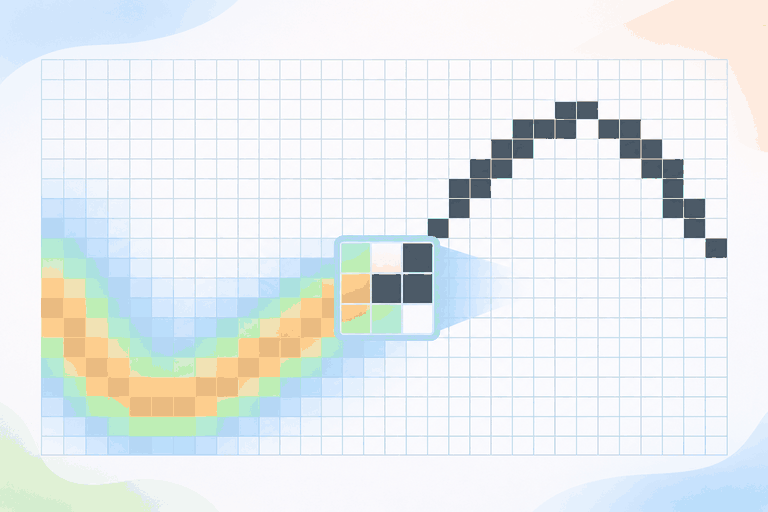
*(Ilustración generada con gpt-image-2.)*

centro ( 7, 10): Σ ventana·filtro = +2.988 = mapa[7, 10] = +2.988
centro ( 8, 16): Σ ventana·filtro = -2.988 = mapa[8, 16] = -2.988


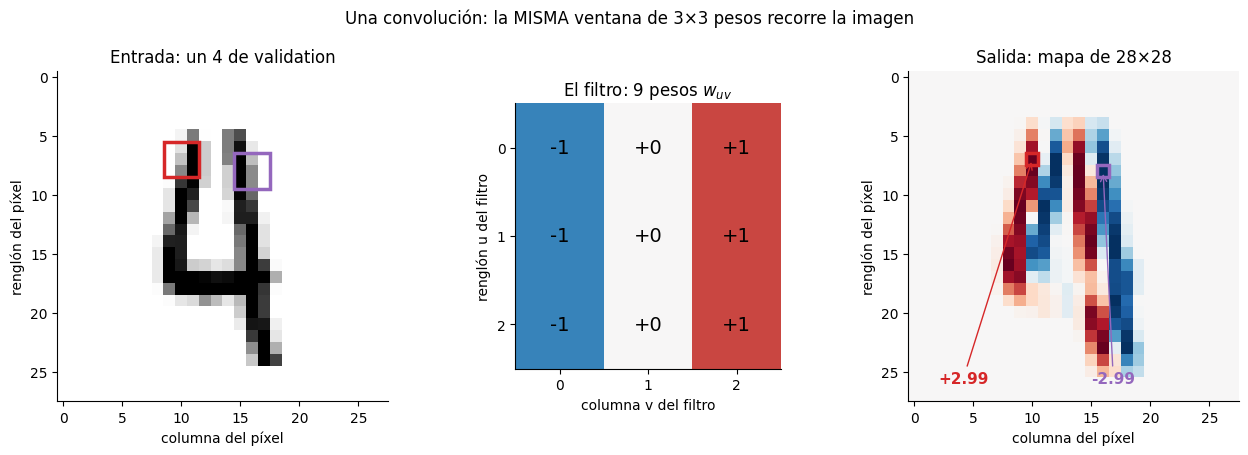

In [120]:
# Un filtro 3×3 hecho a mano, para ver qué hace una convolución ANTES de
# entrenar nada. Este filtro resta la columna izquierda de la ventana a la
# derecha: responde a bordes verticales (más tinta a la derecha de la ventana
# da positivo; más tinta a la izquierda, negativo).
import torch.nn.functional as F

X_val01, y_val = DATOS["01"]["validation"]        # píxeles en [0, 1]
k_digito = int((y_val == 4).nonzero()[0])          # el primer 4 de validation
digito = X_val01[k_digito].detach().cpu().view(28, 28)
filtro = torch.tensor([[-1.0, 0.0, 1.0],
                       [-1.0, 0.0, 1.0],
                       [-1.0, 0.0, 1.0]])          # filas = u, columnas = v

# La convolución de PyTorch: entrada [B, canales, 28, 28], filtro
# [salidas, entradas, 3, 3]. padding=1 agrega un marco de ceros para que la
# salida también sea de 28×28.
mapa = F.conv2d(digito.view(1, 1, 28, 28), filtro.view(1, 1, 3, 3),
                padding=1)[0, 0]                   # [28, 28]

# Dos centros de ventana (renglón, columna), MISMOS 9 pesos: el máximo y el
# mínimo del mapa, buscando el mínimo a ≥ 5 píxeles para no encimar ventanas.
r0, c0 = divmod(int(mapa.argmax()), 28)
rr, cc = torch.meshgrid(torch.arange(28), torch.arange(28), indexing="ij")
lejos = (rr - r0).abs() + (cc - c0).abs() >= 5
posiciones = [(r0, c0), divmod(int(torch.where(lejos, mapa, 9.0).argmin()), 28)]
colores_pos = ["#d62728", "#9467bd"]
fig, (ax_x, ax_w, ax_z) = plt.subplots(
    1, 3, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 0.55, 1]})
ax_x.imshow(digito, cmap="gray_r", vmin=0, vmax=1)
lim = float(mapa.abs().max())
ax_z.imshow(mapa, cmap="RdBu_r", vmin=-lim, vmax=lim)
for k, ((r, c), col) in enumerate(zip(posiciones, colores_pos)):
    ventana = digito[r - 1:r + 2, c - 1:c + 2]     # los 9 píxeles que lee
    valor = float((ventana * filtro).sum())        # suma de productos
    print(f"centro ({r:2d}, {c:2d}): Σ ventana·filtro = {valor:+.3f} "
          f"= mapa[{r}, {c}] = {float(mapa[r, c]):+.3f}")
    ax_x.add_patch(plt.Rectangle((c - 1.5, r - 1.5), 3, 3, fill=False,
                                 edgecolor=col, lw=2.5))
    ax_z.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False,
                                 edgecolor=col, lw=2.5))
    ax_z.annotate(f"{valor:+.2f}", (c, r), xytext=(2 + 13 * k, 26),  # rótulo abajo
                  color=col, fontsize=11, fontweight="bold",
                  arrowprops={"arrowstyle": "->", "color": col})
ax_w.imshow(filtro, cmap="RdBu_r", vmin=-1.5, vmax=1.5)
for u in range(3):
    for v in range(3):
        ax_w.text(v, u, f"{filtro[u, v]:+.0f}", ha="center", va="center",
                  fontsize=14)
ax_w.set(xticks=range(3), yticks=range(3), xlabel="columna v del filtro",
         ylabel="renglón u del filtro", title="El filtro: 9 pesos $w_{uv}$")
for ax, t in ((ax_x, f"Entrada: un {int(y_val[k_digito])} de validation"),
              (ax_z, "Salida: mapa de 28×28")):
    ax.set(title=t, xlabel="columna del píxel", ylabel="renglón del píxel")
for ax in (ax_x, ax_w, ax_z):
    ax.grid(False)
fig.suptitle("Una convolución: la MISMA ventana de 3×3 pesos recorre la imagen")
plt.tight_layout()
plt.show()

Los recuadros enlazan cada ventana del dígito con su posición en el mapa de salida.
El **filtro de bordes verticales** resta la tinta de la izquierda a la de la derecha. Aquí $b=0$.

$$z_{rc}=\sum_{u=-1}^{1}\sum_{v=-1}^{1}w_{uv}\,x_{r+u,c+v}+b.$$

Un borde de ceros de un píxel conserva el tamaño del mapa. PyTorch aplica los pesos tal como están escritos.
En una CNN, backpropagation ajusta los pesos y sesgos de cada filtro.

,capa,forma de salida,parámetros
0,entrada,"[2, 784]",0
1,Unflatten,"[2, 1, 28, 28]",0
2,Conv2d,"[2, 16, 28, 28]",160
3,ReLU,"[2, 16, 28, 28]",0
4,MaxPool2d,"[2, 16, 14, 14]",0
5,Conv2d,"[2, 32, 14, 14]",4640
6,ReLU,"[2, 32, 14, 14]",0
7,MaxPool2d,"[2, 32, 7, 7]",0
8,Flatten,"[2, 1568]",0
9,Linear,"[2, 10]",15690


parámetros de la CNN: 20490


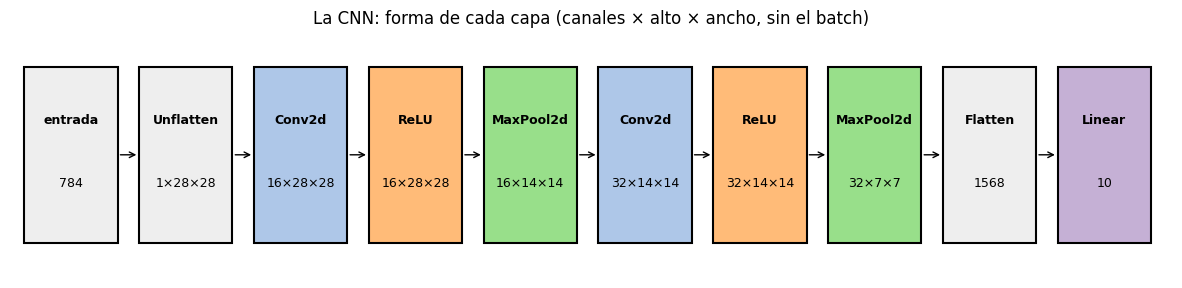

In [121]:
# La CNN de esta sección. Los DATOS del notebook son planos, [B, 784]; la
# primera capa los vuelve a doblar como imagen [B, 1, 28, 28] (un canal:
# gris). Desde ahí: dos bloques conv 3×3 → ReLU → max-pooling 2×2, y al
# final una capa lineal, la misma de siempre, hacia los 10 logits.
def construir_cnn():
    return nn.Sequential(
        nn.Unflatten(1, (1, 28, 28)),                 # [B,784] → [B,1,28,28]
        nn.Conv2d(1, 16, kernel_size=3, padding=1),   # 16 filtros de 1×3×3
        nn.ReLU(),
        nn.MaxPool2d(2),                              # 28×28 → 14×14
        nn.Conv2d(16, 32, kernel_size=3, padding=1),  # 32 filtros de 16×3×3
        nn.ReLU(),
        nn.MaxPool2d(2),                              # 14×14 → 7×7
        nn.Flatten(),                                 # [B,32,7,7] → [B,1568]
        nn.Linear(32 * 7 * 7, 10),                    # → logits [B,10]
    )


# Pasamos un batch de 2 imágenes y anotamos la forma que sale de cada capa.
cnn_muestra = construir_cnn()
h = DATOS["estandar"]["validation"][0][:2].detach().cpu()
filas = [{"capa": "entrada", "forma de salida": str(list(h.shape)),
          "parámetros": 0}]
for capa in cnn_muestra:
    h = capa(h)
    filas.append({"capa": type(capa).__name__,
                  "forma de salida": str(list(h.shape)),
                  "parámetros": sum(p.numel() for p in capa.parameters())})
tabla_cnn = pd.DataFrame(filas)
display(tabla_cnn)
print("parámetros de la CNN:", int(tabla_cnn["parámetros"].sum()))

# Dibujo de la arquitectura: un bloque por capa, con su forma (sin el batch).
fig, ax = plt.subplots(figsize=(15, 3.2))
tonos = {"Conv2d": "#aec7e8", "ReLU": "#ffbb78", "MaxPool2d": "#98df8a",
         "Linear": "#c5b0d5"}
for i, fila in tabla_cnn.iterrows():
    forma = fila["forma de salida"].strip("[]").split(", ")[1:]
    ax.add_patch(plt.Rectangle((i * 1.6, 0), 1.3, 1, lw=1.5, edgecolor="k",
                               facecolor=tonos.get(fila["capa"], "#eeeeee")))
    ax.text(i * 1.6 + 0.65, 0.68, fila["capa"], ha="center", fontsize=9,
            fontweight="bold")
    ax.text(i * 1.6 + 0.65, 0.32, "×".join(forma), ha="center", fontsize=9)
    if i:
        ax.annotate("", (i * 1.6, 0.5), (i * 1.6 - 0.3, 0.5),
                    arrowprops={"arrowstyle": "->"})
ax.set_xlim(-0.2, len(tabla_cnn) * 1.6)
ax.set_ylim(-0.2, 1.2)
ax.axis("off")
ax.set_title("La CNN: forma de cada capa (canales × alto × ancho, sin el batch)")
plt.show()
del cnn_muestra, h

- `Unflatten` recompone la cuadrícula de $28\times28$ con un canal.
- La primera convolución produce $16$ mapas y tiene $16(9+1)=160$ parámetros.
- ReLU pone los negativos en cero. **Max-pooling** conserva el máximo de cada bloque de $2\times2$.
- La segunda convolución combina los $16$ canales con $32$ filtros y suma $32(16\cdot3\cdot3+1)=4\,640$ parámetros.
- Tras ReLU y max-pooling quedan $32\cdot7\cdot7=1\,568$ rasgos. La capa densa produce diez logits con $10(1\,568+1)=15\,690$ parámetros.

**Apuesta.** ¿La CNN ganará, empatará o perderá frente al MLP en accuracy de validation?
¿Cuál tendrá mayor brecha entre train y validation al final, o serán similares?

In [122]:
# El MLP contra el que comparamos: el que §16 eligió por VALIDATION.
# Si saltaste §16, repetimos su regla aquí (nunca se mira test para elegir).
if "s16-elegido" in CORRIDAS:
    corrida_mlp = CORRIDAS["s16-elegido"]
    print("MLP elegido en §16:", corrida_mlp.id)
else:
    def acc_val_mejor(c):
        h = c.historial
        return float(h[h["epoch"] == c.mejor_epoch].iloc[-1]["acc_validation"])

    candidatos = [c for c in CORRIDAS.values()
                  if c.config.datos == "50k-limpio" and c.config.modelo is None
                  and c.config.idx_train is None and not c.divergio
                  and c.config.ruido_etiquetas == 0.0]
    if candidatos:
        corrida_mlp = max(candidatos, key=acc_val_mejor)
        print("AVISO: no existe s16-elegido; uso el mejor MLP por validation:",
              corrida_mlp.id)
    else:
        print("AVISO: no hay ningún MLP entrenado con los 50k; entreno la "
              "línea base s04-oculta (8 epochs).")
        corrida_mlp = entrenar(Config(id="s04-oculta", seccion=4,
                                      capas=[784, 128, 10], activacion="relu",
                                      optimizer="adam", lr=1e-3, epochs=8))
cfg_mlp = corrida_mlp.config
print("capas:", cfg_mlp.capas, "· optimizer:", cfg_mlp.optimizer,
      "· η:", cfg_mlp.lr, "· weight_decay:", cfg_mlp.weight_decay)
print("epochs:", cfg_mlp.epochs, "· tope de pasos:", cfg_mlp.max_pasos,
      "· batch:", cfg_mlp.batch, "· escala:", cfg_mlp.escala,
      "· parámetros:", corrida_mlp.parametros)

MLP elegido en §16: s15-bn-03
capas: [784, 128, 128, 128, 128, 128, 128, 10] · optimizer: sgd · η: 0.3 · weight_decay: 0.0
epochs: 5 · tope de pasos: None · batch: 128 · escala: estandar · parámetros: 185866


In [123]:
# La CNN, con los mismos datos que el MLP: los 50 000 de train, la misma
# escala de entrada, el mismo batch y las mismas epochs (y el mismo tope de
# pasos y frecuencia de evaluación, si el MLP los tenía). El optimizer es
# Adam con η = 1e-3 y sin weight decay: si el MLP elegido usó otro, la tabla
# de abajo lo muestra, y la comparación es entre ESTAS dos corridas.
cfg_cnn = Config(id="s17-cnn", seccion=17, modelo=construir_cnn,
                 optimizer="adam", lr=1e-3, datos="50k-limpio",
                 epochs=cfg_mlp.epochs, max_pasos=cfg_mlp.max_pasos,
                 eval_cada_pasos=cfg_mlp.eval_cada_pasos,
                 batch=cfg_mlp.batch, escala=cfg_mlp.escala)
corrida_cnn = entrenar(cfg_cnn)
print("epochs:", cfg_cnn.epochs, "· batch:", cfg_cnn.batch,
      "· escala:", cfg_cnn.escala, "· parámetros:", corrida_cnn.parametros)

s17-cnn: 20,490 parámetros · 1955 pasos · mejor epoch 4.85934 · acc validation 0.987 · 4.4 s
epochs: 5 · batch: 128 · escala: estandar · parámetros: 20490


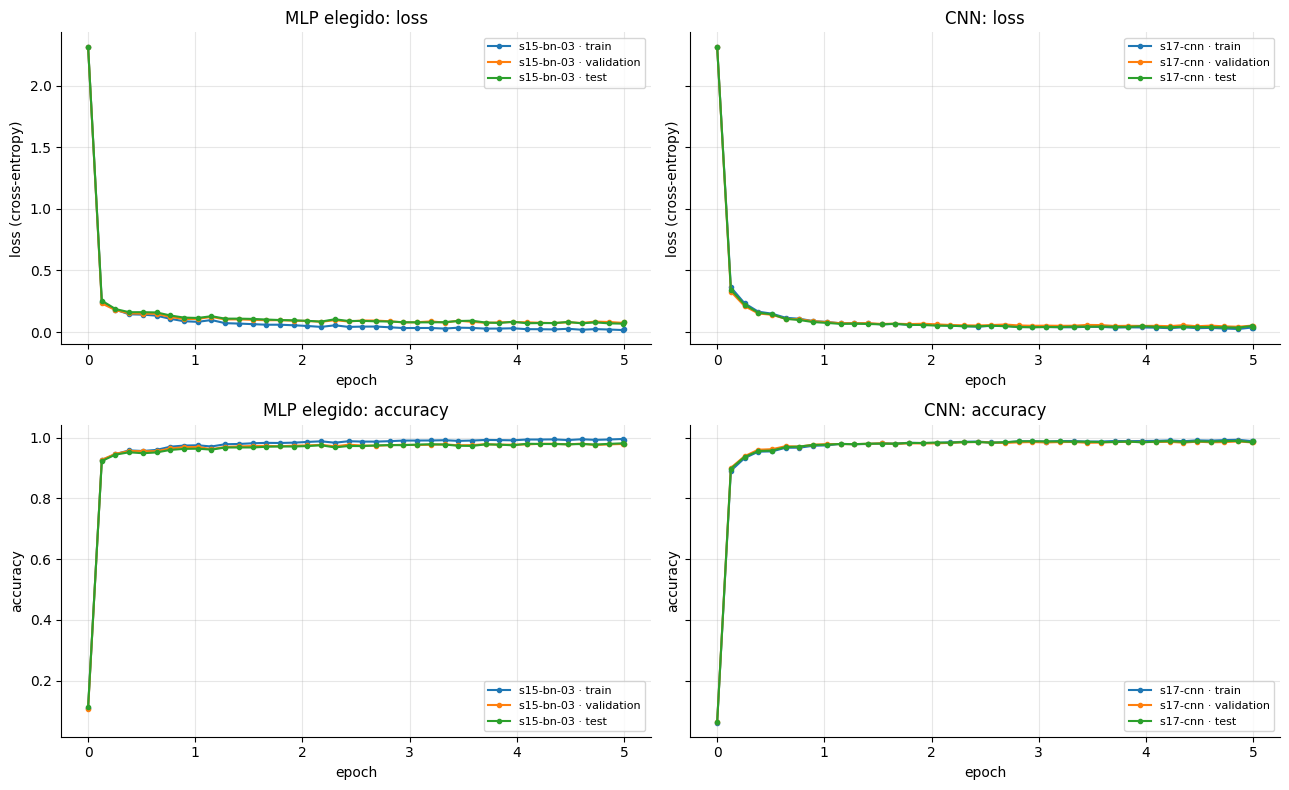

,id,optimizer,η,weight_decay,parámetros,mejor epoch (validation),loss validation,accuracy validation,errores en validation,segundos
red,,,,,,,,,,
MLP elegido,s15-bn-03,sgd,0.300,0.0,185866,4.3478,0.0728,0.9796,204,6.4001
CNN,s17-cnn,adam,0.001,0.0,20490,4.8593,0.0430,0.9871,129,4.3504


CNN − MLP en accuracy de validation: +0.75 puntos
la CNN usa 0.11 veces los parámetros del MLP


In [124]:
# Las dos redes lado a lado: MISMO eje y en cada renglón para poder comparar.
pareja = [("MLP elegido", corrida_mlp), ("CNN", corrida_cnn)]
fig, ejes = plt.subplots(2, 2, figsize=(13, 8), sharey="row")
for j, (nombre, c) in enumerate(pareja):
    curvas([c], metrica="loss", ax=ejes[0, j], titulo=f"{nombre}: loss")
    curvas([c], metrica="accuracy", ax=ejes[1, j],
           titulo=f"{nombre}: accuracy")
plt.tight_layout()
plt.show()


# Tabla: parámetros y métricas en la mejor epoch POR VALIDATION de cada una.
def resumen(nombre, c):
    h = c.historial
    fila = h[h["epoch"] == c.mejor_epoch].iloc[-1]
    return {"red": nombre, "id": c.id, "optimizer": c.config.optimizer,
            "η": c.config.lr, "weight_decay": c.config.weight_decay,
            "parámetros": c.parametros,
            "mejor epoch (validation)": c.mejor_epoch,
            "loss validation": float(fila["loss_validation"]),
            "accuracy validation": float(fila["acc_validation"]),
            "errores en validation": round((1 - fila["acc_validation"])
                                           * len(DATOS["01"]["validation"][1])),
            "segundos": float(h["segundos"].iloc[-1])}


tabla_17 = pd.DataFrame([resumen(n, c) for n, c in pareja]).set_index("red")
display(tabla_17.round(4))
dif = (tabla_17.loc["CNN", "accuracy validation"]
       - tabla_17.loc["MLP elegido", "accuracy validation"])
print(f"CNN − MLP en accuracy de validation: {100 * dif:+.2f} puntos")
print(f"la CNN usa {corrida_cnn.parametros / corrida_mlp.parametros:.2f} "
      "veces los parámetros del MLP")

El MLP está a la izquierda y la CNN a la derecha. Cada fila comparte escala vertical.
**Busca overfitting** si la loss de train baja mientras la de validation sube.
La tabla usa el checkpoint de menor loss de validation. La CNN copia la escala, el batch y el presupuesto.
Revisa el optimizer y el learning rate de cada red antes de atribuir la diferencia a la arquitectura.
Test por epoch es didáctico. En un proyecto, decide con validation y mira test una vez al final.

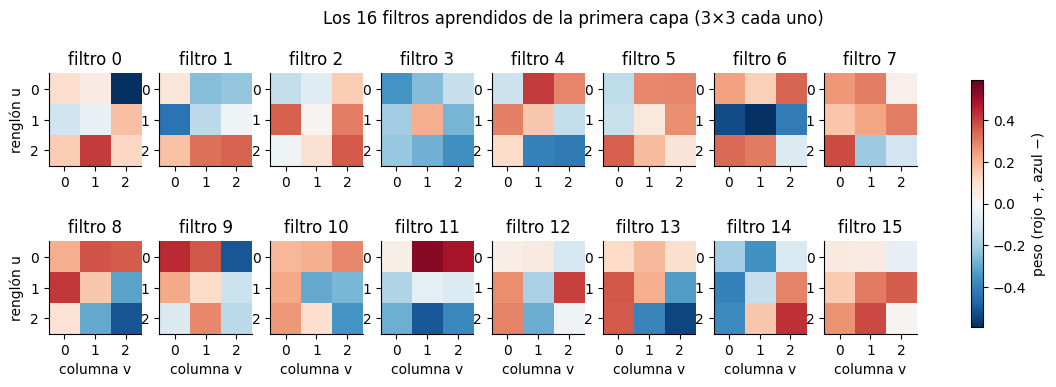

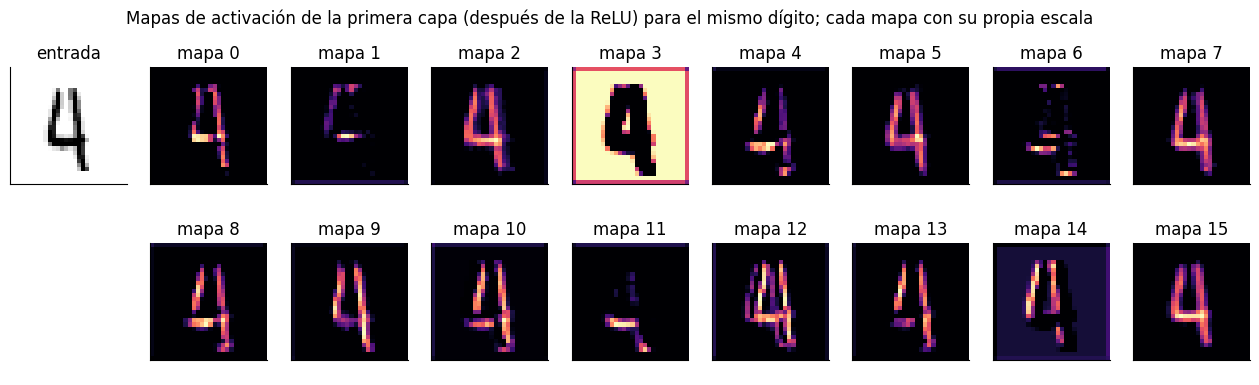

In [125]:
# ¿Qué aprendió la primera capa? Sus 16 filtros de 3×3, y lo que cada uno
# produce sobre el mismo dígito de validation de la figura del principio.
cnn = cargar(corrida_cnn, "mejor")                # en DEVICE, modo eval()
conv1 = cnn[1]                                    # Conv2d(1, 16, 3)
W1 = conv1.weight.detach().cpu()[:, 0]            # [16, 3, 3]
lim = float(W1.abs().max())
fig, ejes = plt.subplots(2, 8, figsize=(14, 4))
for f, ax in enumerate(ejes.flat):
    im = ax.imshow(W1[f], cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"filtro {f}")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.grid(False)
for ax in ejes[1]:
    ax.set_xlabel("columna v")
for ax in ejes[:, 0]:
    ax.set_ylabel("renglón u")
fig.colorbar(im, ax=ejes, shrink=0.8).set_label("peso (rojo +, azul −)")
fig.suptitle("Los 16 filtros aprendidos de la primera capa (3×3 cada uno)")
plt.show()

# Mapas de activación: la salida de conv1 + ReLU (capas 0–2 del Sequential).
x = DATOS[cfg_cnn.escala]["validation"][0][k_digito:k_digito + 1]
with torch.no_grad():
    mapas = cnn[:3](x)[0].cpu()                   # [16, 28, 28]
fig, ejes = plt.subplots(2, 9, figsize=(16, 4.2))
ejes[0, 0].imshow(digito, cmap="gray_r")
ejes[0, 0].set_title("entrada")
ejes[1, 0].axis("off")
for f in range(16):
    ax = ejes.flat[f + 1 if f < 8 else f + 2]
    ax.imshow(mapas[f], cmap="magma")
    ax.set_title(f"mapa {f}")
for ax in ejes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
fig.suptitle("Mapas de activación de la primera capa (después de la ReLU) "
             "para el mismo dígito; cada mapa con su propia escala")
plt.show()
del cnn, conv1, W1, mapas                         # liberamos la CNN restaurada

- Los filtros usan una escala común. Rojo indica pesos positivos, azul negativos y blanco cercanos a cero.
- Cada **mapa de activación** muestra la respuesta de un filtro después de ReLU y antes de max-pooling.
- Los mapas tienen escalas propias. Compara dónde responden y qué parte del trazo resaltan.
- La CNN recibe el dígito en su escala de entrenamiento. Si está estandarizado, el fondo también puede activar filtros.

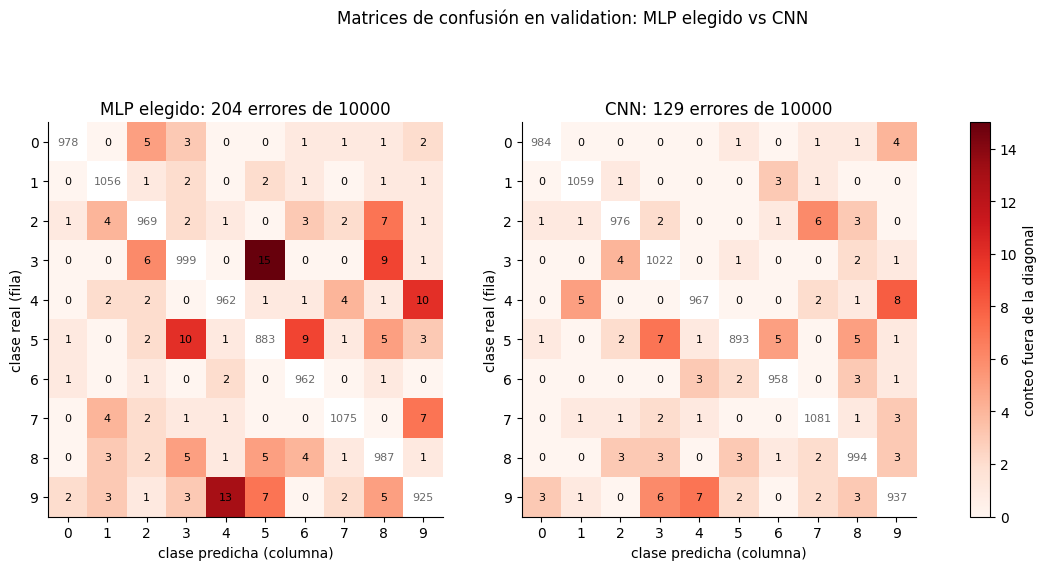

clase real,0,1,2,3,4,5,6,7,8,9
MLP elegido,13,8,21,31,21,32,5,15,22,36
CNN,7,5,14,8,16,22,9,9,15,24
CNN − MLP,-6,-3,-7,-23,-5,-10,4,-6,-7,-12


In [126]:
# Matrices de confusión en VALIDATION, una junto a otra.
# Filas = clase real, columnas = clase predicha. La diagonal (aciertos) va
# en gris para que el color lo lleven los ERRORES, con la misma escala.
def predecir(corrida):
    modelo = cargar(corrida, "mejor")
    X, y = DATOS[corrida.config.escala]["validation"]
    with torch.no_grad():
        p = torch.cat([modelo(X[i:i + 1000]).argmax(1)
                       for i in range(0, len(X), 1000)])
    return y.cpu(), p.cpu()


def confusion(y, p):
    return torch.bincount(y * 10 + p, minlength=100).view(10, 10).numpy()


M = {n: confusion(*predecir(c)) for n, c in pareja}
fuera = {n: mat - np.diag(np.diag(mat)) for n, mat in M.items()}
tope = max(f.max() for f in fuera.values())
fig, ejes = plt.subplots(1, 2, figsize=(14, 6.4))
for ax, (n, matriz) in zip(ejes, M.items()):
    errores = np.where(np.eye(10, dtype=bool), np.nan, matriz)
    im = ax.imshow(errores, cmap="Reds", vmin=0, vmax=tope)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, matriz[i, j], ha="center", va="center", fontsize=8,
                    color="dimgray" if i == j else "black")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.set_xlabel("clase predicha (columna)")
    ax.set_ylabel("clase real (fila)")
    ax.set_title(f"{n}: {int(fuera[n].sum())} errores de {int(matriz.sum())}")
    ax.grid(False)
fig.colorbar(im, ax=ejes, shrink=0.8).set_label("conteo fuera de la diagonal")
fig.suptitle("Matrices de confusión en validation: MLP elegido vs CNN")
plt.show()

# Errores por clase real: ¿en qué dígitos cambia algo?
por_clase = pd.DataFrame({n: f.sum(axis=1) for n, f in fuera.items()})
por_clase.index.name = "clase real"
por_clase["CNN − MLP"] = por_clase["CNN"] - por_clase["MLP elegido"]
display(por_clase.T)

**Qué viste**

- Ambas losses de validation cayeron al inicio. La accuracy terminó alta en las dos redes.
- Algunos filtros resaltaron bordes o partes del trazo. Otros produjeron respuestas más dispersas.
- La CNN redujo los errores en casi todos los dígitos, especialmente en el 3. Se equivocó más en el 6.
- En otra corrida pueden cambiar los dígitos que más se benefician. Compara las casillas leyendo fila real y columna predicha.

<details><summary>Respuesta</summary>

Debajo de la tabla se imprime CNN menos MLP. Aquí **la CNN ganó en accuracy** con menos parámetros.
Su brecha final entre train y validation fue pequeña, como la del MLP.
Con otra semilla puede haber empate o una ventaja para el MLP.

</details>

## 18 · Softmax y la loss

La última capa lineal entrega un logit por dígito, $\mathbf z=\mathbf W^{(L)}\mathbf a^{(L-1)}+\mathbf b^{(L)}$.
**Softmax convierte logits en probabilidades** que suman $1$.

$$\widehat y_c=\frac{e^{z_c}}{\sum_{j=0}^{9}e^{z_j}}.$$

Sumar la misma constante a todos los logits deja intactas las probabilidades.
Usamos el checkpoint elegido en §16. Si falta, recurrimos a la línea base de §4.

In [127]:
# El modelo de esta sección: el que §16 eligió por validation. Si corriste
# esta sección sin §16, usamos la línea base de §4 (y la entrenamos si falta).
import torch.nn.functional as F

if "s16-elegido" in CORRIDAS:
    corrida_18 = CORRIDAS["s16-elegido"]
    print("Usamos el modelo elegido en §16:", corrida_18.id)
elif "s04-oculta" in CORRIDAS:
    corrida_18 = CORRIDAS["s04-oculta"]
    print("No hay s16-elegido (no corriste §16): usamos la línea base "
          "s04-oculta, que ya estaba entrenada.")
else:
    print("No hay s16-elegido ni s04-oculta: entrenamos ahora la línea base "
          "de §4 (784→128→10, ReLU, Adam 1e-3, 8 epochs).")
    corrida_18 = entrenar(Config(id="s04-oculta", seccion=4,
                                 capas=[784, 128, 10], activacion="relu",
                                 optimizer="adam", lr=1e-3, epochs=8))

escala_18 = corrida_18.config.escala
modelo_18 = cargar(corrida_18, "mejor")      # el checkpoint de la mejor epoch
print(modelo_18)

# Ninguna capa del modelo es softmax: la red termina en 10 LOGITS.
# El softmax vive dentro de CrossEntropyLoss (lo vemos en esta sección).
assert not any(isinstance(m, nn.Softmax) for m in modelo_18.modules())

Usamos el modelo elegido en §16: s15-bn-03
Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=128, bias=True)
  (4): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (5): ReLU()
  (6): Linear(in_features=128, out_features=128, bias=True)
  (7): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (8): ReLU()
  (9): Linear(in_features=128, out_features=128, bias=True)
  (10): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (11): ReLU()
  (12): Linear(in_features=128, out_features=128, bias=True)
  (13): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (14): ReLU()
  (15): Linear(in_features=128, out_features=128, bias=True)
  (16): BatchN

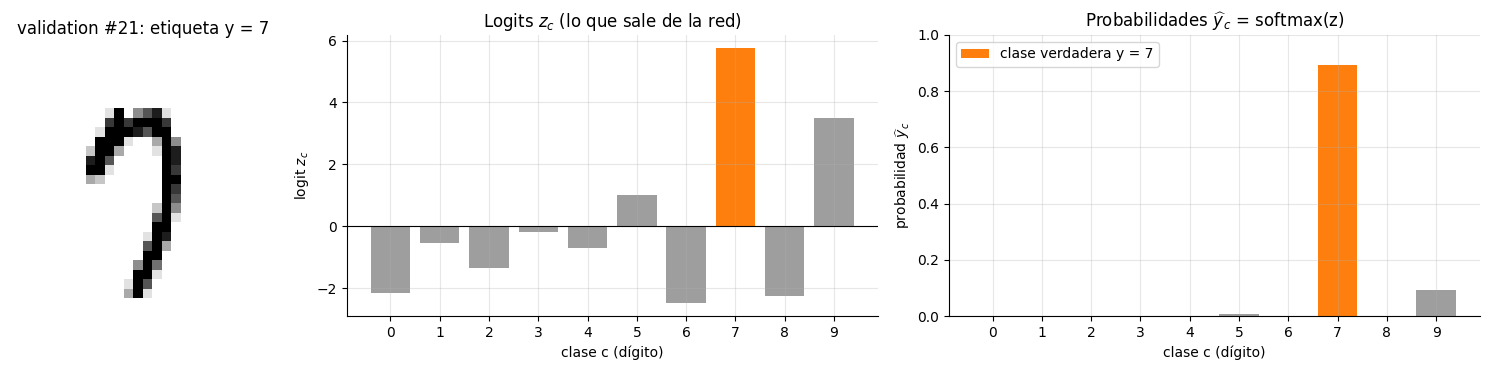

,clase c,logit z_c,e^{z_c},ŷ_c = e^{z_c} / Σ e^{z_j}
0,0,-2.1584,0.1155,0.0003
1,1,-0.5375,0.5842,0.0016
2,2,-1.3499,0.2593,0.0007
3,3,-0.1732,0.8410,0.0023
4,4,-0.6980,0.4976,0.0014
5,5,1.0106,2.7472,0.0077
6,6,-2.4970,0.0823,0.0002
7,7,5.7681,319.9236,0.8929
8,8,-2.2635,0.1040,0.0003
9,9,3.5006,33.1367,0.0925


Σ ŷ_c = 1.000000   ·   argmax z = 7   ·   argmax ŷ = 7


In [128]:
# Logits de TODO validation (sin gradiente, por bloques de 2048).
X_val, y_val = DATOS[escala_18]["validation"]
with torch.no_grad():
    logits_val = torch.cat([modelo_18(X_val[i:i + 2048])
                            for i in range(0, len(X_val), 2048)])
prob_val = torch.softmax(logits_val, dim=1)      # [n, 10]; cada fila suma 1
confianza, prediccion = prob_val.max(dim=1)

# Un dígito con algo de duda: bien clasificado, pero con 0.5 < max ŷ_c < 0.9,
# para que se vea más de una barra. Si no hay ninguno, el acierto (o, si no
# hay aciertos, el ejemplo) con la confianza más baja.
acierto = prediccion == y_val
dudosos = torch.nonzero(acierto & (confianza > 0.5) & (confianza < 0.9))
if len(dudosos):
    k_18 = int(dudosos[0, 0])
elif acierto.any():
    k_18 = int(torch.where(acierto, confianza, 2.0).argmin())
else:
    k_18 = int(confianza.argmin())
z = logits_val[k_18].cpu()                       # z_0 … z_9
y_gorro = prob_val[k_18].cpu()                   # ŷ_0 … ŷ_9
y_k = int(y_val[k_18])
colores_k = ["#9e9e9e"] * 10
colores_k[y_k] = COLORES["validation"]           # la clase verdadera

fig, (ax_img, ax_z, ax_p) = plt.subplots(
    1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 2, 2]})
ax_img.imshow(DATOS["01"]["validation"][0][k_18].reshape(28, 28).cpu(),
              cmap="gray_r")
ax_img.set_title(f"validation #{k_18}: etiqueta y = {y_k}")
ax_img.axis("off")
ax_z.bar(range(10), z, color=colores_k)
ax_z.axhline(0, color="black", lw=0.8)
ax_z.set_title("Logits $z_c$ (lo que sale de la red)")
ax_z.set_ylabel("logit $z_c$")
barras = ax_p.bar(range(10), y_gorro, color=colores_k)
ax_p.set_ylim(0, 1)
ax_p.set_title(r"Probabilidades $\widehat y_c$ = softmax(z)")
ax_p.set_ylabel(r"probabilidad $\widehat y_c$")
ax_p.legend([barras[y_k]], [f"clase verdadera y = {y_k}"])
for ax in (ax_z, ax_p):
    ax.set_xticks(range(10))
    ax.set_xlabel("clase c (dígito)")
plt.tight_layout()
plt.show()

# La cuenta, clase por clase (e^z en float64 para no desbordar).
e_z = torch.exp(z.double())
display(pd.DataFrame({"clase c": range(10), "logit z_c": z.numpy(),
                      "e^{z_c}": e_z.numpy(),
                      "ŷ_c = e^{z_c} / Σ e^{z_j}": (e_z / e_z.sum()).numpy()})
        .round(4))
print(f"Σ ŷ_c = {float(y_gorro.sum()):.6f}   ·   argmax z = {int(z.argmax())}"
      f"   ·   argmax ŷ = {int(y_gorro.argmax())}")

**El argmax se conserva**. La barra más alta en cada panel corresponde a la misma clase.
El naranja marca la clase real. El ejemplo busca un acierto con confianza entre $0.5$ y $0.9$.
El cociente entre probabilidades es $e^{z_c-z_j}$. Una diferencia pequeña entre logits puede producir probabilidades muy distintas.

La temperatura $T>0$ divide los logits antes de aplicar softmax. Con $T=1$ recuperas las probabilidades originales.

$$\widehat y_c(T)=\frac{e^{z_c/T}}{\sum_{j=0}^{9}e^{z_j/T}}.$$

**Apuesta.** Al subir $T$, ¿la confianza y la loss suben, bajan o quedan iguales?
¿Cambian la clase predicha y la accuracy de validation, o se mantienen?

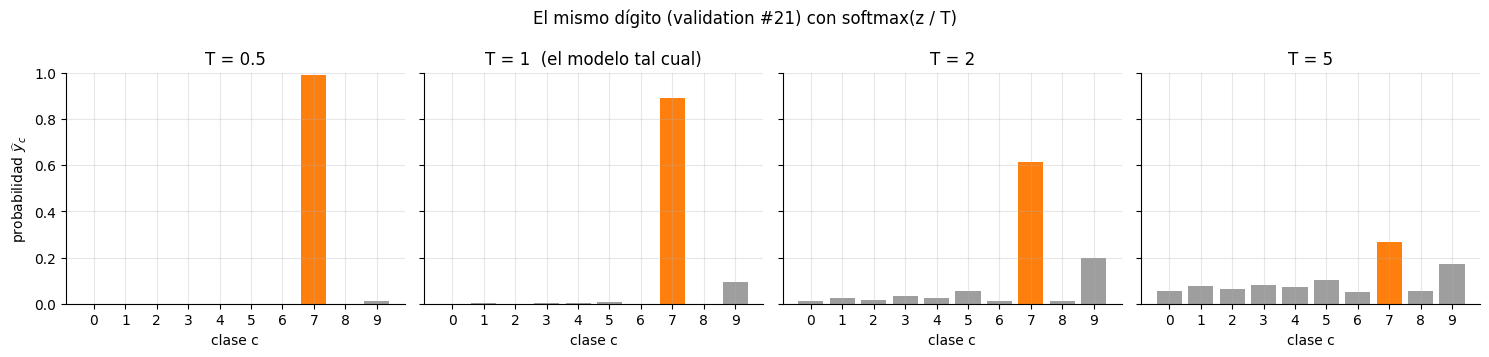

,T,argmax,max ŷ_c,ŷ_y (y = 7),loss −log ŷ_y
0,0.5,7,0.9893,0.9893,0.0108
1,1.0,7,0.8929,0.8929,0.1133
2,2.0,7,0.6137,0.6137,0.4883
3,5.0,7,0.2687,0.2687,1.3142


El argmax es el mismo en las 4 temperaturas: 7


In [129]:
# Temperatura: softmax(z / T). Dividir TODOS los logits entre el mismo T > 0
# no cambia su orden, así que el argmax no cambia; la confianza sí.
TEMPERATURAS = [0.5, 1, 2, 5]
fig, ejes = plt.subplots(1, len(TEMPERATURAS), figsize=(15, 3.6), sharey=True)
filas = []
for T, ax in zip(TEMPERATURAS, ejes):
    p_T = torch.softmax(z / T, dim=0)
    ax.bar(range(10), p_T, color=colores_k)
    ax.set_title(f"T = {T}" + ("  (el modelo tal cual)" if T == 1 else ""))
    ax.set_xticks(range(10))
    ax.set_xlabel("clase c")
    filas.append({"T": T, "argmax": int(p_T.argmax()),
                  "max ŷ_c": float(p_T.max()),
                  f"ŷ_y (y = {y_k})": float(p_T[y_k]),
                  "loss −log ŷ_y":                 # estable: log_softmax
                  float(-torch.log_softmax(z / T, dim=0)[y_k])})
ejes[0].set_ylim(0, 1)
ejes[0].set_ylabel(r"probabilidad $\widehat y_c$")
fig.suptitle(f"El mismo dígito (validation #{k_18}) con softmax(z / T)")
plt.tight_layout()
plt.show()

tabla_T = pd.DataFrame(filas)
display(tabla_T.round(4))
assert tabla_T["argmax"].nunique() == 1          # el argmax no se movió
print("El argmax es el mismo en las", len(TEMPERATURAS), "temperaturas:",
      int(tabla_T["argmax"].iloc[0]))

<details><summary>Respuesta</summary>

**La predicción se conserva** al dividir por $T>0$. La accuracy queda igual.
Al subir $T$, baja la confianza y sube la loss de este acierto. Si hay error, lee $\widehat y_y$.
Con igual número de aciertos, la loss puede subir. En §6 aumentaron tanto los errores como su confianza media.

</details>

La **cross-entropy** mide $-\log\widehat y_y$, con logaritmo natural y $y$ como clase verdadera.
La loss crece sin límite cuando $\widehat y_y$ se acerca a cero. Con probabilidades uniformes vale $\log 10\approx2.30$.

$$L(\theta)=\frac{1}{n}\sum_{k=1}^{n}-\log\widehat y_{k,y_k}.$$

Con etiquetas enteras, este promedio es la negative log-likelihood por ejemplo.
`CrossEntropyLoss` recibe logits y combina `log_softmax` con `NLLLoss`.

dígito #21:  −log ŷ_y a mano = 0.113264   ·   CrossEntropyLoss = 0.113264


,manera,loss de validation
0,promedio de −log ŷ_y (a mano),0.072759
1,CrossEntropyLoss(logits),0.072759
2,NLLLoss(log_softmax(logits)),0.072759
3,evaluar(...) de la caja,0.072759


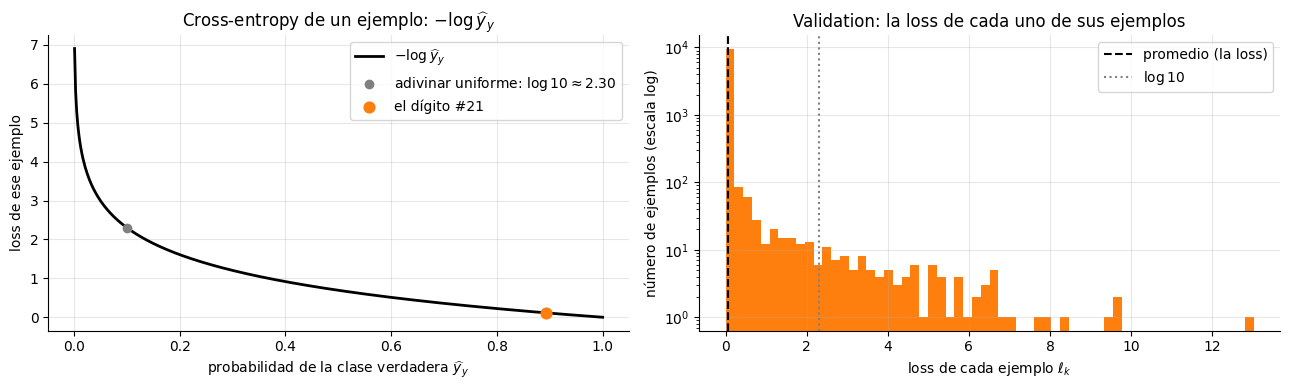

In [130]:
# 1) Un dígito, a mano: la loss es −log de la probabilidad de la clase y.
a_mano = -torch.log(y_gorro[y_k])               # (sin cuidar la estabilidad)
por_pytorch = F.cross_entropy(z.unsqueeze(0), torch.tensor([y_k]))
print(f"dígito #{k_18}:  −log ŷ_y a mano = {float(a_mano):.6f}"
      f"   ·   CrossEntropyLoss = {float(por_pytorch):.6f}")

# 2) Todo validation: la loss de cada ejemplo, ℓ_k = −log ŷ_{k, y_k} ...
log_p_val = torch.log_softmax(logits_val, dim=1)
filas_k = torch.arange(len(y_val), device=y_val.device)
perdida_k = -log_p_val[filas_k, y_val]           # [n], una por ejemplo

# ... y su promedio, calculado de cuatro maneras.
maneras = {
    "promedio de −log ŷ_y (a mano)": perdida_k.mean(),
    "CrossEntropyLoss(logits)": nn.CrossEntropyLoss()(logits_val, y_val),
    "NLLLoss(log_softmax(logits))": nn.NLLLoss()(log_p_val, y_val),
    "evaluar(...) de la caja": evaluar(modelo_18, escala_18, "validation")[0],
}
display(pd.DataFrame({"manera": list(maneras),
                      "loss de validation": [float(v) for v in
                                             maneras.values()]}).round(6))
valores = [float(v) for v in maneras.values()]
assert max(valores) - min(valores) < 1e-3        # la misma cantidad

# 3) Dos gráficas: la curva −log p, y cómo se reparte ℓ_k en validation.
fig, (ax_c, ax_h) = plt.subplots(1, 2, figsize=(13, 4))
p = torch.linspace(0.001, 1, 500)
ax_c.plot(p, -torch.log(p), color="black", lw=2, label=r"$-\log \widehat y_y$")
ax_c.scatter([0.1], [math.log(10)], color="gray", zorder=3,
             label=r"adivinar uniforme: $\log 10 \approx 2.30$")
ax_c.scatter([float(y_gorro[y_k])], [float(a_mano)], zorder=3, s=60,
             color=COLORES["validation"], label=f"el dígito #{k_18}")
ax_c.set_xlabel(r"probabilidad de la clase verdadera $\widehat y_y$")
ax_c.set_ylabel("loss de ese ejemplo")
ax_c.set_title("Cross-entropy de un ejemplo: $-\\log \\widehat y_y$")
ax_c.legend()
ax_h.hist(perdida_k.cpu().numpy(), bins=60, color=COLORES["validation"])
ax_h.set_yscale("log")
ax_h.axvline(valores[1], color="black", ls="--", label="promedio (la loss)")
ax_h.axvline(math.log(10), color="gray", ls=":", label=r"$\log 10$")
ax_h.set_xlabel(r"loss de cada ejemplo $\ell_k$")
ax_h.set_ylabel("número de ejemplos (escala log)")
ax_h.set_title("Validation: la loss de cada uno de sus ejemplos")
ax_h.legend()
plt.tight_layout()
plt.show()

**La loss penaliza mucho los errores confiados**. A la izquierda, la loss se dispara cuando $\widehat y_y$ cae hacia cero.
A la derecha, la mayoría de ejemplos tiene poca loss y unos pocos forman una cola de loss alta.
El eje de conteos es logarítmico. La línea punteada señala la referencia $\log 10$.
La loss puede subir con igual número de aciertos. En §6 aumentaron tanto los errores como su confianza media.

En `float32`, $e^{-1000}$ se redondea a cero por underflow y $e^{89}$ desborda a infinito por overflow.
Para logits $(0,-1000)$ y clase real $1$, la loss exacta es $1000+\log(1+e^{-1000})\approx1000$.
**Apuesta.** ¿Qué filas de la tabla darán resultados finitos y cuáles darán infinitos?

In [131]:
# Un caso extremo en float32 (el tipo con el que entrena todo el notebook):
# una observación, dos clases, logits z = [0, −1000] y clase verdadera 1.
z_ext = torch.tensor([[0.0, -1000.0]], dtype=torch.float32)
y_ext = torch.tensor([1])
print("e^{-1000} en float32 =", torch.exp(torch.tensor(-1000.0)).item(),
      "  (el positivo normal más chico de float32 es",
      f"{torch.finfo(torch.float32).tiny:.1e}; e^{{-1000}} ≈ 1e-435)")

p_ingenua = torch.softmax(z_ext, dim=1)          # [[1., 0.]]
log_p_ingenua = p_ingenua.log()                  # [[0., -inf]]
maneras_ext = [
    ("softmax(z).log(), clase 1", log_p_ingenua[0, 1], "−1000"),
    ("NLLLoss(softmax(z).log())", nn.NLLLoss()(log_p_ingenua, y_ext), "1000"),
    ("NLLLoss(log_softmax(z))",
     nn.NLLLoss()(torch.log_softmax(z_ext, dim=1), y_ext), "1000"),
    ("CrossEntropyLoss(z)", nn.CrossEntropyLoss()(z_ext, y_ext), "1000"),
]
display(pd.DataFrame({"manera": [m for m, _, _ in maneras_ext],
                      "resultado en float32": [float(v) for _, v, _ in
                                               maneras_ext],
                      "valor exacto (redondeado)": [e for _, _, e in
                                                    maneras_ext]}))

e^{-1000} en float32 = 0.0   (el positivo normal más chico de float32 es 1.2e-38; e^{-1000} ≈ 1e-435)


,manera,resultado en float32,valor exacto (redondeado)
0,"softmax(z).log(), clase 1",-inf,−1000
1,NLLLoss(softmax(z).log()),inf,1000
2,NLLLoss(log_softmax(z)),1000.0,1000
3,CrossEntropyLoss(z),1000.0,1000


In [132]:
# El truco log-sum-exp, a mano. Con m = max_j z_j:
#   log ŷ_c = z_c − log Σ_j e^{z_j} = z_c − m − log Σ_j e^{z_j − m}
# Ahora el exponente más grande es e^0 = 1: nada desborda, y la suma
# vale al menos 1, así que su log nunca es −inf.
def log_softmax_a_mano(z):
    m = z.max(dim=1, keepdim=True).values                  # [n, 1]
    return z - m - torch.log(torch.exp(z - m).sum(dim=1, keepdim=True))


def softmax_ingenuo(z):                                    # sin restar m
    e = torch.exp(z)
    return e / e.sum(dim=1, keepdim=True)


# Dos logits peligrosos: uno muy negativo (underflow: e^z se vuelve 0)
# y uno muy positivo (overflow: e^z se vuelve inf, e inf / inf = nan).
for z_prueba in ([[0.0, -1000.0]], [[1000.0, 0.0]]):
    zt = torch.tensor(z_prueba)
    print(f"z = {z_prueba[0]}")
    print("   log(softmax ingenuo):", softmax_ingenuo(zt).log().tolist()[0])
    print("   log-sum-exp a mano:  ", log_softmax_a_mano(zt).tolist()[0])
    print("   torch.log_softmax:   ", torch.log_softmax(zt, dim=1).tolist()[0])

# Y en los logits reales de validation, el truco da lo mismo que PyTorch.
assert torch.allclose(log_softmax_a_mano(logits_val), log_p_val, atol=1e-5)
print("\nEn los", len(logits_val), "logits de validation, log-sum-exp a mano "
      "= torch.log_softmax")

z = [0.0, -1000.0]
   log(softmax ingenuo): [0.0, -inf]
   log-sum-exp a mano:   [0.0, -1000.0]
   torch.log_softmax:    [0.0, -1000.0]
z = [1000.0, 0.0]
   log(softmax ingenuo): [nan, -inf]
   log-sum-exp a mano:   [0.0, -1000.0]
   torch.log_softmax:    [0.0, -1000.0]

En los 10000 logits de validation, log-sum-exp a mano = torch.log_softmax


Softmax por separado redondeó la probabilidad real a cero. Su logaritmo dio $-\infty$.
**Log-sum-exp** resta $m=\max_j z_j$ antes de calcular las exponenciales.

$$\log\widehat y_c=z_c-m-\log\sum_j e^{z_j-m}.$$

La exponencial mayor vale $1$, así que la suma es finita y vale al menos $1$ para logits finitos.
Usa `log_softmax` para log-probabilidades y pasa los logits directamente a `CrossEntropyLoss` para la loss.

A la izquierda ves el ancho de la entrada, las capas ocultas y la salida.
En el modelo impreso puedes localizar la normalización y la activación de cada capa oculta.
A la derecha, **los logits se convierten en probabilidades**. El naranja marca la clase real.

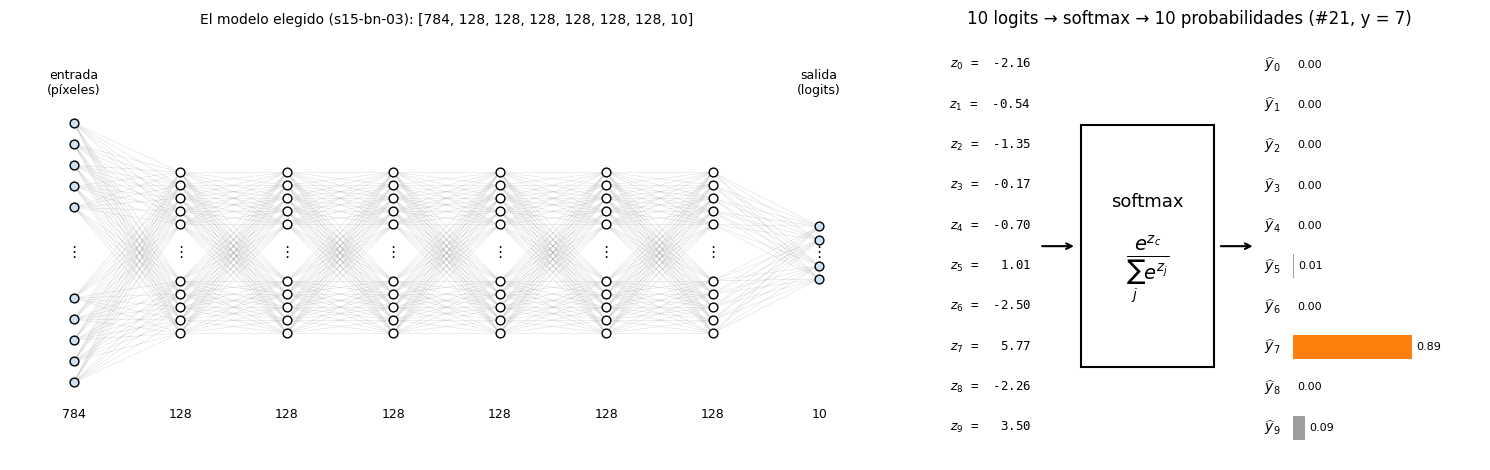

En el código, la red termina en los logits; softmax y −log ŷ_y van
juntos dentro de CrossEntropyLoss (con log-sum-exp).


In [133]:
# La red completa del modelo elegido y, a la derecha, el paso que la red no
# hace pero la loss sí: softmax de los 10 logits del dígito de arriba.
fig, (ax_red, ax_sm) = plt.subplots(
    1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [3, 2]})
if corrida_18.config.modelo is None:
    dibujar_red(corrida_18.config.capas, ax=ax_red,
                titulo=f"El modelo elegido ({corrida_18.id}): "
                       f"{corrida_18.config.capas}")
else:                                           # una CNN no se dibuja así
    ax_red.text(0.5, 0.5, f"{corrida_18.id}: no es un MLP", ha="center")
    ax_red.axis("off")

filas_y = np.arange(10)[::-1]                    # clase 0 arriba
for c, fila in zip(range(10), filas_y):
    ax_sm.text(0.0, fila, f"$z_{c}$ = {float(z[c]):6.2f}", va="center",
               ha="right", fontsize=9, family="monospace")
    ax_sm.text(3.0, fila, rf"$\widehat y_{c}$", va="center", ha="right")
ax_sm.barh(filas_y, 1.6 * y_gorro.numpy(), left=3.15, height=0.6,
           color=colores_k)
for c, fila in zip(range(10), filas_y):                  # el valor de ŷ_c
    ax_sm.text(3.2 + 1.6 * float(y_gorro[c]), fila, f"{float(y_gorro[c]):.2f}",
               va="center", fontsize=8)
ax_sm.add_patch(plt.Rectangle((0.6, 1.5), 1.6, 6, fill=False, lw=1.5))
ax_sm.text(1.4, 5.6, "softmax", ha="center", va="center", fontsize=13)
ax_sm.text(1.4, 3.9, r"$\frac{e^{z_c}}{\sum_j e^{z_j}}$", ha="center",
           va="center", fontsize=20)
for x0, x1 in ((0.1, 0.55), (2.25, 2.7)):
    ax_sm.annotate("", xy=(x1, 4.5), xytext=(x0, 4.5),
                   arrowprops=dict(arrowstyle="->", lw=1.5))
ax_sm.set_xlim(-1.6, 5.4)
ax_sm.set_ylim(-0.8, 9.8)
ax_sm.axis("off")
ax_sm.set_title(f"10 logits → softmax → 10 probabilidades (#{k_18}, y = {y_k})")
plt.tight_layout()
plt.show()

print("En el código, la red termina en los logits; softmax y −log ŷ_y van")
print("juntos dentro de CrossEntropyLoss (con log-sum-exp).")

**Qué viste**

- Softmax conservó el orden de los logits. La barra ganadora destacó más en probabilidades.
- Al subir la temperatura, la distribución se aplanó y la loss del acierto subió con la misma predicción.
- La loss de validation se concentró cerca de cero, con una cola de ejemplos costosos.
- El cálculo directo produjo infinitos o NaN con logits extremos. Log-sum-exp dio resultados finitos en ambos ejemplos.

## 19 · Cierre

Compara las corridas registradas para ver **qué cambios movieron el error de validation**.

In [134]:
# La tabla maestra de la caja (s03): una fila por corrida, con sus números
# en la MEJOR epoch por validation (test no participó en elegirla).
# brecha = acc train − acc validation: cuánto va train por delante.
import numpy as np
import pandas as pd

# §16 guarda el MLP elegido también como CORRIDAS["s16-elegido"]: es el
# MISMO objeto con otro nombre, así que su fila saldría dos veces con su ID
# original. Dejamos una fila por ID.
resumen = tabla_maestra()
if not resumen.empty:
    resumen = resumen.drop_duplicates("id").reset_index(drop=True)
if resumen.empty:
    print("CORRIDAS está vacío: no corriste ninguna sección con experimentos.")
    print("Ejecuta el notebook completo (Entorno de ejecución → Ejecutar todo)")
    print("y vuelve aquí; esta sección solo resume lo que ya se entrenó.")
    resumen = pd.DataFrame(columns=["id", "seccion", "datos", "parametros",
                                    "mejor_epoch", "acc_train",
                                    "acc_validation", "acc_test", "brecha",
                                    "segundos", "divergio"])
else:
    # Orden: los grupos de datos en el orden en que aparecen en el notebook
    # y, dentro de cada grupo, de mejor a peor accuracy de VALIDATION.
    # Nunca se ordena ni se elige con test.
    resumen["divergio"] = resumen["divergio"].astype(bool)
    resumen["_orden"] = resumen.groupby("datos")["seccion"].transform("min")
    resumen = (resumen.sort_values(["_orden", "datos", "acc_validation"],
                                   ascending=[True, True, False])
               .drop(columns="_orden").reset_index(drop=True))
    print(f"{len(resumen)} corridas en {resumen['datos'].nunique()} grupos "
          f"de datos y {resumen['seccion'].nunique()} secciones.")
    print("Corridas por grupo de datos:")
    print(resumen.groupby("datos", sort=False).size().to_string())
    print("Divergieron:", int(resumen["divergio"].sum()))


def presupuesto(ident):
    """El presupuesto PEDIDO en la Config: pasos si los topa, si no epochs."""
    cfg = CORRIDAS[ident].config
    return f"{cfg.max_pasos} pasos" if cfg.max_pasos else f"{cfg.epochs} epochs"


resumen["presupuesto"] = [presupuesto(i) for i in resumen["id"]]
resumen["pasos"] = [int(CORRIDAS[i].historial["pasos"].iloc[-1])
                    for i in resumen["id"]]        # pasos dados de verdad
# Un color por sección, el mismo en la figura y en el recuadro final.
secciones = sorted(resumen["seccion"].unique())
paleta = plt.cm.tab20b(np.linspace(0, 1, max(len(secciones), 2)))
color_de = {s: paleta[i] for i, s in enumerate(secciones)}

78 corridas en 5 grupos de datos y 13 secciones.
Corridas por grupo de datos:
datos
2k-limpio      1
50k-limpio    42
4k-limpio      6
2k-ruido20     3
20k-limpio    26
Divergieron: 1


- **Compara dentro de cada grupo de datos**. Las filas se ordenan por accuracy de validation.
- `presupuesto` indica lo configurado. `pasos` indica cuántas actualizaciones se ejecutaron.
- La tabla reporta las métricas del checkpoint con menor loss de validation. Test queda para el reporte.

In [135]:
# La tabla maestra completa, partida por grupo de datos. Solo se comparan
# filas DENTRO de un grupo: con 2000 ejemplos y 20 % de etiquetas
# cambiadas (§10) la accuracy no se puede poner junto a la de 50 000
# limpios. Dentro de cada grupo, el orden lo da validation.
columnas_tabla = ["id", "seccion", "parametros", "presupuesto", "pasos",
                  "mejor_epoch", "loss_train", "loss_validation", "loss_test",
                  "acc_train", "acc_validation", "acc_test", "brecha",
                  "segundos", "divergio"]
if resumen.empty:
    print("Sin corridas: no hay tabla maestra que mostrar.")
for datos_grupo, grupo in resumen.groupby("datos", sort=False):
    print(f"\n=== datos: {datos_grupo} · {len(grupo)} corridas, "
          "ordenadas por accuracy de validation ===")
    display(grupo[columnas_tabla].set_index("id").round(4))


=== datos: 2k-limpio · 1 corridas, ordenadas por accuracy de validation ===


,seccion,parametros,presupuesto,pasos,mejor_epoch,loss_train,loss_validation,loss_test,acc_train,acc_validation,acc_test,brecha,segundos,divergio
id,,,,,,,,,,,,,,
s03-demo,3,101770,2 epochs,32,2.0,0.4291,0.4315,0.4601,0.864,0.8766,0.8737,-0.0126,0.2515,False



=== datos: 50k-limpio · 42 corridas, ordenadas por accuracy de validation ===


,seccion,parametros,presupuesto,pasos,mejor_epoch,loss_train,loss_validation,loss_test,acc_train,acc_validation,acc_test,brecha,segundos,divergio
id,,,,,,,,,,,,,,
s17-cnn,17,20490,5 epochs,1955,4.8593,0.0247,0.0430,0.0356,0.9926,0.9871,0.9889,0.0055,4.3504,False
s15-bn-03,15,185866,5 epochs,1955,4.3478,0.0211,0.0728,0.0727,0.9939,0.9796,0.9784,0.0143,6.4001,False
s09-adam-sin,9,203530,8 epochs,3128,5.0000,0.0288,0.0734,0.0729,0.9921,0.9779,0.9780,0.0142,4.9430,False
s09-adamw-wd,9,203530,8 epochs,3128,5.0000,0.0281,0.0734,0.0730,0.9923,0.9776,0.9769,0.0147,6.5854,False
s15-sin-bn-03,15,184330,5 epochs,1955,5.0000,0.0383,0.0831,0.0909,0.9887,0.9771,0.9746,0.0116,3.7385,False
s09-momentum,9,101770,5 epochs,1955,5.0000,0.0313,0.0771,0.0775,0.9910,0.9765,0.9767,0.0145,2.2768,False
s04-oculta,4,101770,8 epochs,3128,5.0000,0.0485,0.0854,0.0839,0.9862,0.9760,0.9746,0.0102,5.0119,False
s09-adam,9,101770,5 epochs,1955,5.0000,0.0485,0.0854,0.0839,0.9862,0.9760,0.9746,0.0102,3.2217,False
s09-adamw,9,101770,5 epochs,1955,5.0000,0.0477,0.0842,0.0824,0.9865,0.9750,0.9746,0.0115,3.0837,False



=== datos: 4k-limpio · 6 corridas, ordenadas por accuracy de validation ===


,seccion,parametros,presupuesto,pasos,mejor_epoch,loss_train,loss_validation,loss_test,acc_train,acc_validation,acc_test,brecha,segundos,divergio
id,,,,,,,,,,,,,,
s07-b8,7,101770,5 epochs,2560,4.2500,0.0602,0.2103,0.2095,0.9856,0.9414,0.9407,0.0442,2.9634,False
s07-b32,7,101770,5 epochs,640,4.6875,0.2069,0.2843,0.2845,0.9409,0.9193,0.9168,0.0216,0.6957,False
s07-b128,7,101770,5 epochs,160,5.0000,0.3908,0.3918,0.4046,0.8923,0.8958,0.8886,-0.0035,0.1802,False
s07-b4096,7,101770,80 epochs,80,80.0000,0.5467,0.5228,0.5404,0.8674,0.8799,0.8722,-0.0125,0.1295,False
s07-b1,7,101770,1 epochs,4096,0.4316,0.5152,0.5381,0.5594,0.8491,0.8512,0.8422,-0.0021,4.3858,False
s07-b1024,7,101770,5 epochs,20,5.0000,1.3744,1.3481,1.3535,0.7322,0.7683,0.7583,-0.0361,0.0277,False



=== datos: 2k-ruido20 · 3 corridas, ordenadas por accuracy de validation ===


,seccion,parametros,presupuesto,pasos,mejor_epoch,loss_train,loss_validation,loss_test,acc_train,acc_validation,acc_test,brecha,segundos,divergio
id,,,,,,,,,,,,,,
s15-dropout,15,269322,80 epochs,2560,16.0,0.5117,0.4294,0.4459,0.8505,0.9008,0.8921,-0.0503,4.7332,False
s10-control,10,269322,80 epochs,2560,9.0,0.4583,0.4710,0.4818,0.8710,0.8871,0.8833,-0.0161,4.6622,False
s10-paciencia,10,269322,80 epochs,480,9.0,0.4583,0.4710,0.4818,0.8710,0.8871,0.8833,-0.0161,0.8403,False



=== datos: 20k-limpio · 26 corridas, ordenadas por accuracy de validation ===


,seccion,parametros,presupuesto,pasos,mejor_epoch,loss_train,loss_validation,loss_test,acc_train,acc_validation,acc_test,brecha,segundos,divergio
id,,,,,,,,,,,,,,
s11-a1024-p1,11,814090,5 epochs,785,5.0,0.0167,0.1105,0.1126,0.9964,0.9697,0.9669,0.0267,1.4061,False
s12-una-capa,12,101770,8 epochs,1256,8.0,0.0238,0.1117,0.1154,0.9960,0.9681,0.9659,0.0280,2.1282,False
s11-a1024-p2,11,1863690,5 epochs,785,5.0,0.0259,0.1227,0.1375,0.9914,0.9680,0.9639,0.0234,1.4053,False
s12-invertido,12,101906,8 epochs,1256,8.0,0.0141,0.1232,0.1263,0.9970,0.9677,0.9671,0.0293,2.1315,False
s12-rectangular,12,101706,8 epochs,1256,8.0,0.0145,0.1195,0.1314,0.9970,0.9674,0.9638,0.0296,2.3605,False
s11-a256-p2,11,269322,5 epochs,785,3.0,0.0530,0.1235,0.1265,0.9848,0.9652,0.9616,0.0197,1.3535,False
s11-a256-p1,11,203530,5 epochs,785,3.0,0.0711,0.1266,0.1310,0.9811,0.9635,0.9593,0.0176,1.4248,False
s12-embudo,12,101670,8 epochs,1256,6.0,0.0387,0.1304,0.1324,0.9905,0.9630,0.9611,0.0275,2.1203,False
s11-a1024-p4,11,3962890,5 epochs,785,4.0,0.0419,0.1465,0.1621,0.9872,0.9619,0.9549,0.0253,1.8069,False


- Izquierda. Compara la accuracy de validation. El eje puede empezar por encima de cero y el rayado marca divergencia.
- Derecha. Una **brecha** positiva, $a_{\text{train}}-a_{\text{validation}}$, puede señalar overfitting.
- Con etiquetas alteradas en train, la brecha puede ser negativa porque validation conserva etiquetas limpias.

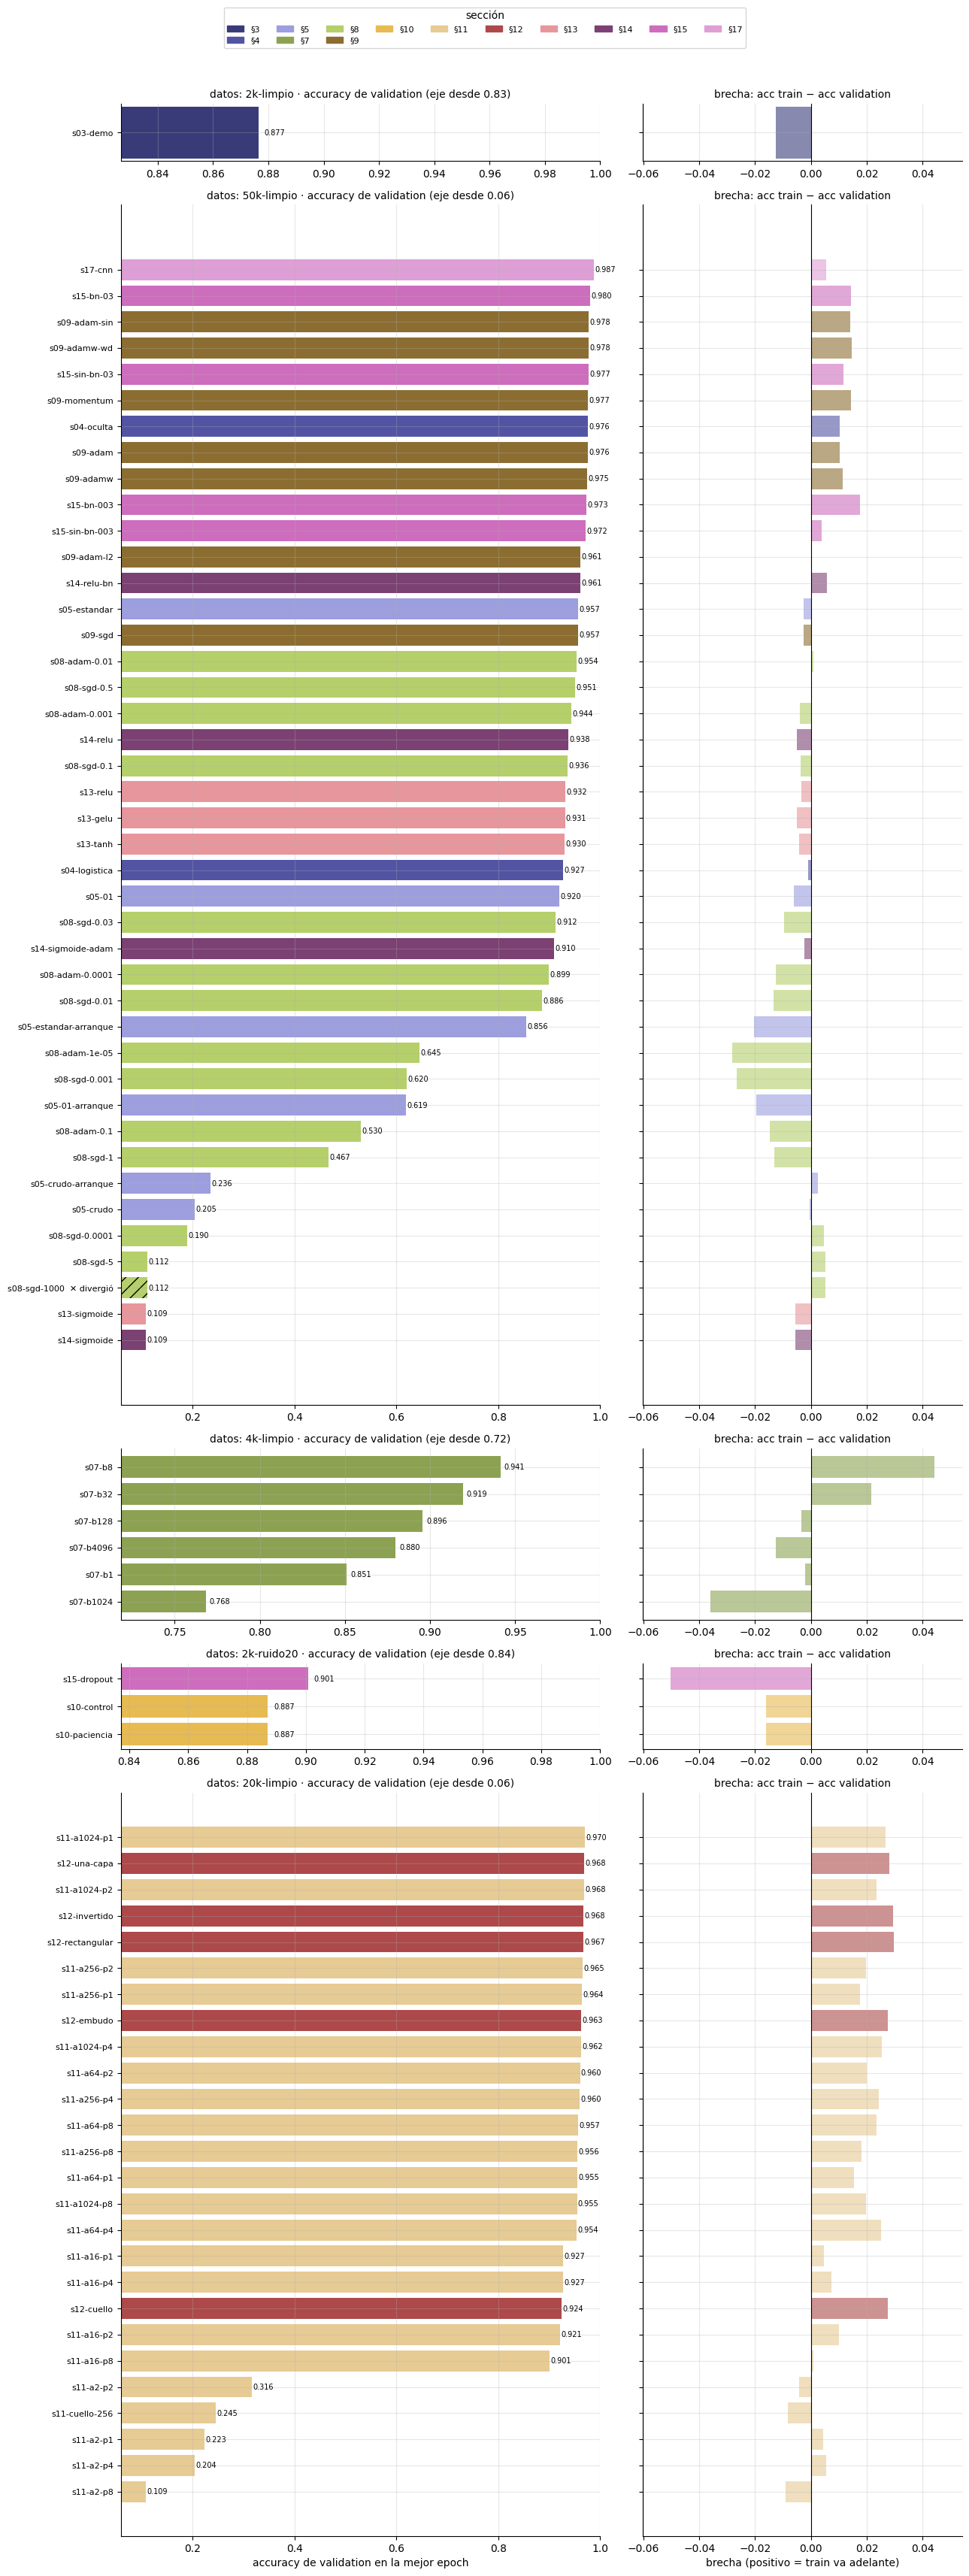

In [136]:
# Una fila de paneles por grupo de datos. Izquierda: accuracy de
# validation en la mejor epoch, una barra por corrida, coloreada por la
# sección que la produjo. Derecha: la brecha train − validation de esa
# misma corrida. Las corridas que divergieron llevan «✕ divergió».
if resumen.empty:
    print("Sin corridas: no hay figura resumen.")
else:
    grupos = list(resumen.groupby("datos", sort=False))
    alturas = [max(len(g), 2) for _, g in grupos]
    alto = 0.32 * sum(alturas) + 1.6 * len(grupos) + 1.0   # +1 in: leyenda
    fig, ejes = plt.subplots(
        len(grupos), 2, figsize=(13, alto),
        gridspec_kw={"height_ratios": alturas, "width_ratios": [3, 2]},
        squeeze=False)
    # Todas las brechas con la misma escala, para compararlas entre grupos.
    lim_br = (min(0.0, resumen["brecha"].min()) - 0.01,
              max(0.0, resumen["brecha"].max()) + 0.01)
    for (datos_grupo, g), (ax_acc, ax_br) in zip(grupos, ejes):
        g = g.iloc[::-1]                       # la mejor queda arriba
        y = np.arange(len(g))
        colores = [color_de[s] for s in g["seccion"]]
        etiquetas = [f"{i}  ✕ divergió" if d else i
                     for i, d in zip(g["id"], g["divergio"])]
        barras = ax_acc.barh(y, g["acc_validation"], color=colores)
        for barra, d in zip(barras, g["divergio"]):
            barra.set_hatch("//" if d else "")      # rayada = divergió
        ax_br.barh(y, g["brecha"], color=colores, alpha=0.6)
        ax_br.axvline(0, color="black", lw=0.8)
        ax_br.set_xlim(*lim_br)
        # Eje de accuracy recortado: si arranca en 0, 0.97 y 0.98 se ven
        # iguales. El piso sale de las corridas que NO divergieron.
        sanas = g.loc[~g["divergio"], "acc_validation"]
        piso = max(0.0, (sanas.min() if len(sanas) else 0.0) - 0.05)
        for yi, v in zip(y, g["acc_validation"]):
            fuera = "  ◀ fuera del eje" if v < piso else ""
            ax_acc.text(max(v, piso) + 0.002, yi, f"{v:.3f}{fuera}",
                        va="center", fontsize=7)
        ax_acc.set_yticks(y, etiquetas, fontsize=8)
        ax_br.set_yticks(y, [""] * len(y))
        ax_acc.set_title(f"datos: {datos_grupo} · accuracy de validation "
                         f"(eje desde {piso:.2f})", fontsize=10)
        ax_acc.set_xlim(piso, 1.0)
        ax_br.set_title("brecha: acc train − acc validation", fontsize=10)
    ejes[-1, 0].set_xlabel("accuracy de validation en la mejor epoch")
    ejes[-1, 1].set_xlabel("brecha (positivo = train va adelante)")
    manijas = [plt.Rectangle((0, 0), 1, 1, color=color_de[s])
               for s in secciones]
    fig.legend(manijas, [f"§{s}" for s in secciones], title="sección",
               loc="upper center", ncol=min(len(secciones), 10),
               bbox_to_anchor=(0.5, 1.0), fontsize=8)
    fig.tight_layout(rect=(0, 0, 1, 1 - 1.0 / alto))   # 1 in libre arriba
    plt.show()

Busca **resultados cercanos** entre las corridas con mayor accuracy.
En las de abajo, ubica casos con learning rates extremos, activaciones saturadas o cuellos angostos.
Compara la CNN con los MLP del mismo grupo. Con otra semilla pueden cambiar las diferencias pequeñas.

El **rango de accuracy de validation** $a_{\max}-a_{\min}$ compara corridas de la misma sección, datos y presupuesto, con dos excepciones.
Se incluyen dropout frente a su control y CNN frente al MLP elegido.
La gráfica muestra el mayor rango arriba. La tabla empieza por el menor.
La anotación de divergencia cuenta las corridas que quedaron fuera del cálculo.

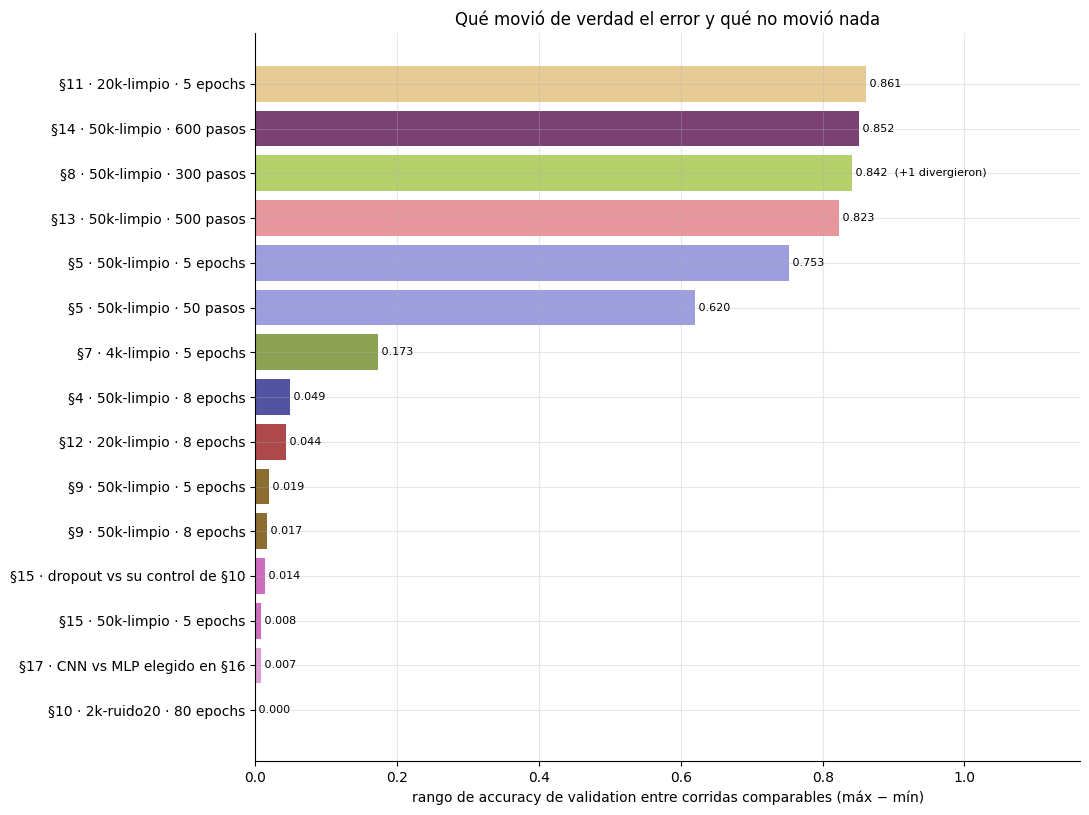

,comparacion,seccion,corridas,divergieron,rango
0,§10 · 2k-ruido20 · 80 epochs,10,2,0,0.0000
1,§17 · CNN vs MLP elegido en §16,17,2,0,0.0075
2,§15 · 50k-limpio · 5 epochs,15,4,0,0.0076
3,§15 · dropout vs su control de §10,15,2,0,0.0137
4,§9 · 50k-limpio · 8 epochs,9,3,0,0.0168
5,§9 · 50k-limpio · 5 epochs,9,4,0,0.0191
6,§12 · 20k-limpio · 8 epochs,12,5,0,0.0437
7,§4 · 50k-limpio · 8 epochs,4,2,0,0.0487
8,§7 · 4k-limpio · 5 epochs,7,4,0,0.1731
9,§5 · 50k-limpio · 50 pasos,5,3,0,0.6200


In [137]:
# «Qué movió de verdad el error»: cuánto varió la accuracy de validation
# entre corridas COMPARABLES: misma sección, mismos datos y mismo
# presupuesto pedido. Rango = máx − mín entre las que no divergieron.
# Rango chico = esa perilla casi no movió nada; grande = sí importa.
# Medida tosca: depende de qué valores se probaron en cada sección.
filas_var = []
for (sec, dat, pres), g in resumen.groupby(["seccion", "datos", "presupuesto"]):
    sanas, n_div = g[~g["divergio"]], int(g["divergio"].sum())
    if len(g) < 2:                       # con una sola corrida no hay rango
        continue
    acc = sanas["acc_validation"]
    filas_var.append({"comparacion": f"§{sec} · {dat} · {pres}", "seccion": sec,
                      "corridas": len(g), "divergieron": n_div,
                      "rango": acc.max() - acc.min() if len(acc) > 1 else 0.0})
# Dos comparaciones que cruzan secciones, si ambas corridas existen:
# dropout (§15) contra su control (§10), y la CNN contra el MLP elegido.
elegido = CORRIDAS["s16-elegido"].id if "s16-elegido" in CORRIDAS else None
for nombre, a, b in [("§15 · dropout vs su control de §10", "s15-dropout",
                      "s10-control"),
                     ("§17 · CNN vs MLP elegido en §16", "s17-cnn", elegido)]:
    par = resumen[resumen["id"].isin([a, b])]
    if len(par) == 2 and not par["divergio"].any():
        acc = par["acc_validation"]
        filas_var.append({"comparacion": nombre, "seccion": par["seccion"].max(),
                          "corridas": 2, "divergieron": 0,
                          "rango": acc.max() - acc.min()})
variacion = pd.DataFrame(filas_var)

if variacion.empty:
    print("No hay ninguna sección con dos o más corridas comparables:")
    print("corre las secciones 4 a 17 para llenar este recuadro.")
else:
    variacion = variacion.sort_values("rango").reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(11, 0.45 * len(variacion) + 1.5))
    ax.barh(variacion["comparacion"], variacion["rango"],
            color=[color_de[s] for s in variacion["seccion"]])
    for yi, (r, n_div) in enumerate(zip(variacion["rango"],
                                        variacion["divergieron"])):
        extra = f"  (+{n_div} divergieron)" if n_div else ""
        ax.text(r, yi, f" {r:.3f}{extra}", va="center", fontsize=8)
    ax.set_xlabel("rango de accuracy de validation entre corridas "
                  "comparables (máx − mín)")
    ax.set_title("Qué movió de verdad el error y qué no movió nada")
    ax.set_xlim(0, variacion["rango"].max() * 1.35 + 1e-3)
    plt.tight_layout()
    plt.show()
    display(variacion.round(4))

**Qué viste**

- Con SGD y el mismo learning rate, escalar los píxeles mejoró la accuracy de validation (§5). Estandarizarlos dio la mayor.
- Los cuellos angostos rindieron peor (§12). En redes profundas, ReLU superó a sigmoide y batch normalization mejoró ReLU (§13–15).
- Con etiquetas alteradas, early stopping y su control eligieron el mismo checkpoint (§10). Otras corridas pueden mostrar una brecha distinta.
- CNN y MLP quedaron cerca (§17). Las diferencias entre learning rates fueron mucho mayores (§8).

- Train ajusta los pesos.
- **Decide con validation.** Usa su loss para early stopping y sus métricas para elegir el modelo.
- Mira test una sola vez, al final, para reportar el desempeño. Mostrarlo por epoch aquí fue didáctico.

#### Receta práctica para un MLP

- Empieza con una o dos capas ocultas de ancho fijo o con un embudo suave. Crece solo si validation mejora.
- Prioriza el ancho sobre la profundidad.
- Mantén cada capa al menos tan ancha como el número de clases. Un cuello menor puede perder información. Recuerda el de dos unidades en §12.
- Si sobreajusta, prueba early stopping, weight decay con AdamW o dropout antes de achicar la red.
- Empieza con ReLU o GELU, Adam o AdamW, learning rate $10^{-3}$ y batch de 32 a 256.
- Si la red es profunda, prueba batch normalization. Para imágenes, usa una CNN (§17).

In [138]:
# La lista de todos los experimentos que quedaron registrados, en el orden
# de la tabla maestra (un ID por corrida). CORRIDAS guarda además el alias
# "s16-elegido" (la MISMA corrida con otro nombre), así que se cuentan
# objetos distintos, no llaves. La última línea la busca la prueba.
for ident in resumen["id"]:
    print(ident)
alias = sorted(set(CORRIDAS) - set(resumen["id"]))
if alias:
    print("alias en CORRIDAS (no cuentan aparte):", ", ".join(alias))
try:
    experimentos_unicos                     # lo define la caja (s03)
except NameError:                           # respaldo si la caja es vieja
    def experimentos_unicos():
        return len({id(c) for c in CORRIDAS.values()})
print(f"EXPERIMENTOS COMPLETOS: {experimentos_unicos()}")

s03-demo
s17-cnn
s15-bn-03
s09-adam-sin
s09-adamw-wd
s15-sin-bn-03
s09-momentum
s04-oculta
s09-adam
s09-adamw
s15-bn-003
s15-sin-bn-003
s09-adam-l2
s14-relu-bn
s05-estandar
s09-sgd
s08-adam-0.01
s08-sgd-0.5
s08-adam-0.001
s14-relu
s08-sgd-0.1
s13-relu
s13-gelu
s13-tanh
s04-logistica
s05-01
s08-sgd-0.03
s14-sigmoide-adam
s08-adam-0.0001
s08-sgd-0.01
s05-estandar-arranque
s08-adam-1e-05
s08-sgd-0.001
s05-01-arranque
s08-adam-0.1
s08-sgd-1
s05-crudo-arranque
s05-crudo
s08-sgd-0.0001
s08-sgd-5
s08-sgd-1000
s13-sigmoide
s14-sigmoide
s07-b8
s07-b32
s07-b128
s07-b4096
s07-b1
s07-b1024
s15-dropout
s10-control
s10-paciencia
s11-a1024-p1
s12-una-capa
s11-a1024-p2
s12-invertido
s12-rectangular
s11-a256-p2
s11-a256-p1
s12-embudo
s11-a1024-p4
s11-a64-p2
s11-a256-p4
s11-a64-p8
s11-a256-p8
s11-a64-p1
s11-a1024-p8
s11-a64-p4
s11-a16-p1
s11-a16-p4
s12-cuello
s11-a16-p2
s11-a16-p8
s11-a2-p2
s11-cuello-256
s11-a2-p1
s11-a2-p4
s11-a2-p8
alias en CORRIDAS (no cuentan aparte): s16-elegido
EXPERIMENTOS COMPL